# 09 - Financial Time Series Analysis

**Project:** AI Quantitative Trading & Strategy Optimisation System  
**Phase:** 5 — Financial Time Series and Macroeconomic Analysis  
**Research universe:** NG.L (primary), SSE.L and SVT.L (sector comparators), FTSE 100 (market reference)  
**Notebook language:** British English

## 1. Title and Objective

Investigate the statistical properties of the existing financial and macroeconomic time series, focusing on stationarity, serial dependence, volatility dynamics, interest-rate behaviour and macroeconomic relationships.

The notebook reuses the data acquired in previous phases. It does not download data, modify Raw data or repeat the descriptive EDA already completed in Phase 4.

**Execution status:** this notebook contains the research implementation. Statistical results are produced only after the existing data files are explicitly mapped in Section 6 and the relevant cells are executed. No results are assumed or fabricated.

## 2. Research Questions

| ID | Research question | Research area |
|---|---|---|
| RQ01 | What additional return-distribution evidence is needed beyond the Phase 4 EDA? | Returns and distributions |
| RQ02 | Which price, return, interest-rate and macroeconomic series show evidence of stationarity? | Stationarity |
| RQ03 | Is there serial dependence in returns or squared returns? | Autocorrelation |
| RQ04 | Is there evidence of volatility clustering or conditional heteroskedasticity? | Volatility |
| RQ05 | How do UK short- and long-term interest rates and yield-curve spreads behave? | Interest rates |
| RQ06 | Are macroeconomic variables associated with utility-sector returns? | Macroeconomic relationships |
| RQ07 | Do findings differ between NG.L and its sector comparators? | Cross-asset comparison |

These questions are empirical. No relationship, stationarity property or predictive value is assumed.


## 3. Technical Background

### 3.1 Returns

For price $P_t$, the simple return is $r_t=P_t/P_{t-1}-1$ and the log return is $\ell_t=\log(P_t)-\log(P_{t-1})$. Phase 4 already covered the descriptive return analysis; this notebook reuses its established context and computes returns only where needed as inputs to new diagnostics.

### 3.2 Stationarity

ADF tests the null of a unit root. KPSS tests the null of stationarity around the specified deterministic component. Their results are complementary and may conflict.

### 3.3 Serial dependence

ACF/PACF and Ljung–Box diagnostics investigate linear dependence. Squared returns are examined separately because dependence in their magnitude may indicate volatility persistence.

### 3.4 Volatility

Rolling standard deviation and ARCH-LM diagnostics describe changing variance and conditional heteroskedasticity. GARCH estimation is conditional on evidence; it is not an automatic step.

### 3.5 Macroeconomic association

Pearson and Spearman correlations measure association, not causality. Lagged relationships are exploratory and cannot be interpreted as predictive unless information availability is respected and a separate out-of-sample design is used.


## 4. Methodology

1. Reuse the approved Phase 4 findings and existing acquisition records.
2. Load only the previously acquired datasets; do not download or alter Raw data.
3. Preserve source units, provenance, acquisition identifiers and documented quality classifications.
4. Do not repeat Phase 4 descriptive EDA. Any return series calculated here is an analytical input to a new statistical diagnostic.
5. Apply ADF and KPSS with pre-specified deterministic components and report both results.
6. Apply ACF/PACF and Ljung–Box to returns and squared returns.
7. Apply ARCH-LM only to appropriately prepared return series. Consider GARCH only if diagnostics justify it.
8. Investigate interest-rate changes and yield-curve spreads only where the required maturities exist and are consistently defined.
9. Treat macroeconomic relationships as exploratory. Respect publication delays and revisions.
10. Report sample size, date range, exclusions, assumptions and limitations alongside every result.

### 4.1 Deterministic specifications

| Series type | Initial specification |
|---|---|
| Price levels and log prices | Constant and linear trend (`ct`) |
| Equity returns | Constant (`c`) |
| Interest-rate levels | Constant (`c`); trend specification only if justified |
| Inflation index levels | Constant and linear trend (`ct`) |
| Changes and growth rates | Constant (`c`) |

These are initial research specifications, not universal truths. A specification must reflect the series' economic meaning.

### 4.2 Test configuration

- Significance level: 5%.
- ADF lag selection: AIC.
- KPSS bandwidth: automatic.
- No interpolation of missing observations.
- No automatic differencing to obtain a preferred result.
- Structural breaks and regime changes qualify conventional test interpretation.

### 4.3 Existing approved classifications

- UK GDP: `PIT_UNVALIDATED`.
- SONIA: `PIT_CONDITIONAL`; methodology change on 23 April 2018.
- Market data retains the known limitations from Phases 2–4, including missing observations, zero-volume records, OHLC inconsistencies, Close versus Adjusted Close differences, incomplete corporate-action information, historical NG.L rights issues and GBP/GBp denomination concerns.


## 5. Imports and Configuration

The following imports support the statistical analyses in this notebook. No package installation or environment modification is performed here.


In [332]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.6f}".format)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True

SIGNIFICANCE_LEVEL = 0.05
TRADING_DAYS_PER_YEAR = 252
RANDOM_STATE = 42

print("Imports and configuration completed.")


Imports and configuration completed.


## 6. Data Loading

This section defines the source configurations, reusable data readers and loading procedures required to prepare the datasets for financial time series and macroeconomic analysis.

The source investigation, raw file inspection, metadata verification and initial data quality assessments were completed during the previous project phases. Their findings are retained as documented evidence and are not repeated here.

This section focuses on:

- Maintaining approved source configurations and data provenance.
- Defining reusable readers for each data provider.
- Loading the previously acquired datasets.
- Performing essential structural and loading validations.
- Preserving original observations, frequencies, units and point-in-time classifications.

No statistical analysis, interpolation or imputation is performed in this section.


### 6.1 Data Inventory

This subsection consolidates the previously investigated and approved
data sources. It records their provenance, acquisition identifiers,
frequency, original units and point-in-time (PIT) classification.

No new data acquisition or statistical analysis is performed in this
subsection.

#### 6.1.1 Market Data

| Asset | Description | Provider | Format | Selected Price Field | Acquisition ID |
|---|---|---|---|---|---|
| NG.L | National Grid | Yahoo Finance | Parquet | Adj Close | 20261103T000455Z_8b505769 |
| SSE.L | SSE plc | Yahoo Finance | Parquet | Adj Close | 20261103T002507Z_de101edb |
| SVT.L | Severn Trent | Yahoo Finance | Parquet | Adj Close | 20261103T002515Z_fdac38df |
| ^FTSE | FTSE 100 | Yahoo Finance | Parquet | Adj Close | 20261103T002524Z_9c7eb120 |

NG.L is the initial pilot asset. The architecture remains multi-asset
and must not depend on a hard-coded ticker.

Original provider price units and currency metadata must be preserved
during loading. Currency conversion is a downstream processing step
and must follow the approved asset configuration.

#### 6.1.2 Bank of England Data

| Dataset | Series | Acquisition ID | Format | Frequency | Original Unit |
|---|---|---|---|---|---|
| Official Bank Rate | IUDBEDR | 20261103T225333Z_db83b1b8 | CSV | Daily | Percent |
| SONIA | IUDSOIA | 20261103T224853Z_fc90361c | CSV | Daily | Percent |
| Nominal Gilt Yield – 2Y | 2-year spot yield | 20261109T012129Z_d4c045a2 | ZIP/XLSX | Daily | Percent |
| Nominal Gilt Yield – 10Y | 10-year spot yield | 20261109T012129Z_d4c045a2 | ZIP/XLSX | Daily | Percent |

The canonical Bank Rate acquisition is the approved historical
dataset covering 2 January 1975 to 2 November 2026.

The Gilt Yield Curve dataset contains eight historical workbooks.
The 2-year and 10-year nominal spot yields must be extracted by
matching their maturity labels rather than relying on fixed column
positions.

Missing observations must remain missing. No interpolation or
forward-filling is permitted at this stage.

#### 6.1.3 Office for National Statistics Data

| Dataset | Indicator | CDID | Acquisition ID | Frequency |
|---|---|---|---|---|
| MM23 | Consumer Prices Index (CPI) | D7G7 | 20261105T132954Z_b4ce351c | Monthly |
| MM23 | Core CPI | DKO8 | 20261105T132954Z_b4ce351c | Monthly |
| MM23 | Consumer Prices Index including Housing (CPIH) | L55O | 20261105T132954Z_b4ce351c | Monthly |
| GDP QNA | GDP chained volume measures | ABMI | 20261105T132956Z_60b29116 | Annual and quarterly |
| GDP QNA | GDP quarter-on-quarter growth | IHYQ | 20261105T132956Z_60b29116 | Quarterly |
| GDP QNA | GDP year-on-year growth | IHYP | 20261105T132956Z_60b29116 | Annual |
| GDP QNA | GDP deflator year-on-year growth | IHYS | 20261105T132956Z_60b29116 | Annual |

The approved ONS inflation extraction for this notebook uses monthly observations only.
Quarterly and annual observations are not loaded here. The source-level investigation
confirmed that all three selected series have 453 valid monthly observations from
January 1989 to September 2026.

GDP volume measures, GDP growth rates and GDP deflator growth
represent different economic variables and must remain separate.

#### 6.1.4 Point-in-Time Classification

The availability of an observation date does not establish when
the information became available to market participants.

Historical observation dates must not be treated as historical
publication timestamps.

The following limitations must be preserved:

- SONIA retains its approved conditional PIT classification.
- Gilt Yield Curve data remains PIT_UNVALIDATED.
- ONS historical observations must not be assumed to have been
  available on their observation dates.
- Bank Rate publication timing must not be inferred solely
  from the observation date.
- No dataset may be promoted to PIT-validated without
  supporting historical publication evidence.

#### 6.1.5 Data Loading Principles

All source-specific readers must preserve a common data interface
while retaining source-specific metadata.

At minimum, the resulting records must preserve:

- Observation date.
- Variable identifier.
- Variable value.
- Frequency.
- Original unit.
- Source provider.
- Acquisition identifier.
- PIT classification.

Raw source files are immutable.

Data loading must not introduce interpolation, forward-filling,
currency conversion or other transformations that could obscure
the original observations.

The purpose of this inventory is to establish the source
configuration required by the subsequent data loading process.

### 6.2 Explicit Source Mapping

The approved source-to-variable mappings are recorded in the configuration below.

- Market data: one configured price field (`Adj Close`) per asset; original quote units are preserved.
- Bank of England: `IUDBEDR` for Bank Rate and `IUDSOIA` for SONIA.
- Gilt yield curve: nominal 2-year and 10-year spot yields, identified by maturity labels.
- ONS MM23: `D7G7`, `DKO8` and `L55O`; monthly observations only; source unit `%`.
- ONS GDP QNA: `ABMI` annual and quarterly; `IHYP` annual; `IHYQ` quarterly; `IHYS` annual.
- ONS GDP source units are validated using both `PreUnit` and `Unit` metadata.

No source series is silently substituted, interpolated, forward-filled or converted during loading.


### 6.3 Source Configuration

Centralised configuration for market, Bank of England and ONS sources.

In [333]:
# ============================================================
# 6.3 SOURCE CONFIGURATION
# ============================================================

PROJECT_ROOT = Path.cwd().parent


# ------------------------------------------------------------
# 1. Market data sources
# ------------------------------------------------------------

MARKET_SOURCES = {
    "NG.L": {
        "description": "National Grid",
        "provider": "Yahoo Finance",
        "format": "parquet",
        "path": (
            "data/raw/market/yahoo_finance/NG.L/"
            "acquisition_20261103T000455Z_8b505769/NG.L.parquet"
        ),
        "acquisition_id": "20261103T000455Z_8b505769",
        "date_column": "Date",
        "price_column": "Adj Close",
        "frequency": "daily",
        "accounting_currency": "GBP",
        "provider_quote_currency": "GBp",
        "original_unit": "GBp",
        "conversion_to_accounting_currency": 0.01,
        "price_unit_validation_status": "pending",
        "pit_classification": "PIT_UNVALIDATED",
    },

    "SSE.L": {
        "description": "SSE plc",
        "provider": "Yahoo Finance",
        "format": "parquet",
        "path": (
            "data/raw/market/yahoo_finance/SSE.L/"
            "acquisition_20261103T002507Z_de101edb/SSE.L.parquet"
        ),
        "acquisition_id": "20261103T002507Z_de101edb",
        "date_column": "Date",
        "price_column": "Adj Close",
        "frequency": "daily",
        "accounting_currency": "GBP",
        "provider_quote_currency": "GBp",
        "original_unit": "GBp",
        "conversion_to_accounting_currency": 0.01,
        "price_unit_validation_status": "pending",
        "pit_classification": "PIT_UNVALIDATED",
    },

    "SVT.L": {
        "description": "Severn Trent",
        "provider": "Yahoo Finance",
        "format": "parquet",
        "path": (
            "data/raw/market/yahoo_finance/SVT.L/"
            "acquisition_20261103T002515Z_fdac38df/SVT.L.parquet"
        ),
        "acquisition_id": "20261103T002515Z_fdac38df",
        "date_column": "Date",
        "price_column": "Adj Close",
        "frequency": "daily",
        "accounting_currency": "GBP",
        "provider_quote_currency": "GBp",
        "original_unit": "GBp",
        "conversion_to_accounting_currency": 0.01,
        "price_unit_validation_status": "pending",
        "pit_classification": "PIT_UNVALIDATED",
    },

    "^FTSE": {
        "description": "FTSE 100",
        "provider": "Yahoo Finance",
        "format": "parquet",
        "path": (
            "data/raw/market/yahoo_finance/^FTSE/"
            "acquisition_20261103T002524Z_9c7eb120/^FTSE.parquet"
        ),
        "acquisition_id": "20261103T002524Z_9c7eb120",
        "date_column": "Date",
        "price_column": "Adj Close",
        "frequency": "daily",
        "accounting_currency": "GBP",
        "provider_quote_currency": "GBP",
        "original_unit": "index_points",
        "conversion_to_accounting_currency": None,
        "price_unit_validation_status": "not_applicable",
        "pit_classification": "PIT_UNVALIDATED",
    },
}


# ------------------------------------------------------------
# 2. Bank of England data sources
# ------------------------------------------------------------

BOE_SOURCES = {
    "bank_rate": {
        "description": "Official Bank Rate",
        "provider": "Bank of England",
        "format": "csv",
        "path": (
            "data/raw/macro/bank_of_england/"
            "uk_interest_rates/bank_rate/"
            "acquisition_20261103T225333Z_db83b1b8/"
            "original_data.csv"
        ),
        "acquisition_id": "20261103T225333Z_db83b1b8",
        "series_code": "IUDBEDR",
        "date_column": "DATE",
        "value_column": "IUDBEDR",
        "frequency": "daily",
        "original_unit": "percent",
        "pit_classification": "PIT_UNVALIDATED",
    },

    "sonia": {
        "description": "Sterling Overnight Index Average",
        "provider": "Bank of England",
        "format": "csv",
        "path": (
            "data/raw/macro/bank_of_england/"
            "uk_interest_rates/sonia/"
            "acquisition_20261103T224853Z_fc90361c/"
            "original_data.csv"
        ),
        "acquisition_id": "20261103T224853Z_fc90361c",
        "series_code": "IUDSOIA",
        "date_column": "DATE",
        "value_column": "IUDSOIA",
        "frequency": "daily",
        "original_unit": "percent",
        "pit_classification": "PIT_CONDITIONAL",
        "methodology_change_date": "2018-04-23",
    },

    "gilt_yield_curve": {
        "description": "UK Nominal Gilt Yield Curve",
        "provider": "Bank of England",
        "format": "zip",
        "path": (
            "data/raw/macro/bank_of_england/"
            "yield_curve_archive/"
            "acquisition_20261109T012129Z_d4c045a2/"
            "original_data.zip"
        ),
        "acquisition_id": "20261109T012129Z_d4c045a2",
        "series": {
            "gilt_2y": {
                "description": "2-year nominal spot yield",
                "maturity_years": 2.0,
                "original_unit": "percent",
            },
            "gilt_10y": {
                "description": "10-year nominal spot yield",
                "maturity_years": 10.0,
                "original_unit": "percent",
            },
        },
        "frequency": "daily",
        "pit_classification": "PIT_UNVALIDATED",
    },
}


# ------------------------------------------------------------
# 3. Office for National Statistics data sources
# ------------------------------------------------------------

ONS_SOURCES = {
    "inflation_mm23": {
        "description": "Consumer Price Inflation, UK (MM23)",
        "provider": "Office for National Statistics",
        "format": "csv",
        "path": (
            "data/raw/macro/ons/inflation/"
            "acquisition_20261105T132954Z_b4ce351c/original_data.csv"
        ),
        "acquisition_id": "20261105T132954Z_b4ce351c",
        "series": {
            "CPI": {
                "description": "CPI annual rate, all items, 2015=100",
                "cdid": "D7G7",
            },
            "CORE_CPI": {
                "description": "Core CPI annual rate",
                "cdid": "DKO8",
            },
            "CPIH": {
                "description": "CPIH annual rate, all items, 2015=100",
                "cdid": "L55O",
            },
        },
        "frequency": ["monthly"],
        "original_unit": "%",
        "pit_classification": "PIT_UNVALIDATED",
    },

    "gdp_qna": {
        "description": "Quarterly National Accounts",
        "provider": "Office for National Statistics",
        "format": "csv",
        "path": (
            "data/raw/macro/ons/gdp/"
            "acquisition_20261105T132956Z_60b29116/original_data.csv"
        ),
        "acquisition_id": "20261105T132956Z_60b29116",
        "series": {
            "GDP_VOLUME": {
                "description": "GDP chained volume measures",
                "cdid": "ABMI",
                "original_unit": "GBP million",
            },
            "GDP_QOQ": {
                "description": "GDP quarter-on-quarter growth",
                "cdid": "IHYQ",
                "original_unit": "percent",
            },
            "GDP_YOY": {
                "description": "GDP year-on-year growth",
                "cdid": "IHYP",
                "original_unit": "percent",
            },
            "GDP_DEFLATOR_YOY": {
                "description": "GDP deflator year-on-year growth",
                "cdid": "IHYS",
                "original_unit": "percent",
            },
        },
        "frequency": "quarterly",
        "pit_classification": "PIT_UNVALIDATED",
    },
}


# ------------------------------------------------------------
# 4. Configuration summary
# ------------------------------------------------------------

print("SOURCE CONFIGURATION")
print("=" * 70)

print(f"Market assets configured: {len(MARKET_SOURCES)}")
print(f"Bank of England datasets: {len(BOE_SOURCES)}")
print(f"ONS datasets: {len(ONS_SOURCES)}")

print("\nMARKET ASSETS")

for ticker, config in MARKET_SOURCES.items():
    print(
        f"{ticker}: {config['description']} | "
        f"{config['acquisition_id']} | "
        f"Unit: {config['original_unit']} | "
        f"Unit validation: {config['price_unit_validation_status']} | "
        f"PIT: {config['pit_classification']}"
    )

print("\nBANK OF ENGLAND DATASETS")

for name, config in BOE_SOURCES.items():
    print(
        f"{name}: {config['description']} | "
        f"{config['acquisition_id']} | "
        f"PIT: {config['pit_classification']}"
    )

print("\nONS DATASETS")

for name, config in ONS_SOURCES.items():
    path_status = (
        "Path configured"
        if config["path"] is not None
        else "Path configured"
    )

    print(
        f"{name}: {config['description']} | "
        f"{config['acquisition_id']} | "
        f"{path_status}"
    )

print("\nSource configuration completed.")

SOURCE CONFIGURATION
Market assets configured: 4
Bank of England datasets: 3
ONS datasets: 2

MARKET ASSETS
NG.L: National Grid | 20261103T000455Z_8b505769 | Unit: GBp | Unit validation: pending | PIT: PIT_UNVALIDATED
SSE.L: SSE plc | 20261103T002507Z_de101edb | Unit: GBp | Unit validation: pending | PIT: PIT_UNVALIDATED
SVT.L: Severn Trent | 20261103T002515Z_fdac38df | Unit: GBp | Unit validation: pending | PIT: PIT_UNVALIDATED
^FTSE: FTSE 100 | 20261103T002524Z_9c7eb120 | Unit: index_points | Unit validation: not_applicable | PIT: PIT_UNVALIDATED

BANK OF ENGLAND DATASETS
bank_rate: Official Bank Rate | 20261103T225333Z_db83b1b8 | PIT: PIT_UNVALIDATED
sonia: Sterling Overnight Index Average | 20261103T224853Z_fc90361c | PIT: PIT_CONDITIONAL
gilt_yield_curve: UK Nominal Gilt Yield Curve | 20261109T012129Z_d4c045a2 | PIT: PIT_UNVALIDATED

ONS DATASETS
inflation_mm23: Consumer Price Inflation, UK (MM23) | 20261105T132954Z_b4ce351c | Path configured
gdp_qna: Quarterly National Accounts |

### 6.4 Data Readers

The following source-specific functions define the normalised data interfaces.
All readers are defined before any dataset is loaded.

- Market data reader.
- Bank of England CSV reader.
- Bank of England Gilt Yield Curve reader.
- ONS MM23 monthly inflation reader.
- ONS GDP QNA annual and quarterly reader.


In [334]:
# ============================================================
# 6.4.1 MARKET DATA READER
# ============================================================

def read_market_parquet(
    ticker: str,
    config: dict,
) -> pd.DataFrame:
    """
    Read a Yahoo Finance market dataset from a Parquet file.

    Supports observation dates stored either as a regular
    DataFrame column or as a DatetimeIndex.

    No currency conversion or price adjustment is performed.
    Missing price values are preserved.

    Parameters
    ----------
    ticker : str
        Market ticker, e.g. 'NG.L' or '^FTSE'.

    config : dict
        Source configuration from MARKET_SOURCES.

    Returns
    -------
    pd.DataFrame
        Standardised market dataset.
    """

    # --------------------------------------------------------
    # 1. Resolve source path
    # --------------------------------------------------------

    file_path = PROJECT_ROOT / config["path"]

    if not file_path.exists():
        raise FileNotFoundError(
            f"Market data file not found for {ticker}: {file_path}"
        )

    # --------------------------------------------------------
    # 2. Read Parquet file
    # --------------------------------------------------------

    raw_df = pd.read_parquet(file_path)

    if raw_df.empty:
        raise ValueError(
            f"The Parquet file for {ticker} contains no observations."
        )

    # --------------------------------------------------------
    # 3. Identify observation date
    # --------------------------------------------------------

    date_column = config["date_column"]

    if date_column in raw_df.columns:

        market_df = raw_df[
            [date_column, config["price_column"]]
        ].copy()

        market_df = market_df.rename(
            columns={
                date_column: "observation_date",
                config["price_column"]: "value",
            }
        )

    elif isinstance(raw_df.index, pd.DatetimeIndex):

        market_df = raw_df[
            [config["price_column"]]
        ].copy()

        market_df = market_df.reset_index()

        market_df = market_df.rename(
            columns={
                date_column: "observation_date",
                config["price_column"]: "value",
            }
        )

    else:
        raise ValueError(
            f"Unable to identify observation dates for {ticker}. "
            f"Expected a '{date_column}' column or DatetimeIndex."
        )

    # --------------------------------------------------------
    # 4. Validate required output columns
    # --------------------------------------------------------

    required_columns = [
        "observation_date",
        "value",
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in market_df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing output columns for {ticker}: {missing_columns}"
        )

    # --------------------------------------------------------
    # 5. Validate observation dates
    # --------------------------------------------------------

    market_df["observation_date"] = pd.to_datetime(
        market_df["observation_date"],
        errors="coerce",
    )

    invalid_dates = market_df["observation_date"].isna().sum()

    if invalid_dates > 0:
        raise ValueError(
            f"{ticker}: {invalid_dates} invalid observation dates found."
        )

    duplicate_dates = market_df[
        "observation_date"
    ].duplicated().sum()

    if duplicate_dates > 0:
        raise ValueError(
            f"{ticker}: {duplicate_dates} duplicate observation dates found."
        )

    # --------------------------------------------------------
    # 6. Validate price values
    # --------------------------------------------------------

    market_df["value"] = pd.to_numeric(
        market_df["value"],
        errors="coerce",
    )

    invalid_values = market_df["value"].isna().sum()

    # Missing values are preserved for subsequent data-quality
    # assessment.

    # --------------------------------------------------------
    # 7. Add standardised metadata
    # --------------------------------------------------------

    market_df["variable"] = ticker
    market_df["frequency"] = config["frequency"]
    market_df["original_unit"] = config["original_unit"]
    market_df["source"] = config["provider"]
    market_df["acquisition_id"] = config["acquisition_id"]
    market_df["pit_classification"] = config["pit_classification"]

    # --------------------------------------------------------
    # 8. Apply common output schema
    # --------------------------------------------------------

    output_columns = [
        "observation_date",
        "variable",
        "value",
        "frequency",
        "original_unit",
        "source",
        "acquisition_id",
        "pit_classification",
    ]

    market_df = market_df[output_columns]

    market_df = market_df.sort_values(
        "observation_date"
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # 9. Report loading summary
    # --------------------------------------------------------

    print(f"\nMarket dataset loaded: {ticker}")
    print("-" * 60)
    print(f"Source: {config['provider']}")
    print(f"Acquisition ID: {config['acquisition_id']}")
    print(f"Observations: {len(market_df):,}")
    print(
        f"Date range: "
        f"{market_df['observation_date'].min().date()} "
        f"to "
        f"{market_df['observation_date'].max().date()}"
    )
    print(f"Original unit: {config['original_unit']}")
    print(f"Missing price values: {invalid_values:,}")

    return market_df


print("Market data reader defined successfully.")

Market data reader defined successfully.


In [335]:
# ============================================================
# 6.4.2 BANK OF ENGLAND CSV READER
# ============================================================

def read_boe_csv(
    dataset_name: str,
    config: dict,
) -> pd.DataFrame:
    """
    Read a Bank of England CSV dataset.

    The function validates the source file and required columns,
    standardises observation dates and numerical values, and
    returns the common project data interface.

    No forward-filling or other imputation is performed.

    Parameters
    ----------
    dataset_name : str
        Dataset identifier, e.g. 'bank_rate' or 'sonia'.

    config : dict
        Source configuration from BOE_SOURCES.

    Returns
    -------
    pd.DataFrame
        Standardised dataset containing:
        observation_date,
        variable,
        value,
        frequency,
        original_unit,
        source,
        acquisition_id,
        pit_classification.
    """

    # --------------------------------------------------------
    # 1. Resolve source path
    # --------------------------------------------------------

    file_path = PROJECT_ROOT / config["path"]

    if not file_path.exists():
        raise FileNotFoundError(
            f"Bank of England file not found: {file_path}"
        )

    # --------------------------------------------------------
    # 2. Validate source format
    # --------------------------------------------------------

    if config["format"] != "csv":
        raise ValueError(
            f"Unsupported format for {dataset_name}: "
            f"{config['format']}"
        )

    # --------------------------------------------------------
    # 3. Read source CSV
    # --------------------------------------------------------

    raw_df = pd.read_csv(file_path)

    if raw_df.empty:
        raise ValueError(
            f"The source file for {dataset_name} is empty."
        )

    # --------------------------------------------------------
    # 4. Validate required columns
    # --------------------------------------------------------

    date_column = config["date_column"]
    value_column = config["value_column"]

    required_columns = [
        date_column,
        value_column,
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in raw_df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns for {dataset_name}: "
            f"{missing_columns}. "
            f"Available columns: {raw_df.columns.tolist()}"
        )

    # --------------------------------------------------------
    # 5. Extract and standardise fields
    # --------------------------------------------------------

    data_df = raw_df[
        [date_column, value_column]
    ].copy()

    data_df = data_df.rename(
        columns={
            date_column: "observation_date",
            value_column: "value",
        }
    )

    # --------------------------------------------------------
    # 6. Parse observation dates
    # --------------------------------------------------------

    data_df["observation_date"] = pd.to_datetime(
        data_df["observation_date"],
        format="%d %b %Y",
        errors="coerce",
    )

    invalid_dates = data_df["observation_date"].isna().sum()

    if invalid_dates > 0:
        raise ValueError(
            f"{dataset_name}: {invalid_dates} invalid dates found."
        )

    # --------------------------------------------------------
    # 7. Validate numerical values
    # --------------------------------------------------------

    data_df["value"] = pd.to_numeric(
        data_df["value"],
        errors="coerce",
    )

    invalid_values = data_df["value"].isna().sum()

    # Missing values are preserved for subsequent data-quality
    # assessment.

    # --------------------------------------------------------
    # 8. Validate duplicate dates
    # --------------------------------------------------------

    duplicate_dates = data_df[
        "observation_date"
    ].duplicated().sum()

    if duplicate_dates > 0:
        raise ValueError(
            f"{dataset_name}: "
            f"{duplicate_dates} duplicate dates found."
        )

    # --------------------------------------------------------
    # 9. Add standardised metadata
    # --------------------------------------------------------

    data_df["variable"] = dataset_name.upper()
    data_df["frequency"] = config["frequency"]
    data_df["original_unit"] = config["original_unit"]
    data_df["source"] = config["provider"]
    data_df["acquisition_id"] = config["acquisition_id"]
    data_df["pit_classification"] = config["pit_classification"]

    # --------------------------------------------------------
    # 10. Apply common output schema
    # --------------------------------------------------------

    output_columns = [
        "observation_date",
        "variable",
        "value",
        "frequency",
        "original_unit",
        "source",
        "acquisition_id",
        "pit_classification",
    ]

    data_df = data_df[output_columns]

    data_df = data_df.sort_values(
        "observation_date"
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # 11. Report loading summary
    # --------------------------------------------------------

    print(f"\nBank of England dataset loaded: {dataset_name}")
    print("-" * 60)
    print(f"Source: {config['provider']}")
    print(f"Series code: {config['series_code']}")
    print(f"Acquisition ID: {config['acquisition_id']}")
    print(f"Observations: {len(data_df):,}")
    print(
        f"Date range: "
        f"{data_df['observation_date'].min().date()} "
        f"to "
        f"{data_df['observation_date'].max().date()}"
    )
    print(f"Original unit: {config['original_unit']}")
    print(f"Missing values: {invalid_values:,}")

    return data_df


print("Bank of England CSV reader defined successfully.")

Bank of England CSV reader defined successfully.


In [336]:
# ============================================================
# 6.4.3 BANK OF ENGLAND GILT YIELD CURVE READER
# ============================================================

from io import BytesIO
from zipfile import ZipFile

import numpy as np
import pandas as pd


def read_boe_gilt_yield_curve(source_config: dict) -> pd.DataFrame:
    """
    Read 2-year and 10-year nominal gilt spot yields
    from the Bank of England historical Excel archive.

    Original yield values are preserved in percentage units.
    Missing observations are retained without imputation.
    """

    records = []

    archive_path = source_config["path"]
    acquisition_id = source_config["acquisition_id"]

    with ZipFile(archive_path) as archive:

        workbook_names = sorted(
            name
            for name in archive.namelist()
            if name.lower().endswith(".xlsx")
        )

        if len(workbook_names) != 8:
            raise ValueError(
                f"Expected 8 workbooks, found {len(workbook_names)}."
            )

        for workbook_name in workbook_names:

            workbook_bytes = BytesIO(
                archive.read(workbook_name)
            )

            excel_file = pd.ExcelFile(workbook_bytes)

            spot_sheets = [
                sheet
                for sheet in excel_file.sheet_names
                if sheet.strip().lower().endswith("spot curve")
            ]

            if len(spot_sheets) != 1:
                raise ValueError(
                    f"Expected one Spot Curve worksheet in "
                    f"{workbook_name}; found {len(spot_sheets)}."
                )

            raw_df = pd.read_excel(
                excel_file,
                sheet_name=spot_sheets[0],
                header=None
            )

            maturity_rows = raw_df.index[
                raw_df.iloc[:, 0]
                .astype(str)
                .str.strip()
                .str.lower()
                .eq("years:")
            ].tolist()

            if len(maturity_rows) != 1:
                raise ValueError(
                    f"Could not uniquely identify maturity header "
                    f"in {workbook_name}."
                )

            maturity_row = maturity_rows[0]

            maturities = pd.to_numeric(
                raw_df.iloc[maturity_row, 1:],
                errors="coerce"
            )

            maturity_columns = {}

            for target_maturity in [2.0, 10.0]:

                matching_positions = np.flatnonzero(
                    np.isclose(
                        maturities.to_numpy(dtype=float),
                        target_maturity,
                        atol=1e-8
                    )
                )

                if len(matching_positions) != 1:
                    raise ValueError(
                        f"Expected one {target_maturity}Y column "
                        f"in {workbook_name}; "
                        f"found {len(matching_positions)}."
                    )

                maturity_columns[target_maturity] = (
                    int(matching_positions[0]) + 1
                )

            data_start = maturity_row + 2

            dates = pd.to_datetime(
                raw_df.iloc[data_start:, 0],
                errors="coerce"
            )

            date_mask = dates.notna()

            for maturity, column_position in maturity_columns.items():

                values = pd.to_numeric(
                    raw_df.iloc[data_start:, column_position],
                    errors="coerce"
                )

                variable = (
                    "GILT_NOMINAL_SPOT_2Y"
                    if maturity == 2.0
                    else "GILT_NOMINAL_SPOT_10Y"
                )

                series_records = pd.DataFrame({
                    "observation_date": dates.loc[date_mask],
                    "variable": variable,
                    "value": values.loc[date_mask],
                    "frequency": "daily",
                    "original_unit": "%",
                    "source": "Bank of England",
                    "acquisition_id": acquisition_id,
                    "pit_classification": "PIT_UNVALIDATED"
                })

                records.append(series_records)

    result = pd.concat(
        records,
        ignore_index=True
    )

    result = result.sort_values(
        ["observation_date", "variable"]
    ).reset_index(drop=True)

    if result.duplicated(
        ["observation_date", "variable"]
    ).any():
        raise ValueError(
            "Duplicate observation_date-variable combinations found."
        )

    return result

In [337]:
# ============================================================
# 6.4.4 ONS INFLATION MM23 READER
# ============================================================

def read_ons_inflation_csv(source_config: dict) -> pd.DataFrame:
    """Read the approved monthly ONS MM23 inflation series.

    The reader extracts only monthly observations for the configured
    CDIDs, validates the source unit, preserves missing values for
    inspection, and returns the common project data schema.
    """

    required_fields = [
        "path", "provider", "acquisition_id", "series",
        "frequency", "original_unit", "pit_classification",
    ]
    missing_fields = [field for field in required_fields if field not in source_config]
    if missing_fields:
        raise ValueError(f"Missing ONS inflation configuration fields: {missing_fields}")

    if source_config["frequency"] != ["monthly"]:
        raise ValueError("ONS MM23 reader is configured for monthly observations only.")
    if source_config["original_unit"] != "%":
        raise ValueError("Unexpected ONS MM23 original unit; expected '%'.")

    csv_path = Path(source_config["path"])
    if not csv_path.is_absolute():
        csv_path = PROJECT_ROOT / csv_path
    if not csv_path.is_file():
        raise FileNotFoundError(f"ONS inflation source file not found: {csv_path}")

    raw_data = pd.read_csv(
        csv_path,
        header=None,
        dtype=str,
        keep_default_na=False,
        low_memory=False,
    )
    if raw_data.shape[0] < 8:
        raise ValueError("ONS MM23 source contains insufficient rows.")

    cdid_row = raw_data.iloc[1].astype(str).str.strip()
    source_periods = raw_data.iloc[:, 0].astype(str).str.strip()
    monthly_mask = source_periods.str.fullmatch(r"\d{4}\s+[A-Z]{3}", na=False)

    output_frames = []
    for variable, series_config in source_config["series"].items():
        cdid = str(series_config["cdid"]).strip()
        matches = cdid_row[cdid_row == cdid].index.tolist()
        if len(matches) != 1:
            raise ValueError(f"Expected exactly one source column for {cdid}; found {len(matches)}.")
        column_index = matches[0]

        source_unit = str(raw_data.iloc[3, column_index]).strip()
        if source_unit != "%":
            raise ValueError(
                f"Unexpected source unit for {cdid}: expected '%', found '{source_unit}'."
            )

        monthly_data = pd.DataFrame({
            "source_period": source_periods.loc[monthly_mask],
            "raw_value": raw_data.loc[monthly_mask, column_index],
        })
        monthly_data["observation_date"] = pd.to_datetime(
            monthly_data["source_period"],
            format="%Y %b",
            errors="coerce",
        )
        if monthly_data["observation_date"].isna().any():
            raise ValueError(f"Invalid monthly period labels found for {cdid}.")

        monthly_data["value"] = pd.to_numeric(
            monthly_data["raw_value"].replace("", np.nan),
            errors="coerce",
        )
        monthly_data = monthly_data.loc[
            monthly_data["observation_date"] >= pd.Timestamp("1989-01-01")
        ].copy()
        monthly_data = monthly_data.sort_values("observation_date")

        if monthly_data["observation_date"].duplicated().any():
            raise ValueError(f"Duplicate monthly observations found for {cdid}.")

        # The previously approved source assessment established a complete
        # monthly calendar and no missing values for the selected window.
        expected_dates = pd.date_range(
            start="1989-01-01",
            end=monthly_data["observation_date"].max(),
            freq="MS",
        )
        actual_dates = monthly_data["observation_date"].reset_index(drop=True)
        if not actual_dates.equals(pd.Series(expected_dates)):
            raise ValueError(f"Monthly calendar is incomplete for {cdid}.")
        if monthly_data["value"].isna().any():
            raise ValueError(f"Missing or non-numeric monthly values found for {cdid}.")

        output_frames.append(pd.DataFrame({
            "observation_date": monthly_data["observation_date"].to_numpy(),
            "variable": variable,
            "value": monthly_data["value"].astype(float).to_numpy(),
            "frequency": "monthly",
            "original_unit": source_config["original_unit"],
            "source": source_config["provider"],
            "acquisition_id": source_config["acquisition_id"],
            "pit_classification": source_config["pit_classification"],
        }))

    result = pd.concat(output_frames, ignore_index=True)
    expected_columns = [
        "observation_date", "variable", "value", "frequency",
        "original_unit", "source", "acquisition_id", "pit_classification",
    ]
    result = result[expected_columns].sort_values(
        ["variable", "observation_date"]
    ).reset_index(drop=True)

    if result.duplicated(["observation_date", "variable"]).any():
        raise ValueError("Duplicate ONS inflation observation_date-variable pairs found.")

    return result


print("ONS inflation MM23 reader defined successfully.")

ONS inflation MM23 reader defined successfully.


In [338]:
# ============================================================
# 6.4.5 ONS GDP QNA SERIES CONFIGURATION
# ============================================================

# Preserve the existing acquisition and source metadata.
gdp_qna_config = ONS_SOURCES["gdp_qna"].copy()

# Define the approved series mapping.
gdp_qna_config["series"] = {
    "GDP_VOLUME_ANNUAL": {
        "cdid": "ABMI",
        "description": (
            "Gross Domestic Product: "
            "chained volume measures: annual"
        ),
        "frequency": "annual",
        "original_unit": "GBP million",
        "source_preunit": "£",
        "source_unit": "m",
    },
    "GDP_VOLUME_QUARTERLY": {
        "cdid": "ABMI",
        "description": (
            "Gross Domestic Product: "
            "chained volume measures: quarterly"
        ),
        "frequency": "quarterly",
        "original_unit": "GBP million",
        "source_preunit": "£",
        "source_unit": "m",
    },
    "GDP_YOY": {
        "cdid": "IHYP",
        "description": (
            "Gross Domestic Product: "
            "year-on-year growth"
        ),
        "frequency": "annual",
        "original_unit": "%",
        "source_preunit": "",
        "source_unit": "%",
    },
    "GDP_QOQ": {
        "cdid": "IHYQ",
        "description": (
            "Gross Domestic Product: "
            "quarter-on-quarter growth"
        ),
        "frequency": "quarterly",
        "original_unit": "%",
        "source_preunit": "",
        "source_unit": "%",
    },
    "GDP_DEFLATOR_YOY": {
        "cdid": "IHYS",
        "description": (
            "GDP deflator: year-on-year growth"
        ),
        "frequency": "annual",
        "original_unit": "%",
        "source_preunit": "",
        "source_unit": "%",
    },
}

# Validate the configuration.
assert len(gdp_qna_config["series"]) == 5

assert gdp_qna_config["series"]["GDP_VOLUME_ANNUAL"]["cdid"] == "ABMI"
assert gdp_qna_config["series"]["GDP_VOLUME_QUARTERLY"]["cdid"] == "ABMI"

assert gdp_qna_config["series"]["GDP_YOY"]["frequency"] == "annual"
assert gdp_qna_config["series"]["GDP_QOQ"]["frequency"] == "quarterly"
assert gdp_qna_config["series"]["GDP_DEFLATOR_YOY"]["frequency"] == "annual"

assert gdp_qna_config["pit_classification"] == "PIT_UNVALIDATED"

print("=" * 90)
print("GDP QNA CONFIGURATION VALIDATION")
print("=" * 90)

print(f"Provider: {gdp_qna_config['provider']}")
print(f"Acquisition ID: {gdp_qna_config['acquisition_id']}")
print(f"PIT classification: {gdp_qna_config['pit_classification']}")
print(f"Number of configured series: {len(gdp_qna_config['series'])}")

for variable, config in gdp_qna_config["series"].items():
    print(
        f"{variable}: "
        f"CDID={config['cdid']}, "
        f"Frequency={config['frequency']}, "
        f"Unit={config['original_unit']}"
    )

print("\nConfiguration validation: PASS")

GDP QNA CONFIGURATION VALIDATION
Provider: Office for National Statistics
Acquisition ID: 20261105T132956Z_60b29116
PIT classification: PIT_UNVALIDATED
Number of configured series: 5
GDP_VOLUME_ANNUAL: CDID=ABMI, Frequency=annual, Unit=GBP million
GDP_VOLUME_QUARTERLY: CDID=ABMI, Frequency=quarterly, Unit=GBP million
GDP_YOY: CDID=IHYP, Frequency=annual, Unit=%
GDP_QOQ: CDID=IHYQ, Frequency=quarterly, Unit=%
GDP_DEFLATOR_YOY: CDID=IHYS, Frequency=annual, Unit=%

Configuration validation: PASS


In [339]:
# ============================================================
# 6.4.6 ONS GDP QNA READER IMPLEMENTATION
# ============================================================

import re
import numpy as np
import pandas as pd

from pathlib import Path


def read_ons_gdp_qna_csv(source_config: dict) -> pd.DataFrame:
    """
    Read and normalise selected series from the ONS Quarterly
    National Accounts (GDP QNA) raw CSV file.

    Annual and quarterly observations are extracted separately,
    including cases where the same CDID represents both frequencies.

    Missing observations are preserved as NaN.
    No interpolation or imputation is performed.
    """

    # ------------------------------------------------------------------
    # 1. Validate source configuration
    # ------------------------------------------------------------------

    required_source_fields = [
        "path",
        "provider",
        "acquisition_id",
        "pit_classification",
        "series",
    ]

    missing_fields = [
        field
        for field in required_source_fields
        if field not in source_config
    ]

    if missing_fields:
        raise ValueError(
            f"Missing source configuration fields: {missing_fields}"
        )

    if source_config["pit_classification"] != "PIT_UNVALIDATED":
        raise ValueError(
            "Unexpected PIT classification for ONS GDP QNA source."
        )

    series_config = source_config["series"]

    if not series_config:
        raise ValueError("No GDP QNA series configured.")

    # ------------------------------------------------------------------
    # 2. Validate source file
    # ------------------------------------------------------------------

    source_path = Path(source_config["path"])
    if not source_path.is_absolute():
        source_path = PROJECT_ROOT / source_path

    if not source_path.exists():
        raise FileNotFoundError(
            f"ONS GDP QNA source file not found: {source_path}"
        )

    if not source_path.is_file():
        raise ValueError(
            f"ONS GDP QNA source path is not a file: {source_path}"
        )

    # ------------------------------------------------------------------
    # 3. Load raw CSV without modifying the source
    # ------------------------------------------------------------------

    raw_df = pd.read_csv(
        source_path,
        header=None,
        dtype=str,
        keep_default_na=False,
        low_memory=False,
    )

    if raw_df.shape[0] <= 7:
        raise ValueError(
            "ONS GDP QNA file does not contain the expected "
            "metadata and observation rows."
        )

    # ------------------------------------------------------------------
    # 4. Identify metadata rows
    # ------------------------------------------------------------------

    cdid_row = 1
    preunit_row = 2
    unit_row = 3
    first_observation_row = 7

    # ------------------------------------------------------------------
    # 5. Identify observation period patterns
    # ------------------------------------------------------------------

    annual_pattern = re.compile(r"^\d{4}$")
    quarterly_pattern = re.compile(r"^\d{4}\s+Q[1-4]$")

    period_records = []

    for row_index in range(first_observation_row, len(raw_df)):

        period_label = str(raw_df.iat[row_index, 0]).strip()

        if annual_pattern.fullmatch(period_label):
            frequency = "annual"

        elif quarterly_pattern.fullmatch(period_label):
            frequency = "quarterly"

        else:
            continue

        period_records.append(
            {
                "row_index": row_index,
                "source_period": period_label,
                "frequency": frequency,
            }
        )

    if not period_records:
        raise ValueError(
            "No valid annual or quarterly observation periods found."
        )

    periods_df = pd.DataFrame(period_records)

    # ------------------------------------------------------------------
    # 6. Extract configured series
    # ------------------------------------------------------------------

    extracted_frames = []

    for variable, config in series_config.items():

        required_series_fields = [
            "cdid",
            "description",
            "frequency",
            "original_unit",
            "source_preunit",
            "source_unit",
        ]

        missing_series_fields = [
            field
            for field in required_series_fields
            if field not in config
        ]

        if missing_series_fields:
            raise ValueError(
                f"Missing configuration fields for {variable}: "
                f"{missing_series_fields}"
            )

        cdid = str(config["cdid"]).strip()
        frequency = config["frequency"]

        if frequency not in {"annual", "quarterly"}:
            raise ValueError(
                f"Unsupported frequency for {variable}: {frequency}"
            )

        # Identify the CDID column dynamically.
        matching_columns = [
            column_index
            for column_index in range(raw_df.shape[1])
            if str(raw_df.iat[cdid_row, column_index]).strip() == cdid
        ]

        if len(matching_columns) != 1:
            raise ValueError(
                f"Expected exactly one column for CDID {cdid}; "
                f"found {len(matching_columns)}."
            )

        value_column = matching_columns[0]

        # --------------------------------------------------------------
        # 6.1 Validate original source units
        # --------------------------------------------------------------

        actual_preunit = str(
            raw_df.iat[preunit_row, value_column]
        ).strip()

        actual_unit = str(
            raw_df.iat[unit_row, value_column]
        ).strip()

        expected_preunit = str(
            config["source_preunit"]
        ).strip()

        expected_unit = str(
            config["source_unit"]
        ).strip()

        if actual_preunit != expected_preunit:
            raise ValueError(
                f"PreUnit mismatch for {variable} ({cdid}). "
                f"Expected '{expected_preunit}', "
                f"found '{actual_preunit}'."
            )

        if actual_unit != expected_unit:
            raise ValueError(
                f"Unit mismatch for {variable} ({cdid}). "
                f"Expected '{expected_unit}', "
                f"found '{actual_unit}'."
            )

        # --------------------------------------------------------------
        # 6.2 Select only the configured frequency
        # --------------------------------------------------------------

        selected_periods = periods_df.loc[
            periods_df["frequency"] == frequency
        ].copy()

        if selected_periods.empty:
            raise ValueError(
                f"No {frequency} periods found for {variable}."
            )

        # --------------------------------------------------------------
        # 6.3 Extract raw values
        # --------------------------------------------------------------

        raw_values = [
            str(raw_df.iat[row_index, value_column]).strip()
            for row_index in selected_periods["row_index"]
        ]

        # Convert empty strings to NaN.
        cleaned_values = [
            np.nan if value == "" else value.replace(",", "")
            for value in raw_values
        ]

        numeric_values = pd.to_numeric(
            pd.Series(cleaned_values, dtype="object"),
            errors="coerce",
        )

        # Detect non-empty values that could not be converted.
        invalid_values = (
            pd.Series(cleaned_values, dtype="object").notna()
            & pd.Series(cleaned_values, dtype="object").ne("")
            & numeric_values.isna()
        )

        if invalid_values.any():
            invalid_examples = (
                pd.Series(cleaned_values)[invalid_values]
                .head(5)
                .tolist()
            )

            raise ValueError(
                f"Non-numeric values found for {variable}: "
                f"{invalid_examples}"
            )

        # --------------------------------------------------------------
        # 6.4 Convert source periods into observation dates
        # --------------------------------------------------------------

        observation_dates = []

        for period_label in selected_periods["source_period"]:

            if frequency == "annual":

                observation_date = pd.Timestamp(
                    f"{period_label}-12-31"
                )

            else:

                year = int(period_label[:4])
                quarter = int(period_label[-1])

                observation_date = (
                    pd.Period(
                        f"{year}Q{quarter}",
                        freq="Q-DEC",
                    )
                    .end_time
                    .normalize()
                )

            observation_dates.append(observation_date)

        # --------------------------------------------------------------
        # 6.5 Build normalised series DataFrame
        # --------------------------------------------------------------

        series_df = pd.DataFrame(
            {
                "observation_date": observation_dates,
                "source_period": selected_periods[
                    "source_period"
                ].values,
                "variable": variable,
                "cdid": cdid,
                "value": numeric_values.to_numpy(),
                "frequency": frequency,
                "original_unit": config["original_unit"],
                "source": source_config["provider"],
                "acquisition_id": source_config["acquisition_id"],
                "pit_classification": source_config[
                    "pit_classification"
                ],
            }
        )

        extracted_frames.append(series_df)

    # ------------------------------------------------------------------
    # 7. Combine all configured series
    # ------------------------------------------------------------------

    result_df = pd.concat(
        extracted_frames,
        ignore_index=True,
    )

    # ------------------------------------------------------------------
    # 8. Validate output structure
    # ------------------------------------------------------------------

    expected_columns = [
        "observation_date",
        "source_period",
        "variable",
        "cdid",
        "value",
        "frequency",
        "original_unit",
        "source",
        "acquisition_id",
        "pit_classification",
    ]

    if result_df.columns.tolist() != expected_columns:
        raise AssertionError(
            "Unexpected output schema."
        )

    if result_df.duplicated(
        subset=["observation_date", "variable"]
    ).any():
        raise AssertionError(
            "Duplicate observation_date-variable combinations found."
        )

    # ------------------------------------------------------------------
    # 9. Sort and return
    # ------------------------------------------------------------------

    result_df = (
        result_df
        .sort_values(
            ["variable", "observation_date"]
        )
        .reset_index(drop=True)
    )

    return result_df


print("ONS GDP QNA reader function defined successfully.")

ONS GDP QNA reader function defined successfully.


### 6.5 Data Loading

Execute the approved readers and retain the original observations,
source units, acquisition identifiers and PIT classifications.


In [340]:
# ============================================================
# 6.5.1 LOAD MARKET DATASETS
# ============================================================

market_data = {}

for ticker, config in MARKET_SOURCES.items():
    market_data[ticker] = read_market_parquet(
        ticker=ticker,
        config=config,
    )

print("\nAll market datasets loaded successfully.")


Market dataset loaded: NG.L
------------------------------------------------------------
Source: Yahoo Finance
Acquisition ID: 20261103T000455Z_8b505769
Observations: 7,890
Date range: 1995-12-11 to 2026-11-02
Original unit: GBp
Missing price values: 1

Market dataset loaded: SSE.L
------------------------------------------------------------
Source: Yahoo Finance
Acquisition ID: 20261103T002507Z_de101edb
Observations: 9,060
Date range: 1991-06-17 to 2026-11-02
Original unit: GBp
Missing price values: 1

Market dataset loaded: SVT.L
------------------------------------------------------------
Source: Yahoo Finance
Acquisition ID: 20261103T002515Z_fdac38df
Observations: 9,455
Date range: 1989-12-11 to 2026-11-02
Original unit: GBp
Missing price values: 1

Market dataset loaded: ^FTSE
------------------------------------------------------------
Source: Yahoo Finance
Acquisition ID: 20261103T002524Z_9c7eb120
Observations: 11,004
Date range: 1984-01-03 to 2026-11-02
Original unit: index_po

In [341]:
# ============================================================
# 6.5.2 LOAD BANK RATE DATASET
# ============================================================

bank_rate_data = read_boe_csv(
    dataset_name="bank_rate",
    config=BOE_SOURCES["bank_rate"],
)

print("\nBank Rate dataset loaded successfully.")


Bank of England dataset loaded: bank_rate
------------------------------------------------------------
Source: Bank of England
Series code: IUDBEDR
Acquisition ID: 20261103T225333Z_db83b1b8
Observations: 13,104
Date range: 1975-01-02 to 2026-11-02
Original unit: percent
Missing values: 0

Bank Rate dataset loaded successfully.


In [342]:
# ============================================================
# 6.5.3 SONIA DATA LOADING
# ============================================================

sonia_data = read_boe_csv(
    dataset_name="sonia",
    config=BOE_SOURCES["sonia"],
)

print("\nSONIA DATASET VALIDATION")
print("=" * 65)

print(f"Shape: {sonia_data.shape}")
print(f"Columns: {sonia_data.columns.tolist()}")

print(
    f"Date range: "
    f"{sonia_data['observation_date'].min().date()} "
    f"to "
    f"{sonia_data['observation_date'].max().date()}"
)

print(f"Missing values: {sonia_data['value'].isna().sum()}")
print(f"Duplicate dates: {sonia_data['observation_date'].duplicated().sum()}")

print(f"Unique variable: {sonia_data['variable'].unique()}")
print(f"Original unit: {sonia_data['original_unit'].unique()}")
print(f"Source: {sonia_data['source'].unique()}")
print(f"PIT classification: {sonia_data['pit_classification'].unique()}")

print("\nFIRST 5 STANDARDISED OBSERVATIONS")
display(sonia_data.head())


Bank of England dataset loaded: sonia
------------------------------------------------------------
Source: Bank of England
Series code: IUDSOIA
Acquisition ID: 20261103T224853Z_fc90361c
Observations: 7,496
Date range: 1997-03-03 to 2026-10-30
Original unit: percent
Missing values: 0

SONIA DATASET VALIDATION
Shape: (7496, 8)
Columns: ['observation_date', 'variable', 'value', 'frequency', 'original_unit', 'source', 'acquisition_id', 'pit_classification']
Date range: 1997-03-03 to 2026-10-30
Missing values: 0
Duplicate dates: 0
Unique variable: <ArrowStringArray>
['SONIA']
Length: 1, dtype: str
Original unit: <ArrowStringArray>
['percent']
Length: 1, dtype: str
Source: <ArrowStringArray>
['Bank of England']
Length: 1, dtype: str
PIT classification: <ArrowStringArray>
['PIT_CONDITIONAL']
Length: 1, dtype: str

FIRST 5 STANDARDISED OBSERVATIONS


,observation_date,variable,value,frequency,original_unit,source,acquisition_id,pit_classification
0,1997-03-03,SONIA,5.860000,daily,percent,Bank of England,20261103T224853Z_fc90361c,PIT_CONDITIONAL
1,1997-03-04,SONIA,5.820000,daily,percent,Bank of England,20261103T224853Z_fc90361c,PIT_CONDITIONAL
2,1997-03-05,SONIA,5.890000,daily,percent,Bank of England,20261103T224853Z_fc90361c,PIT_CONDITIONAL
3,1997-03-06,SONIA,5.940000,daily,percent,Bank of England,20261103T224853Z_fc90361c,PIT_CONDITIONAL
4,1997-03-07,SONIA,5.980000,daily,percent,Bank of England,20261103T224853Z_fc90361c,PIT_CONDITIONAL


In [343]:
# ============================================================
# 6.5.4 GILT YIELD CURVE PATH RESOLUTION
# ============================================================

from pathlib import Path

gilt_source_config = BOE_SOURCES["gilt_yield_curve"].copy()

gilt_source_config["path"] = (
    PROJECT_ROOT / gilt_source_config["path"]
).resolve()

print("GILT YIELD CURVE SOURCE PATH VALIDATION")
print("=" * 80)

print("Project root:", PROJECT_ROOT)
print("Resolved archive path:", gilt_source_config["path"])
print("File exists:", gilt_source_config["path"].is_file())

assert gilt_source_config["path"].is_file(), (
    "Gilt Yield Curve ZIP archive not found."
)

assert gilt_source_config["acquisition_id"] == (
    "20261109T012129Z_d4c045a2"
)

assert gilt_source_config["format"] == "zip"

assert set(gilt_source_config["series"].keys()) == {
    "gilt_2y",
    "gilt_10y"
}

print("\nAll source configuration checks passed.")

GILT YIELD CURVE SOURCE PATH VALIDATION
Project root: /home/anderjcruz/projects/Quantitative-Trading-Strategy
Resolved archive path: /home/anderjcruz/projects/Quantitative-Trading-Strategy/data/raw/macro/bank_of_england/yield_curve_archive/acquisition_20261109T012129Z_d4c045a2/original_data.zip
File exists: True

All source configuration checks passed.


In [344]:
# ============================================================
# 6.5.5 LOAD GILT YIELD CURVE DATASET
# ============================================================

gilt_yield_curve_df = read_boe_gilt_yield_curve(
    gilt_source_config
)

print("GILT YIELD CURVE DATA LOADING")
print("=" * 80)

print("DataFrame shape:", gilt_yield_curve_df.shape)

print("\nVariables:")
print(gilt_yield_curve_df["variable"].value_counts().to_string())

print("\nObservation period:")
print("First date:", gilt_yield_curve_df["observation_date"].min())
print("Last date:", gilt_yield_curve_df["observation_date"].max())

print("\nMissing values:")
print(
    gilt_yield_curve_df.groupby("variable")["value"]
    .apply(lambda series: series.isna().sum())
    .to_string()
)

print("\nFirst observations:")
display(gilt_yield_curve_df.head(10))

print("\nLast observations:")
display(gilt_yield_curve_df.tail(10))

GILT YIELD CURVE DATA LOADING
DataFrame shape: (24960, 8)

Variables:
variable
GILT_NOMINAL_SPOT_10Y    12480
GILT_NOMINAL_SPOT_2Y     12480

Observation period:
First date: 1979-01-01 00:00:00
Last date: 2026-10-30 00:00:00

Missing values:
variable
GILT_NOMINAL_SPOT_10Y    390
GILT_NOMINAL_SPOT_2Y     390

First observations:


,observation_date,variable,value,frequency,original_unit,source,acquisition_id,pit_classification
0,1979-01-01,GILT_NOMINAL_SPOT_10Y,NaN,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
1,1979-01-01,GILT_NOMINAL_SPOT_2Y,NaN,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
2,1979-01-02,GILT_NOMINAL_SPOT_10Y,12.622968,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
3,1979-01-02,GILT_NOMINAL_SPOT_2Y,11.959974,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
4,1979-01-03,GILT_NOMINAL_SPOT_10Y,12.660829,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
5,1979-01-03,GILT_NOMINAL_SPOT_2Y,11.987385,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
6,1979-01-04,GILT_NOMINAL_SPOT_10Y,12.635555,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
7,1979-01-04,GILT_NOMINAL_SPOT_2Y,11.941209,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
8,1979-01-05,GILT_NOMINAL_SPOT_10Y,12.665215,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
9,1979-01-05,GILT_NOMINAL_SPOT_2Y,11.885243,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED



Last observations:


,observation_date,variable,value,frequency,original_unit,source,acquisition_id,pit_classification
24950,2026-10-26,GILT_NOMINAL_SPOT_10Y,5.325884,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
24951,2026-10-26,GILT_NOMINAL_SPOT_2Y,4.731624,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
24952,2026-10-27,GILT_NOMINAL_SPOT_10Y,5.322255,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
24953,2026-10-27,GILT_NOMINAL_SPOT_2Y,4.738230,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
24954,2026-10-28,GILT_NOMINAL_SPOT_10Y,5.325611,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
24955,2026-10-28,GILT_NOMINAL_SPOT_2Y,4.769670,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
24956,2026-10-29,GILT_NOMINAL_SPOT_10Y,5.276419,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
24957,2026-10-29,GILT_NOMINAL_SPOT_2Y,4.704701,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
24958,2026-10-30,GILT_NOMINAL_SPOT_10Y,5.276725,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED
24959,2026-10-30,GILT_NOMINAL_SPOT_2Y,4.677534,daily,%,Bank of England,20261109T012129Z_d4c045a2,PIT_UNVALIDATED


In [345]:
# ============================================================
# 6.5.6 LOAD ONS INFLATION MM23 DATASET
# ============================================================

ons_inflation_df = read_ons_inflation_csv(
    ONS_SOURCES["inflation_mm23"]
)

print("ONS INFLATION MM23 DATA LOADING")
print("=" * 80)
print("DataFrame shape:", ons_inflation_df.shape)
print("Observations by variable:")
display(
    ons_inflation_df.groupby("variable")["value"].agg(
        total_observations="size",
        valid_observations="count",
        missing_observations=lambda values: values.isna().sum(),
    )
)
print("Observation date ranges:")
display(
    ons_inflation_df.groupby("variable")["observation_date"].agg(["min", "max"])
)


ONS INFLATION MM23 DATA LOADING
DataFrame shape: (1359, 8)
Observations by variable:


,total_observations,valid_observations,missing_observations
variable,,,
CORE_CPI,453,453,0
CPI,453,453,0
CPIH,453,453,0


Observation date ranges:


,min,max
variable,,
CORE_CPI,1989-01-01,2026-09-01
CPI,1989-01-01,2026-09-01
CPIH,1989-01-01,2026-09-01


In [346]:
# ============================================================
# 6.5.7 LOAD ONS GDP QNA DATASET
# ============================================================

ons_gdp_qna_df = read_ons_gdp_qna_csv(gdp_qna_config)

print("ONS GDP QNA DATA LOADING")
print("=" * 80)
print("DataFrame shape:", ons_gdp_qna_df.shape)

print("\nObservations by variable and frequency:")
display(
    ons_gdp_qna_df.groupby(["variable", "frequency"])["value"]
    .agg(
        total_observations="size",
        valid_observations="count",
        missing_observations=lambda values: values.isna().sum(),
    )
)

print("\nObservation date ranges:")
display(
    ons_gdp_qna_df.groupby(["variable", "frequency"])["observation_date"]
    .agg(["min", "max"])
)

print("\nFirst observations:")
display(ons_gdp_qna_df.head(10))


ONS GDP QNA DATA LOADING
DataFrame shape: (884, 10)

Observations by variable and frequency:


,,total_observations,valid_observations,missing_observations
variable,frequency,,,
GDP_DEFLATOR_YOY,annual,80,77,3
GDP_QOQ,quarterly,322,285,37
GDP_VOLUME_ANNUAL,annual,80,78,2
GDP_VOLUME_QUARTERLY,quarterly,322,286,36
GDP_YOY,annual,80,77,3



Observation date ranges:


,,min,max
variable,frequency,,
GDP_DEFLATOR_YOY,annual,1946-12-31,2025-12-31
GDP_QOQ,quarterly,1946-03-31,2026-06-30
GDP_VOLUME_ANNUAL,annual,1946-12-31,2025-12-31
GDP_VOLUME_QUARTERLY,quarterly,1946-03-31,2026-06-30
GDP_YOY,annual,1946-12-31,2025-12-31



First observations:


,observation_date,source_period,variable,cdid,value,frequency,original_unit,source,acquisition_id,pit_classification
0,1946-12-31,1946,GDP_DEFLATOR_YOY,IHYS,NaN,annual,%,Office for National Statistics,20261105T132956Z_60b29116,PIT_UNVALIDATED
1,1947-12-31,1947,GDP_DEFLATOR_YOY,IHYS,NaN,annual,%,Office for National Statistics,20261105T132956Z_60b29116,PIT_UNVALIDATED
2,1948-12-31,1948,GDP_DEFLATOR_YOY,IHYS,NaN,annual,%,Office for National Statistics,20261105T132956Z_60b29116,PIT_UNVALIDATED
3,1949-12-31,1949,GDP_DEFLATOR_YOY,IHYS,3.100000,annual,%,Office for National Statistics,20261105T132956Z_60b29116,PIT_UNVALIDATED
4,1950-12-31,1950,GDP_DEFLATOR_YOY,IHYS,1.300000,annual,%,Office for National Statistics,20261105T132956Z_60b29116,PIT_UNVALIDATED
5,1951-12-31,1951,GDP_DEFLATOR_YOY,IHYS,8.200000,annual,%,Office for National Statistics,20261105T132956Z_60b29116,PIT_UNVALIDATED
6,1952-12-31,1952,GDP_DEFLATOR_YOY,IHYS,7.000000,annual,%,Office for National Statistics,20261105T132956Z_60b29116,PIT_UNVALIDATED
7,1953-12-31,1953,GDP_DEFLATOR_YOY,IHYS,1.700000,annual,%,Office for National Statistics,20261105T132956Z_60b29116,PIT_UNVALIDATED
8,1954-12-31,1954,GDP_DEFLATOR_YOY,IHYS,1.100000,annual,%,Office for National Statistics,20261105T132956Z_60b29116,PIT_UNVALIDATED
9,1955-12-31,1955,GDP_DEFLATOR_YOY,IHYS,4.700000,annual,%,Office for National Statistics,20261105T132956Z_60b29116,PIT_UNVALIDATED


### 6.6 Essential Loading Validation

Perform concise structural, metadata and loading checks on the normalised outputs.
The previous source investigations and Phase 3 data-quality assessments are not repeated.

The final integration cell creates the `market_prices` and `macro_series` objects
required by Section 7. Market and macroeconomic calendars remain separate; no
resampling, interpolation or forward-filling is performed.


In [347]:
# ============================================================
# 6.6.1 MARKET DATA LOADING VALIDATION
# ============================================================

expected_market_columns = [
    "observation_date",
    "variable",
    "value",
    "frequency",
    "original_unit",
    "source",
    "acquisition_id",
    "pit_classification",
]

for ticker, frame in market_data.items():
    assert frame.columns.tolist() == expected_market_columns, (
        f"Unexpected output schema for {ticker}."
    )
    assert frame["variable"].eq(ticker).all(), (
        f"Variable metadata mismatch for {ticker}."
    )
    assert not frame["observation_date"].isna().any(), (
        f"Missing observation dates for {ticker}."
    )
    assert not frame["observation_date"].duplicated().any(), (
        f"Duplicate observation dates for {ticker}."
    )
    assert frame["acquisition_id"].eq(
        MARKET_SOURCES[ticker]["acquisition_id"]
    ).all(), f"Acquisition ID mismatch for {ticker}."

print("Market data loading validation: PASS")
print(f"Validated assets: {len(market_data)}")


Market data loading validation: PASS
Validated assets: 4


In [348]:
# ============================================================
# 6.6.2 BANK OF ENGLAND DATA LOADING VALIDATION
# ============================================================

expected_boe_columns = [
    "observation_date",
    "variable",
    "value",
    "frequency",
    "original_unit",
    "source",
    "acquisition_id",
    "pit_classification",
]

boe_loaded_datasets = {
    "bank_rate": (bank_rate_data, BOE_SOURCES["bank_rate"]),
    "sonia": (sonia_data, BOE_SOURCES["sonia"]),
}

for dataset_name, (frame, config) in boe_loaded_datasets.items():
    assert frame.columns.tolist() == expected_boe_columns, (
        f"Unexpected output schema for {dataset_name}."
    )
    assert not frame["observation_date"].isna().any(), (
        f"Missing observation dates for {dataset_name}."
    )
    assert not frame["observation_date"].duplicated().any(), (
        f"Duplicate observation dates for {dataset_name}."
    )
    assert frame["source"].eq(config["provider"]).all()
    assert frame["acquisition_id"].eq(config["acquisition_id"]).all()
    assert frame["original_unit"].eq(config["original_unit"]).all()
    assert frame["pit_classification"].eq(
        config["pit_classification"]
    ).all()

print("Bank of England data loading validation: PASS")
print("Validated datasets: Bank Rate and SONIA")


Bank of England data loading validation: PASS
Validated datasets: Bank Rate and SONIA


In [349]:
# ============================================================
# 6.6.3 GILT YIELD CURVE DATA INTEGRITY VALIDATION
# ============================================================

import numpy as np
import pandas as pd

print("GILT YIELD CURVE DATA INTEGRITY VALIDATION")
print("=" * 90)

expected_columns = [
    "observation_date",
    "variable",
    "value",
    "frequency",
    "original_unit",
    "source",
    "acquisition_id",
    "pit_classification"
]

expected_variables = {
    "GILT_NOMINAL_SPOT_2Y",
    "GILT_NOMINAL_SPOT_10Y"
}

# 1. Schema validation

assert gilt_yield_curve_df.columns.tolist() == expected_columns

print("1. Schema validation: PASS")

# 2. Expected variables

actual_variables = set(
    gilt_yield_curve_df["variable"].unique()
)

assert actual_variables == expected_variables

print("2. Variable validation: PASS")

# 3. Duplicate observation checks

duplicate_count = gilt_yield_curve_df.duplicated(
    ["observation_date", "variable"]
).sum()

assert duplicate_count == 0

print("3. Duplicate observations: PASS")

# 4. Observation dates alignment

dates_2y = set(
    gilt_yield_curve_df.loc[
        gilt_yield_curve_df["variable"] == "GILT_NOMINAL_SPOT_2Y",
        "observation_date"
    ]
)

dates_10y = set(
    gilt_yield_curve_df.loc[
        gilt_yield_curve_df["variable"] == "GILT_NOMINAL_SPOT_10Y",
        "observation_date"
    ]
)

assert dates_2y == dates_10y

print("4. Observation date alignment: PASS")

# 5. Missing value alignment

wide_df = gilt_yield_curve_df.pivot(
    index="observation_date",
    columns="variable",
    values="value"
)

missing_2y = wide_df["GILT_NOMINAL_SPOT_2Y"].isna()
missing_10y = wide_df["GILT_NOMINAL_SPOT_10Y"].isna()

assert missing_2y.equals(missing_10y)

print("5. Missing value alignment: PASS")

# 6. Numeric and finite values

valid_values = gilt_yield_curve_df["value"].dropna()

assert pd.api.types.is_numeric_dtype(
    gilt_yield_curve_df["value"]
)

assert np.isfinite(valid_values).all()

print("6. Numeric and finite values: PASS")

# 7. Metadata validation

assert gilt_yield_curve_df["frequency"].eq("daily").all()
assert gilt_yield_curve_df["original_unit"].eq("%").all()
assert gilt_yield_curve_df["source"].eq("Bank of England").all()

assert gilt_yield_curve_df["acquisition_id"].eq(
    "20261109T012129Z_d4c045a2"
).all()

assert gilt_yield_curve_df["pit_classification"].eq(
    "PIT_UNVALIDATED"
).all()

print("7. Metadata validation: PASS")

# 8. Date ordering

assert gilt_yield_curve_df["observation_date"].is_monotonic_increasing

print("8. Date ordering: PASS")

# 9. Series observation counts

series_counts = gilt_yield_curve_df.groupby(
    "variable"
).agg(
    total_observations=("value", "size"),
    valid_observations=("value", "count"),
    missing_observations=("value", lambda x: x.isna().sum()),
    first_date=("observation_date", "min"),
    last_date=("observation_date", "max")
)

print("\nSERIES VALIDATION SUMMARY")
print("-" * 90)

display(series_counts)

print("\nOVERALL VALIDATION")
print("-" * 90)

print("Total rows:", len(gilt_yield_curve_df))
print("Unique observation dates:", len(dates_2y))
print("Duplicate observations:", duplicate_count)
print("Missing observations per series:", int(missing_2y.sum()))

print("\nALL INTEGRITY CHECKS PASSED.")

GILT YIELD CURVE DATA INTEGRITY VALIDATION
1. Schema validation: PASS
2. Variable validation: PASS
3. Duplicate observations: PASS
4. Observation date alignment: PASS
5. Missing value alignment: PASS
6. Numeric and finite values: PASS
7. Metadata validation: PASS
8. Date ordering: PASS

SERIES VALIDATION SUMMARY
------------------------------------------------------------------------------------------


,total_observations,valid_observations,missing_observations,first_date,last_date
variable,,,,,
GILT_NOMINAL_SPOT_10Y,12480,12090,390,1979-01-01,2026-10-30
GILT_NOMINAL_SPOT_2Y,12480,12090,390,1979-01-01,2026-10-30



OVERALL VALIDATION
------------------------------------------------------------------------------------------
Total rows: 24960
Unique observation dates: 12480
Duplicate observations: 0
Missing observations per series: 390

ALL INTEGRITY CHECKS PASSED.


In [350]:
# ============================================================
# 6.6.4 ONS INFLATION MM23 LOADING VALIDATION
# ============================================================

expected_ons_columns = [
    "observation_date", "variable", "value", "frequency",
    "original_unit", "source", "acquisition_id", "pit_classification",
]
expected_inflation_variables = {"CPI", "CORE_CPI", "CPIH"}

assert ons_inflation_df.columns.tolist() == expected_ons_columns
assert set(ons_inflation_df["variable"].unique()) == expected_inflation_variables
assert not ons_inflation_df.duplicated(["observation_date", "variable"]).any()
assert ons_inflation_df["frequency"].eq("monthly").all()
assert ons_inflation_df["original_unit"].eq("%").all()
assert ons_inflation_df["source"].eq("Office for National Statistics").all()
assert ons_inflation_df["acquisition_id"].eq(
    "20261105T132954Z_b4ce351c"
).all()
assert ons_inflation_df["pit_classification"].eq("PIT_UNVALIDATED").all()
assert pd.api.types.is_numeric_dtype(ons_inflation_df["value"])
assert not ons_inflation_df["value"].isna().any()

inflation_counts = ons_inflation_df.groupby("variable").agg(
    observations=("value", "size"),
    first_date=("observation_date", "min"),
    last_date=("observation_date", "max"),
)
display(inflation_counts)
print("ONS inflation MM23 loading validation: PASS")

,observations,first_date,last_date
variable,,,
CORE_CPI,453,1989-01-01,2026-09-01
CPI,453,1989-01-01,2026-09-01
CPIH,453,1989-01-01,2026-09-01


ONS inflation MM23 loading validation: PASS


In [351]:
# ============================================================
# 6.6.5 ONS GDP QNA LOADING VALIDATION
# ============================================================

expected_gdp_columns = [
    "observation_date",
    "source_period",
    "variable",
    "cdid",
    "value",
    "frequency",
    "original_unit",
    "source",
    "acquisition_id",
    "pit_classification",
]

expected_gdp_variables = {
    "GDP_VOLUME_ANNUAL",
    "GDP_VOLUME_QUARTERLY",
    "GDP_YOY",
    "GDP_QOQ",
    "GDP_DEFLATOR_YOY",
}

assert ons_gdp_qna_df.columns.tolist() == expected_gdp_columns
assert set(ons_gdp_qna_df["variable"].unique()) == expected_gdp_variables
assert not ons_gdp_qna_df.duplicated(
    ["observation_date", "variable"]
).any()
assert pd.api.types.is_numeric_dtype(ons_gdp_qna_df["value"])
assert ons_gdp_qna_df["source"].eq(
    "Office for National Statistics"
).all()
assert ons_gdp_qna_df["acquisition_id"].eq(
    "20261105T132956Z_60b29116"
).all()
assert ons_gdp_qna_df["pit_classification"].eq(
    "PIT_UNVALIDATED"
).all()

expected_frequencies = {
    "GDP_VOLUME_ANNUAL": "annual",
    "GDP_VOLUME_QUARTERLY": "quarterly",
    "GDP_YOY": "annual",
    "GDP_QOQ": "quarterly",
    "GDP_DEFLATOR_YOY": "annual",
}

for variable, expected_frequency in expected_frequencies.items():
    actual_frequencies = set(
        ons_gdp_qna_df.loc[
            ons_gdp_qna_df["variable"] == variable,
            "frequency"
        ].unique()
    )
    assert actual_frequencies == {expected_frequency}, (
        f"Frequency mismatch for {variable}: {actual_frequencies}"
    )

print("ONS GDP QNA loading validation: PASS")
print("Total rows:", len(ons_gdp_qna_df))
print("Valid observations:", int(ons_gdp_qna_df["value"].count()))
print("Missing values preserved:", int(ons_gdp_qna_df["value"].isna().sum()))


ONS GDP QNA loading validation: PASS
Total rows: 884
Valid observations: 803
Missing values preserved: 81


In [352]:
# ============================================================
# 6.6.6 BUILD SECTION 7 ANALYSIS INPUTS
# ============================================================

# Market prices: one column per asset, using the approved Adj Close field.
market_prices = pd.concat(
    {
        ticker: frame.set_index("observation_date")["value"].rename(ticker)
        for ticker, frame in market_data.items()
    },
    axis=1,
).sort_index()

# Macro series remain separate objects with their original observation calendars.
# No resampling, interpolation or forward-filling is performed.
macro_series = {}

macro_frames = {
    "Bank Rate": bank_rate_data,
    "SONIA": sonia_data,
    "UK Gilt Yield Curve 2Y": gilt_yield_curve_df.loc[
        gilt_yield_curve_df["variable"] == "GILT_NOMINAL_SPOT_2Y"
    ],
    "UK Gilt Yield Curve 10Y": gilt_yield_curve_df.loc[
        gilt_yield_curve_df["variable"] == "GILT_NOMINAL_SPOT_10Y"
    ],
    "CPI": ons_inflation_df.loc[ons_inflation_df["variable"] == "CPI"],
    "Core CPI": ons_inflation_df.loc[ons_inflation_df["variable"] == "CORE_CPI"],
    "CPIH": ons_inflation_df.loc[ons_inflation_df["variable"] == "CPIH"],
    "UK GDP annual volume": ons_gdp_qna_df.loc[
        ons_gdp_qna_df["variable"] == "GDP_VOLUME_ANNUAL"
    ],
    "UK GDP": ons_gdp_qna_df.loc[
        ons_gdp_qna_df["variable"] == "GDP_VOLUME_QUARTERLY"
    ],
    "UK GDP year-on-year growth": ons_gdp_qna_df.loc[
        ons_gdp_qna_df["variable"] == "GDP_YOY"
    ],
    "UK GDP quarter-on-quarter growth": ons_gdp_qna_df.loc[
        ons_gdp_qna_df["variable"] == "GDP_QOQ"
    ],
    "UK GDP deflator year-on-year growth": ons_gdp_qna_df.loc[
        ons_gdp_qna_df["variable"] == "GDP_DEFLATOR_YOY"
    ],
}

for series_name, frame in macro_frames.items():
    if frame.empty:
        raise ValueError(f"No observations available for macro series: {series_name}")
    series = frame.set_index("observation_date")["value"].sort_index()
    series.name = series_name
    if series.index.duplicated().any():
        raise ValueError(f"Duplicate observation dates found for {series_name}.")
    macro_series[series_name] = series

print("Section 7 analysis inputs prepared.")
print("Market price matrix shape:", market_prices.shape)
print("Macro series prepared:", len(macro_series))
print("No macroeconomic series have been resampled or forward-filled.")

Section 7 analysis inputs prepared.
Market price matrix shape: (11004, 4)
Macro series prepared: 12
No macroeconomic series have been resampled or forward-filled.


/tmp/ipykernel_57127/831515534.py:6: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  market_prices = pd.concat(


## 7. Data Inspection

This section carries forward the approved data-quality findings. It does not repeat the Phase 3 quality assessment or Phase 4 EDA.

Before statistical execution, report only the effective sample characteristics required to interpret each test: date range, observation count and frequency context. Any exclusions must be explicit.


In [353]:
# ============================================================
# 7.1 DATASET COVERAGE AND OBSERVATION SUMMARY
# ============================================================

# Explicit frequency metadata.
# Frequencies are based on the approved source investigation.

macro_frequency_mapping = {
    "Bank Rate": "Daily business observations",
    "SONIA": "Daily business observations",
    "UK Gilt Yield Curve 2Y": "Daily business observations",
    "UK Gilt Yield Curve 10Y": "Daily business observations",
    "CPI": "Monthly",
    "Core CPI": "Monthly",
    "CPIH": "Monthly",
    "UK GDP annual volume": "Annual",
    "UK GDP": "Quarterly",
    "UK GDP year-on-year growth": "Annual",
    "UK GDP quarter-on-quarter growth": "Quarterly",
    "UK GDP deflator year-on-year growth": "Annual",
}


def build_series_coverage(series, frequency_context):
    """Summarise the effective coverage of a time series."""

    valid_series = series.dropna()

    return {
        "Series": series.name,
        "Frequency": frequency_context,
        "Calendar Rows": len(series),
        "Valid Observations": len(valid_series),
        "Missing Values": int(series.isna().sum()),
        "Start Date": (
            valid_series.index.min()
            if not valid_series.empty
            else pd.NaT
        ),
        "End Date": (
            valid_series.index.max()
            if not valid_series.empty
            else pd.NaT
        ),
        "Duplicate Dates": int(series.index.duplicated().sum()),
        "Chronological Order": series.index.is_monotonic_increasing,
    }


# ------------------------------------------------------------
# 1. Market data coverage
# ------------------------------------------------------------

market_coverage = pd.DataFrame(
    [
        build_series_coverage(
            market_prices[column].rename(column),
            "Daily trading observations",
        )
        for column in market_prices.columns
    ]
)

print("=" * 100)
print("MARKET DATA COVERAGE")
print("=" * 100)

display(market_coverage)


# ------------------------------------------------------------
# 2. Macroeconomic data coverage
# ------------------------------------------------------------

macro_coverage = pd.DataFrame(
    [
        build_series_coverage(
            series,
            macro_frequency_mapping[series_name],
        )
        for series_name, series in macro_series.items()
    ]
)

print("=" * 100)
print("MACROECONOMIC DATA COVERAGE")
print("=" * 100)

display(macro_coverage)


# ------------------------------------------------------------
# 3. Summary
# ------------------------------------------------------------

print("=" * 100)
print("DATA INSPECTION SUMMARY")
print("=" * 100)

print(f"Market assets: {len(market_coverage)}")
print(f"Macroeconomic series: {len(macro_coverage)}")

print(
    "Total valid market observations:",
    int(market_coverage["Valid Observations"].sum()),
)

print(
    "Total valid macroeconomic observations:",
    int(macro_coverage["Valid Observations"].sum()),
)

print(
    "Total macroeconomic missing values:",
    int(macro_coverage["Missing Values"].sum()),
)

print("\nCoverage summary generated successfully.")

MARKET DATA COVERAGE


,Series,Frequency,Calendar Rows,Valid Observations,Missing Values,Start Date,End Date,Duplicate Dates,Chronological Order
0,NG.L,Daily trading observations,11004,7889,3115,1995-12-11,2026-10-30,0,True
1,SSE.L,Daily trading observations,11004,9059,1945,1991-06-17,2026-10-30,0,True
2,SVT.L,Daily trading observations,11004,9454,1550,1989-12-11,2026-10-30,0,True
3,^FTSE,Daily trading observations,11004,10820,184,1984-01-03,2026-10-30,0,True


MACROECONOMIC DATA COVERAGE


,Series,Frequency,Calendar Rows,Valid Observations,Missing Values,Start Date,End Date,Duplicate Dates,Chronological Order
0,Bank Rate,Daily business observations,13104,13104,0,1975-01-02,2026-11-02,0,True
1,SONIA,Daily business observations,7496,7496,0,1997-03-03,2026-10-30,0,True
2,UK Gilt Yield Curve 2Y,Daily business observations,12480,12090,390,1979-01-02,2026-10-30,0,True
3,UK Gilt Yield Curve 10Y,Daily business observations,12480,12090,390,1979-01-02,2026-10-30,0,True
4,CPI,Monthly,453,453,0,1989-01-01,2026-09-01,0,True
5,Core CPI,Monthly,453,453,0,1989-01-01,2026-09-01,0,True
6,CPIH,Monthly,453,453,0,1989-01-01,2026-09-01,0,True
7,UK GDP annual volume,Annual,80,78,2,1948-12-31,2025-12-31,0,True
8,UK GDP,Quarterly,322,286,36,1955-03-31,2026-06-30,0,True
9,UK GDP year-on-year growth,Annual,80,77,3,1949-12-31,2025-12-31,0,True


DATA INSPECTION SUMMARY
Market assets: 4
Macroeconomic series: 12
Total valid market observations: 37222
Total valid macroeconomic observations: 46942
Total macroeconomic missing values: 861

Coverage summary generated successfully.


In [354]:
# ============================================================
# 7.2 MISSING VALUE CLASSIFICATION
# ============================================================

def classify_missing_values(series):

    missing_mask = series.isna()

    if not missing_mask.any():
        return {
            "Series": series.name,
            "Leading Missing": 0,
            "Internal Missing": 0,
            "Trailing Missing": 0,
            "Total Missing": 0,
        }

    valid_positions = np.flatnonzero(~missing_mask.to_numpy())

    if len(valid_positions) == 0:
        return {
            "Series": series.name,
            "Leading Missing": len(series),
            "Internal Missing": 0,
            "Trailing Missing": 0,
            "Total Missing": len(series),
        }

    first_valid = valid_positions[0]
    last_valid = valid_positions[-1]

    leading_missing = int(missing_mask.iloc[:first_valid].sum())

    internal_missing = int(
        missing_mask.iloc[first_valid:last_valid + 1].sum()
    )

    trailing_missing = int(
        missing_mask.iloc[last_valid + 1:].sum()
    )

    return {
        "Series": series.name,
        "Leading Missing": leading_missing,
        "Internal Missing": internal_missing,
        "Trailing Missing": trailing_missing,
        "Total Missing": int(missing_mask.sum()),
    }


# ------------------------------------------------------------
# 1. Macroeconomic missing value classification
# ------------------------------------------------------------

macro_missing_classification = pd.DataFrame(
    [
        classify_missing_values(series)
        for series in macro_series.values()
    ]
)

print("=" * 100)
print("MACROECONOMIC MISSING VALUE CLASSIFICATION")
print("=" * 100)

display(macro_missing_classification)


# ------------------------------------------------------------
# 2. Market data missing value classification
# ------------------------------------------------------------

market_missing_classification = pd.DataFrame(
    [
        classify_missing_values(market_prices[column])
        for column in market_prices.columns
    ]
)

print("=" * 100)
print("MARKET DATA MISSING VALUE CLASSIFICATION")
print("=" * 100)

display(market_missing_classification)

MACROECONOMIC MISSING VALUE CLASSIFICATION


,Series,Leading Missing,Internal Missing,Trailing Missing,Total Missing
0,Bank Rate,0,0,0,0
1,SONIA,0,0,0,0
2,UK Gilt Yield Curve 2Y,1,389,0,390
3,UK Gilt Yield Curve 10Y,1,389,0,390
4,CPI,0,0,0,0
5,Core CPI,0,0,0,0
6,CPIH,0,0,0,0
7,UK GDP annual volume,2,0,0,2
8,UK GDP,36,0,0,36
9,UK GDP year-on-year growth,3,0,0,3


MARKET DATA MISSING VALUE CLASSIFICATION


,Series,Leading Missing,Internal Missing,Trailing Missing,Total Missing
0,NG.L,3114,0,1,3115
1,SSE.L,1944,0,1,1945
2,SVT.L,1549,0,1,1550
3,^FTSE,0,183,1,184


### 7.3 Data Inspection Findings and Limitations

The inspection of the loaded datasets identified the following characteristics and limitations.

**Market data**

- Four market instruments are available: NG.L, SSE.L, SVT.L and the FTSE 100 index.
- The market dataset contains 11,004 rows on a shared date index.
- The four instruments have different historical coverage periods.
- Missing values in the shared panel must not automatically be interpreted as missing source observations, as the instruments do not share identical historical trading calendars.
- The FTSE 100 contains observations missing on dates when the three utility equities have valid prices, including 22 December 2020.
- All four market series have missing values on 2 November 2026 in the currently loaded panel.

**Interest rate and yield curve data**

- Bank Rate and SONIA contain no missing observations within their respective loaded samples.
- The 2-year and 10-year Gilt series have identical missing-date patterns.
- Each Gilt series contains 390 missing observations.
- The Gilt series must retain their original values and missing observations. No imputation has been applied.

**Inflation data**

- CPI, Core CPI and CPIH contain no missing observations within their loaded monthly samples.
- Their original monthly frequency and percentage units are preserved.

**GDP data**

- Annual and quarterly GDP indicators have different historical coverage periods.
- Missing observations at the beginning of the selected GDP series reflect periods preceding their effective historical coverage.
- Annual and quarterly observations must remain separate. No interpolation or frequency conversion has been applied.

**Point-in-time and methodological limitations**

- Historical observation dates do not necessarily represent the dates on which information became publicly available.
- GDP historical publication-time eligibility remains unvalidated.
- Gilt publication-time eligibility remains unvalidated.
- SONIA underwent a methodology change on 23 April 2018.
- These limitations must be considered before using macroeconomic observations in predictive research.

No observations have been imputed, interpolated, forward-filled or removed during this inspection.

### 7.4 Readiness Assessment for Time Series Analysis

The loaded datasets have undergone structural, temporal coverage and missing-observation inspections. The results indicate that the datasets are suitable for proceeding to the initial financial time series analysis, subject to the limitations documented below.

#### 1. Market Data Readiness

The daily market dataset provides historical observations for NG.L, SSE.L, SVT.L and the FTSE 100 index.

The datasets have different historical coverage periods and share a common date index. Consequently, missing values must be interpreted in the context of each instrument's trading history and calendar.

The FTSE 100 observations missing on dates when the utility equities have valid prices, particularly 22 December 2020, must remain documented as unresolved data limitations.

The final date, 2 November 2026, contains no valid observations for any of the four market instruments in the loaded panel. This date will not be treated as a valid market observation.

**Readiness: Conditional.**

#### 2. Interest Rate and Yield Curve Readiness

Bank Rate and SONIA have no missing observations within their respective loaded samples.

The 2-year and 10-year Gilt yield series have identical missing-date patterns. Their missing observations will be preserved without imputation.

The SONIA methodology change on 23 April 2018 must be considered when interpreting its historical behaviour.

The Gilt series also have unresolved point-in-time publication limitations.

**Readiness: Conditional.**

#### 3. Inflation Data Readiness

CPI, Core CPI and CPIH have complete monthly observations within their loaded historical coverage.

Their original frequency and percentage units are preserved.

However, observation dates must not be interpreted as historical publication dates. Publication-aware alignment will be required before these indicators can be used as predictive features.

**Readiness: Suitable for descriptive time series analysis; conditional for predictive research.**

#### 4. GDP Data Readiness

The annual and quarterly GDP indicators preserve their original frequencies and historical coverage.

Leading missing values correspond to periods preceding the effective coverage of the respective series.

Annual and quarterly GDP observations will remain separate. No interpolation or artificial frequency conversion will be performed.

Historical publication-date and data-vintage limitations remain unresolved.

**Readiness: Suitable for descriptive time series analysis; conditional for predictive research.**

#### 5. Data Handling Decisions

The following decisions apply to subsequent analysis:

- Preserve the original observations and source frequencies.
- Do not interpolate or forward-fill missing observations at this stage.
- Do not remove observations solely because another instrument has no value on the same date.
- Use valid observations for each individual statistical analysis.
- Report effective sample sizes and historical coverage periods.
- Preserve chronological ordering.
- Avoid combining asynchronous observations as if they represented simultaneous information.
- Distinguish observation dates from publication and availability dates.
- Document unresolved source and point-in-time limitations.
- Do not interpret statistical relationships as evidence of predictive value.

#### 6. Overall Readiness Decision

The datasets are approved for proceeding to the initial descriptive and statistical investigation of financial time series properties.

This approval does not establish full point-in-time integrity or suitability for historical predictive backtesting.

Additional temporal alignment and publication-availability controls will be required before macroeconomic variables can be incorporated into predictive modelling.

No data transformations, imputations or statistical experiments have been performed as part of this readiness assessment.

**Overall decision: APPROVED WITH CONDITIONS.**

## 8. Data Preparation

Preparation is deliberately limited to transformations needed by the new statistical research.

- Preserve source observations and original units.
- Sort chronologically.
- Do not interpolate or impute.
- Use percentage/simple returns and log returns only from the explicitly selected price field.
- For macroeconomic series, use observation dates; do not represent them as publication dates.
- Do not forward-fill macroeconomic data in this notebook.
- Do not infer a yield-curve maturity from an ambiguous column name.


### 8.1 Data Preparation Principles

The purpose of this section is to prepare analytical representations of the existing market and macroeconomic datasets for the financial time series investigations.

Data preparation must preserve the integrity, provenance and original characteristics of the acquired observations.

The following principles will govern all subsequent transformations.

**1. Preserve source integrity**

- Retain the original loaded datasets without modifying their underlying observations.
- Perform transformations on separate analytical objects.
- Preserve source units, frequencies and historical coverage.
- Maintain traceability between prepared datasets and their original sources.

**2. Preserve missing observations**

- Do not apply indiscriminate imputation.
- Do not interpolate missing market or macroeconomic observations.
- Do not forward-fill observations without an explicit methodological justification.
- Avoid calculating returns across missing price observations.

**3. Preserve financial data characteristics**

- Distinguish between GBP and GBp denominations.
- Do not assume that all OHLC fields are dividend-adjusted.
- Use the appropriate price field for each explicitly defined analysis.
- Preserve the original daily market frequency.

**4. Preserve macroeconomic characteristics**

- Retain the original daily, monthly, quarterly and annual frequencies.
- Preserve the original measurement units.
- Do not artificially convert annual or quarterly observations into higher-frequency data.
- Consider structural breaks and methodological changes when interpreting historical series.

**5. Respect temporal information constraints**

- Distinguish observation dates from publication and availability dates.
- Do not treat historical macroeconomic observations as immediately available to market participants.
- Retain documented point-in-time limitations.
- Do not construct predictive datasets that introduce look-ahead bias.

**6. Ensure reproducibility**

- Apply explicit and documented transformation rules.
- Keep analytical datasets separate from raw and loaded source representations.
- Validate the output of each transformation.
- Record effective sample sizes and any observations excluded from individual calculations.

These principles apply throughout the remaining financial time series and macroeconomic investigations.

No forecasting features or model-training datasets will be constructed in this section.

### 8.2 Market Data Preparation

The market dataset contains the adjusted closing price series for four instruments:

| Instrument | Ticker | Original Unit |
|---|---|---|
| National Grid | NG.L | GBp |
| SSE | SSE.L | GBp |
| Severn Trent | SVT.L | GBp |
| FTSE 100 | ^FTSE | Index points |

The price field was explicitly selected during the data loading stage.

The following preparation decisions apply:

- Preserve the original `market_prices` dataset without modification.
- Create a separate analytical copy.
- Retain the original price denominations.
- Do not convert GBp into GBP at this stage.
- Keep FTSE 100 observations expressed in index points.
- Preserve missing observations and the original chronological index.
- Do not apply additional price adjustments.

Currency conversion is unnecessary for percentage and logarithmic return calculations because consistent scaling does not change these measures.

Any monetary conversion required for subsequent portfolio calculations will be handled separately.

The prepared dataset will serve as the input for the financial returns calculations in the next section.

In [355]:
# Create an independent analytical copy of market prices

market_prices_prepared = market_prices.copy(deep=True)

# Document the original measurement units
market_price_units = {
    "NG.L": "GBp",
    "SSE.L": "GBp",
    "SVT.L": "GBp",
    "^FTSE": "index_points",
}

# Validate the expected analytical mapping
assert set(market_prices_prepared.columns) == set(market_price_units)

# Confirm that the analytical copy preserves the original values
pd.testing.assert_frame_equal(
    market_prices_prepared,
    market_prices,
)

print("Analytical market dataset created successfully.")
print("Original dataset preserved.")
print("Price units documented.")

Analytical market dataset created successfully.
Original dataset preserved.
Price units documented.


### 8.3 Simple Returns Preparation

Simple returns measure the percentage change in an instrument's price between two consecutive valid observations.

They are calculated using the following formula:

\[
R_t = \frac{P_t}{P_{t-1}} - 1
\]

Where:

- \(R_t\) represents the simple return at time \(t\).
- \(P_t\) represents the adjusted closing price at time \(t\).
- \(P_{t-1}\) represents the adjusted closing price at the previous observation.

The following methodological decisions apply:

- Calculate returns independently for each instrument.
- Use the adjusted closing price series.
- Preserve the original chronological index.
- Do not fill missing price observations.
- Do not calculate returns across missing observations.
- Retain returns as decimal values rather than multiplying them by 100.
- Preserve the original price dataset unchanged.

The Pandas `pct_change()` method will be used with `fill_method=None` to prevent automatic filling of missing observations.

The resulting dataset will provide the simple return series required for subsequent financial time series investigations.

In [356]:
# Calculate simple returns for each market instrument

simple_returns = market_prices_prepared.pct_change(
    periods=1,
    fill_method=None,
)

# Preserve the original column names
simple_returns.columns = market_prices_prepared.columns

# Validate the calculation
assert simple_returns.index.equals(market_prices_prepared.index)
assert simple_returns.columns.equals(market_prices_prepared.columns)

# Ensure that no infinite values were generated
assert not np.isinf(simple_returns.to_numpy()).any()

# Confirm that missing prices do not produce calculated returns
assert simple_returns[market_prices_prepared.isna()].isna().all().all()

print("Simple returns calculated successfully.")
print("Original price dataset preserved.")
print("Missing observations were not filled.")
print("No infinite values detected.")

print("\nSimple returns shape:", simple_returns.shape)

Simple returns calculated successfully.
Original price dataset preserved.
Missing observations were not filled.
No infinite values detected.

Simple returns shape: (11004, 4)


In [357]:
# Validate that all observed prices are strictly positive.

non_positive_prices = (
    market_prices_prepared.notna()
    & (market_prices_prepared <= 0)
)

assert not non_positive_prices.any().any(), (
    "Non-positive prices detected. Log returns cannot be calculated safely."
)

# Calculate logarithmic returns.

log_returns = np.log(market_prices_prepared).diff()

print("Log returns calculated successfully.")
print("Original price dataset preserved.")
print("Missing observations were not filled.")

Log returns calculated successfully.
Original price dataset preserved.
Missing observations were not filled.


In [358]:
# Validate index and column alignment.

assert log_returns.index.equals(market_prices_prepared.index)
assert log_returns.columns.equals(market_prices_prepared.columns)

# Validate expected missing observations.
# A return is unavailable when the current or previous price is missing.

expected_missing = (
    market_prices_prepared.isna()
    | market_prices_prepared.shift(1).isna()
)

assert log_returns.isna().equals(expected_missing)

# Check for infinite values.

assert not np.isinf(log_returns.to_numpy()).any()

print("Log returns validation completed successfully.")
print(f"Log returns shape: {log_returns.shape}")
print(f"Missing observations: {log_returns.isna().sum().to_dict()}")
print("No infinite values detected.")

Log returns validation completed successfully.
Log returns shape: (11004, 4)
Missing observations: {'NG.L': 3116, 'SSE.L': 1946, 'SVT.L': 1551, '^FTSE': 320}
No infinite values detected.


In [359]:
# Calculate cumulative returns independently for each continuous segment.

cumulative_returns = pd.DataFrame(
    index=simple_returns.index,
    columns=simple_returns.columns,
    dtype=float,
)

for column in simple_returns.columns:
    asset_returns = simple_returns[column]

    # Identify continuous segments separated by missing observations.
    segment_ids = asset_returns.isna().cumsum()

    # Calculate cumulative returns within each segment.
    cumulative_returns[column] = (
        asset_returns
        .groupby(segment_ids)
        .transform(lambda returns: (1 + returns).cumprod() - 1)
    )

print("Cumulative returns calculated successfully.")
print("Original price and return datasets preserved.")
print("Missing observations were not filled.")
print("Cumulative performance resets after missing observations.")

Cumulative returns calculated successfully.
Original price and return datasets preserved.
Missing observations were not filled.
Cumulative performance resets after missing observations.


In [360]:
# Validate index and column alignment.

assert cumulative_returns.index.equals(simple_returns.index)
assert cumulative_returns.columns.equals(simple_returns.columns)

# Validate missing-value preservation.

assert cumulative_returns.isna().equals(simple_returns.isna())

# Validate the absence of infinite values.

assert not np.isinf(cumulative_returns.to_numpy()).any()

# Validate the first return of each continuous segment.

for column in simple_returns.columns:
    asset_returns = simple_returns[column]
    asset_cumulative = cumulative_returns[column]

    segment_starts = (
        asset_returns.notna()
        & asset_returns.shift(1).isna()
    )

    expected_values = asset_returns.loc[segment_starts]
    actual_values = asset_cumulative.loc[segment_starts]

    np.testing.assert_allclose(
        actual_values.to_numpy(),
        expected_values.to_numpy(),
        rtol=1e-10,
        atol=1e-12,
    )

print("Cumulative returns validation completed successfully.")
print(f"Cumulative returns shape: {cumulative_returns.shape}")
print(
    "Missing observations:",
    cumulative_returns.isna().sum().to_dict(),
)
print("No infinite values detected.")

Cumulative returns validation completed successfully.
Cumulative returns shape: (11004, 4)
Missing observations: {'NG.L': 3116, 'SSE.L': 1946, 'SVT.L': 1551, '^FTSE': 320}
No infinite values detected.


### 8.4.1 Macroeconomic Preparation Principles

The objective of this section is to prepare the acquired macroeconomic datasets for subsequent financial time series and macroeconomic analysis.

The following principles apply:

- Preserve all original macroeconomic datasets.
- Perform analytical transformations in separate objects.
- Preserve original observation dates, frequencies and units.
- Do not interpolate missing observations.
- Do not apply indiscriminate forward-filling.
- Distinguish observation dates from publication and availability dates.
- Respect the limitations of historical point-in-time information.
- Preserve annual, quarterly and monthly frequencies.
- Document methodological discontinuities.
- Avoid combining datasets with incompatible frequencies without an explicit methodological justification.
- Do not introduce forecasting features or model-ready datasets at this stage.

Macroeconomic data preparation must support statistical investigation without introducing artificial observations or look-ahead bias.

The resulting datasets will be used in subsequent analyses of interest rates, yield curves, inflation, GDP and macroeconomic relationships.

In [361]:
# Inspect the existing macroeconomic data structure.

print("Macro series object type:", type(macro_series))

if isinstance(macro_series, dict):
    print("\nAvailable series:")
    for series_name, series_data in macro_series.items():
        print(
            f"{series_name}: "
            f"type={type(series_data).__name__}, "
            f"shape={getattr(series_data, 'shape', None)}"
        )

elif isinstance(macro_series, pd.DataFrame):
    print("\nShape:", macro_series.shape)
    print("Columns:", macro_series.columns.tolist())
    print("Index:", type(macro_series.index).__name__)

else:
    print("\nObject structure requires further inspection.")

Macro series object type: <class 'dict'>

Available series:
Bank Rate: type=Series, shape=(13104,)
SONIA: type=Series, shape=(7496,)
UK Gilt Yield Curve 2Y: type=Series, shape=(12480,)
UK Gilt Yield Curve 10Y: type=Series, shape=(12480,)
CPI: type=Series, shape=(453,)
Core CPI: type=Series, shape=(453,)
CPIH: type=Series, shape=(453,)
UK GDP annual volume: type=Series, shape=(80,)
UK GDP: type=Series, shape=(322,)
UK GDP year-on-year growth: type=Series, shape=(80,)
UK GDP quarter-on-quarter growth: type=Series, shape=(322,)
UK GDP deflator year-on-year growth: type=Series, shape=(80,)


### 8.4.2 Interest Rate Data Preparation

The Bank of England Bank Rate and Sterling Overnight Index Average (SONIA) series are prepared as separate analytical datasets.

The following principles apply:

- Preserve the original source series in `macro_series`.
- Create independent analytical copies.
- Preserve original observation dates and values.
- Retain the daily business-day frequency.
- Preserve the original percentage unit.
- Do not interpolate or forward-fill missing observations.
- Do not convert percentage values into decimal form at this stage.
- Treat Bank Rate and SONIA as distinct economic variables.
- Document the SONIA methodological discontinuity introduced on 23 April 2018.
- Do not assume that observation dates represent historical publication or availability dates.

The Bank Rate and SONIA datasets will remain separate throughout the preparation process.

No forecasting features or model-ready datasets are created in this step.

In [362]:
# Prepare independent analytical copies of interest rate series.

bank_rate_prepared = macro_series["Bank Rate"].copy(deep=True)
sonia_prepared = macro_series["SONIA"].copy(deep=True)

# Document interest rate metadata.

interest_rate_metadata = {
    "Bank Rate": {
        "source": "Bank of England",
        "frequency": "Daily business dates",
        "unit": "%",
        "pit_status": "PIT_UNVALIDATED",
        "methodological_notes": None,
    },
    "SONIA": {
        "source": "Bank of England",
        "frequency": "Daily business dates",
        "unit": "%",
        "pit_status": "PIT_CONDITIONAL",
        "methodological_notes": (
            "Methodological discontinuity introduced on 23 April 2018."
        ),
    },
}

# Validate the prepared datasets.

for series_name, prepared_series, original_series in [
    ("Bank Rate", bank_rate_prepared, macro_series["Bank Rate"]),
    ("SONIA", sonia_prepared, macro_series["SONIA"]),
]:

    assert isinstance(prepared_series, pd.Series)
    assert isinstance(prepared_series.index, pd.DatetimeIndex)
    assert pd.api.types.is_numeric_dtype(prepared_series.dtype)

    assert not np.isinf(prepared_series.dropna()).any()

    pd.testing.assert_series_equal(
        prepared_series,
        original_series,
    )

    print(
        f"{series_name}: "
        f"{len(prepared_series):,} observations | "
        f"{prepared_series.isna().sum():,} missing | "
        f"{prepared_series.index.min().date()} to "
        f"{prepared_series.index.max().date()}"
    )

print("\nInterest rate preparation completed successfully.")
print("Original datasets preserved.")
print("Analytical copies validated.")
print("No interpolation or forward-filling applied.")

Bank Rate: 13,104 observations | 0 missing | 1975-01-02 to 2026-11-02
SONIA: 7,496 observations | 0 missing | 1997-03-03 to 2026-10-30

Interest rate preparation completed successfully.
Original datasets preserved.
Analytical copies validated.
No interpolation or forward-filling applied.


### 8.4.3 Gilt Yield Data Preparation

The Bank of England nominal zero-coupon spot yield series for 2-year and 10-year maturities are prepared as separate analytical datasets.

The following principles apply:

- Preserve the original source series.
- Create independent analytical copies.
- Preserve original observation dates and values.
- Retain the daily business-day frequency.
- Preserve the original percentage unit.
- Retain the original continuously compounded rate convention.
- Do not interpolate or forward-fill missing observations.
- Preserve the 390 missing observations in each maturity series.
- Document the historical day-count convention change.

The source applies the Actual/365 convention to UK government bonds until October 1998 and Actual/Actual from November 1998.

The 2-year and 10-year series represent nominal zero-coupon spot rates. They must not be treated as equivalent to conventional coupon-bearing bond yields.

Observation dates must not be assumed to represent historical publication or availability dates.

No forecasting features or model-ready datasets are created in this step.

In [363]:
# Prepare independent analytical copies of UK Gilt yield series.

gilt_2y_prepared = macro_series[
    "UK Gilt Yield Curve 2Y"
].copy(deep=True)

gilt_10y_prepared = macro_series[
    "UK Gilt Yield Curve 10Y"
].copy(deep=True)


# Document Gilt yield metadata.

gilt_yield_metadata = {
    "2Y": {
        "source": "Bank of England",
        "frequency": "Daily business dates",
        "unit": "%",
        "rate_type": "Nominal zero-coupon spot rate",
        "compounding": "Continuous",
        "basis": "Annual",
        "pit_status": "PIT_UNVALIDATED",
    },
    "10Y": {
        "source": "Bank of England",
        "frequency": "Daily business dates",
        "unit": "%",
        "rate_type": "Nominal zero-coupon spot rate",
        "compounding": "Continuous",
        "basis": "Annual",
        "pit_status": "PIT_UNVALIDATED",
    },
}

gilt_day_count_conventions = {
    "until": "1998-10-31",
    "convention_before": "Actual/365",
    "from": "1998-11-01",
    "convention_after": "Actual/Actual",
}


# Validate the prepared datasets.

gilt_series = {
    "2Y": (
        gilt_2y_prepared,
        macro_series["UK Gilt Yield Curve 2Y"],
    ),
    "10Y": (
        gilt_10y_prepared,
        macro_series["UK Gilt Yield Curve 10Y"],
    ),
}

for maturity, (prepared_series, original_series) in gilt_series.items():

    assert isinstance(prepared_series, pd.Series)
    assert isinstance(prepared_series.index, pd.DatetimeIndex)
    assert pd.api.types.is_numeric_dtype(prepared_series.dtype)

    assert not np.isinf(prepared_series.dropna()).any()

    pd.testing.assert_series_equal(
        prepared_series,
        original_series,
    )

    print(
        f"Gilt {maturity}: "
        f"{len(prepared_series):,} observations | "
        f"{prepared_series.notna().sum():,} valid | "
        f"{prepared_series.isna().sum():,} missing | "
        f"{prepared_series.index.min().date()} to "
        f"{prepared_series.index.max().date()}"
    )

print("\nGilt yield preparation completed successfully.")
print("Original datasets preserved.")
print("Analytical copies validated.")
print("Missing observations preserved.")
print("No interpolation or forward-filling applied.")

Gilt 2Y: 12,480 observations | 12,090 valid | 390 missing | 1979-01-01 to 2026-10-30
Gilt 10Y: 12,480 observations | 12,090 valid | 390 missing | 1979-01-01 to 2026-10-30

Gilt yield preparation completed successfully.
Original datasets preserved.
Analytical copies validated.
Missing observations preserved.
No interpolation or forward-filling applied.


### 8.4.4 Inflation Data Preparation

The Office for National Statistics (ONS) inflation series are prepared as separate analytical datasets.

The datasets include:

- Consumer Prices Index (CPI).
- Core Consumer Prices Index (Core CPI).
- Consumer Prices Index including owner occupiers' housing costs (CPIH).

The following principles apply:

- Preserve the original source series.
- Create independent analytical copies.
- Preserve original observation dates and values.
- Retain the monthly frequency.
- Preserve the original percentage unit.
- Do not interpolate or forward-fill observations.
- Do not convert percentage values into decimal form at this stage.
- Treat CPI, Core CPI and CPIH as distinct inflation measures.
- Do not assume that observation dates represent historical publication or availability dates.

The release date metadata in the acquired ONS files refers to the current release metadata and must not be interpreted as the historical publication date of each observation.

No forecasting features or model-ready datasets are created in this step.

In [364]:
# Prepare independent analytical copies of inflation series.

cpi_prepared = macro_series["CPI"].copy(deep=True)
core_cpi_prepared = macro_series["Core CPI"].copy(deep=True)
cpih_prepared = macro_series["CPIH"].copy(deep=True)


# Document inflation metadata.

inflation_metadata = {
    "CPI": {
        "source": "Office for National Statistics",
        "frequency": "Monthly",
        "unit": "%",
        "pit_status": "PIT_UNVALIDATED",
    },
    "Core CPI": {
        "source": "Office for National Statistics",
        "frequency": "Monthly",
        "unit": "%",
        "pit_status": "PIT_UNVALIDATED",
    },
    "CPIH": {
        "source": "Office for National Statistics",
        "frequency": "Monthly",
        "unit": "%",
        "pit_status": "PIT_UNVALIDATED",
    },
}


# Validate the prepared datasets.

inflation_series = {
    "CPI": (cpi_prepared, macro_series["CPI"]),
    "Core CPI": (core_cpi_prepared, macro_series["Core CPI"]),
    "CPIH": (cpih_prepared, macro_series["CPIH"]),
}

for series_name, (prepared_series, original_series) in inflation_series.items():

    assert isinstance(prepared_series, pd.Series)
    assert isinstance(prepared_series.index, pd.DatetimeIndex)
    assert pd.api.types.is_numeric_dtype(prepared_series.dtype)

    assert not np.isinf(prepared_series.dropna()).any()

    pd.testing.assert_series_equal(
        prepared_series,
        original_series,
    )

    print(
        f"{series_name}: "
        f"{len(prepared_series):,} observations | "
        f"{prepared_series.notna().sum():,} valid | "
        f"{prepared_series.isna().sum():,} missing | "
        f"{prepared_series.index.min().date()} to "
        f"{prepared_series.index.max().date()}"
    )

print("\nInflation data preparation completed successfully.")
print("Original datasets preserved.")
print("Analytical copies validated.")
print("No interpolation or forward-filling applied.")

CPI: 453 observations | 453 valid | 0 missing | 1989-01-01 to 2026-09-01
Core CPI: 453 observations | 453 valid | 0 missing | 1989-01-01 to 2026-09-01
CPIH: 453 observations | 453 valid | 0 missing | 1989-01-01 to 2026-09-01

Inflation data preparation completed successfully.
Original datasets preserved.
Analytical copies validated.
No interpolation or forward-filling applied.


### 8.4.5 GDP Data Preparation

The Office for National Statistics (ONS) GDP datasets are prepared as separate analytical series.

The datasets include:

- Annual GDP volume.
- Quarterly GDP volume.
- Annual GDP year-on-year growth.
- Quarterly GDP quarter-on-quarter growth.
- Annual GDP deflator year-on-year growth.

The following principles apply:

- Preserve the original source series.
- Create independent analytical copies.
- Preserve original observation dates and values.
- Retain annual and quarterly frequencies.
- Preserve the original measurement units.
- Do not interpolate or forward-fill missing observations.
- Do not convert annual GDP data into quarterly observations.
- Do not combine different GDP measures without an explicit methodological justification.
- Distinguish GDP volume measures from GDP growth rates and GDP deflator growth.
- Do not assume that observation dates represent historical publication or availability dates.

The release metadata in the acquired ONS files must not be interpreted as the historical publication date of each observation.

Historical point-in-time availability remains unvalidated.

No forecasting features or model-ready datasets are created in this step.

In [365]:
# Prepare independent analytical copies of GDP series.

gdp_annual_volume_prepared = macro_series[
    "UK GDP annual volume"
].copy(deep=True)

gdp_quarterly_volume_prepared = macro_series[
    "UK GDP"
].copy(deep=True)

gdp_yoy_prepared = macro_series[
    "UK GDP year-on-year growth"
].copy(deep=True)

gdp_qoq_prepared = macro_series[
    "UK GDP quarter-on-quarter growth"
].copy(deep=True)

gdp_deflator_yoy_prepared = macro_series[
    "UK GDP deflator year-on-year growth"
].copy(deep=True)


# Document GDP metadata.

gdp_metadata = {
    "UK GDP annual volume": {
        "source": "Office for National Statistics",
        "frequency": "Annual",
        "unit": "GBP million",
        "series_code": "ABMI",
        "pit_status": "PIT_UNVALIDATED",
    },
    "UK GDP": {
        "source": "Office for National Statistics",
        "frequency": "Quarterly",
        "unit": "GBP million",
        "series_code": "ABMI",
        "pit_status": "PIT_UNVALIDATED",
    },
    "UK GDP year-on-year growth": {
        "source": "Office for National Statistics",
        "frequency": "Annual",
        "unit": "%",
        "series_code": "IHYP",
        "pit_status": "PIT_UNVALIDATED",
    },
    "UK GDP quarter-on-quarter growth": {
        "source": "Office for National Statistics",
        "frequency": "Quarterly",
        "unit": "%",
        "series_code": "IHYQ",
        "pit_status": "PIT_UNVALIDATED",
    },
    "UK GDP deflator year-on-year growth": {
        "source": "Office for National Statistics",
        "frequency": "Annual",
        "unit": "%",
        "series_code": "IHYS",
        "pit_status": "PIT_UNVALIDATED",
    },
}


# Validate prepared GDP datasets.

gdp_series = {
    "UK GDP annual volume": (
        gdp_annual_volume_prepared,
        macro_series["UK GDP annual volume"],
    ),
    "UK GDP": (
        gdp_quarterly_volume_prepared,
        macro_series["UK GDP"],
    ),
    "UK GDP year-on-year growth": (
        gdp_yoy_prepared,
        macro_series["UK GDP year-on-year growth"],
    ),
    "UK GDP quarter-on-quarter growth": (
        gdp_qoq_prepared,
        macro_series["UK GDP quarter-on-quarter growth"],
    ),
    "UK GDP deflator year-on-year growth": (
        gdp_deflator_yoy_prepared,
        macro_series["UK GDP deflator year-on-year growth"],
    ),
}


for series_name, (prepared_series, original_series) in gdp_series.items():

    assert isinstance(prepared_series, pd.Series)
    assert isinstance(prepared_series.index, pd.DatetimeIndex)
    assert pd.api.types.is_numeric_dtype(prepared_series.dtype)

    assert not np.isinf(prepared_series.dropna()).any()

    pd.testing.assert_series_equal(
        prepared_series,
        original_series,
    )

    print(
        f"{series_name}: "
        f"{len(prepared_series):,} observations | "
        f"{prepared_series.notna().sum():,} valid | "
        f"{prepared_series.isna().sum():,} missing | "
        f"{prepared_series.index.min().date()} to "
        f"{prepared_series.index.max().date()}"
    )


print("\nGDP data preparation completed successfully.")
print("Original datasets preserved.")
print("Analytical copies validated.")
print("Annual and quarterly frequencies preserved.")
print("Missing observations preserved.")
print("No interpolation or forward-filling applied.")

UK GDP annual volume: 80 observations | 78 valid | 2 missing | 1946-12-31 to 2025-12-31
UK GDP: 322 observations | 286 valid | 36 missing | 1946-03-31 to 2026-06-30
UK GDP year-on-year growth: 80 observations | 77 valid | 3 missing | 1946-12-31 to 2025-12-31
UK GDP quarter-on-quarter growth: 322 observations | 285 valid | 37 missing | 1946-03-31 to 2026-06-30
UK GDP deflator year-on-year growth: 80 observations | 77 valid | 3 missing | 1946-12-31 to 2025-12-31

GDP data preparation completed successfully.
Original datasets preserved.
Analytical copies validated.
Annual and quarterly frequencies preserved.
Missing observations preserved.
No interpolation or forward-filling applied.


### 8.4.6 Macroeconomic Preparation Validation

This section consolidates the validation of all prepared macroeconomic datasets.

The validation covers:

- Bank Rate.
- SONIA.
- UK Gilt Yield Curve 2-year.
- UK Gilt Yield Curve 10-year.
- CPI.
- Core CPI.
- CPIH.
- Annual GDP volume.
- Quarterly GDP volume.
- Annual GDP year-on-year growth.
- Quarterly GDP quarter-on-quarter growth.
- Annual GDP deflator year-on-year growth.

The following conditions must be satisfied:

- All prepared datasets must be pandas Series objects.
- Original observation indexes must be preserved.
- Original values must remain unchanged.
- Missing observations must be preserved.
- No infinite values must be present.
- Original frequencies and measurement units must remain documented.
- No interpolation or indiscriminate forward-filling must have been applied.

The prepared analytical datasets remain separate from their original source objects.

Historical point-in-time availability has not been fully validated. Consequently, successful preparation does not imply that these datasets are ready for predictive modelling or backtesting.

No forecasting features or model-ready datasets are created in this section.

In [366]:
# Consolidated validation of all prepared macroeconomic datasets.

prepared_macro_series = {
    "Bank Rate": bank_rate_prepared,
    "SONIA": sonia_prepared,
    "UK Gilt Yield Curve 2Y": gilt_2y_prepared,
    "UK Gilt Yield Curve 10Y": gilt_10y_prepared,
    "CPI": cpi_prepared,
    "Core CPI": core_cpi_prepared,
    "CPIH": cpih_prepared,
    "UK GDP annual volume": gdp_annual_volume_prepared,
    "UK GDP": gdp_quarterly_volume_prepared,
    "UK GDP year-on-year growth": gdp_yoy_prepared,
    "UK GDP quarter-on-quarter growth": gdp_qoq_prepared,
    "UK GDP deflator year-on-year growth": gdp_deflator_yoy_prepared,
}


# Expected observation and missing-value counts.

expected_counts = {
    "Bank Rate": (13104, 0),
    "SONIA": (7496, 0),
    "UK Gilt Yield Curve 2Y": (12480, 390),
    "UK Gilt Yield Curve 10Y": (12480, 390),
    "CPI": (453, 0),
    "Core CPI": (453, 0),
    "CPIH": (453, 0),
    "UK GDP annual volume": (80, 2),
    "UK GDP": (322, 36),
    "UK GDP year-on-year growth": (80, 3),
    "UK GDP quarter-on-quarter growth": (322, 37),
    "UK GDP deflator year-on-year growth": (80, 3),
}


validation_results = []

for series_name, prepared_series in prepared_macro_series.items():

    original_series = macro_series[series_name]

    expected_observations, expected_missing = (
        expected_counts[series_name]
    )

    # Validate object types.
    assert isinstance(prepared_series, pd.Series)
    assert isinstance(prepared_series.index, pd.DatetimeIndex)

    # Validate observation counts.
    assert len(prepared_series) == expected_observations
    assert prepared_series.isna().sum() == expected_missing

    # Validate absence of infinite values.
    assert not np.isinf(prepared_series.dropna()).any()

    # Validate exact preservation of original data.
    pd.testing.assert_series_equal(
        prepared_series,
        original_series,
    )

    validation_results.append({
        "Series": series_name,
        "Observations": len(prepared_series),
        "Valid": prepared_series.notna().sum(),
        "Missing": prepared_series.isna().sum(),
        "Infinite": np.isinf(prepared_series.dropna()).sum(),
        "Original Preserved": True,
    })


# Display consolidated validation results.

macro_preparation_validation = pd.DataFrame(
    validation_results
).set_index("Series")

display(macro_preparation_validation)

# Final assertions.

assert len(prepared_macro_series) == 12
assert macro_preparation_validation["Original Preserved"].all()
assert macro_preparation_validation["Infinite"].sum() == 0

print("\nConsolidated macroeconomic preparation validation passed.")
print("12 datasets validated successfully.")
print("Original datasets preserved.")
print("Missing observations preserved.")
print("No infinite values detected.")
print("No interpolation or forward-filling applied.")

,Observations,Valid,Missing,Infinite,Original Preserved
Series,,,,,
Bank Rate,13104,13104,0,0,True
SONIA,7496,7496,0,0,True
UK Gilt Yield Curve 2Y,12480,12090,390,0,True
UK Gilt Yield Curve 10Y,12480,12090,390,0,True
CPI,453,453,0,0,True
Core CPI,453,453,0,0,True
CPIH,453,453,0,0,True
UK GDP annual volume,80,78,2,0,True
UK GDP,322,286,36,0,True



Consolidated macroeconomic preparation validation passed.
12 datasets validated successfully.
Original datasets preserved.
Missing observations preserved.
No infinite values detected.
No interpolation or forward-filling applied.


## 9. Financial Returns Analysis

### 9.1 Research Framework

The objective of this section is to investigate the temporal behaviour of daily financial returns across the selected equities and the FTSE 100 benchmark.

The analysis focuses on:

- National Grid (NG.L).
- SSE (SSE.L).
- Severn Trent (SVT.L).
- FTSE 100 (^FTSE).

The previously prepared simple and logarithmic return series will be used without recalculating or modifying the original datasets.

The investigation will examine:

- Temporal patterns in daily returns.
- Periods of unusually large positive and negative returns.
- Differences in return behaviour across individual equities.
- Relative return behaviour compared with the FTSE 100.
- Potential changes in return characteristics across historical periods.

The analysis is exploratory and does not assume that historical return patterns are predictive.

No forecasting models, trading signals or predictive features will be developed in this section.

Detailed distributional properties, stationarity, autocorrelation and volatility will be investigated in subsequent sections.

All observations must be interpreted in the context of missing data, historical coverage and the limitations of the acquired price series.


### 9.2 Daily Returns Time Series

This section examines the temporal evolution of daily simple returns across the selected equities and the FTSE 100 benchmark.

The analysis uses the previously prepared `simple_returns` dataset.

Daily returns are expressed as percentages to facilitate interpretation.

Four individual time series are plotted using a shared date axis.

The visualisation aims to identify:

- Large positive and negative daily movements.
- Periods of unusually elevated return fluctuations.
- Differences in temporal behaviour across assets.
- Potential changes in return patterns over historical periods.

Missing observations are preserved and are not interpolated.

No smoothing or rolling transformations are applied.

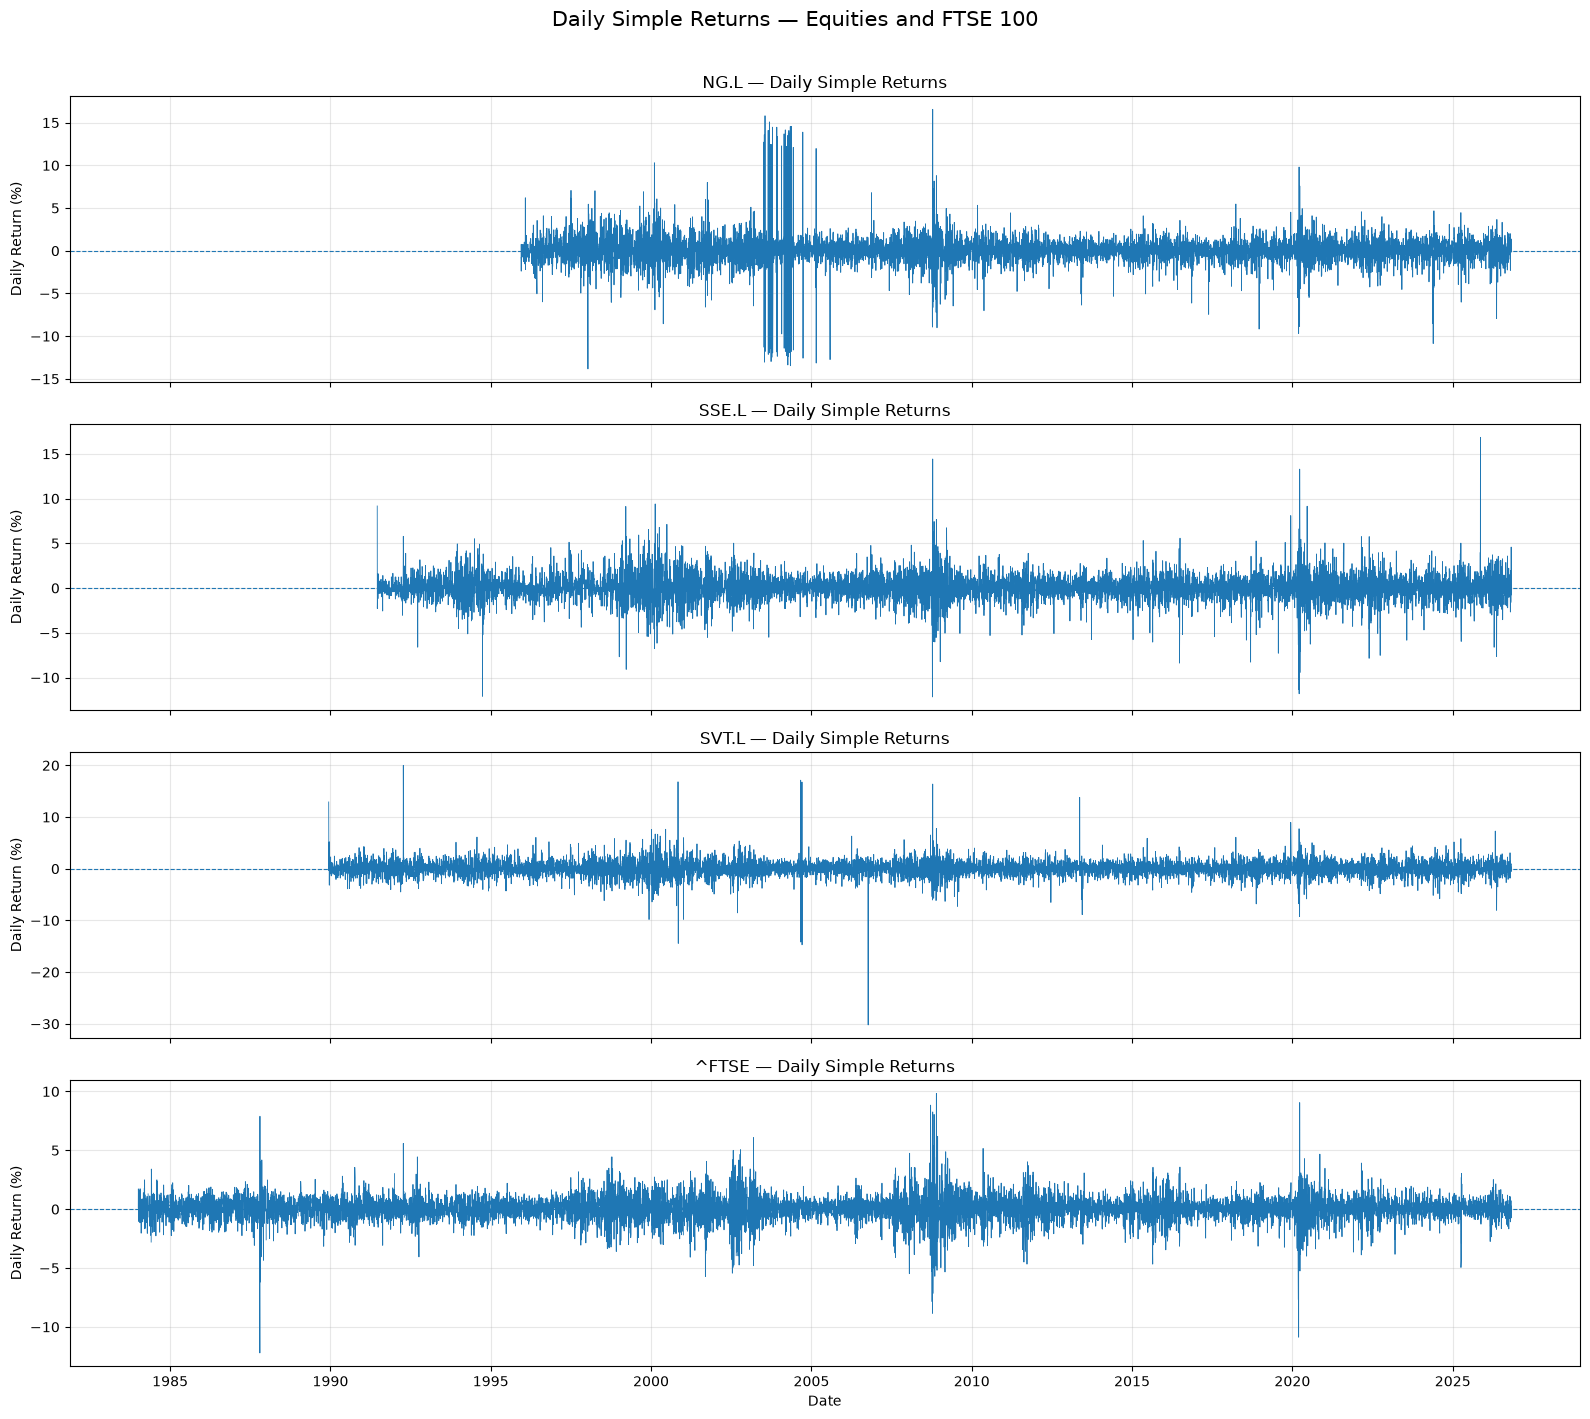

In [367]:
# Visualise daily simple returns across the selected assets.

assets = ["NG.L", "SSE.L", "SVT.L", "^FTSE"]

# Validate the input dataset.

assert all(asset in simple_returns.columns for asset in assets)

returns_to_plot = simple_returns[assets] * 100

fig, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(16, 14),
    sharex=True,
)

for ax, asset in zip(axes, assets):

    ax.plot(
        returns_to_plot.index,
        returns_to_plot[asset],
        linewidth=0.6,
    )

    ax.axhline(
        y=0,
        linestyle="--",
        linewidth=0.8,
    )

    ax.set_title(f"{asset} — Daily Simple Returns")
    ax.set_ylabel("Daily Return (%)")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Date")

fig.suptitle(
    "Daily Simple Returns — Equities and FTSE 100",
    fontsize=15,
    y=1.01,
)

plt.tight_layout()
plt.show()

#### Extreme Daily Return Screening

This diagnostic identifies the largest absolute daily simple returns for each asset.

The objective is to identify observations requiring further investigation, including potential market events, corporate actions and data quality issues.

Extreme observations are not automatically classified as errors or removed from the dataset.

All original observations are preserved.

In [368]:
# Identify the ten largest absolute daily returns for each asset.

extreme_returns = {}

for asset in assets:

    asset_returns = simple_returns[asset].dropna()

    largest_observations = (
        asset_returns
        .loc[asset_returns.abs().nlargest(10).index]
        .sort_values(key=abs, ascending=False)
    )

    extreme_returns[asset] = pd.DataFrame({
        "Date": largest_observations.index,
        "Daily Return (%)": largest_observations.values * 100,
    }).reset_index(drop=True)

    print(f"\n{asset} — Top 10 Absolute Daily Returns")

    display(extreme_returns[asset])


NG.L — Top 10 Absolute Daily Returns


,Date,Daily Return (%)
0,2008-10-13,16.561659
1,2003-07-22,15.804675
2,2003-09-10,15.084452
3,2004-05-17,14.560647
4,2004-05-05,14.548178
5,2003-10-15,14.473185
6,2003-12-03,14.467016
7,2004-03-09,14.152660
8,2003-08-27,14.098578
9,2004-04-19,14.084710



SSE.L — Top 10 Absolute Daily Returns


,Date,Daily Return (%)
0,2025-11-12,16.839700
1,2008-10-13,14.420337
2,2020-03-24,13.286718
3,2008-10-10,-12.168856
4,1994-09-29,-12.096791
5,2020-03-18,-11.813401
6,2020-03-12,-11.336897
7,2020-03-27,-9.443450
8,2000-02-17,9.397045
9,1991-06-18,9.166687



SVT.L — Top 10 Absolute Daily Returns


,Date,Daily Return (%)
0,2006-10-09,-30.220978
1,1992-04-10,20.000012
2,2004-08-31,17.126350
3,2000-11-03,16.809848
4,2004-09-15,16.768879
5,2008-10-13,16.382595
6,2004-09-16,-14.714236
7,2000-11-06,-14.446515
8,2004-09-01,-14.178700
9,2013-05-14,13.808190



^FTSE — Top 10 Absolute Daily Returns


,Date,Daily Return (%)
0,1987-10-20,-12.215566
1,2020-03-12,-10.873819
2,1987-10-19,-10.843211
3,2008-11-24,9.838667
4,2020-03-24,9.053047
5,2008-10-10,-8.848341
6,2008-09-19,8.838111
7,2008-10-13,8.260212
8,2008-10-29,8.050634
9,1987-10-21,7.892988


### 9.3 Descriptive Return Statistics

This section provides a quantitative summary of daily simple returns across the selected equities and the FTSE 100 benchmark.

The analysis examines:

- Number of valid observations.
- Mean and median daily returns.
- Minimum and maximum daily returns.
- Frequency of positive, negative and zero returns.

The objective is to characterise the central tendency and basic behaviour of daily returns across the selected assets.

Calculations are performed independently for each asset, using available observations only.

Missing observations are excluded from individual calculations and are not imputed.

Extreme returns are retained.

No annualisation or predictive interpretation is applied at this stage.

In [369]:
# Calculate descriptive statistics for daily simple returns.

assets = ["NG.L", "SSE.L", "SVT.L", "^FTSE"]

# Validate input data.

assert all(asset in simple_returns.columns for asset in assets)

descriptive_statistics = []

for asset in assets:

    returns = simple_returns[asset].dropna()

    observation_count = len(returns)

    positive_frequency = (returns > 0).mean() * 100
    negative_frequency = (returns < 0).mean() * 100
    zero_frequency = (returns == 0).mean() * 100

    descriptive_statistics.append({
        "Asset": asset,
        "Valid Observations": observation_count,
        "Mean Daily Return (%)": returns.mean() * 100,
        "Median Daily Return (%)": returns.median() * 100,
        "Minimum Daily Return (%)": returns.min() * 100,
        "Maximum Daily Return (%)": returns.max() * 100,
        "Positive Return Frequency (%)": positive_frequency,
        "Negative Return Frequency (%)": negative_frequency,
        "Zero Return Frequency (%)": zero_frequency,
    })

descriptive_returns_df = pd.DataFrame(descriptive_statistics)

display(
    descriptive_returns_df.round(4)
)

,Asset,Valid Observations,Mean Daily Return (%),Median Daily Return (%),Minimum Daily Return (%),Maximum Daily Return (%),Positive Return Frequency (%),Negative Return Frequency (%),Zero Return Frequency (%)
0,NG.L,7888,0.034900,0.012900,-13.836300,16.561700,50.152100,45.943200,3.904700
1,SSE.L,9058,0.037300,0.000000,-12.168900,16.839700,48.288800,45.517800,6.193400
2,SVT.L,9453,0.035100,0.000000,-30.221000,20.000000,48.714700,46.345100,4.940200
3,^FTSE,10684,0.026400,0.058500,-12.215600,9.838700,52.648800,47.173300,0.177800


In [370]:
# Validate descriptive return statistics.

assert descriptive_returns_df["Asset"].tolist() == assets

assert descriptive_returns_df["Valid Observations"].gt(0).all()

assert descriptive_returns_df[
    [
        "Mean Daily Return (%)",
        "Median Daily Return (%)",
        "Minimum Daily Return (%)",
        "Maximum Daily Return (%)",
        "Positive Return Frequency (%)",
        "Negative Return Frequency (%)",
        "Zero Return Frequency (%)",
    ]
].notna().all().all()

frequency_totals = (
    descriptive_returns_df["Positive Return Frequency (%)"]
    + descriptive_returns_df["Negative Return Frequency (%)"]
    + descriptive_returns_df["Zero Return Frequency (%)"]
)

assert np.allclose(frequency_totals, 100.0)

assert (
    descriptive_returns_df["Minimum Daily Return (%)"]
    <= descriptive_returns_df["Maximum Daily Return (%)"]
).all()

print("Descriptive statistics validation completed successfully.")
print("All assets have valid observations.")
print("Return frequencies sum to 100% for every asset.")
print("No missing values detected in the calculated statistics.")

Descriptive statistics validation completed successfully.
All assets have valid observations.
Return frequencies sum to 100% for every asset.
No missing values detected in the calculated statistics.


### 9.4 Rolling Mean Returns Analysis

This section examines the evolution of average daily returns over time using rolling windows.

Two observation windows are considered:

- 21 valid trading observations.
- 63 valid trading observations.

The rolling arithmetic mean is calculated independently for each asset.

The analysis aims to identify changes in the historical average return over shorter and longer observation horizons.

Calculations use available observations only. Missing values are not imputed, and extreme returns are retained.

The rolling averages are descriptive indicators and are not interpreted as forecasts of future returns.

No volatility estimation or annualisation is performed in this section.

In [371]:
# Calculate rolling mean daily returns for each asset.

assets = ["NG.L", "SSE.L", "SVT.L", "^FTSE"]

rolling_windows = {
    "21 Sessions": 21,
    "63 Sessions": 63,
}

rolling_mean_returns = {}

for asset in assets:

    asset_returns = simple_returns[asset].dropna()

    rolling_mean_returns[asset] = pd.DataFrame(
        {
            f"Rolling Mean ({window} Sessions) (%)":
                asset_returns.rolling(
                    window=window,
                    min_periods=window,
                ).mean() * 100
            for label, window in rolling_windows.items()
        },
        index=asset_returns.index,
    )

print("Rolling mean returns calculated successfully.")

Rolling mean returns calculated successfully.


In [372]:
# Validate rolling mean calculations.

for asset in assets:

    asset_returns = simple_returns[asset].dropna()

    rolling_results = rolling_mean_returns[asset]

    assert rolling_results.index.equals(asset_returns.index)

    assert rolling_results.iloc[:20, 0].isna().all()
    assert rolling_results.iloc[:62, 1].isna().all()

    assert rolling_results.iloc[20:, 0].notna().all()
    assert rolling_results.iloc[62:, 1].notna().all()

    assert np.isfinite(
        rolling_results.dropna().to_numpy()
    ).all()

print("Rolling mean validation completed successfully.")
print("All assets passed the validation checks.")

Rolling mean validation completed successfully.
All assets passed the validation checks.


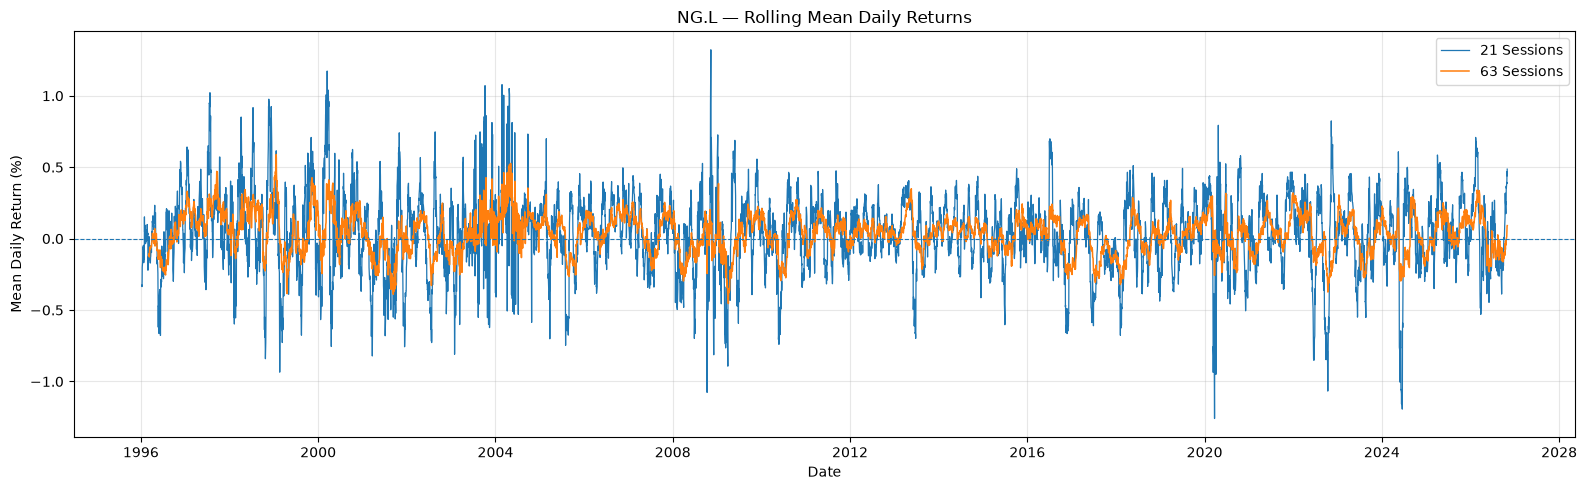

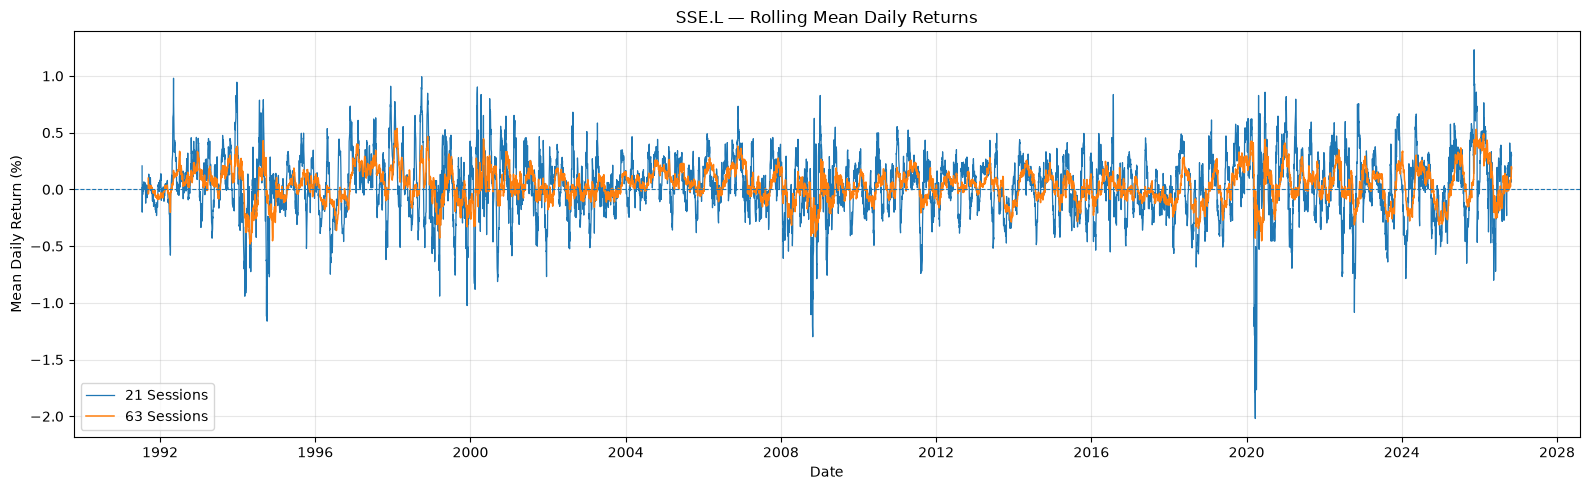

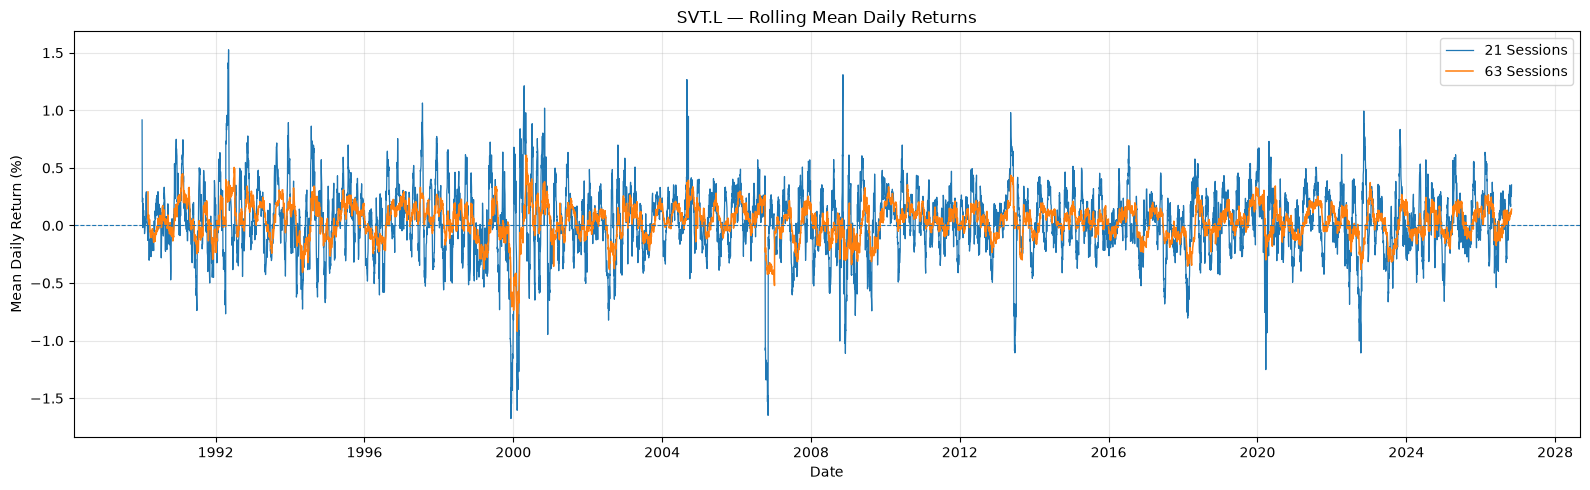

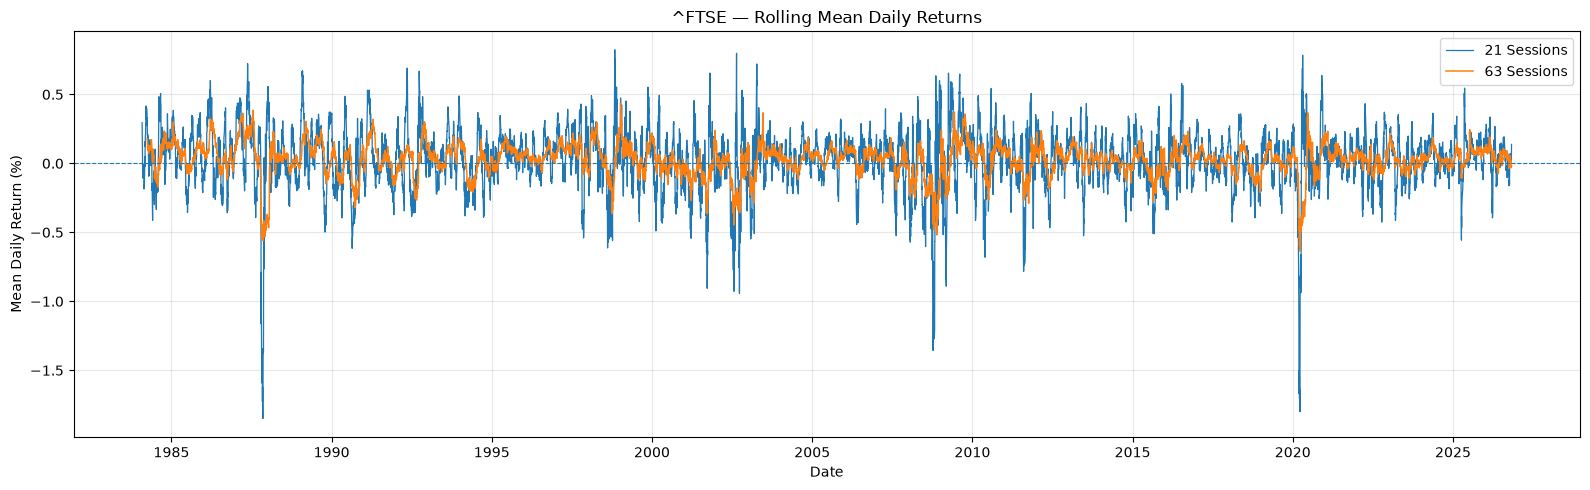

In [373]:
# Visualise rolling mean daily returns.

for asset in assets:

    rolling_results = rolling_mean_returns[asset]

    fig, ax = plt.subplots(figsize=(16, 5))

    ax.plot(
        rolling_results.index,
        rolling_results["Rolling Mean (21 Sessions) (%)"],
        label="21 Sessions",
        linewidth=0.9,
    )

    ax.plot(
        rolling_results.index,
        rolling_results["Rolling Mean (63 Sessions) (%)"],
        label="63 Sessions",
        linewidth=1.1,
    )

    ax.axhline(
        y=0,
        linestyle="--",
        linewidth=0.8,
    )

    ax.set_title(f"{asset} — Rolling Mean Daily Returns")
    ax.set_xlabel("Date")
    ax.set_ylabel("Mean Daily Return (%)")

    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

### 9.4.1 Rolling Mean Returns — Findings and Interpretation

The rolling mean analysis reveals temporal variation in average daily returns across all four assets.

The 21-session rolling mean exhibits greater short-term fluctuations than the 63-session rolling mean, as expected from the longer averaging window.

The main observations are:

- All four assets exhibit periods of positive and negative rolling average returns.
- No asset displays a persistently positive or negative rolling mean throughout the entire observation period.
- NG.L, SSE.L and SVT.L exhibit pronounced short-term fluctuations in several historical periods.
- The FTSE 100 rolling averages appear comparatively more moderate.
- The COVID-19 period is associated with pronounced negative movements across the selected assets.
- Extreme observations can temporarily influence rolling averages.

The results are descriptive and do not establish statistical significance, return predictability or distinct market regimes.

Rolling windows are calculated using valid observations for each asset. Missing observations are not imputed.

The findings provide an initial description of temporal variation in average returns. Formal distributional, stationarity and volatility properties are investigated in subsequent sections.

## 10.1 Distribution Analysis Framework

### Research Objective

This section investigates the statistical distributional properties of daily financial returns across the selected equities and the FTSE 100 benchmark.

The analysis focuses on distribution shape, symmetry, tail behaviour and departures from the normal distribution.

The objective is to determine whether daily returns exhibit distributional characteristics that may have implications for subsequent statistical modelling, forecasting and financial risk analysis.

### Research Questions

The analysis addresses the following research questions:

1. How are daily returns distributed across the selected assets?
2. Are return distributions approximately symmetric?
3. Do returns exhibit positive or negative skewness?
4. Do return distributions exhibit heavier tails than a normal distribution?
5. Are extreme returns more frequent than expected under normality?
6. Do individual equities exhibit different distributional characteristics compared with the FTSE 100?
7. Is the normal distribution an appropriate statistical approximation for daily returns?

### Statistical Concepts

The analysis examines the following distributional properties:

**Standard Deviation**

Measures the dispersion of daily returns around their arithmetic mean.

**Skewness**

Measures the asymmetry of a return distribution.

- Positive skewness indicates a relatively longer or heavier right tail.
- Negative skewness indicates a relatively longer or heavier left tail.
- Skewness close to zero indicates approximate symmetry.

**Excess Kurtosis**

Measures the relative tail weight of a distribution compared with a normal distribution.

- Positive excess kurtosis indicates heavier tails relative to normality.
- Negative excess kurtosis indicates lighter tails relative to normality.
- Excess kurtosis close to zero indicates similarity to the normal distribution in this respect.

**Quantiles**

Describe the distribution of returns at selected percentile levels and provide information about the lower and upper tails.

### Methodology

The analysis uses daily logarithmic returns from the previously prepared `log_returns` dataset.

Each asset is examined independently:

- NG.L
- SSE.L
- SVT.L
- FTSE 100

The logarithmic returns are expressed as percentages for presentation and interpretation.

Missing observations are excluded independently for each asset.

No missing-value imputation, outlier removal or winsorisation is permitted.

Extreme observations are retained throughout the analysis.

### Distributional Reference

The normal distribution is used as a statistical reference for examining the empirical return distributions.

The normal reference distribution is estimated using the sample mean and standard deviation of each asset's observed returns.

The comparison does not assume that financial returns follow a normal distribution.

### Statistical Assessment

The Jarque-Bera test is used to assess departures from normality.

The hypotheses are:

- Null hypothesis (H0): The observations are consistent with a normal distribution.
- Alternative hypothesis (H1): The observations are inconsistent with a normal distribution.

The significance level is set at 5%.

Statistical test results are interpreted alongside distribution plots, skewness, excess kurtosis and empirical tail behaviour.

Statistical significance is not interpreted as equivalent to economic significance.

### Research Limitations

The analysis is subject to the following limitations:

- Historical observation periods differ across assets.
- Distributional properties may change over time.
- Extreme observations can materially influence skewness, kurtosis and normality tests.
- Statistical normality tests do not establish independence or stationarity.
- Historical distributional characteristics do not establish predictive value.

Temporal dependence and stationarity are investigated separately in subsequent sections.

### Expected Outputs

The section will produce:

- Empirical return distribution visualisations.
- Distribution shape statistics.
- Quantile-based tail assessments.
- Normal Q-Q plots.
- Statistical normality test results.
- Comparative findings across the selected assets.

The findings will provide an empirical basis for subsequent time-series analysis and financial modelling research.


### 10.2 Return Distribution Visualisation

This section examines the empirical distribution of daily logarithmic returns across the selected equities and the FTSE 100 benchmark.

The analysis compares the observed return distributions with theoretical normal distributions estimated independently for each asset.

Four individual histograms are constructed using probability density normalisation.

The Freedman-Diaconis rule is used to determine histogram bin widths.

The theoretical normal distribution is parameterised using the sample mean and sample standard deviation of each asset's observed returns.

The visualisations aim to identify:

- Distribution symmetry or asymmetry.
- Concentration of observations around the mean.
- Differences between empirical and theoretical distributions.
- Potentially heavier tails relative to normality.
- Extreme observations and deviations from the normal reference.

Missing observations are excluded independently for each asset.

Extreme returns are preserved. No outlier removal, winsorisation or imputation is applied.

The visual comparison is exploratory and does not constitute a formal statistical test of normality.

In [374]:
# Prepare daily logarithmic returns for distribution analysis.

assets = ["NG.L", "SSE.L", "SVT.L", "^FTSE"]

distribution_data = {}

for asset in assets:

    returns = log_returns[asset].dropna() * 100

    distribution_data[asset] = returns

    print(
        f"{asset}: "
        f"{len(returns):,} observations | "
        f"Mean: {returns.mean():.6f}% | "
        f"Standard deviation: {returns.std():.6f}%"
    )

NG.L: 7,888 observations | Mean: 0.019597% | Standard deviation: 1.750197%
SSE.L: 9,058 observations | Mean: 0.026603% | Standard deviation: 1.462259%
SVT.L: 9,453 observations | Mean: 0.023096% | Standard deviation: 1.553233%
^FTSE: 10,684 observations | Mean: 0.020669% | Standard deviation: 1.069702%


In [375]:
# Validate distribution analysis inputs.

assert all(asset in distribution_data for asset in assets)

for asset in assets:

    returns = distribution_data[asset]

    assert len(returns) > 0
    assert returns.notna().all()
    assert np.isfinite(returns.to_numpy()).all()

    assert returns.std() > 0

print("\nDistribution data validation completed successfully.")
print("All four assets passed the validation checks.")
print("No missing or infinite values remain in the analytical inputs.")


Distribution data validation completed successfully.
All four assets passed the validation checks.
No missing or infinite values remain in the analytical inputs.


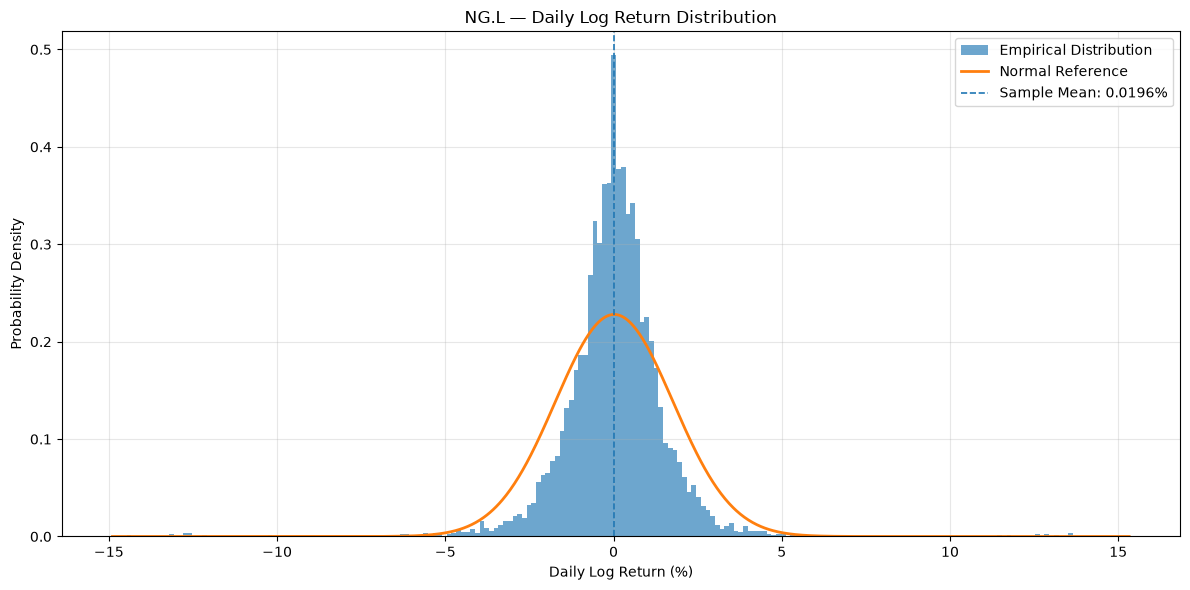

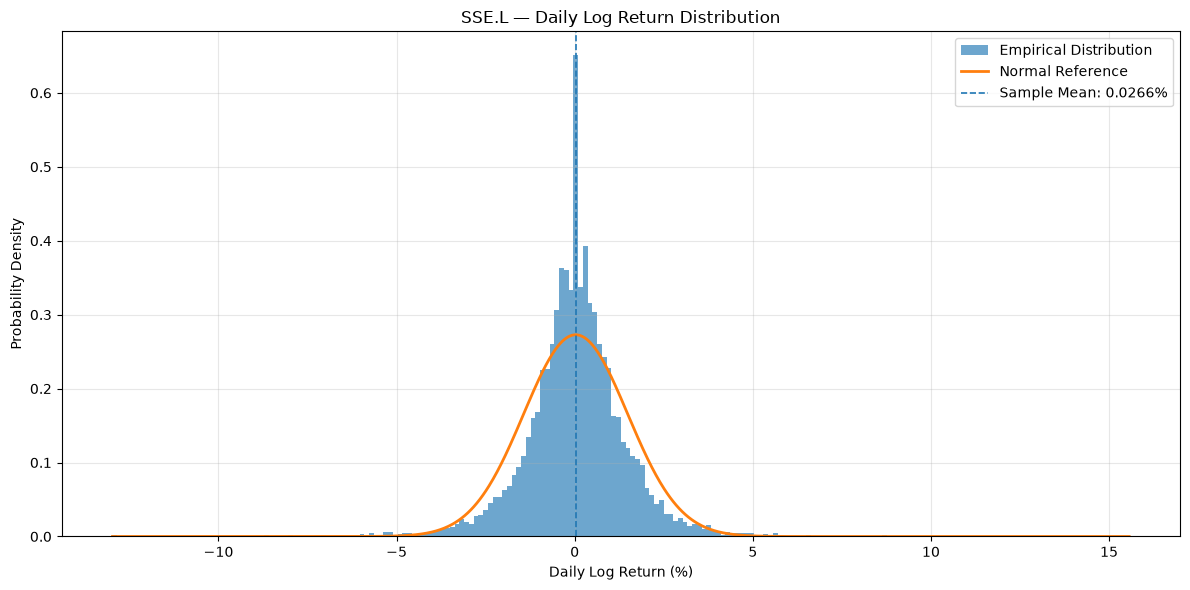

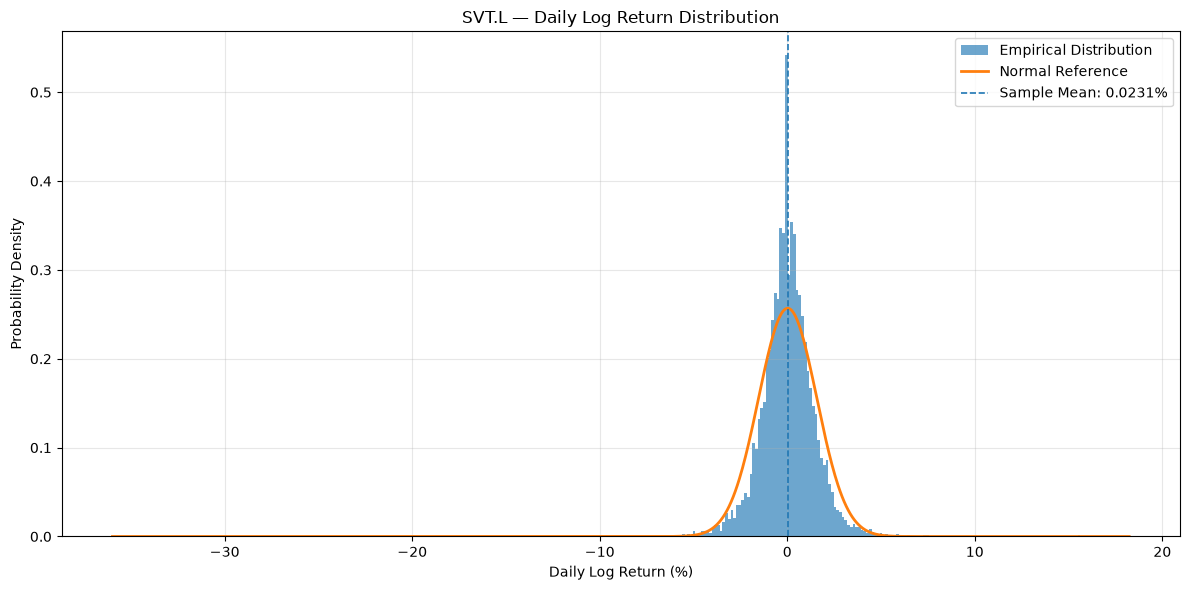

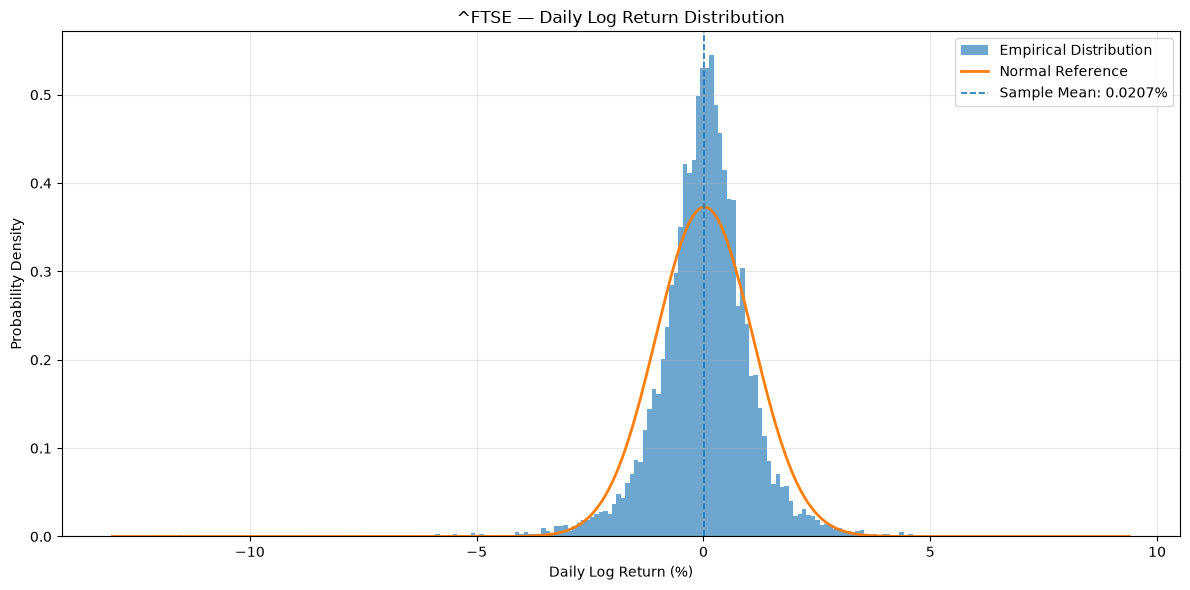

In [376]:
# Visualise empirical return distributions against normal references.

from scipy.stats import norm

for asset in assets:

    returns = distribution_data[asset]

    # Estimate normal distribution parameters.

    sample_mean = returns.mean()
    sample_std = returns.std(ddof=1)

    # Generate the theoretical normal density.

    x_values = np.linspace(
        returns.min(),
        returns.max(),
        1000,
    )

    normal_density = norm.pdf(
        x_values,
        loc=sample_mean,
        scale=sample_std,
    )

    # Create the distribution plot.

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.hist(
        returns,
        bins="fd",
        density=True,
        alpha=0.65,
        label="Empirical Distribution",
    )

    ax.plot(
        x_values,
        normal_density,
        linewidth=2,
        label="Normal Reference",
    )

    ax.axvline(
        sample_mean,
        linestyle="--",
        linewidth=1.2,
        label=f"Sample Mean: {sample_mean:.4f}%",
    )

    ax.set_title(
        f"{asset} — Daily Log Return Distribution"
    )

    ax.set_xlabel("Daily Log Return (%)")
    ax.set_ylabel("Probability Density")

    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

### 10.2.1 Distribution Visualisation — Preliminary Findings

The empirical daily logarithmic return distributions exhibit visible departures from their respective normal reference distributions across all four assets.

The main visual observations are:

- All four assets exhibit pronounced concentrations of observations around the centre of their empirical distributions.
- The empirical distributions display higher central peaks than their corresponding fitted normal reference distributions.
- The empirical tails appear more pronounced than those of the normal reference distributions.
- Extreme observations are visible in both positive and negative directions.
- The magnitude and shape of these deviations differ across the selected assets.

NG.L exhibits a pronounced central concentration and extended empirical tails.

SSE.L displays a particularly sharp central peak, together with observations extending into both tails.

SVT.L exhibits substantial tail dispersion, including extreme negative observations.

The FTSE 100 also displays a concentrated central distribution and visible deviations from the normal reference.

These observations suggest potential departures from normality, including possible excess kurtosis and distributional asymmetry.

However, visual inspection alone cannot establish statistical significance or formally determine the distributional properties.

The concentration of observations near zero may also reflect zero or small daily price changes.

Formal assessment of skewness, excess kurtosis and tail quantiles is deferred to Section 10.3.

No observations have been removed or modified.

### 10.3 Distribution Shape Statistics

#### 10.3.1 Statistical Measures

This section quantifies the distributional characteristics of daily logarithmic returns for NG.L, SSE.L, SVT.L and the FTSE 100.

The analysis includes:

- Number of valid observations.
- Mean and median.
- Sample standard deviation.
- Skewness.
- Excess kurtosis.
- 1st, 5th, 95th and 99th percentiles.

All return statistics are expressed as percentages. Skewness and excess kurtosis are dimensionless.

Calculations are performed independently for each asset using available observations only.

Extreme observations are retained. No imputation, interpolation, winsorisation or outlier removal is applied.

The results are descriptive and do not establish statistical significance, future return characteristics or predictive value.

In [377]:
from scipy.stats import skew, kurtosis

distribution_statistics = {}

for asset in assets:

    returns = log_returns[asset].dropna() * 100

    statistics = {
        "Observations": len(returns),
        "Mean (%)": returns.mean(),
        "Median (%)": returns.median(),
        "Standard Deviation (%)": returns.std(ddof=1),
        "Skewness": skew(returns, bias=False),
        "Excess Kurtosis": kurtosis(
            returns,
            fisher=True,
            bias=False,
        ),
        "1st Percentile (%)": returns.quantile(0.01),
        "5th Percentile (%)": returns.quantile(0.05),
        "95th Percentile (%)": returns.quantile(0.95),
        "99th Percentile (%)": returns.quantile(0.99),
    }

    distribution_statistics[asset] = statistics

distribution_statistics_df = pd.DataFrame.from_dict(
    distribution_statistics,
    orient="index",
)

distribution_statistics_df.index.name = "Asset"

distribution_statistics_df

,Observations,Mean (%),Median (%),Standard Deviation (%),Skewness,Excess Kurtosis,1st Percentile (%),5th Percentile (%),95th Percentile (%),99th Percentile (%)
Asset,,,,,,,,,,
NG.L,7888,0.019597,0.012914,1.750197,-0.341175,21.040228,-4.620640,-2.178334,2.176218,4.021650
SSE.L,9058,0.026603,0.000000,1.462259,-0.203674,8.946448,-4.037076,-2.215607,2.201870,3.809090
SVT.L,9453,0.023096,0.000000,1.553233,-1.119516,42.647473,-3.903774,-2.226796,2.225057,3.854824
^FTSE,10684,0.020669,0.058478,1.069702,-0.579192,10.535358,-3.046623,-1.597838,1.548889,2.716240


In [378]:
# Validate the statistical results.

expected_observations = {
    "NG.L": 7888,
    "SSE.L": 9058,
    "SVT.L": 9453,
    "^FTSE": 10684,
}

assert distribution_statistics_df.index.tolist() == assets

assert (
    distribution_statistics_df["Observations"].to_dict()
    == expected_observations
)

assert distribution_statistics_df.notna().all().all()

assert np.isfinite(
    distribution_statistics_df.select_dtypes(
        include=[np.number]
    ).to_numpy()
).all()

assert (
    distribution_statistics_df["Standard Deviation (%)"] > 0
).all()

assert (
    distribution_statistics_df["1st Percentile (%)"]
    <= distribution_statistics_df["5th Percentile (%)"]
).all()

assert (
    distribution_statistics_df["5th Percentile (%)"]
    <= distribution_statistics_df["95th Percentile (%)"]
).all()

assert (
    distribution_statistics_df["95th Percentile (%)"]
    <= distribution_statistics_df["99th Percentile (%)"]
).all()

print("Distribution statistics validation completed successfully.")
print("All four assets passed the validation checks.")
print("Observation counts match the expected values.")
print("No missing or infinite statistical results were detected.")

Distribution statistics validation completed successfully.
All four assets passed the validation checks.
Observation counts match the expected values.
No missing or infinite statistical results were detected.


### 10.3.3 Comparative Results

This section compares the distributional characteristics of the four selected assets.

The comparison covers:

- Historical return volatility.
- Distributional skewness.
- Excess kurtosis.
- Negative and positive return percentiles.

Assets are ranked independently for each statistical measure.

Negative and positive tail magnitudes are compared using the 1st and 99th percentiles, and the 5th and 95th percentiles.

The analysis is descriptive and does not establish statistical significance, future risk or predictive value.

In [379]:
comparison_results = distribution_statistics_df.copy()

comparison_results["Volatility Rank"] = (
    comparison_results["Standard Deviation (%)"]
    .rank(ascending=False, method="min")
    .astype(int)
)

comparison_results["Negative Skewness Rank"] = (
    comparison_results["Skewness"]
    .rank(ascending=True, method="min")
    .astype(int)
)

comparison_results["Excess Kurtosis Rank"] = (
    comparison_results["Excess Kurtosis"]
    .rank(ascending=False, method="min")
    .astype(int)
)

comparison_results[
    [
        "Standard Deviation (%)",
        "Volatility Rank",
        "Skewness",
        "Negative Skewness Rank",
        "Excess Kurtosis",
        "Excess Kurtosis Rank",
    ]
].sort_values("Volatility Rank")

,Standard Deviation (%),Volatility Rank,Skewness,Negative Skewness Rank,Excess Kurtosis,Excess Kurtosis Rank
Asset,,,,,,
NG.L,1.750197,1,-0.341175,3,21.040228,2
SVT.L,1.553233,2,-1.119516,1,42.647473,1
SSE.L,1.462259,3,-0.203674,4,8.946448,4
^FTSE,1.069702,4,-0.579192,2,10.535358,3


In [380]:
tail_comparison = pd.DataFrame(
    index=distribution_statistics_df.index
)

tail_comparison["Negative Tail P1 (%)"] = (
    distribution_statistics_df["1st Percentile (%)"].abs()
)

tail_comparison["Positive Tail P99 (%)"] = (
    distribution_statistics_df["99th Percentile (%)"]
)

tail_comparison["P1-P99 Difference (%)"] = (
    tail_comparison["Negative Tail P1 (%)"]
    - tail_comparison["Positive Tail P99 (%)"]
)

tail_comparison["P1-P99 Ratio"] = (
    tail_comparison["Negative Tail P1 (%)"]
    / tail_comparison["Positive Tail P99 (%)"]
)

tail_comparison["Negative Tail P5 (%)"] = (
    distribution_statistics_df["5th Percentile (%)"].abs()
)

tail_comparison["Positive Tail P95 (%)"] = (
    distribution_statistics_df["95th Percentile (%)"]
)

tail_comparison["P5-P95 Difference (%)"] = (
    tail_comparison["Negative Tail P5 (%)"]
    - tail_comparison["Positive Tail P95 (%)"]
)

tail_comparison["P5-P95 Ratio"] = (
    tail_comparison["Negative Tail P5 (%)"]
    / tail_comparison["Positive Tail P95 (%)"]
)

tail_comparison

,Negative Tail P1 (%),Positive Tail P99 (%),P1-P99 Difference (%),P1-P99 Ratio,Negative Tail P5 (%),Positive Tail P95 (%),P5-P95 Difference (%),P5-P95 Ratio
Asset,,,,,,,,
NG.L,4.620640,4.021650,0.598990,1.148941,2.178334,2.176218,0.002116,1.000973
SSE.L,4.037076,3.809090,0.227986,1.059853,2.215607,2.201870,0.013736,1.006238
SVT.L,3.903774,3.854824,0.048950,1.012698,2.226796,2.225057,0.001740,1.000782
^FTSE,3.046623,2.716240,0.330382,1.121632,1.597838,1.548889,0.048949,1.031603


In [381]:
assert comparison_results.index.equals(
    distribution_statistics_df.index
)

assert tail_comparison.index.equals(
    distribution_statistics_df.index
)

assert comparison_results[
    [
        "Volatility Rank",
        "Negative Skewness Rank",
        "Excess Kurtosis Rank",
    ]
].notna().all().all()

assert tail_comparison.notna().all().all()

assert np.isfinite(
    tail_comparison.to_numpy()
).all()

assert (
    tail_comparison[
        [
            "Negative Tail P1 (%)",
            "Positive Tail P99 (%)",
            "Negative Tail P5 (%)",
            "Positive Tail P95 (%)",
        ]
    ] > 0
).all().all()

print("Comparative analysis validation completed successfully.")
print("All rankings and tail comparisons passed validation.")

Comparative analysis validation completed successfully.
All rankings and tail comparisons passed validation.


### 10.3.4 Comparative Findings

The comparative analysis identified relevant differences in the distributional characteristics of the four selected assets.

**Volatility**

NG.L exhibited the highest historical daily return standard deviation at 1.7502%, followed by SVT.L at 1.5532% and SSE.L at 1.4623%.

The FTSE 100 exhibited the lowest standard deviation at 1.0697%.

**Skewness**

All four assets displayed negative skewness.

SVT.L presented the strongest negative skewness (-1.1195), followed by the FTSE 100 (-0.5792), NG.L (-0.3412) and SSE.L (-0.2037).

**Excess Kurtosis**

All four assets exhibited positive excess kurtosis.

SVT.L presented the highest value (42.6475), followed by NG.L (21.0402), the FTSE 100 (10.5354) and SSE.L (8.9464).

These results indicate substantial departures from the kurtosis of a normal distribution. Extreme observations may have a considerable influence on these estimates.

**Tail Asymmetry**

The comparison between the 1st and 99th percentiles showed greater negative than positive tail magnitudes for all four assets.

NG.L presented the largest relative difference, with a negative-to-positive tail ratio of 1.1489.

At the 5th and 95th percentiles, negative and positive tail magnitudes were much closer.

This indicates that the observed tail asymmetry is more pronounced at the more extreme percentile comparison.

**Overall Assessment**

NG.L exhibited the highest historical volatility, while SVT.L displayed the strongest negative skewness and highest excess kurtosis.

The FTSE 100 exhibited lower volatility than the individual equities, but still displayed negative skewness and positive excess kurtosis.

These findings are descriptive and do not establish statistical significance, future risk or predictive value.

### 10.4 Q-Q Plot Analysis

#### 10.4.1 Q-Q Plot Methodology

The objective of this section is to visually assess the extent to which the empirical distributions of daily logarithmic returns differ from a theoretical normal distribution.

The analysis covers NG.L, SSE.L, SVT.L and the FTSE 100.

For each asset:

- Daily logarithmic returns are expressed as percentages.
- Missing observations are excluded independently.
- All available observations are retained, including extreme returns.
- Empirical quantiles are compared with theoretical normal quantiles.
- A fitted normal reference line is included.

Four independent Q-Q plots will be generated.

The analysis focuses on central distribution alignment, systematic deviations, tail behaviour and potential asymmetry.

Visual inspection does not establish statistical normality or statistical significance. Formal normality assessment is reserved for Section 10.5.

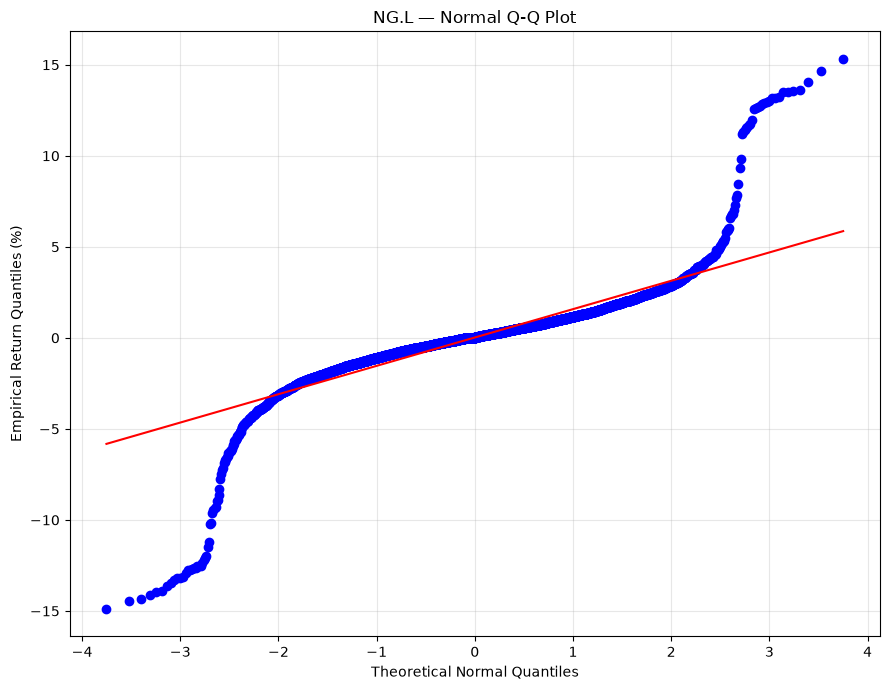

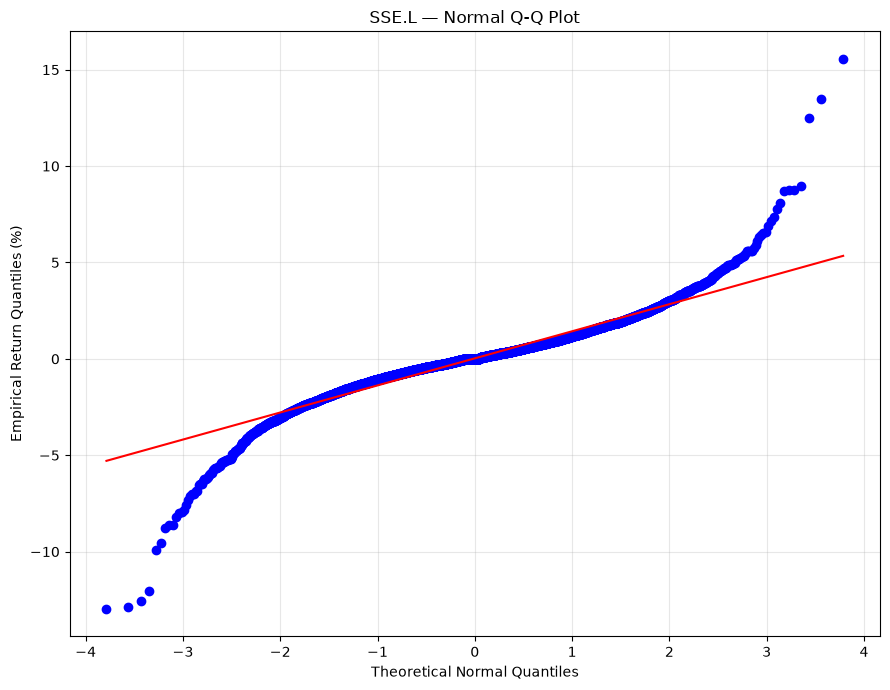

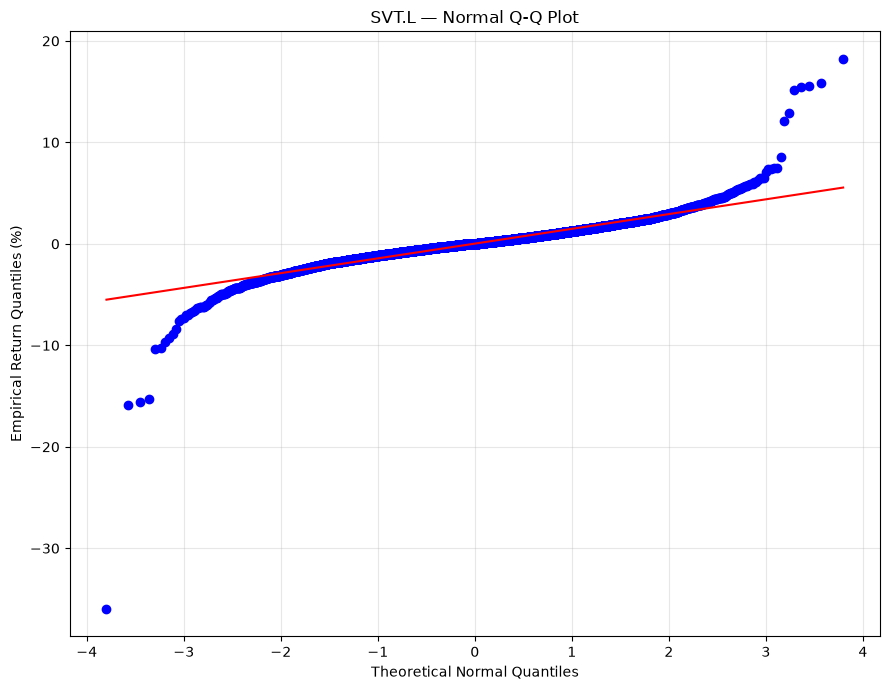

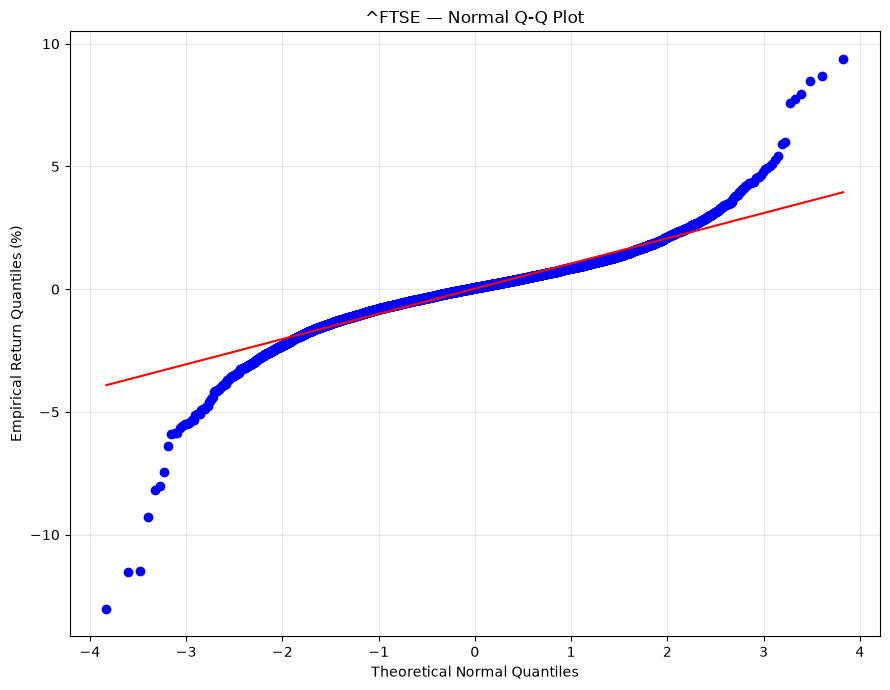

In [382]:
from scipy import stats

for asset in assets:

    returns = distribution_data[asset]

    fig, ax = plt.subplots(figsize=(9, 7))

    stats.probplot(
        returns,
        dist="norm",
        plot=ax,
    )

    ax.set_title(
        f"{asset} — Normal Q-Q Plot"
    )

    ax.set_xlabel("Theoretical Normal Quantiles")
    ax.set_ylabel("Empirical Return Quantiles (%)")

    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

### 10.4.3 Q-Q Plot Visual Analysis

The Q-Q plots reveal substantial departures from the theoretical normal distribution across all four selected assets.

**NG.L**

The central portion of the distribution exhibits relatively closer alignment with the reference line. However, both tails display pronounced deviations.

The negative tail contains observations substantially below the theoretical normal reference, while the positive tail also exhibits considerable departures.

These observations are consistent with the high excess kurtosis previously calculated.

**SSE.L**

The central observations exhibit relatively closer alignment with the reference line. Both tails display systematic departures, including several particularly pronounced positive observations.

Although SSE.L has the lowest excess kurtosis among the four assets, its empirical distribution still differs visibly from the normal reference.

**SVT.L**

SVT.L exhibits particularly pronounced deviations in the negative tail, including an extreme observation near -36%.

The positive tail also displays substantial departures from the reference line.

These visual findings are consistent with the strongly negative skewness and exceptionally high excess kurtosis identified in Section 10.3.

**FTSE 100**

The FTSE 100 exhibits relatively closer alignment in the central region, but substantial deviations remain in both tails.

The results indicate that the benchmark also displays distributional characteristics that are not adequately represented by a normal distribution.

**Comparative Assessment**

All four assets exhibit systematic departures from the normal reference, particularly in their distributional tails.

SVT.L displays the most pronounced negative-tail deviation, while NG.L exhibits substantial deviations in both tails.

The visual evidence is consistent with the previously calculated skewness and excess kurtosis statistics.

No observations have been removed or modified.

These findings are based on visual inspection and do not constitute formal statistical tests of normality.

### 10.5 Statistical Normality Assessment

#### 10.5.1 Statistical Testing Framework

The objective of this section is to formally assess whether the empirical distributions of daily logarithmic returns are consistent with a normal distribution.

The Jarque-Bera test will be applied independently to:

- NG.L
- SSE.L
- SVT.L
- FTSE 100

**Hypotheses**

- Null hypothesis (H0): The observations are drawn from a normally distributed population.
- Alternative hypothesis (H1): The observations are not drawn from a normally distributed population.

**Testing configuration**

- Statistical test: Jarque-Bera.
- Significance level: 5%.
- Input: Daily logarithmic returns expressed as percentages.
- Missing observations: Excluded independently for each asset.
- Extreme observations: Retained.
- No imputation, interpolation, winsorisation or outlier removal.

**Decision rule**

- If the p-value is below 0.05, reject the null hypothesis.
- If the p-value is equal to or above 0.05, do not reject the null hypothesis.

The test evaluates distributional normality through sample skewness and kurtosis.

Its results will be interpreted alongside the descriptive statistics, histograms and Q-Q plots produced in previous sections.

The Jarque-Bera test does not assess independence, stationarity or temporal dependence. Its asymptotic reference distribution also relies on sampling assumptions that may be affected by serial dependence and changing financial market conditions.

Statistical rejection does not, by itself, establish economic significance or predictive value.

In [383]:
from scipy.stats import jarque_bera

SIGNIFICANCE_LEVEL = 0.05

normality_results = {}

for asset in assets:

    returns = distribution_data[asset]

    test_result = jarque_bera(returns)

    normality_results[asset] = {
        "Observations": len(returns),
        "JB Statistic": test_result.statistic,
        "p-value": test_result.pvalue,
        "Significance Level": SIGNIFICANCE_LEVEL,
        "Decision": (
            "Reject H0"
            if test_result.pvalue < SIGNIFICANCE_LEVEL
            else "Do not reject H0"
        ),
    }

normality_results_df = pd.DataFrame.from_dict(
    normality_results,
    orient="index",
)

normality_results_df.index.name = "Asset"

normality_results_df

,Observations,JB Statistic,p-value,Significance Level,Decision
Asset,,,,,
NG.L,7888,145455.939893,0.000000,0.050000,Reject H0
SSE.L,9058,30232.828504,0.000000,0.050000,Reject H0
SVT.L,9453,717577.713272,0.000000,0.050000,Reject H0
^FTSE,10684,49956.407723,0.000000,0.050000,Reject H0


In [384]:
expected_observations = {
    "NG.L": 7888,
    "SSE.L": 9058,
    "SVT.L": 9453,
    "^FTSE": 10684,
}

assert normality_results_df.index.tolist() == assets

assert (
    normality_results_df["Observations"].to_dict()
    == expected_observations
)

assert normality_results_df.notna().all().all()

assert np.isfinite(
    normality_results_df[
        ["JB Statistic", "p-value"]
    ].to_numpy()
).all()

assert (
    normality_results_df["JB Statistic"] >= 0
).all()

assert (
    (normality_results_df["p-value"] >= 0)
    & (normality_results_df["p-value"] <= 1)
).all()

assert (
    normality_results_df["Significance Level"]
    == SIGNIFICANCE_LEVEL
).all()

print("Jarque-Bera test validation completed successfully.")
print("All four assets passed the validation checks.")
print("Observation counts match the expected values.")
print("No missing or infinite test results were detected.")

Jarque-Bera test validation completed successfully.
All four assets passed the validation checks.
Observation counts match the expected values.
No missing or infinite test results were detected.


### 10.5.3 Statistical Results and Interpretation

The Jarque-Bera test was applied independently to the daily logarithmic returns of NG.L, SSE.L, SVT.L and the FTSE 100.

The significance level was set at 5%.

**Test Results**

All four assets produced p-values below the significance threshold of 0.05.

Consequently, the null hypothesis of normality was rejected for every asset.

The results are summarised below:

| Asset | Observations | JB Statistic | Decision |
|---|---:|---:|---|
| NG.L | 7,888 | 145,455.94 | Reject H0 |
| SSE.L | 9,058 | 30,232.83 | Reject H0 |
| SVT.L | 9,453 | 717,577.71 | Reject H0 |
| FTSE 100 | 10,684 | 49,956.41 | Reject H0 |

**Individual Assessment**

NG.L exhibits substantial departures from normality, consistent with its negative skewness and high excess kurtosis.

SSE.L also rejects normality despite presenting the lowest excess kurtosis among the four assets.

SVT.L produces the highest Jarque-Bera statistic, consistent with its pronounced negative skewness and exceptionally high excess kurtosis.

The FTSE 100 also rejects normality, indicating that the benchmark's return distribution is not adequately represented by a normal distribution.

**Overall Assessment**

The Jarque-Bera results provide formal statistical evidence against the normality assumption for all four selected assets.

These findings are consistent with the distributional characteristics identified through descriptive statistics, histograms and Q-Q plots.

The results should be interpreted with caution because the conventional Jarque-Bera test relies on asymptotic assumptions that may be affected by serial dependence and changing financial market conditions.

Statistical rejection does not establish predictive value, future risk or the existence of exploitable trading opportunities.

### 10.6 Distribution Analysis Findings

#### 10.6.1 Overall Findings

The analysis of daily logarithmic return distributions identified substantial differences between the four selected assets.

The main findings are summarised below.

**Volatility**

NG.L exhibited the highest historical standard deviation of daily returns (1.7502%), followed by SVT.L (1.5532%) and SSE.L (1.4623%).

The FTSE 100 exhibited the lowest standard deviation (1.0697%).

**Distributional Asymmetry**

All four assets displayed negative skewness.

SVT.L presented the strongest negative skewness (-1.1195), indicating a more pronounced influence of negative observations on its distributional asymmetry.

**Excess Kurtosis**

All four assets exhibited positive and elevated excess kurtosis.

SVT.L presented the highest value (42.6475), followed by NG.L (21.0402), the FTSE 100 (10.5354) and SSE.L (8.9464).

These results indicate substantial departures from the kurtosis of a normal distribution. Extreme observations may have a considerable influence on these estimates.

**Tail Behaviour**

The comparison between the 1st and 99th percentiles showed greater negative than positive tail magnitudes for all four assets.

At the 5th and 95th percentiles, the negative and positive magnitudes were considerably closer.

This suggests that the observed tail asymmetry is more pronounced at the more extreme percentile comparison.

**Normality Assessment**

The Jarque-Bera test rejected the null hypothesis of normality for all four assets at the 5% significance level.

These results are consistent with the deviations observed in the histograms and Q-Q plots.

The historical return distributions are therefore not adequately represented by a normal distribution across their full observed ranges.

#### 10.6.2 Asset-Specific Findings

**NG.L**

NG.L exhibited the highest historical return volatility among the selected assets.

Its distribution displayed negative skewness, elevated excess kurtosis and pronounced deviations from normality in both tails.

**SSE.L**

SSE.L exhibited the lowest excess kurtosis among the four assets, although its distribution still displayed negative skewness and substantial departures from normality.

**SVT.L**

SVT.L presented the strongest negative skewness and the highest excess kurtosis.

Its Q-Q plot also revealed a particularly pronounced negative-tail observation.

These characteristics warrant further investigation

### 10.7 Statistical Interpretation

#### 10.7.1 Volatility Interpretation

The historical standard deviations indicate substantial differences in return dispersion across the selected assets.

NG.L exhibited the highest standard deviation (1.7502%), while the FTSE 100 exhibited the lowest (1.0697%).

This suggests that the individual equities experienced greater historical daily return variability than the benchmark over their respective observation periods.

However, the different historical coverage periods prevent a fully controlled comparison.

The lower volatility of the FTSE 100 is consistent with the potential diversification effect of a broad market index, although this analysis does not establish diversification as the sole explanation.

#### 10.7.2 Distributional Asymmetry

All four assets exhibited negative skewness.

SVT.L presented the strongest negative skewness (-1.1195), followed by the FTSE 100 (-0.5792), NG.L (-0.3412) and SSE.L (-0.2037).

Negative skewness indicates that the empirical distributions are asymmetric towards negative returns.

This characteristic suggests that symmetric distributional assumptions may not adequately represent the historical return behaviour of these assets.

However, negative skewness does not imply that negative returns necessarily occur more frequently than positive returns.

#### 10.7.3 Excess Kurtosis and Extreme Returns

All four assets exhibited positive excess kurtosis.

SVT.L presented the highest value (42.6475), followed by NG.L (21.0402), the FTSE 100 (10.5354) and SSE.L (8.9464).

These results indicate substantial differences from the kurtosis of a normal distribution.

The elevated values are consistent with the pronounced tail deviations observed in the Q-Q plots.

Excess kurtosis is sensitive to extreme observations and should not be interpreted independently as a measure of future risk.

The observed extreme returns have been retained without modification.

#### 10.7.4 Normality Assessment

The Jarque-Bera test rejected the null hypothesis of normality for all four assets at the 5% significance level.

These statistical results are consistent with the histogram and Q-Q plot observations.

The findings indicate that a normal distribution does not adequately represent the full historical return distributions of the selected assets.

Nevertheless, rejection of normality does not establish that normal approximations are unsuitable for every possible analytical application or historical sub-period.

The Jarque-Bera test

### 10.8 Limitations

#### 10.8.1 Data Limitations

The four selected assets have different historical observation periods.

Consequently, direct comparisons of distributional statistics are subject to differences in sample coverage.

Missing observations and differences in trading calendars may also affect the temporal representation of the return series.

Although missing values were excluded independently, no interpolation or imputation was performed.

The analysis also relies on the adjusted closing price series available in the dataset. Any limitations in historical price adjustments or corporate action records may affect calculated returns.

#### 10.8.2 Statistical Limitations

Skewness and excess kurtosis are sensitive to extreme observations.

Consequently, a small number of unusually large returns may have a considerable influence on these statistics.

The Jarque-Bera test is also sensitive to sample size. With thousands of observations, relatively small departures from normality may lead to statistical rejection.

The statistical results should therefore be interpreted alongside the graphical analysis and descriptive measures rather than independently.

#### 10.8.3 Distributional Limitations

The analysis considers the historical return distribution over the full available sample for each asset.

This approach may conceal changes in distributional characteristics over time.

Financial return distributions may change across market conditions, economic cycles and structural breaks.

The present analysis does not establish whether the identified characteristics remain stable across different historical periods.

#### 10.8.4 Normality Testing Limitations

The Jarque-Bera test evaluates normality through sample skewness and kurtosis.

Its conventional asymptotic reference distribution relies on assumptions that may be affected by serial dependence and changing financial market conditions.

The test does not assess:

- Serial independence.
- Stationarity.
- Conditional heteroskedasticity.
- Structural breaks.
- Predictive value.

Furthermore, rejecting normality does not identify which alternative probability distribution would provide a better representation of the returns.

#### 10.8.5 Economic and Predictive Limitations

The statistical characteristics identified in this section do not establish causal relationships with specific economic or company-related factors.

Potential relationships with interest rates, inflation, regulation, energy prices, corporate debt and capital expenditure have not been tested within this distribution analysis.

The findings also do not establish forecasting accuracy, exploitable market inefficiencies or trading profitability.

All conclusions are restricted to the historical observations and analytical methods used in this section.

No extreme observations have been removed or modified.

### 10.9 Conclusions

#### 10.9.1 Research Objectives

The objective of this section was to investigate the historical distributional characteristics of daily log returns for National Grid (NG.L), Severn Trent (SVT.L), SSE (SSE.L) and the FTSE index.

The analysis focused on distribution shape, dispersion, asymmetry, tail behaviour and departures from the normal distribution.

The investigation used descriptive statistics, histograms, normal distribution references, Q-Q plots and the Jarque-Bera normality test.

All available observations were retained. Missing values were excluded independently for each asset, without interpolation, imputation, winsorisation or outlier removal.

#### 10.9.2 Key Statistical Findings

The analysis identified several relevant characteristics:

- **Volatility:** NG.L exhibited the highest historical standard deviation of daily log returns (1.75%), followed by SVT.L (1.55%), SSE.L (1.46%) and the FTSE index (1.07%).
- **Negative skewness:** All four return distributions exhibited negative skewness, with SVT.L showing the strongest negative asymmetry (-1.12).
- **Excess kurtosis:** All four assets exhibited positive excess kurtosis, indicating substantial departures from the kurtosis of a normal distribution. SVT.L recorded the highest value (42.65), followed by NG.L (21.04), the FTSE index (10.54) and SSE.L (8.95).
- **Tail behaviour:** The empirical distributions displayed pronounced deviations from the normal reference, particularly in their tails.
- **Normality:** The Jarque-Bera test rejected the null hypothesis of normality for all four assets at the 5% significance level.

These findings indicate that the historical return distributions are not adequately characterised by considering only their means and standard deviations.

#### 10.9.3 Cross-Asset Comparison

The four assets exhibited different historical distributional characteristics.

NG.L recorded the highest standard deviation, suggesting greater historical daily return dispersion within its available sample.

SVT.L exhibited the strongest negative skewness and the highest excess kurtosis, indicating particularly pronounced departures from symmetry and normal distributional shape.

SSE.L recorded the lowest excess kurtosis among the three individual equities, although its return distribution still exhibited substantial non-normal characteristics.

The FTSE index presented the lowest historical standard deviation. However, its return distribution also exhibited negative skewness, positive excess kurtosis and a statistically significant rejection of normality.

These comparisons must be interpreted cautiously because the assets have different historical observation periods and sample sizes.

The results do not establish that one asset is inherently safer or more attractive for investment.

#### 10.9.4 Modelling Implications

The findings provide several hypotheses for subsequent modelling research:

- Investigate probabilistic models that accommodate heavy-tailed return distributions.
- Evaluate Student's t-distribution as an alternative to the normal distribution.
- Consider quantile-based forecasting to investigate different parts of the return distribution.
- Investigate asset-specific volatility characteristics.
- Examine whether distributional properties change across market regimes.
- Evaluate robust statistical methods that are less sensitive to extreme observations.

These are research directions rather than validated modelling decisions.

Any future implementation must be assessed using chronological validation, appropriate out-of-sample testing and comparisons against simpler benchmarks.

#### 10.9.5 Research Boundaries

This analysis is descriptive and historical.

It does not establish:

- Future return distributions.
- Forecasting accuracy.
- Stable statistical relationships across different market regimes.
- Causal relationships with macroeconomic or company-specific variables.
- Profitable trading opportunities.
- The suitability of any particular forecasting model or trading strategy.

The results should therefore be used as statistical context for subsequent research rather than as direct inputs for investment decisions.

No observations were removed or modified as a consequence of this analysis.

### Section 10 — Final Assessment

The Distribution Analysis identified meaningful differences in historical volatility, asymmetry and tail behaviour across the selected equities and the FTSE index.

The rejection of normality for all four return series highlights the importance of investigating alternative distributional assumptions in subsequent forecasting and risk-modelling research.

Section 10 is complete, subject to the overall Phase 5 review and approval.

## 11. Stationarity Analysis

### 11.1 Stationarity Analysis Framework

#### 11.1.1 Objective

The objective of this section is to investigate the stationarity properties of the selected financial time series.

Stationarity is an important consideration in financial time series analysis because it influences statistical inference, model selection and the transformations required before applying certain forecasting methods.

The analysis will distinguish between price levels and return series, as these represent different statistical processes and may exhibit different stationarity characteristics.

The investigation will focus on National Grid (NG.L), Severn Trent (SVT.L), SSE (SSE.L) and the FTSE index.

#### 11.1.2 Research Questions

The analysis will address the following research questions:

1. Do the adjusted price series exhibit evidence of non-stationarity?
2. Do simple and logarithmic return series exhibit evidence of stationarity?
3. Are the results consistent across the selected equities and the FTSE index?
4. Do different statistical tests produce consistent conclusions?
5. Is there evidence that stationarity characteristics change across historical periods?
6. What implications do the results have for subsequent time series modelling?

#### 11.1.3 Scope of Analysis

The investigation will cover two main groups of financial time series.

**A. Price Levels**

- NG.L adjusted closing prices.
- SSE.L adjusted closing prices.
- SVT.L adjusted closing prices.
- FTSE index levels.

The purpose is to investigate whether the historical price and index level series exhibit evidence of unit roots and non-stationarity.

**B. Return Series**

- NG.L simple returns and logarithmic returns.
- SSE.L simple returns and logarithmic returns.
- SVT.L simple returns and logarithmic returns.
- FTSE simple returns and logarithmic returns.

The purpose is to investigate whether return transformations exhibit statistical properties consistent with stationarity.

#### 11.1.4 Statistical Testing Framework

Two complementary statistical tests will be used:

- Augmented Dickey-Fuller (ADF) test.
- Kwiatkowski-Phillips-Schmidt-Shin (KPSS) test.

The tests have different null hypotheses and will therefore be interpreted jointly.

Their results will be evaluated using a 5% significance level.

Neither test will be treated as definitive evidence in isolation.

#### 11.1.5 Research Methodology

The analysis will follow these principles:

- Preserve the original observations and data frequencies.
- Analyse each asset independently.
- Exclude missing observations only where required by the statistical procedure.
- Do not interpolate or impute missing values.
- Do not automatically remove extreme returns or outliers.
- Record test specifications, sample sizes, test statistics and p-values.
- Investigate conflicting statistical test results rather than forcing a conclusion.
- Consider the potential influence of structural breaks and changing market conditions.

Rolling stationarity analysis will also be considered as an exploratory method to investigate potential temporal variation in stationarity characteristics.

#### 11.1.6 Interpretation Boundaries

Stationarity test results do not establish forecasting accuracy or trading profitability.

Failure to reject a unit root or stationarity hypothesis does not prove that the corresponding hypothesis is true.

Furthermore, conventional stationarity tests may be affected by structural breaks, serial dependence, changing volatility and other characteristics of financial time series.

The findings will therefore be interpreted within the limitations of the selected statistical methods and historical observations.

#### 11.1.7 Expected Outputs

This section is expected to produce:

- Stationarity test results for price and return series.
- A comparative assessment of ADF and KPSS results.
- An investigation of potential changes in stationarity over time.
- Statistical findings and interpretation.
- Implications for subsequent forecasting and modelling research.

### 11.2 Stationarity Concepts and Methodology

#### 11.2.1 Strict and Weak Stationarity

Stationarity is a fundamental concept in time series analysis.

Two important definitions are strict stationarity and weak (covariance) stationarity.

**Strict Stationarity**

A time series is strictly stationary when its joint probability distributions remain unchanged under any shift in time.

In other words, the probabilistic behaviour of the series does not depend on the specific point in time at which observations are considered.

**Weak (Covariance) Stationarity**

A time series is weakly stationary when it satisfies three conditions:

1. Its expected value remains constant over time.
2. Its variance is finite and constant over time.
3. The covariance between observations depends only on the time lag between them, rather than on their specific position in time.

Weak stationarity will be the primary reference for this investigation because it is directly relevant to the assumptions used in many classical time series models.

Weak stationarity does not necessarily imply strict stationarity.

#### 11.2.2 Unit Root Processes

A unit root process is a common source of non-stationarity in financial time series.

Consider a first-order autoregressive process:

\[
Y_t = \phi Y_{t-1} + \epsilon_t
\]

Where:

- \(Y_t\) represents the current observation.
- \(Y_{t-1}\) represents the previous observation.
- \(\phi\) is the autoregressive coefficient.
- \(\epsilon_t\) is the error term.

Under the usual assumptions of this model:

- If \(|\phi| < 1\), the process is stationary.
- If \(\phi = 1\), the process contains a unit root.
- If \(|\phi| > 1\), the process is explosive.

When \(\phi = 1\), the process becomes a random walk:

\[
Y_t = Y_{t-1} + \epsilon_t
\]

In this case, shocks can have persistent effects on future observations.

This behaviour is particularly relevant when investigating financial price levels.

#### 11.2.3 Price Levels and Return Transformations

Financial price levels and return series represent different statistical processes and must be investigated separately.

**Price Levels**

Financial prices may exhibit trends and other characteristics associated with non-stationary processes.

The adjusted closing prices of NG.L, SSE.L and SVT.L, together with the FTSE index level, will therefore be investigated independently.

**Simple Returns**

Simple returns are calculated as:

\[
R_t = \frac{P_t}{P_{t-1}} - 1
\]

**Logarithmic Returns**

Logarithmic returns are calculated as:

\[
r_t = \ln(P_t) - \ln(P_{t-1})
\]

Return transformations may remove certain trending characteristics present in price levels.

However, this does not guarantee stationarity.

Return series may still exhibit changing means, time-varying volatility, serial dependence, structural breaks and changing market regimes.

Their stationarity properties must therefore be assessed empirically.

#### 11.2.4 Augmented Dickey-Fuller Test

The Augmented Dickey-Fuller (ADF) test investigates whether a time series contains a unit root.

Its hypotheses are:

\[
H_0: \text{The series contains a unit root}
\]

\[
H_1: \text{The series does not contain a unit root}
\]

A general ADF regression specification is:

\[
\Delta Y_t =
\alpha + \beta t + \gamma Y_{t-1}
+
\sum_{i=1}^{p}\delta_i\Delta Y_{t-i}
+
\epsilon_t
\]

Where:

- \(\alpha\) is the intercept.
- \(\beta t\) represents a deterministic linear trend.
- \(\gamma\) is the coefficient associated with the unit root hypothesis.
- \(p\) is the number of lagged differences.
- \(\delta_i\) represents the coefficients of the lagged differences.
- \(\epsilon_t\) is the error term.

The unit root null hypothesis corresponds to:

\[
H_0: \gamma = 0
\]

The inclusion of lagged differences is intended to account for serial correlation in the test regression.

**Proposed ADF Specifications**

| Series | Deterministic Specification | Rationale |
|---|---|---|
| Price levels | Constant and linear trend | Allows for a deterministic linear trend |
| Return series | Constant | Allows for a non-zero mean without imposing a deterministic linear trend |

These specifications will be used as the primary configurations for the investigation.

Their suitability will nevertheless be considered when interpreting the results.

The lag selection procedure and maximum lag configuration will be documented during test implementation.

**Interpretation**

- A p-value below 0.05 leads to rejection of the unit root null hypothesis.
- A p-value equal to or above 0.05 means that the null hypothesis cannot be rejected.

Failure to reject the null hypothesis does not prove that a unit root is present.

#### 11.2.5 Kwiatkowski-Phillips-Schmidt-Shin Test

The Kwiatkowski-Phillips-Schmidt-Shin (KPSS) test complements the ADF test by using the opposite null hypothesis.

Its hypotheses are:

\[
H_0: \text{The series is stationary}
\]

\[
H_1: \text{The series is non-stationary}
\]

Two specifications are relevant:

- **Level Stationarity:** the series is stationary around a constant mean.
- **Trend Stationarity:** the series is stationary around a deterministic trend.

**Proposed KPSS Specifications**

| Series | Stationarity Specification | Rationale |
|---|---|---|
| Price levels | Trend stationarity | Allows for a deterministic linear trend |
| Return series | Level stationarity | Investigates stationarity around a constant mean |

The KPSS test uses an estimate of the long-run variance.

The bandwidth selection method and its configuration will be documented during implementation.

**Interpretation**

- A p-value below 0.05 leads to rejection of the stationarity null hypothesis.
- A p-value equal to or above 0.05 means that the null hypothesis cannot be rejected.

Failure to reject the null hypothesis does not prove that the series is stationary.

#### 11.2.6 Joint Interpretation of ADF and KPSS Results

The complementary hypotheses of the ADF and KPSS tests allow their results to be interpreted jointly.

| ADF Result | KPSS Result | Interpretation |
|---|---|---|
| Reject unit root | Do not reject stationarity | Evidence consistent with stationarity |
| Do not reject unit root | Reject stationarity | Evidence consistent with non-stationarity |
| Reject unit root | Reject stationarity | Conflicting statistical evidence |
| Do not reject unit root | Do not reject stationarity | Inconclusive evidence |

Conflicting results may reflect structural breaks, changing market conditions, unsuitable deterministic specifications or limited statistical power.

The results will not be forced into a definitive classification when the statistical evidence is inconclusive.

#### 11.2.7 Methodological Considerations

The following principles will guide the implementation:

- ADF and KPSS tests will be applied independently to each selected series.
- Price levels and return series will use different deterministic specifications.
- The significance level will be set at 5%.
- Lag selection and bandwidth configurations will be documented.
- Missing observations will not be interpolated or imputed.
- Extreme observations will be preserved.
- Test statistics, p-values and effective sample sizes will be recorded.
- Conflicting results will be investigated rather than automatically resolved.
- Potential structural breaks and changing market conditions will be considered when interpreting the results.

The tests provide statistical evidence about specific stationarity hypotheses. They do not establish forecasting accuracy, economic causality or trading profitability.

In [385]:
# Step 11.3.1 — ADF Input Preparation and Gap Assessment

import pandas as pd

# Define the financial time series to be investigated.
adf_series = {
    "NG.L": {
        "price": market_prices_prepared["NG.L"],
        "simple_returns": simple_returns["NG.L"],
        "log_returns": log_returns["NG.L"],
    },
    "SSE.L": {
        "price": market_prices_prepared["SSE.L"],
        "simple_returns": simple_returns["SSE.L"],
        "log_returns": log_returns["SSE.L"],
    },
    "SVT.L": {
        "price": market_prices_prepared["SVT.L"],
        "simple_returns": simple_returns["SVT.L"],
        "log_returns": log_returns["SVT.L"],
    },
    "^FTSE": {
        "price": market_prices_prepared["^FTSE"],
        "simple_returns": simple_returns["^FTSE"],
        "log_returns": log_returns["^FTSE"],
    },
}

# Build a data-quality assessment for each series.
adf_input_assessment = []

for asset, series_dict in adf_series.items():
    for series_type, series in series_dict.items():

        valid_series = series.dropna()

        date_gaps = valid_series.index.to_series().diff().dropna()

        assessment = {
            "Asset": asset,
            "Series Type": series_type,
            "Total Rows": len(series),
            "Valid Observations": len(valid_series),
            "Missing Observations": int(series.isna().sum()),
            "First Valid Date": valid_series.index.min(),
            "Last Valid Date": valid_series.index.max(),
            "Median Calendar Gap (Days)": (
                date_gaps.median().days if not date_gaps.empty else None
            ),
            "Maximum Calendar Gap (Days)": (
                date_gaps.max().days if not date_gaps.empty else None
            ),
        }

        adf_input_assessment.append(assessment)

adf_input_assessment_df = pd.DataFrame(adf_input_assessment)

adf_input_assessment_df

,Asset,Series Type,Total Rows,Valid Observations,Missing Observations,First Valid Date,Last Valid Date,Median Calendar Gap (Days),Maximum Calendar Gap (Days)
0,NG.L,price,11004,7889,3115,1995-12-11,2026-10-30,1,5
1,NG.L,simple_returns,11004,7888,3116,1995-12-12,2026-10-30,1,5
2,NG.L,log_returns,11004,7888,3116,1995-12-12,2026-10-30,1,5
3,SSE.L,price,11004,9059,1945,1991-06-17,2026-10-30,1,5
4,SSE.L,simple_returns,11004,9058,1946,1991-06-18,2026-10-30,1,5
5,SSE.L,log_returns,11004,9058,1946,1991-06-18,2026-10-30,1,5
6,SVT.L,price,11004,9454,1550,1989-12-11,2026-10-30,1,5
7,SVT.L,simple_returns,11004,9453,1551,1989-12-12,2026-10-30,1,5
8,SVT.L,log_returns,11004,9453,1551,1989-12-12,2026-10-30,1,5
9,^FTSE,price,11004,10820,184,1984-01-03,2026-10-30,1,5


In [386]:
# Step 11.3.2 — Detailed Gap Inspection

gap_details = []

for asset, series_dict in adf_series.items():
    for series_type, series in series_dict.items():

        valid_series = series.dropna()

        date_gaps = valid_series.index.to_series().diff()

        gap_mask = date_gaps > pd.Timedelta(days=4)

        for current_date in date_gaps[gap_mask].index:

            previous_date = valid_series.index[
                valid_series.index.get_loc(current_date) - 1
            ]

            gap_details.append({
                "Asset": asset,
                "Series Type": series_type,
                "Previous Observation": previous_date,
                "Current Observation": current_date,
                "Gap (Calendar Days)": (
                    current_date - previous_date
                ).days,
            })

gap_details_df = pd.DataFrame(gap_details)

gap_details_df.sort_values(
    ["Asset", "Series Type", "Previous Observation"]
).reset_index(drop=True)

,Asset,Series Type,Previous Observation,Current Observation,Gap (Calendar Days)
0,NG.L,log_returns,2006-04-13,2006-04-18,5
1,NG.L,log_returns,2006-12-22,2006-12-27,5
2,NG.L,log_returns,2007-04-05,2007-04-10,5
3,NG.L,log_returns,2008-03-20,2008-03-25,5
4,NG.L,log_returns,2008-12-24,2008-12-29,5
...,...,...,...,...,...
729,^FTSE,simple_returns,2023-12-22,2023-12-27,5
730,^FTSE,simple_returns,2024-03-28,2024-04-02,5
731,^FTSE,simple_returns,2025-04-17,2025-04-22,5
732,^FTSE,simple_returns,2025-12-24,2025-12-29,5


In [387]:
# Step 11.3.2 — Targeted FTSE Return Gap Verification

ftse_return_gaps = gap_details_df.loc[
    (gap_details_df["Asset"] == "^FTSE")
    & (gap_details_df["Series Type"].isin(
        ["simple_returns", "log_returns"]
    ))
    & (gap_details_df["Gap (Calendar Days)"] == 6)
].copy()

ftse_return_gaps.reset_index(drop=True)

,Asset,Series Type,Previous Observation,Current Observation,Gap (Calendar Days)
0,^FTSE,simple_returns,1984-04-19,1984-04-25,6
1,^FTSE,simple_returns,1985-04-04,1985-04-10,6
2,^FTSE,simple_returns,1985-12-24,1985-12-30,6
3,^FTSE,simple_returns,1986-03-27,1986-04-02,6
4,^FTSE,simple_returns,1986-12-24,1986-12-30,6
5,^FTSE,simple_returns,1987-04-16,1987-04-22,6
6,^FTSE,simple_returns,1987-12-24,1987-12-30,6
7,^FTSE,simple_returns,1987-12-31,1988-01-06,6
8,^FTSE,simple_returns,1988-03-31,1988-04-06,6
9,^FTSE,simple_returns,1988-12-23,1988-12-29,6


In [388]:
# Step 11.3.3 — Augmented Dickey-Fuller Test Execution

from statsmodels.tsa.stattools import adfuller
import pandas as pd

# Define the significance level.
SIGNIFICANCE_LEVEL = 0.05

# Store ADF test results.
adf_results = []

for asset, series_dict in adf_series.items():

    for series_type, series in series_dict.items():

        # Exclude missing observations without imputation.
        valid_series = series.dropna()

        # Select deterministic regression specification.
        regression = "ct" if series_type == "price" else "c"

        # Execute the Augmented Dickey-Fuller test.
        test_result = adfuller(
            valid_series,
            maxlag=None,
            regression=regression,
            autolag="AIC",
        )

        adf_statistic = test_result[0]
        p_value = test_result[1]
        used_lag = test_result[2]
        n_observations = test_result[3]
        critical_values = test_result[4]

        # Determine the statistical decision.
        decision = (
            "Reject H0"
            if p_value < SIGNIFICANCE_LEVEL
            else "Fail to reject H0"
        )

        adf_results.append({
            "Asset": asset,
            "Series Type": series_type,
            "Regression": regression,
            "Observations": len(valid_series),
            "ADF Observations": n_observations,
            "ADF Statistic": adf_statistic,
            "p-value": p_value,
            "Selected Lags": used_lag,
            "Critical Value (1%)": critical_values["1%"],
            "Critical Value (5%)": critical_values["5%"],
            "Critical Value (10%)": critical_values["10%"],
            "Decision": decision,
        })

# Create the consolidated results DataFrame.
adf_results_df = pd.DataFrame(adf_results)

adf_results_df

/tmp/ipykernel_57127/2568335204.py:23: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  test_result = adfuller(
/tmp/ipykernel_57127/2568335204.py:23: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  test_result = adfuller(
/tmp/ipykernel_57127/2568335204.py:23: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In r

,Asset,Series Type,Regression,Observations,ADF Observations,ADF Statistic,p-value,Selected Lags,Critical Value (1%),Critical Value (5%),Critical Value (10%),Decision
0,NG.L,price,ct,7889,7872,-3.988090,0.009142,16,-3.959920,-3.411048,-3.127379,Reject H0
1,NG.L,simple_returns,c,7888,7851,-16.395385,0.000000,36,-3.431183,-2.861908,-2.566966,Reject H0
2,NG.L,log_returns,c,7888,7851,-16.430995,0.000000,36,-3.431183,-2.861908,-2.566966,Reject H0
3,SSE.L,price,ct,9059,9027,-2.693732,0.238694,31,-3.959773,-3.410976,-3.127336,Fail to reject H0
4,SSE.L,simple_returns,c,9058,9045,-28.628824,0.000000,12,-3.431073,-2.861860,-2.566940,Reject H0
5,SSE.L,log_returns,c,9058,9045,-28.439259,0.000000,12,-3.431073,-2.861860,-2.566940,Reject H0
6,SVT.L,price,ct,9454,9419,-2.961707,0.143103,34,-3.959731,-3.410956,-3.127325,Fail to reject H0
7,SVT.L,simple_returns,c,9453,9432,-24.043248,0.000000,20,-3.431043,-2.861846,-2.566933,Reject H0
8,SVT.L,log_returns,c,9453,9432,-23.963881,0.000000,20,-3.431043,-2.861846,-2.566933,Reject H0
9,^FTSE,price,ct,10820,10813,-2.602756,0.278626,6,-3.959607,-3.410896,-3.127289,Fail to reject H0


### 11.3.4 ADF Results Interpretation

#### Price Level Results

The ADF test produced different results across the four selected assets.

NG.L was the only price series for which the unit root null hypothesis was rejected at the 5% significance level.

Its ADF statistic was -3.9881, with a p-value of 0.009142.

The result also exceeded the 1% rejection threshold under the selected constant-and-trend specification.

For SSE.L, SVT.L and the FTSE index, the unit root null hypothesis could not be rejected at the 5% significance level.

Their p-values were 0.238694, 0.143103 and 0.278626, respectively.

These results indicate insufficient statistical evidence to reject the presence of a unit root in those price level series under the selected specifications.

The different result obtained for NG.L requires further investigation, particularly through the complementary KPSS test and consideration of potential structural breaks.

#### Return Series Results

All eight return series produced strong evidence against the unit root null hypothesis.

The ADF test rejected the null hypothesis for both simple and logarithmic returns across NG.L, SSE.L, SVT.L and the FTSE index.

The p-values were displayed as 0.000000 in the original results table due to numerical formatting. This presentation should not be interpreted as an exact probability of zero.

The results are consistent with return transformations exhibiting stronger evidence of stationarity than the corresponding price levels.

However, rejection of the unit root hypothesis does not independently establish weak stationarity.

#### Lag Selection

The AIC procedure selected different lag lengths across the investigated series.

The selected values ranged from 6 to 36 lags.

This variation indicates that the statistical dependence represented in the ADF regression differs across assets and series types.

The selected lag length should not be interpreted as proof of the true underlying dependence structure.

#### Methodological Considerations

The tests were conducted using valid observations after excluding missing values.

This procedure preserves the original observed values but compresses the time index where missing observations occur.

Consequently, the ADF regression treats successive retained observations as adjacent observations, even when calendar gaps exist between their original dates.

This limitation must be considered when interpreting the results.

Furthermore, the investigation includes multiple statistical tests without a multiple-testing correction. The findings should therefore be regarded as exploratory evidence.

#### Preliminary Assessment

The ADF results provide evidence against unit roots in all investigated return series.

For price levels, the evidence is different across assets: NG.L rejects the unit root null hypothesis, whereas SSE.L, SVT.L and the FTSE index do not.

These findings are preliminary and will be assessed alongside the KPSS results before drawing broader conclusions about stationarity.

### 11.4.1 KPSS Input Preparation

This step prepares the price level, simple return and logarithmic return series for the KPSS tests.

The existing validated series from the ADF analysis will be reused to ensure consistency between both statistical tests.

Missing observations will be excluded only when each test is executed. The original series will remain unchanged.

In [389]:
# Prepare the input series for KPSS testing

kpss_series = {
    asset: {
        "price": series_dict["price"],
        "simple_returns": series_dict["simple_returns"],
        "log_returns": series_dict["log_returns"],
    }
    for asset, series_dict in adf_series.items()
}

# Validate the prepared inputs
for asset, series_dict in kpss_series.items():
    for series_name, series in series_dict.items():
        print(
            f"{asset} | {series_name}: "
            f"{series.notna().sum()} valid observations"
        )

NG.L | price: 7889 valid observations
NG.L | simple_returns: 7888 valid observations
NG.L | log_returns: 7888 valid observations
SSE.L | price: 9059 valid observations
SSE.L | simple_returns: 9058 valid observations
SSE.L | log_returns: 9058 valid observations
SVT.L | price: 9454 valid observations
SVT.L | simple_returns: 9453 valid observations
SVT.L | log_returns: 9453 valid observations
^FTSE | price: 10820 valid observations
^FTSE | simple_returns: 10684 valid observations
^FTSE | log_returns: 10684 valid observations


### 11.4.2 KPSS Test Execution

The KPSS test is applied to all prepared price level and return series.

Price levels are tested for trend stationarity using a constant and linear trend specification. Simple and logarithmic returns are tested for level stationarity using a constant specification.

The bandwidth is selected automatically using the method provided by `statsmodels`.

Missing observations are excluded before each test. All test statistics, p-values, bandwidth selections and critical values are retained for subsequent interpretation.

In [390]:
from statsmodels.tsa.stattools import kpss

# Define the KPSS test configuration
KPSS_ALPHA = 0.05

kpss_results = []

for asset, series_dict in kpss_series.items():
    for series_name, series in series_dict.items():

        # Select the deterministic component
        regression = "ct" if series_name == "price" else "c"

        # Exclude missing observations
        clean_series = series.dropna()

        # Run the KPSS test
        statistic, p_value, nlags, critical_values = kpss(
            clean_series,
            regression=regression,
            nlags="auto",
        )

        # Determine the statistical decision
        decision = (
            "Reject H0"
            if p_value < KPSS_ALPHA
            else "Fail to reject H0"
        )

        # Store the results
        kpss_results.append({
            "asset": asset,
            "series_type": series_name,
            "regression": regression,
            "observations": len(clean_series),
            "kpss_statistic": statistic,
            "p_value": p_value,
            "selected_bandwidth": nlags,
            "critical_values": critical_values,
            "decision": decision,
        })

print(f"KPSS tests completed: {len(kpss_results)}")

/tmp/ipykernel_57127/2672393240.py:18: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  statistic, p_value, nlags, critical_values = kpss(
/tmp/ipykernel_57127/2672393240.py:18: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, p_value, nlags, critical_values = kpss(
/tmp/ipykernel_57127/2672393240.py:18: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  statistic, p_value, nlags, critical_values = kp

KPSS tests completed: 12


/tmp/ipykernel_57127/2672393240.py:18: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  statistic, p_value, nlags, critical_values = kpss(
/tmp/ipykernel_57127/2672393240.py:18: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  statistic, p_value, nlags, critical_values = kpss(
/tmp/ipykernel_57127/2672393240.py:18: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  statistic, p_value, nlags, critical_values = kpss(


In [391]:
# Create a structured summary of KPSS test results

kpss_summary = pd.DataFrame([
    {
        "asset": result["asset"],
        "series_type": result["series_type"],
        "regression": result["regression"],
        "observations": result["observations"],
        "kpss_statistic": result["kpss_statistic"],
        "p_value": result["p_value"],
        "selected_bandwidth": result["selected_bandwidth"],
        "critical_value_10%": result["critical_values"]["10%"],
        "critical_value_5%": result["critical_values"]["5%"],
        "critical_value_2.5%": result["critical_values"]["2.5%"],
        "critical_value_1%": result["critical_values"]["1%"],
        "decision": result["decision"],
    }
    for result in kpss_results
])

# Display results with sufficient numerical precision
pd.set_option("display.float_format", lambda x: f"{x:.8f}")

display(kpss_summary)

,asset,series_type,regression,observations,kpss_statistic,p_value,selected_bandwidth,critical_value_10%,critical_value_5%,critical_value_2.5%,critical_value_1%,decision
0,NG.L,price,ct,7889,0.30353599,0.01000000,54,0.11900000,0.14600000,0.17600000,0.21600000,Reject H0
1,NG.L,simple_returns,c,7888,0.14423824,0.10000000,43,0.34700000,0.46300000,0.57400000,0.73900000,Fail to reject H0
2,NG.L,log_returns,c,7888,0.06204967,0.10000000,42,0.34700000,0.46300000,0.57400000,0.73900000,Fail to reject H0
3,SSE.L,price,ct,9059,0.70490098,0.01000000,57,0.11900000,0.14600000,0.17600000,0.21600000,Reject H0
4,SSE.L,simple_returns,c,9058,0.06504476,0.10000000,28,0.34700000,0.46300000,0.57400000,0.73900000,Fail to reject H0
5,SSE.L,log_returns,c,9058,0.06612286,0.10000000,27,0.34700000,0.46300000,0.57400000,0.73900000,Fail to reject H0
6,SVT.L,price,ct,9454,1.26605253,0.01000000,58,0.11900000,0.14600000,0.17600000,0.21600000,Reject H0
7,SVT.L,simple_returns,c,9453,0.08486842,0.10000000,30,0.34700000,0.46300000,0.57400000,0.73900000,Fail to reject H0
8,SVT.L,log_returns,c,9453,0.07766252,0.10000000,29,0.34700000,0.46300000,0.57400000,0.73900000,Fail to reject H0
9,^FTSE,price,ct,10820,0.93248508,0.01000000,60,0.11900000,0.14600000,0.17600000,0.21600000,Reject H0


In [392]:
# Apply the correct interpretation of KPSS p-value bounds

def format_kpss_p_value(p_value):
    if np.isclose(p_value, 0.01):
        return "< 0.01"
    if np.isclose(p_value, 0.10):
        return "> 0.10"
    return f"{p_value:.6f}"


kpss_summary["p_value_reported"] = kpss_summary["p_value"].apply(
    format_kpss_p_value
)

display(
    kpss_summary[
        [
            "asset",
            "series_type",
            "kpss_statistic",
            "p_value_reported",
            "selected_bandwidth",
            "decision",
        ]
    ]
)

,asset,series_type,kpss_statistic,p_value_reported,selected_bandwidth,decision
0,NG.L,price,0.30353599,< 0.01,54,Reject H0
1,NG.L,simple_returns,0.14423824,> 0.10,43,Fail to reject H0
2,NG.L,log_returns,0.06204967,> 0.10,42,Fail to reject H0
3,SSE.L,price,0.70490098,< 0.01,57,Reject H0
4,SSE.L,simple_returns,0.06504476,> 0.10,28,Fail to reject H0
5,SSE.L,log_returns,0.06612286,> 0.10,27,Fail to reject H0
6,SVT.L,price,1.26605253,< 0.01,58,Reject H0
7,SVT.L,simple_returns,0.08486842,> 0.10,30,Fail to reject H0
8,SVT.L,log_returns,0.07766252,> 0.10,29,Fail to reject H0
9,^FTSE,price,0.93248508,< 0.01,60,Reject H0


### 11.4.4 KPSS Results Interpretation

#### Price Level Results

The KPSS test rejected the null hypothesis of trend stationarity for all four investigated price series at the 5% significance level.

The test statistics were higher than the corresponding 5% critical value of 0.146 in every case.

The results provide evidence against trend stationarity under the selected constant-and-linear-trend specification.

The reported p-values were below the lower limit of the available lookup table (p-value < 0.01).

#### Return Series Results

The KPSS test did not reject the null hypothesis of level stationarity for any of the eight return series.

All test statistics were below the corresponding 10% critical value of 0.347.

The reported p-values were above the upper limit of the available lookup table (p-value > 0.10).

These findings are consistent with the ADF results, which rejected the unit root null hypothesis for all investigated return series.

However, failure to reject the KPSS null hypothesis does not prove that the return series are stationary.

#### Bandwidth Selection

The automatic bandwidth selection procedure produced different values across assets and series types.

The selected bandwidths ranged from 15 to 60 observations.

This variation reflects differences in the estimated long-run variance calculations across the investigated series.

The selected bandwidth should not be interpreted as proof of the true dependence structure.

#### Methodological Considerations

The KPSS p-values were constrained by the available lookup table.

Consequently, the reported values represent bounds rather than precise probability estimates.

The tests were conducted using valid observations after excluding missing values.

As in the ADF analysis, this procedure compresses the time index where missing observations occur.

The results should therefore be interpreted in light of the calendar-gap limitations.

Furthermore, the investigation includes multiple statistical tests without a multiple-testing correction. The findings should be regarded as exploratory evidence.

#### Preliminary Assessment

The KPSS results provide consistent evidence against trend stationarity in all four price level series.

For return series, the results do not provide sufficient evidence to reject level stationarity.

These findings complement the ADF results and will be examined jointly in the next comparative statistical assessment.

### 11.5.2 ADF and KPSS Results Integration

This step integrates the previously calculated ADF and KPSS results into a unified dataset.

The integration matches each asset and series type across both statistical tests.

No statistical tests will be recalculated. The original test statistics, p-values, selected lags, bandwidths and critical values will be preserved.

The resulting dataset will provide the basis for the comparative stationarity assessment.

In [393]:
# Integrate ADF and KPSS results

# Prepare the ADF results
adf_summary = pd.DataFrame([
    {
        "asset": result["Asset"],
        "series_type": result["Series Type"],
        "adf_statistic": result["ADF Statistic"],
        "adf_p_value": result["p-value"],
        "adf_selected_lags": result["Selected Lags"],
        "adf_decision": result["Decision"],
    }
    for result in adf_results
])

# Prepare the KPSS results
kpss_integration = kpss_summary[
    [
        "asset",
        "series_type",
        "kpss_statistic",
        "p_value",
        "selected_bandwidth",
        "decision",
    ]
].rename(
    columns={
        "decision": "kpss_decision",
    }
)

# Merge both statistical test results
stationarity_comparison = adf_summary.merge(
    kpss_integration,
    on=["asset", "series_type"],
    how="inner",
    validate="one_to_one",
)

# Validate the integration
assert len(adf_summary) == 12
assert len(kpss_integration) == 12
assert len(stationarity_comparison) == 12

assert not stationarity_comparison.duplicated(
    subset=["asset", "series_type"]
).any()

assert stationarity_comparison["adf_decision"].notna().all()
assert stationarity_comparison["kpss_decision"].notna().all()

print("ADF and KPSS integration completed.")
print(f"Integrated observations: {len(stationarity_comparison)}")

display(stationarity_comparison)

ADF and KPSS integration completed.
Integrated observations: 12


,asset,series_type,adf_statistic,adf_p_value,adf_selected_lags,adf_decision,kpss_statistic,p_value,selected_bandwidth,kpss_decision
0,NG.L,price,-3.98808986,0.00914246,16,Reject H0,0.30353599,0.01000000,54,Reject H0
1,NG.L,simple_returns,-16.39538509,0.00000000,36,Reject H0,0.14423824,0.10000000,43,Fail to reject H0
2,NG.L,log_returns,-16.43099501,0.00000000,36,Reject H0,0.06204967,0.10000000,42,Fail to reject H0
3,SSE.L,price,-2.69373193,0.23869433,31,Fail to reject H0,0.70490098,0.01000000,57,Reject H0
4,SSE.L,simple_returns,-28.62882368,0.00000000,12,Reject H0,0.06504476,0.10000000,28,Fail to reject H0
5,SSE.L,log_returns,-28.43925880,0.00000000,12,Reject H0,0.06612286,0.10000000,27,Fail to reject H0
6,SVT.L,price,-2.96170705,0.14310340,34,Fail to reject H0,1.26605253,0.01000000,58,Reject H0
7,SVT.L,simple_returns,-24.04324753,0.00000000,20,Reject H0,0.08486842,0.10000000,30,Fail to reject H0
8,SVT.L,log_returns,-23.96388119,0.00000000,20,Reject H0,0.07766252,0.10000000,29,Fail to reject H0
9,^FTSE,price,-2.60275569,0.27862582,6,Fail to reject H0,0.93248508,0.01000000,60,Reject H0


### 11.5.3 Comparative Results Matrix

This step classifies the integrated ADF and KPSS results using the comparative interpretation framework established in Step 11.5.1.

Each asset and series type is assigned to one of four comparative categories:

- Evidence jointly supports stationarity.
- Evidence jointly supports non-stationarity.
- Conflicting statistical evidence.
- Inconclusive statistical evidence.

The classification is based on the original test decisions at the 5% significance level.

These categories represent combined statistical evidence and should not be interpreted as definitive proof of the underlying stochastic properties.

In [394]:
# Classify the combined ADF and KPSS results

def classify_stationarity(adf_decision, kpss_decision):

    if adf_decision == "Reject H0" and kpss_decision == "Fail to reject H0":
        return "Evidence jointly supports stationarity"

    elif adf_decision == "Fail to reject H0" and kpss_decision == "Reject H0":
        return "Evidence jointly supports non-stationarity"

    elif adf_decision == "Reject H0" and kpss_decision == "Reject H0":
        return "Conflicting statistical evidence"

    elif adf_decision == "Fail to reject H0" and kpss_decision == "Fail to reject H0":
        return "Inconclusive statistical evidence"

    else:
        raise ValueError("Unexpected statistical decision combination")


stationarity_comparison["comparative_classification"] = (
    stationarity_comparison.apply(
        lambda row: classify_stationarity(
            row["adf_decision"],
            row["kpss_decision"],
        ),
        axis=1,
    )
)

# Display the comparative results matrix

comparative_results = stationarity_comparison[
    [
        "asset",
        "series_type",
        "adf_decision",
        "kpss_decision",
        "comparative_classification",
    ]
]

display(comparative_results)

,asset,series_type,adf_decision,kpss_decision,comparative_classification
0,NG.L,price,Reject H0,Reject H0,Conflicting statistical evidence
1,NG.L,simple_returns,Reject H0,Fail to reject H0,Evidence jointly supports stationarity
2,NG.L,log_returns,Reject H0,Fail to reject H0,Evidence jointly supports stationarity
3,SSE.L,price,Fail to reject H0,Reject H0,Evidence jointly supports non-stationarity
4,SSE.L,simple_returns,Reject H0,Fail to reject H0,Evidence jointly supports stationarity
5,SSE.L,log_returns,Reject H0,Fail to reject H0,Evidence jointly supports stationarity
6,SVT.L,price,Fail to reject H0,Reject H0,Evidence jointly supports non-stationarity
7,SVT.L,simple_returns,Reject H0,Fail to reject H0,Evidence jointly supports stationarity
8,SVT.L,log_returns,Reject H0,Fail to reject H0,Evidence jointly supports stationarity
9,^FTSE,price,Fail to reject H0,Reject H0,Evidence jointly supports non-stationarity


### 11.5.4 Comparative Statistical Interpretation

#### Price Level Assessment

The combined ADF and KPSS results indicate different stationarity characteristics across the four investigated price series.

For SSE.L, SVT.L and the FTSE index, the ADF test failed to reject the unit root null hypothesis, while the KPSS test rejected the null hypothesis of trend stationarity.

This combination provides joint evidence against stationarity under the selected test specifications.

NG.L produced conflicting statistical evidence. The ADF test rejected the unit root null hypothesis, whereas the KPSS test rejected the null hypothesis of trend stationarity.

This disagreement indicates that the stationarity properties of NG.L price levels cannot be conclusively established using these two tests alone.

Potential explanations include structural breaks, changing deterministic trends, regime changes and differences in test power.

#### Return Series Assessment

All eight return series produced consistent results across the ADF and KPSS tests.

The ADF test rejected the unit root null hypothesis, while the KPSS test failed to reject the null hypothesis of level stationarity.

This provides joint statistical evidence supporting stationarity for the investigated return series under the selected specifications.

However, these results do not establish independence, constant variance or the absence of nonlinear temporal dependence.

#### Comparative Findings

The assessment identified:

- Eight return series with evidence jointly supporting stationarity.
- Three price series with evidence jointly supporting non-stationarity.
- One price series with conflicting statistical evidence.
- No inconclusive combinations.

The results highlight the importance of distinguishing price levels from return transformations in financial time series analysis.

#### Methodological Limitations

The comparative classification is based on statistical decisions at the 5% significance level.

The analysis does not include multiple-testing corrections.

The ADF and KPSS tests are also subject to limitations associated with structural breaks, changing market regimes and missing observations.

The removal of missing observations compresses the time index, which may affect the interpretation of test lags and bandwidths.

Furthermore, agreement between the two tests does not establish all conditions required for weak stationarity.

#### Preliminary Conclusion

The combined evidence supports a distinction between the investigated price levels and return series.

The return series exhibit consistent evidence against unit roots and do not provide sufficient evidence to reject level stationarity.

The price levels generally exhibit evidence against trend stationarity, although NG.L presents conflicting results requiring further investigation.

These findings will inform the subsequent rolling stationarity analysis and the broader assessment of financial time series behaviour.

## 11.6 Rolling Stationarity Analysis

### Objective

This section investigates the temporal stability of stationarity properties across the selected financial time series.

While the previous sections evaluated stationarity using the complete available historical sample, this analysis applies rolling statistical tests to examine how stationarity characteristics evolve over time.

The investigation uses rolling Augmented Dickey-Fuller (ADF) and Kwiatkowski-Phillips-Schmidt-Shin (KPSS) tests to identify changes in statistical evidence across different historical periods.

### Research Objectives

The analysis aims to:

- Investigate temporal changes in the stationarity properties of price levels and return series.
- Identify periods of changing or conflicting statistical evidence.
- Compare the behaviour of individual assets and the FTSE index.
- Examine whether the stationarity characteristics identified in the full-sample analysis remain stable over time.
- Assess the sensitivity of rolling test results to changing market conditions.

### Methodological Approach

The rolling analysis will use:

- A primary rolling window of 504 valid observations.
- An evaluation step of 21 valid observations.
- A 5% statistical significance level.
- The same ADF and KPSS specifications established in the previous sections.
- No interpolation or artificial filling of missing observations.

The rolling windows will be constructed using valid observations, preserving the original observation dates for subsequent interpretation.

### Scope

The investigation covers four financial assets:

- NG.L
- SSE.L
- SVT.L
- ^FTSE

For each asset, the analysis includes:

- Price levels.
- Simple returns.
- Logarithmic returns.

### Interpretation and Limitations

Rolling test results will be interpreted as exploratory evidence of temporal variation in stationarity properties.

Overlapping windows produce dependent statistical results, and changes in test outcomes do not independently establish structural breaks or changes in market regimes.

The analysis will also consider the effects of missing observations, window selection, changing volatility and multiple statistical evaluations.

The findings will complement the full-sample ADF and KPSS results and provide additional context for the subsequent financial time series analysis.

### 11.6.1 Rolling Stationarity Framework

#### Objective

This step establishes the methodological framework for investigating the temporal stability of stationarity properties across the selected financial time series.

Rolling Augmented Dickey-Fuller (ADF) and Kwiatkowski-Phillips-Schmidt-Shin (KPSS) tests will be applied to examine how statistical evidence of stationarity changes across historical periods.

#### Rolling Window Configuration

The analysis will use the following configuration:

| Parameter | Specification |
|---|---|
| Primary rolling window | 504 valid observations |
| Approximate historical coverage | Two trading years |
| Evaluation step | 21 valid observations |
| Approximate evaluation frequency | Monthly |
| Significance level | 5% |
| Missing observations | Excluded without imputation |

The rolling window will contain 504 valid observations, with subsequent evaluations advancing by 21 valid observations.

#### Statistical Test Specifications

The same deterministic specifications established in the previous sections will be maintained.

**Augmented Dickey-Fuller (ADF):**

- Price levels: constant and linear trend (`ct`).
- Simple returns: constant (`c`).
- Log returns: constant (`c`).
- Automatic lag selection using AIC.

**Kwiatkowski-Phillips-Schmidt-Shin (KPSS):**

- Price levels: trend stationarity (`ct`).
- Simple returns: level stationarity (`c`).
- Log returns: level stationarity (`c`).
- Automatic bandwidth selection.

Both tests will use a 5% significance level.

#### Analytical Scope

The rolling analysis will cover:

- NG.L
- SSE.L
- SVT.L
- ^FTSE

For each asset, the following series will be investigated:

- Price levels.
- Simple returns.
- Logarithmic returns.

#### Rolling Evaluation Principles

Each evaluation will retain its original start and end dates.

Windows will be constructed using valid observations, without interpolation, forward-filling or artificial replacement of missing values.

The overlapping nature of the rolling windows will be considered when interpreting consecutive statistical results, as these evaluations are not independent.

#### Methodological Limitations

The rolling analysis is exploratory and subject to several limitations:

- Results may be sensitive to the selected window size.
- Overlapping windows introduce dependence between consecutive evaluations.
- Structural breaks and changing market regimes may affect test performance.
- Missing observations compress the original calendar time index.
- Repeated statistical testing increases the possibility of occasional significant results.

Rolling classifications will therefore be interpreted as evidence of temporal variation in stationarity characteristics rather than definitive proof of structural changes.

### 11.6.2 Rolling Window Preparation

#### Objective

This step prepares the rolling observation windows required for the subsequent ADF and KPSS stationarity tests.

The preparation process uses the validated price level, simple return and logarithmic return series for the four selected financial assets.

#### Rolling Window Configuration

The following configuration is applied:

| Parameter | Specification |
|---|---|
| Window size | 504 valid observations |
| Step size | 21 valid observations |
| Missing observations | Excluded using `dropna()` |
| Date index | Preserved |
| Partial windows | Excluded |

#### Window Construction

Rolling windows are generated independently for each asset and series type.

Each window contains exactly 504 valid observations. Subsequent windows advance by 21 valid observations.

The original observation dates are preserved to identify the beginning and end of each evaluation period.

No interpolation, forward-filling or artificial replacement of missing observations is performed.

#### Validation Requirements

The preparation process must verify:

- All 12 series are available.
- Every generated window contains exactly 504 observations.
- Consecutive windows advance by 21 observations.
- Original date indices are preserved.
- No missing or infinite values remain inside the generated windows.
- No partial windows are included.

The resulting rolling windows will be used as inputs for the ADF and KPSS tests in the following steps.

In [395]:
# Configure rolling window parameters

ROLLING_WINDOW_SIZE = 504
ROLLING_STEP_SIZE = 21

# Initialise rolling window storage

rolling_windows = {}

for asset, series_dict in adf_series.items():

    rolling_windows[asset] = {}

    for series_name, series in series_dict.items():

        # Exclude missing observations while preserving dates
        clean_series = series.dropna().copy()

        asset_windows = []

        # Generate complete rolling windows
        for end_position in range(
            ROLLING_WINDOW_SIZE,
            len(clean_series) + 1,
            ROLLING_STEP_SIZE,
        ):

            start_position = end_position - ROLLING_WINDOW_SIZE

            window = clean_series.iloc[
                start_position:end_position
            ].copy()

            asset_windows.append({
                "window_number": len(asset_windows) + 1,
                "start_date": window.index[0],
                "end_date": window.index[-1],
                "observations": len(window),
                "data": window,
            })

        rolling_windows[asset][series_name] = asset_windows

print("Rolling window preparation completed.")

Rolling window preparation completed.


#### 11.6.3.1 Rolling ADF Test Execution

The Augmented Dickey-Fuller test is applied independently to each prepared rolling window.

The test specifications are consistent with the full-sample analysis:

- Price levels: constant and linear trend (`ct`).
- Simple returns: constant (`c`).
- Log returns: constant (`c`).
- Automatic maximum lag selection.
- Akaike Information Criterion (AIC) for lag selection.
- Significance level of 5%.

For each window, the test results include the ADF statistic, p-value, selected lag length, effective observations, critical values and statistical decision.

The null hypothesis states that the series contains a unit root. It is rejected when the p-value is below 0.05.

In [396]:
# Execute rolling ADF tests

from statsmodels.tsa.stattools import adfuller

ROLLING_ADF_ALPHA = 0.05

rolling_adf_results = []

for asset, series_dict in rolling_windows.items():

    for series_name, windows in series_dict.items():

        # Select the deterministic component
        regression = "ct" if series_name == "price" else "c"

        for window in windows:

            result = adfuller(
                window["data"],
                maxlag=None,
                regression=regression,
                autolag="AIC",
            )

            (
                adf_statistic,
                p_value,
                used_lags,
                nobs,
                critical_values,
                ic_best,
            ) = result

            decision = (
                "Reject H0"
                if p_value < ROLLING_ADF_ALPHA
                else "Fail to reject H0"
            )

            rolling_adf_results.append({
                "asset": asset,
                "series_type": series_name,
                "window_number": window["window_number"],
                "start_date": window["start_date"],
                "end_date": window["end_date"],
                "observations": window["observations"],
                "adf_observations": nobs,
                "regression": regression,
                "adf_statistic": adf_statistic,
                "p_value": p_value,
                "selected_lags": used_lags,
                "critical_value_1%": critical_values["1%"],
                "critical_value_5%": critical_values["5%"],
                "critical_value_10%": critical_values["10%"],
                "aic": ic_best,
                "decision": decision,
            })

print("Rolling ADF execution completed.")
print("Total tests executed:", len(rolling_adf_results))

/tmp/ipykernel_57127/2919216112.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/tmp/ipykernel_57127/2919216112.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/tmp/ipykernel_57127/2919216112.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.1

Rolling ADF execution completed.
Total tests executed: 5023


/tmp/ipykernel_57127/2919216112.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/tmp/ipykernel_57127/2919216112.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/tmp/ipykernel_57127/2919216112.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.1

In [397]:
# Inspect rolling ADF execution results

print("Total rolling windows:", sum(
    len(windows)
    for series_dict in rolling_windows.values()
    for windows in series_dict.values()
))

print("Total rolling ADF results:", len(rolling_adf_results))

rolling_adf_df = pd.DataFrame(rolling_adf_results)

print("\nResult dimensions:", rolling_adf_df.shape)

print("\nResult columns:")
print(rolling_adf_df.columns.tolist())

display(rolling_adf_df.head(10))

Total rolling windows: 5023
Total rolling ADF results: 5023

Result dimensions: (5023, 16)

Result columns:
['asset', 'series_type', 'window_number', 'start_date', 'end_date', 'observations', 'adf_observations', 'regression', 'adf_statistic', 'p_value', 'selected_lags', 'critical_value_1%', 'critical_value_5%', 'critical_value_10%', 'aic', 'decision']


,asset,series_type,window_number,start_date,end_date,observations,adf_observations,regression,adf_statistic,p_value,selected_lags,critical_value_1%,critical_value_5%,critical_value_10%,aic,decision
0,NG.L,price,1,1995-12-11,1997-11-13,504,503,ct,-1.76326509,0.72219613,0,-3.97688162,-3.41925450,-3.13220605,2662.95475442,Fail to reject H0
1,NG.L,price,2,1996-01-09,1997-12-12,504,503,ct,-1.96389182,0.62095713,0,-3.97688162,-3.41925450,-3.13220605,2688.00103885,Fail to reject H0
2,NG.L,price,3,1996-02-07,1998-01-12,504,500,ct,-2.31033394,0.42824257,3,-3.97699099,-3.41930731,-3.13223708,2878.82275460,Fail to reject H0
3,NG.L,price,4,1996-03-07,1998-02-10,504,503,ct,-2.82535819,0.18778663,0,-3.97688162,-3.41925450,-3.13220605,2953.74025762,Fail to reject H0
4,NG.L,price,5,1996-04-05,1998-03-11,504,503,ct,-3.35359648,0.05790349,0,-3.97688162,-3.41925450,-3.13220605,2963.71404231,Fail to reject H0
5,NG.L,price,6,1996-05-06,1998-04-09,504,503,ct,-4.06657430,0.00705612,0,-3.97688162,-3.41925450,-3.13220605,3009.58051845,Reject H0
6,NG.L,price,7,1996-06-04,1998-05-08,504,503,ct,-4.18307462,0.00474769,0,-3.97688162,-3.41925450,-3.13220605,3025.62872047,Reject H0
7,NG.L,price,8,1996-07-03,1998-06-08,504,503,ct,-4.21890631,0.00419135,0,-3.97688162,-3.41925450,-3.13220605,3039.11699763,Reject H0
8,NG.L,price,9,1996-08-01,1998-07-07,504,503,ct,-3.90855334,0.01180829,0,-3.97688162,-3.41925450,-3.13220605,3072.46172297,Reject H0
9,NG.L,price,10,1996-08-30,1998-08-05,504,503,ct,-3.99637065,0.00889868,0,-3.97688162,-3.41925450,-3.13220605,3091.20096205,Reject H0


In [398]:
# Validate rolling ADF results

import numpy as np

# 1. Validate result count
assert len(rolling_adf_df) == 5023

# 2. Validate expected assets and series types
assert rolling_adf_df["asset"].nunique() == 4
assert rolling_adf_df["series_type"].nunique() == 3

# 3. Validate unique window identifiers
assert not rolling_adf_df.duplicated(
    subset=["asset", "series_type", "window_number"]
).any()

# 4. Validate observation counts
assert (
    rolling_adf_df["observations"]
    == ROLLING_WINDOW_SIZE
).all()

# 5. Validate missing values
assert not rolling_adf_df.isna().any().any()

# 6. Validate numerical values
numeric_columns = [
    "adf_statistic",
    "p_value",
    "critical_value_1%",
    "critical_value_5%",
    "critical_value_10%",
    "aic",
]

assert np.isfinite(
    rolling_adf_df[numeric_columns].to_numpy()
).all()

# 7. Validate p-value boundaries
assert rolling_adf_df["p_value"].between(0, 1).all()

# 8. Validate regression specifications
assert (
    rolling_adf_df.loc[
        rolling_adf_df["series_type"] == "price",
        "regression",
    ] == "ct"
).all()

assert (
    rolling_adf_df.loc[
        rolling_adf_df["series_type"].isin(
            ["simple_returns", "log_returns"]
        ),
        "regression",
    ] == "c"
).all()

# 9. Validate statistical decisions
expected_decisions = np.where(
    rolling_adf_df["p_value"] < ROLLING_ADF_ALPHA,
    "Reject H0",
    "Fail to reject H0",
)

assert np.array_equal(
    rolling_adf_df["decision"].to_numpy(),
    expected_decisions,
)

# 10. Validate correspondence with original rolling windows
for asset, series_dict in rolling_windows.items():

    for series_name, windows in series_dict.items():

        subset = rolling_adf_df[
            (rolling_adf_df["asset"] == asset)
            & (rolling_adf_df["series_type"] == series_name)
        ].sort_values("window_number")

        assert len(subset) == len(windows)

        for row, window in zip(
            subset.itertuples(index=False),
            windows,
        ):

            assert row.window_number == window["window_number"]
            assert row.start_date == window["start_date"]
            assert row.end_date == window["end_date"]

print("Rolling ADF validation completed successfully.")
print("Total results validated:", len(rolling_adf_df))
print("Missing values: None")
print("Infinite values: None")
print("Duplicate window identifiers: None")
print("Regression specifications: Valid")
print("Statistical decisions: Valid")
print("Original window dates: Preserved")

Rolling ADF validation completed successfully.
Total results validated: 5023
Missing values: None
Infinite values: None
Duplicate window identifiers: None
Regression specifications: Valid
Statistical decisions: Valid
Original window dates: Preserved


### 11.6.4.1 Rolling KPSS Test Execution Framework

#### Objective

This step applies the Kwiatkowski-Phillips-Schmidt-Shin (KPSS) test to each rolling observation window prepared in Step 11.6.2.

The purpose is to investigate how evidence of stationarity changes across historical periods.

#### Test Configuration

The following specifications are maintained:

| Parameter | Specification |
|---|---|
| Window size | 504 observations |
| Evaluation step | 21 observations |
| Significance level | 5% |
| Bandwidth selection | Automatic (`nlags="auto"`) |
| Price levels | Trend stationarity (`ct`) |
| Simple returns | Level stationarity (`c`) |
| Log returns | Level stationarity (`c`) |

#### Execution Methodology

The KPSS test will be executed independently for every prepared rolling window.

Each result will retain:

- Asset identifier.
- Series type.
- Window number.
- Window start and end dates.
- Number of observations.
- KPSS statistic.
- p-value.
- Selected bandwidth.
- Critical values.
- Statistical decision.

#### Statistical Hypotheses

For price levels, the null hypothesis assumes trend stationarity.

For simple and logarithmic returns, the null hypothesis assumes level stationarity.

The null hypothesis will be rejected when the p-value is below the 5% significance level.

#### Interpretation Considerations

KPSS p-values are obtained using an interpolation table. When the statistic falls outside the table boundaries, the implementation may issue an interpolation warning.

Such results must be interpreted as bounds rather than exact p-values.

The overlapping nature of rolling windows and the repeated testing procedure will also be considered when interpreting the results.

In [399]:
# Execute rolling KPSS tests

from statsmodels.tsa.stattools import kpss

ROLLING_KPSS_ALPHA = 0.05

rolling_kpss_results = []

for asset, series_dict in rolling_windows.items():

    for series_name, windows in series_dict.items():

        # Select the deterministic component
        regression = "ct" if series_name == "price" else "c"

        for window in windows:

            # Execute the KPSS test
            test_statistic, p_value, bandwidth, critical_values = kpss(
                window["data"],
                regression=regression,
                nlags="auto",
            )

            # Determine the statistical decision
            decision = (
                "Reject H0"
                if p_value < ROLLING_KPSS_ALPHA
                else "Fail to reject H0"
            )

            # Store the results
            rolling_kpss_results.append({
                "asset": asset,
                "series_type": series_name,
                "window_number": window["window_number"],
                "start_date": window["start_date"],
                "end_date": window["end_date"],
                "observations": window["observations"],
                "regression": regression,
                "kpss_statistic": test_statistic,
                "p_value": p_value,
                "selected_bandwidth": bandwidth,
                "critical_value_10%": critical_values["10%"],
                "critical_value_5%": critical_values["5%"],
                "critical_value_2.5%": critical_values["2.5%"],
                "critical_value_1%": critical_values["1%"],
                "decision": decision,
            })

print("Rolling KPSS execution completed.")
print("Total tests executed:", len(rolling_kpss_results))

/tmp/ipykernel_57127/3128473999.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  test_statistic, p_value, bandwidth, critical_values = kpss(
/tmp/ipykernel_57127/3128473999.py:19: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  test_statistic, p_value, bandwidth, critical_values = kpss(
/tmp/ipykernel_57127/3128473999.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  test_statistic, p_value, band

Rolling KPSS execution completed.
Total tests executed: 5023


/tmp/ipykernel_57127/3128473999.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  test_statistic, p_value, bandwidth, critical_values = kpss(
/tmp/ipykernel_57127/3128473999.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  test_statistic, p_value, bandwidth, critical_values = kpss(
/tmp/ipykernel_57127/3128473999.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  test_statistic, p_value, bandwidth, critical_values = kpss(
/tmp/ipykernel_57127/3128473999.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value retu

In [400]:
print("Total rolling KPSS results:", len(rolling_kpss_results))

print("\nExpected number of tests:", sum(
    len(windows)
    for series_dict in rolling_windows.values()
    for windows in series_dict.values()
))

Total rolling KPSS results: 5023

Expected number of tests: 5023


In [401]:
# Validate rolling KPSS results

import numpy as np
import pandas as pd

rolling_kpss_df = pd.DataFrame(rolling_kpss_results)

# 1. Validate the result count
expected_tests = sum(
    len(windows)
    for series_dict in rolling_windows.values()
    for windows in series_dict.values()
)

print("1. Result count")
print("Expected:", expected_tests)
print("Actual:", len(rolling_kpss_df))
print("Status:", "PASS" if len(rolling_kpss_df) == expected_tests else "FAIL")


# 2. Check missing and infinite numerical values
numerical_columns = [
    "kpss_statistic",
    "p_value",
    "selected_bandwidth",
    "critical_value_10%",
    "critical_value_5%",
    "critical_value_2.5%",
    "critical_value_1%",
]

missing_values = rolling_kpss_df[numerical_columns].isna().sum()

infinite_values = pd.Series({
    column: np.isinf(rolling_kpss_df[column]).sum()
    for column in numerical_columns
})

print("\n2. Missing values")
display(missing_values)

print("\nInfinite values")
display(infinite_values)


# 3. Check duplicate test identifiers
duplicate_columns = [
    "asset",
    "series_type",
    "window_number",
]

duplicate_count = rolling_kpss_df.duplicated(
    subset=duplicate_columns
).sum()

print("\n3. Duplicate test identifiers:", duplicate_count)


# 4. Validate deterministic specifications
expected_regression = rolling_kpss_df["series_type"].map(
    lambda series_type: "ct" if series_type == "price" else "c"
)

regression_mismatches = (
    rolling_kpss_df["regression"] != expected_regression
).sum()

print("\n4. Regression specification mismatches:", regression_mismatches)


# 5. Validate statistical decisions
expected_decisions = np.where(
    rolling_kpss_df["p_value"] < ROLLING_KPSS_ALPHA,
    "Reject H0",
    "Fail to reject H0",
)

decision_mismatches = (
    rolling_kpss_df["decision"].to_numpy() != expected_decisions
).sum()

print("\n5. Decision mismatches:", decision_mismatches)


# 6. Inspect p-values at the boundaries of the KPSS lookup table
boundary_counts = {
    "p_value <= 0.01": (rolling_kpss_df["p_value"] <= 0.01).sum(),
    "p_value >= 0.10": (rolling_kpss_df["p_value"] >= 0.10).sum(),
}

print("\n6. KPSS p-value boundary observations")
display(pd.Series(boundary_counts))


# 7. Summary by asset and series type
print("\n7. Decisions by asset and series type")

decision_summary = pd.crosstab(
    [rolling_kpss_df["asset"], rolling_kpss_df["series_type"]],
    rolling_kpss_df["decision"],
)

display(decision_summary)

1. Result count
Expected: 5023
Actual: 5023
Status: PASS

2. Missing values


kpss_statistic         0
p_value                0
selected_bandwidth     0
critical_value_10%     0
critical_value_5%      0
critical_value_2.5%    0
critical_value_1%      0
dtype: int64


Infinite values


kpss_statistic         0
p_value                0
selected_bandwidth     0
critical_value_10%     0
critical_value_5%      0
critical_value_2.5%    0
critical_value_1%      0
dtype: int64


3. Duplicate test identifiers: 0

4. Regression specification mismatches: 0

5. Decision mismatches: 0

6. KPSS p-value boundary observations


p_value <= 0.01    1382
p_value >= 0.10    3297
dtype: int64


7. Decisions by asset and series type


decision              Fail to reject H0  Reject H0
asset series_type                                 
NG.L  log_returns                   349          3
      price                          31        321
      simple_returns                347          5
SSE.L log_returns                   404          4
      price                          33        375
      simple_returns                404          4
SVT.L log_returns                   427          0
      price                          34        393
      simple_returns                427          0
^FTSE log_returns                   480          5
      price                           7        485
      simple_returns                480          5

In [402]:
# Inspect KPSS p-value boundary distribution

print("KPSS p-value distribution:")

display(
    rolling_kpss_df["p_value"]
    .value_counts()
    .sort_index()
)

print("\nUnique p-values at the lower boundary:")
print(
    rolling_kpss_df.loc[
        rolling_kpss_df["p_value"] <= 0.01,
        "p_value"
    ].unique()
)

print("\nUnique p-values at the upper boundary:")
print(
    rolling_kpss_df.loc[
        rolling_kpss_df["p_value"] >= 0.10,
        "p_value"
    ].unique()
)

KPSS p-value distribution:


p_value
0.01000000    1382
0.01004149       1
0.01010656       1
0.01036654       1
0.01048178       1
              ... 
0.09797567       1
0.09802161       1
0.09929267       1
0.09967451       1
0.10000000    3297
Name: count, Length: 346, dtype: int64


Unique p-values at the lower boundary:
[0.01]

Unique p-values at the upper boundary:
[0.1]


In [403]:
# Inspect rolling ADF and KPSS result structures

print("Rolling ADF")
print("Shape:", rolling_adf_df.shape)
print("Columns:", rolling_adf_df.columns.tolist())

print("\nRolling KPSS")
print("Shape:", rolling_kpss_df.shape)
print("Columns:", rolling_kpss_df.columns.tolist())


# Define the expected matching identifiers
matching_columns = [
    "asset",
    "series_type",
    "window_number",
    "start_date",
    "end_date",
    "observations",
]

print("\nADF matching columns:")
print(rolling_adf_df[matching_columns].head())

print("\nKPSS matching columns:")
print(rolling_kpss_df[matching_columns].head())

Rolling ADF
Shape: (5023, 16)
Columns: ['asset', 'series_type', 'window_number', 'start_date', 'end_date', 'observations', 'adf_observations', 'regression', 'adf_statistic', 'p_value', 'selected_lags', 'critical_value_1%', 'critical_value_5%', 'critical_value_10%', 'aic', 'decision']

Rolling KPSS
Shape: (5023, 15)
Columns: ['asset', 'series_type', 'window_number', 'start_date', 'end_date', 'observations', 'regression', 'kpss_statistic', 'p_value', 'selected_bandwidth', 'critical_value_10%', 'critical_value_5%', 'critical_value_2.5%', 'critical_value_1%', 'decision']

ADF matching columns:
  asset series_type  window_number start_date   end_date  observations
0  NG.L       price              1 1995-12-11 1997-11-13           504
1  NG.L       price              2 1996-01-09 1997-12-12           504
2  NG.L       price              3 1996-02-07 1998-01-12           504
3  NG.L       price              4 1996-03-07 1998-02-10           504
4  NG.L       price              5 1996-04-05 19

In [404]:
# Validate rolling ADF and KPSS window alignment

matching_columns = [
    "asset",
    "series_type",
    "window_number",
    "start_date",
    "end_date",
    "observations",
]

# Compare window identifiers
adf_keys = rolling_adf_df[matching_columns].copy()
kpss_keys = rolling_kpss_df[matching_columns].copy()

# Sort both datasets consistently
adf_keys = adf_keys.sort_values(matching_columns).reset_index(drop=True)
kpss_keys = kpss_keys.sort_values(matching_columns).reset_index(drop=True)

# Check exact correspondence
windows_match = adf_keys.equals(kpss_keys)

print("ADF observations:", len(adf_keys))
print("KPSS observations:", len(kpss_keys))
print("Window identifiers match:", windows_match)

# Check uniqueness
print(
    "ADF duplicate identifiers:",
    adf_keys.duplicated().sum()
)

print(
    "KPSS duplicate identifiers:",
    kpss_keys.duplicated().sum()
)

ADF observations: 5023
KPSS observations: 5023
Window identifiers match: True
ADF duplicate identifiers: 0
KPSS duplicate identifiers: 0


In [405]:
# Combine rolling ADF and KPSS results

rolling_comparative_df = pd.merge(
    rolling_adf_df,
    rolling_kpss_df,
    on=[
        "asset",
        "series_type",
        "window_number",
        "start_date",
        "end_date",
        "observations",
        "regression",
    ],
    how="inner",
    suffixes=("_adf", "_kpss"),
    validate="one_to_one",
)

# Validate the merged dataset
print("Comparative dataset shape:", rolling_comparative_df.shape)

print("\nExpected observations:", 5023)
print("Actual observations:", len(rolling_comparative_df))

print("\nMissing values:")
print(rolling_comparative_df.isna().sum().sum())

print("\nDuplicate window identifiers:")
print(
    rolling_comparative_df.duplicated(
        subset=[
            "asset",
            "series_type",
            "window_number",
        ]
    ).sum()
)

display(rolling_comparative_df.head())

Comparative dataset shape: (5023, 24)

Expected observations: 5023
Actual observations: 5023

Missing values:
0

Duplicate window identifiers:
0


,asset,series_type,window_number,start_date,end_date,observations,adf_observations,regression,adf_statistic,p_value_adf,selected_lags,critical_value_1%_adf,critical_value_5%_adf,critical_value_10%_adf,aic,decision_adf,kpss_statistic,p_value_kpss,selected_bandwidth,critical_value_10%_kpss,critical_value_5%_kpss,critical_value_2.5%,critical_value_1%_kpss,decision_kpss
0,NG.L,price,1,1995-12-11,1997-11-13,504,503,ct,-1.76326509,0.72219613,0,-3.97688162,-3.41925450,-3.13220605,2662.95475442,Fail to reject H0,0.89410907,0.01000000,12,0.11900000,0.14600000,0.17600000,0.21600000,Reject H0
1,NG.L,price,2,1996-01-09,1997-12-12,504,503,ct,-1.96389182,0.62095713,0,-3.97688162,-3.41925450,-3.13220605,2688.00103885,Fail to reject H0,0.87574247,0.01000000,12,0.11900000,0.14600000,0.17600000,0.21600000,Reject H0
2,NG.L,price,3,1996-02-07,1998-01-12,504,500,ct,-2.31033394,0.42824257,3,-3.97699099,-3.41930731,-3.13223708,2878.82275460,Fail to reject H0,0.83184954,0.01000000,12,0.11900000,0.14600000,0.17600000,0.21600000,Reject H0
3,NG.L,price,4,1996-03-07,1998-02-10,504,503,ct,-2.82535819,0.18778663,0,-3.97688162,-3.41925450,-3.13220605,2953.74025762,Fail to reject H0,0.72004435,0.01000000,12,0.11900000,0.14600000,0.17600000,0.21600000,Reject H0
4,NG.L,price,5,1996-04-05,1998-03-11,504,503,ct,-3.35359648,0.05790349,0,-3.97688162,-3.41925450,-3.13220605,2963.71404231,Fail to reject H0,0.52816521,0.01000000,12,0.11900000,0.14600000,0.17600000,0.21600000,Reject H0


In [406]:
# Classify joint rolling ADF and KPSS results

import numpy as np

conditions = [
    (
        (rolling_comparative_df["decision_adf"] == "Reject H0")
        &
        (rolling_comparative_df["decision_kpss"] == "Fail to reject H0")
    ),
    (
        (rolling_comparative_df["decision_adf"] == "Fail to reject H0")
        &
        (rolling_comparative_df["decision_kpss"] == "Reject H0")
    ),
    (
        (rolling_comparative_df["decision_adf"] == "Reject H0")
        &
        (rolling_comparative_df["decision_kpss"] == "Reject H0")
    ),
    (
        (rolling_comparative_df["decision_adf"] == "Fail to reject H0")
        &
        (rolling_comparative_df["decision_kpss"] == "Fail to reject H0")
    ),
]

classifications = [
    "Supports stationarity",
    "Supports non-stationarity",
    "Conflicting evidence",
    "Inconclusive evidence",
]

rolling_comparative_df["joint_classification"] = np.select(
    conditions,
    classifications,
    default="Unclassified",
)

# Validate classification results
print("Joint classification completed.")

print("\nClassification distribution:")
display(
    rolling_comparative_df["joint_classification"]
    .value_counts()
)

print("\nUnclassified observations:")
print(
    (
        rolling_comparative_df["joint_classification"]
        == "Unclassified"
    ).sum()
)

print("\nClassification by asset and series type:")

display(
    pd.crosstab(
        [
            rolling_comparative_df["asset"],
            rolling_comparative_df["series_type"],
        ],
        rolling_comparative_df["joint_classification"],
    )
)

Joint classification completed.

Classification distribution:


joint_classification
Supports stationarity        3373
Supports non-stationarity    1402
Conflicting evidence          198
Inconclusive evidence          50
Name: count, dtype: int64


Unclassified observations:
0

Classification by asset and series type:


joint_classification  Conflicting evidence  Inconclusive evidence  \
asset series_type                                                   
NG.L  log_returns                        3                      0   
      price                             24                     12   
      simple_returns                     5                      0   
SSE.L log_returns                        4                      0   
      price                             52                     14   
      simple_returns                     4                      0   
SVT.L log_returns                        0                      0   
      price                             53                     19   
      simple_returns                     0                      0   
^FTSE log_returns                        5                      0   
      price                             43                      5   
      simple_returns                     5                      0   

joint_classification  Supports non-stationarity  Supports stationarity  
asset series_type                                                       
NG.L  log_returns                             0                    349  
      price                                 297                     19  
      simple_returns                          0                    347  
SSE.L log_returns                             0                    404  
      price                                 323                     19  
      simple_returns                          0                    404  
SVT.L log_returns                             0                    427  
      price                                 340                     15  
      simple_returns                          0                    427  
^FTSE log_returns                             0                    480  
      price                                 442                      2  
      simple_returns                          0                    480

In [407]:
# Calculate joint classification percentages

classification_percentages = (
    pd.crosstab(
        [
            rolling_comparative_df["asset"],
            rolling_comparative_df["series_type"],
        ],
        rolling_comparative_df["joint_classification"],
        normalize="index",
    ) * 100
)

classification_percentages = classification_percentages.round(2)

print("Joint classification percentages by asset and series type:")

display(classification_percentages)

Joint classification percentages by asset and series type:


joint_classification  Conflicting evidence  Inconclusive evidence  \
asset series_type                                                   
NG.L  log_returns               0.85000000             0.00000000   
      price                     6.82000000             3.41000000   
      simple_returns            1.42000000             0.00000000   
SSE.L log_returns               0.98000000             0.00000000   
      price                    12.75000000             3.43000000   
      simple_returns            0.98000000             0.00000000   
SVT.L log_returns               0.00000000             0.00000000   
      price                    12.41000000             4.45000000   
      simple_returns            0.00000000             0.00000000   
^FTSE log_returns               1.03000000             0.00000000   
      price                     8.74000000             1.02000000   
      simple_returns            1.03000000             0.00000000   

joint_classification  Supports non-stationarity  Supports stationarity  
asset series_type                                                       
NG.L  log_returns                    0.00000000            99.15000000  
      price                         84.38000000             5.40000000  
      simple_returns                 0.00000000            98.58000000  
SSE.L log_returns                    0.00000000            99.02000000  
      price                         79.17000000             4.66000000  
      simple_returns                 0.00000000            99.02000000  
SVT.L log_returns                    0.00000000           100.00000000  
      price                         79.63000000             3.51000000  
      simple_returns                 0.00000000           100.00000000  
^FTSE log_returns                    0.00000000            98.97000000  
      price                         89.84000000             0.41000000  
      simple_returns                 0.00000000            98.97000000

In [408]:
# Validate joint classification percentages

row_totals = classification_percentages.sum(axis=1)

print("Classification percentage totals:")

display(row_totals)

print("\nRows summing to approximately 100%:")

print(
    np.isclose(
        row_totals,
        100.0,
        atol=0.02,
    ).all()
)

Classification percentage totals:


asset  series_type   
NG.L   log_returns      100.00000000
       price            100.01000000
       simple_returns   100.00000000
SSE.L  log_returns      100.00000000
       price            100.01000000
       simple_returns   100.00000000
SVT.L  log_returns      100.00000000
       price            100.00000000
       simple_returns   100.00000000
^FTSE  log_returns      100.00000000
       price            100.01000000
       simple_returns   100.00000000
dtype: float64


Rows summing to approximately 100%:
True


In [409]:
# Inspect temporal coverage of rolling classifications

temporal_coverage = (
    rolling_comparative_df
    .groupby(["asset", "series_type"])
    .agg(
        first_window=("start_date", "min"),
        last_window=("end_date", "max"),
        first_window_end=("end_date", "min"),
        last_window_start=("start_date", "max"),
        total_windows=("window_number", "count"),
    )
    .reset_index()
)

display(temporal_coverage)

,asset,series_type,first_window,last_window,first_window_end,last_window_start,total_windows
0,NG.L,log_returns,1995-12-12,2026-10-13,1997-11-14,2024-10-16,352
1,NG.L,price,1995-12-11,2026-10-12,1997-11-13,2024-10-15,352
2,NG.L,simple_returns,1995-12-12,2026-10-13,1997-11-14,2024-10-16,352
3,SSE.L,log_returns,1991-06-18,2026-10-21,1993-05-21,2024-10-24,408
4,SSE.L,price,1991-06-17,2026-10-20,1993-05-20,2024-10-23,408
5,SSE.L,simple_returns,1991-06-18,2026-10-21,1993-05-21,2024-10-24,408
6,SVT.L,log_returns,1989-12-12,2026-10-27,1991-11-15,2024-10-30,427
7,SVT.L,price,1989-12-11,2026-10-26,1991-11-14,2024-10-29,427
8,SVT.L,simple_returns,1989-12-12,2026-10-27,1991-11-15,2024-10-30,427
9,^FTSE,log_returns,1984-01-04,2026-10-08,1986-01-16,2024-10-11,485


In [410]:
# Prepare annual rolling stationarity classification

rolling_comparative_df["end_date"] = pd.to_datetime(
    rolling_comparative_df["end_date"]
)

rolling_comparative_df["year"] = (
    rolling_comparative_df["end_date"].dt.year
)

annual_classification = (
    rolling_comparative_df
    .groupby(["asset", "series_type", "year", "joint_classification"])
    .size()
    .unstack(fill_value=0)
)

# Calculate annual classification percentages
annual_classification_pct = (
    annual_classification
    .div(annual_classification.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

print("Annual classification dataset shape:")
print(annual_classification_pct.shape)

print("\nAnnual classification percentages:")
display(annual_classification_pct.head(15))

Annual classification dataset shape:
(424, 4)

Annual classification percentages:


joint_classification    Conflicting evidence  Inconclusive evidence  \
asset series_type year                                                
NG.L  log_returns 1997           50.00000000             0.00000000   
                  1998            0.00000000             0.00000000   
                  1999            0.00000000             0.00000000   
                  2000            0.00000000             0.00000000   
                  2001            0.00000000             0.00000000   
                  2002            0.00000000             0.00000000   
                  2003            0.00000000             0.00000000   
                  2004            8.33000000             0.00000000   
                  2005            0.00000000             0.00000000   
                  2006            0.00000000             0.00000000   
                  2007            0.00000000             0.00000000   
                  2008            8.33000000             0.00000000   
                  2009            0.00000000             0.00000000   
                  2010            0.00000000             0.00000000   
                  2011            0.00000000             0.00000000   

joint_classification    Supports non-stationarity  Supports stationarity  
asset series_type year                                                    
NG.L  log_returns 1997                 0.00000000            50.00000000  
                  1998                 0.00000000           100.00000000  
                  1999                 0.00000000           100.00000000  
                  2000                 0.00000000           100.00000000  
                  2001                 0.00000000           100.00000000  
                  2002                 0.00000000           100.00000000  
                  2003                 0.00000000           100.00000000  
                  2004                 0.00000000            91.67000000  
                  2005                 0.00000000           100.00000000  
                  2006                 0.00000000           100.00000000  
                  2007                 0.00000000           100.00000000  
                  2008                 0.00000000            91.67000000  
                  2009                 0.00000000           100.00000000  
                  2010                 0.00000000           100.00000000  
                  2011                 0.00000000           100.00000000

In [411]:
# Calculate annual observation counts

annual_window_counts = (
    rolling_comparative_df
    .groupby(["asset", "series_type", "year"])
    .size()
    .rename("window_count")
)

print("Annual window count summary:")

display(
    annual_window_counts
    .groupby(["asset", "series_type"])
    .agg(
        minimum_windows="min",
        median_windows="median",
        maximum_windows="max",
        total_windows="sum",
    )
)

print("\nLowest annual observation counts:")

display(
    annual_window_counts
    .sort_values()
    .head(20)
)

print("\nAnnual percentage validation:")

annual_percentage_totals = annual_classification_pct.sum(axis=1)

display(
    annual_percentage_totals.describe()
)

Annual window count summary:


minimum_windows  median_windows  maximum_windows  \
asset series_type                                                        
NG.L  log_returns                   2     12.00000000               13   
      price                         2     12.00000000               13   
      simple_returns                2     12.00000000               13   
SSE.L log_returns                   8     12.00000000               13   
      price                         8     12.00000000               13   
      simple_returns                8     12.00000000               13   
SVT.L log_returns                   2     12.00000000               13   
      price                         2     12.00000000               13   
      simple_returns                2     12.00000000               13   
^FTSE log_returns                  10     12.00000000               12   
      price                         1     12.00000000               13   
      simple_returns               10     12.00000000               12   

                      total_windows  
asset series_type                    
NG.L  log_returns               352  
      price                     352  
      simple_returns            352  
SSE.L log_returns               408  
      price                     408  
      simple_returns            408  
SVT.L log_returns               427  
      price                     427  
      simple_returns            427  
^FTSE log_returns               485  
      price                     492  
      simple_returns            485


Lowest annual observation counts:


asset  series_type     year
^FTSE  price           1985     1
NG.L   log_returns     1997     2
       simple_returns  1997     2
SVT.L  simple_returns  1991     2
NG.L   price           1997     2
SVT.L  log_returns     1991     2
       price           1991     2
SSE.L  price           1993     8
       log_returns     1993     8
       simple_returns  1993     8
SVT.L  price           2026    10
^FTSE  simple_returns  2026    10
NG.L   price           2026    10
^FTSE  price           2026    10
       log_returns     2026    10
SVT.L  simple_returns  2026    10
NG.L   simple_returns  2026    10
SSE.L  price           2026    10
SVT.L  log_returns     2026    10
SSE.L  log_returns     2026    10
Name: window_count, dtype: int64


Annual percentage validation:


count   424.00000000
mean     99.99981132
std       0.00152590
min      99.99000000
25%     100.00000000
50%     100.00000000
75%     100.00000000
max     100.01000000
dtype: float64

In [412]:
# Calculate annual observation count statistics

annual_window_counts_df = (
    annual_window_counts
    .reset_index(name="window_count")
)

annual_window_summary = (
    annual_window_counts_df
    .groupby(["asset", "series_type"])["window_count"]
    .agg(
        minimum_windows="min",
        median_windows="median",
        maximum_windows="max",
        total_windows="sum",
    )
    .reset_index()
)

print("Annual window count summary:")

display(annual_window_summary)

print("\nLowest annual observation counts:")

display(
    annual_window_counts_df
    .sort_values("window_count")
    .head(20)
)

Annual window count summary:


,asset,series_type,minimum_windows,median_windows,maximum_windows,total_windows
0,NG.L,log_returns,2,12.00000000,13,352
1,NG.L,price,2,12.00000000,13,352
2,NG.L,simple_returns,2,12.00000000,13,352
3,SSE.L,log_returns,8,12.00000000,13,408
4,SSE.L,price,8,12.00000000,13,408
5,SSE.L,simple_returns,8,12.00000000,13,408
6,SVT.L,log_returns,2,12.00000000,13,427
7,SVT.L,price,2,12.00000000,13,427
8,SVT.L,simple_returns,2,12.00000000,13,427
9,^FTSE,log_returns,10,12.00000000,12,485



Lowest annual observation counts:


,asset,series_type,year,window_count
341,^FTSE,price,1985,1
0,NG.L,log_returns,1997,2
60,NG.L,simple_returns,1997,2
264,SVT.L,simple_returns,1991,2
30,NG.L,price,1997,2
192,SVT.L,log_returns,1991,2
228,SVT.L,price,1991,2
124,SSE.L,price,1993,8
90,SSE.L,log_returns,1993,8
158,SSE.L,simple_returns,1993,8


In [413]:
# Filter annual observations for temporal comparison

MIN_ANNUAL_WINDOWS = 10

annual_window_counts_df["eligible_for_annual_analysis"] = (
    annual_window_counts_df["window_count"]
    >= MIN_ANNUAL_WINDOWS
)

print("Annual observations excluded:")

display(
    annual_window_counts_df.loc[
        ~annual_window_counts_df["eligible_for_annual_analysis"]
    ]
)

print("\nAnnual observations retained:")

display(
    annual_window_counts_df.loc[
        annual_window_counts_df["eligible_for_annual_analysis"]
    ].groupby(["asset", "series_type"])
    .size()
    .rename("eligible_years")
    .reset_index()
)

Annual observations excluded:


,asset,series_type,year,window_count,eligible_for_annual_analysis
0,NG.L,log_returns,1997,2,False
30,NG.L,price,1997,2,False
60,NG.L,simple_returns,1997,2,False
90,SSE.L,log_returns,1993,8,False
124,SSE.L,price,1993,8,False
158,SSE.L,simple_returns,1993,8,False
192,SVT.L,log_returns,1991,2,False
228,SVT.L,price,1991,2,False
264,SVT.L,simple_returns,1991,2,False
341,^FTSE,price,1985,1,False



Annual observations retained:


,asset,series_type,eligible_years
0,NG.L,log_returns,29
1,NG.L,price,29
2,NG.L,simple_returns,29
3,SSE.L,log_returns,33
4,SSE.L,price,33
5,SSE.L,simple_returns,33
6,SVT.L,log_returns,35
7,SVT.L,price,35
8,SVT.L,simple_returns,35
9,^FTSE,log_returns,41


In [414]:
# Create filtered annual classification dataset

eligible_years = annual_window_counts_df.loc[
    annual_window_counts_df["eligible_for_annual_analysis"],
    ["asset", "series_type", "year"],
]

annual_classification_pct_filtered = (
    annual_classification_pct
    .reset_index()
    .merge(
        eligible_years,
        on=["asset", "series_type", "year"],
        how="inner",
        validate="one_to_one",
    )
    .set_index(["asset", "series_type", "year"])
)

print("Original annual combinations:", len(annual_classification_pct))
print("Filtered annual combinations:", len(annual_classification_pct_filtered))
print("Excluded combinations:", len(annual_classification_pct) - len(annual_classification_pct_filtered))

print("\nFiltered percentage totals:")

filtered_row_totals = annual_classification_pct_filtered.sum(axis=1)

display(filtered_row_totals.describe())

print(
    "\nAll rows approximately sum to 100%:",
    np.isclose(filtered_row_totals, 100.0, atol=0.02).all()
)

Original annual combinations: 424
Filtered annual combinations: 414
Excluded combinations: 10

Filtered percentage totals:


count   414.00000000
mean     99.99980676
std       0.00154398
min      99.99000000
25%     100.00000000
50%     100.00000000
75%     100.00000000
max     100.01000000
dtype: float64


All rows approximately sum to 100%: True


In [415]:
# Inspect eligible annual analysis coverage

annual_coverage = (
    annual_classification_pct_filtered
    .reset_index()
    .groupby(["asset", "series_type"])
    .agg(
        first_year=("year", "min"),
        last_year=("year", "max"),
        eligible_years=("year", "nunique"),
    )
    .reset_index()
)

display(annual_coverage)

print("\nAvailable classification columns:")
print(annual_classification_pct_filtered.columns.tolist())

,asset,series_type,first_year,last_year,eligible_years
0,NG.L,log_returns,1998,2026,29
1,NG.L,price,1998,2026,29
2,NG.L,simple_returns,1998,2026,29
3,SSE.L,log_returns,1994,2026,33
4,SSE.L,price,1994,2026,33
5,SSE.L,simple_returns,1994,2026,33
6,SVT.L,log_returns,1992,2026,35
7,SVT.L,price,1992,2026,35
8,SVT.L,simple_returns,1992,2026,35
9,^FTSE,log_returns,1986,2026,41



Available classification columns:
['Conflicting evidence', 'Inconclusive evidence', 'Supports non-stationarity', 'Supports stationarity']


In [416]:
# Prepare annual classification data for visualisation

annual_classification_long = (
    annual_classification_pct_filtered
    .reset_index()
    .melt(
        id_vars=["asset", "series_type", "year"],
        var_name="joint_classification",
        value_name="percentage",
    )
)

# Identify incomplete calendar years
annual_classification_long["year_status"] = np.where(
    annual_classification_long["year"] == annual_classification_long["year"].max(),
    "Partial year",
    "Historical year",
)

# Validate the transformed dataset
expected_rows = len(annual_classification_pct_filtered) * 4

print("Expected rows:", expected_rows)
print("Actual rows:", len(annual_classification_long))

print(
    "\nMissing values:",
    annual_classification_long.isna().sum().sum(),
)

print(
    "\nDuplicate observations:",
    annual_classification_long.duplicated(
        subset=[
            "asset",
            "series_type",
            "year",
            "joint_classification",
        ]
    ).sum(),
)

print("\nYear status distribution:")
display(
    annual_classification_long.groupby(
        ["year", "year_status"]
    ).size().tail(5)
)

print("\nSample:")
display(annual_classification_long.head(12))

Expected rows: 1656
Actual rows: 1656

Missing values: 0

Duplicate observations: 0

Year status distribution:


year  year_status    
2022  Historical year    48
2023  Historical year    48
2024  Historical year    48
2025  Historical year    48
2026  Partial year       48
dtype: int64


Sample:


,asset,series_type,year,joint_classification,percentage,year_status
0,NG.L,log_returns,1998,Conflicting evidence,0.00000000,Historical year
1,NG.L,log_returns,1999,Conflicting evidence,0.00000000,Historical year
2,NG.L,log_returns,2000,Conflicting evidence,0.00000000,Historical year
3,NG.L,log_returns,2001,Conflicting evidence,0.00000000,Historical year
4,NG.L,log_returns,2002,Conflicting evidence,0.00000000,Historical year
5,NG.L,log_returns,2003,Conflicting evidence,0.00000000,Historical year
6,NG.L,log_returns,2004,Conflicting evidence,8.33000000,Historical year
7,NG.L,log_returns,2005,Conflicting evidence,0.00000000,Historical year
8,NG.L,log_returns,2006,Conflicting evidence,0.00000000,Historical year
9,NG.L,log_returns,2007,Conflicting evidence,0.00000000,Historical year


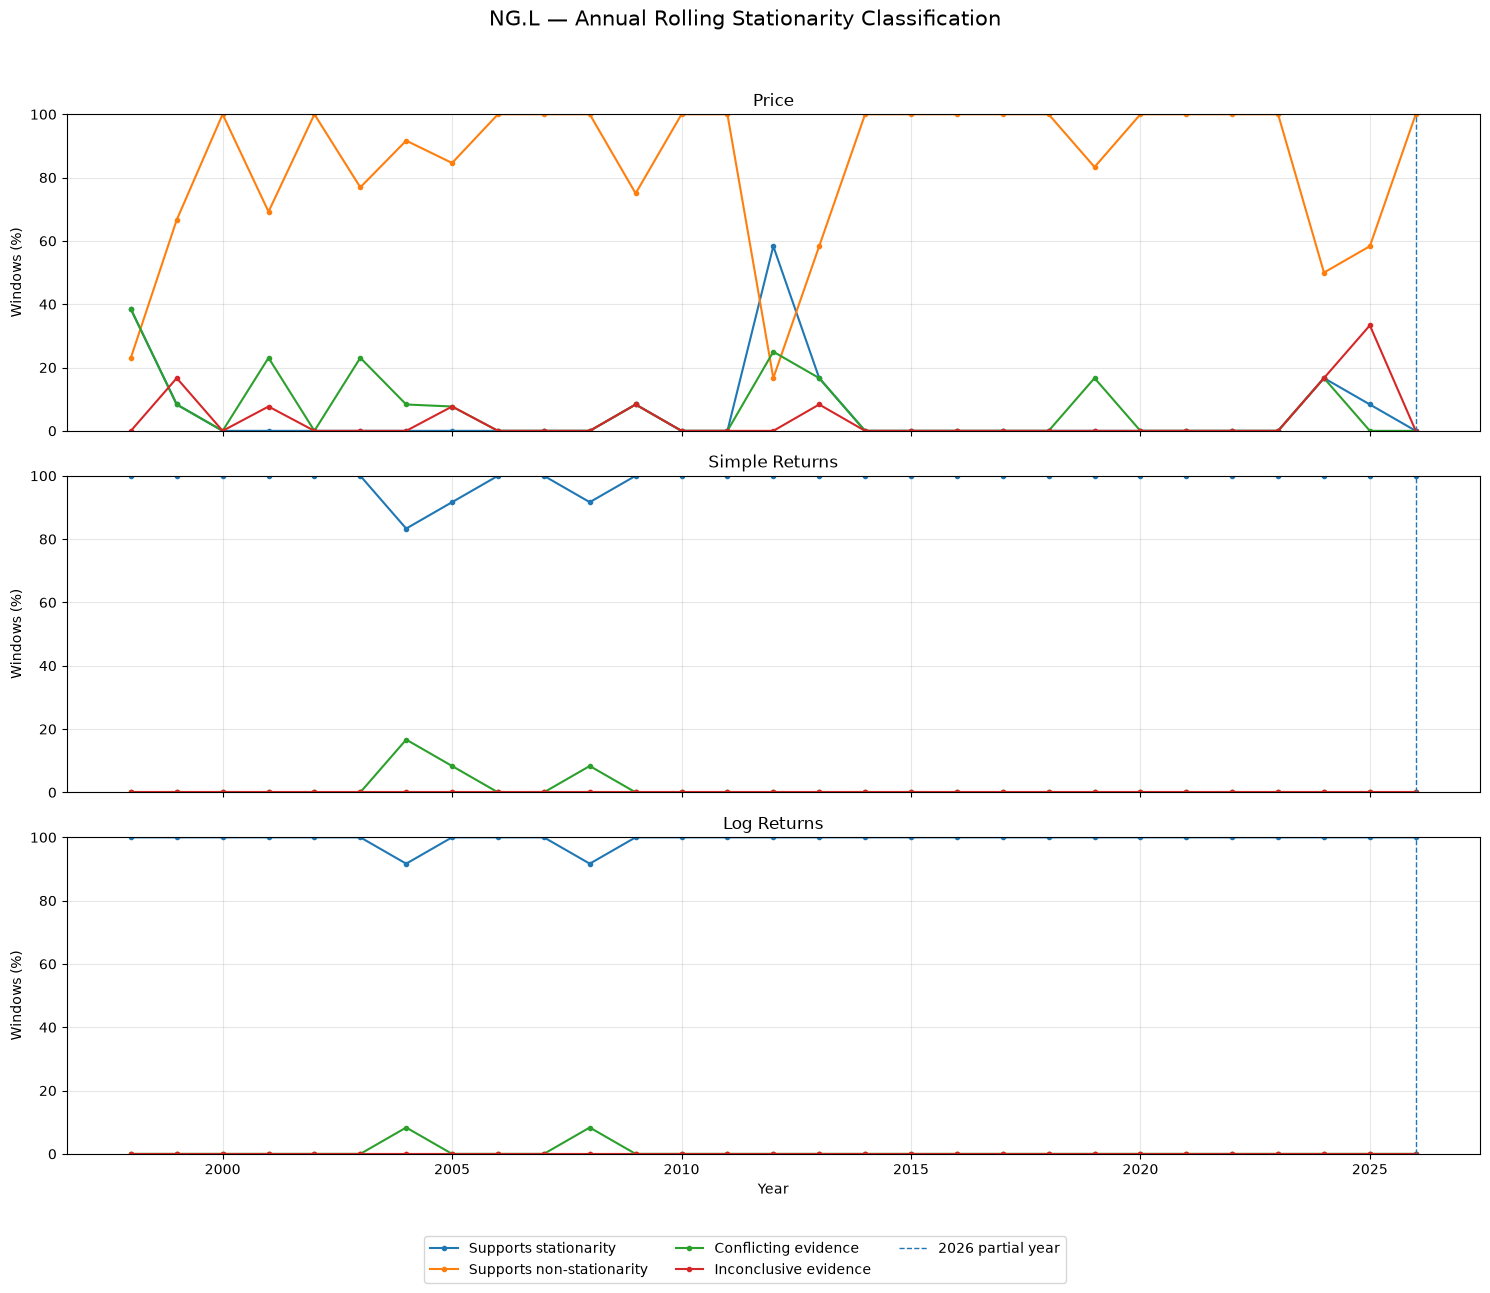

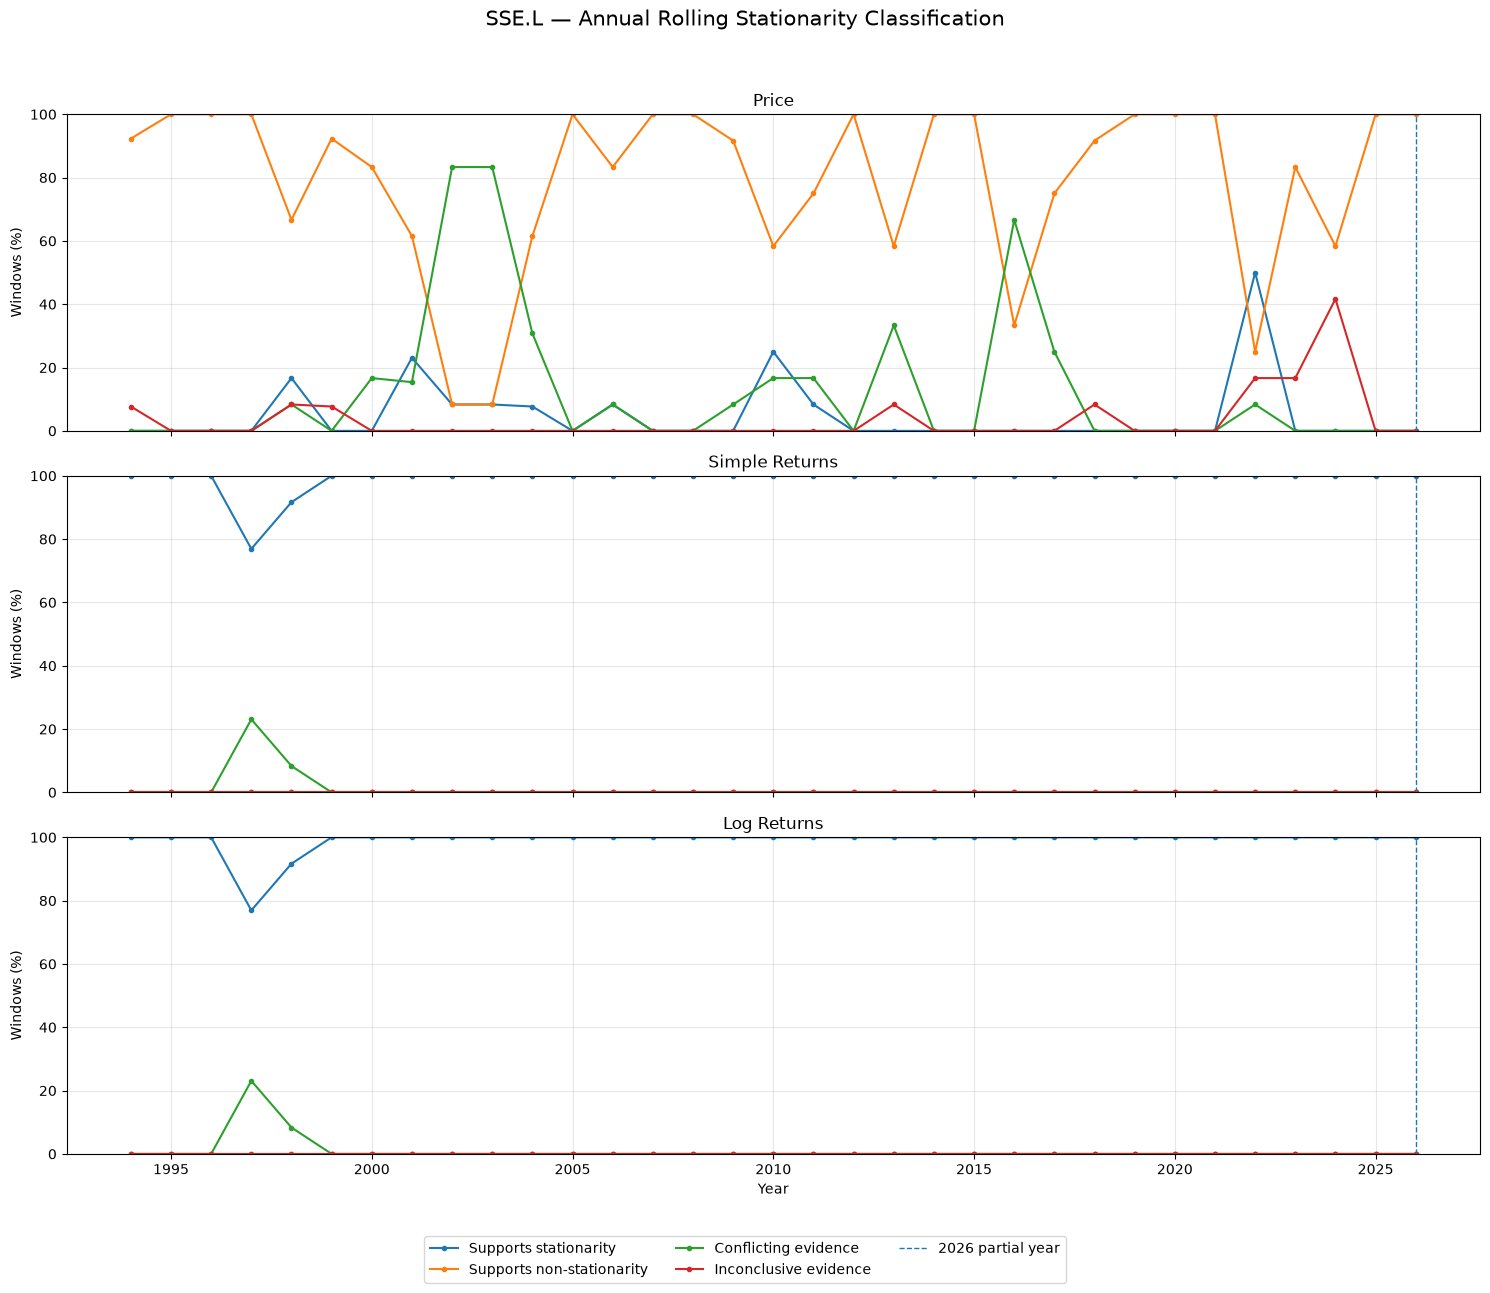

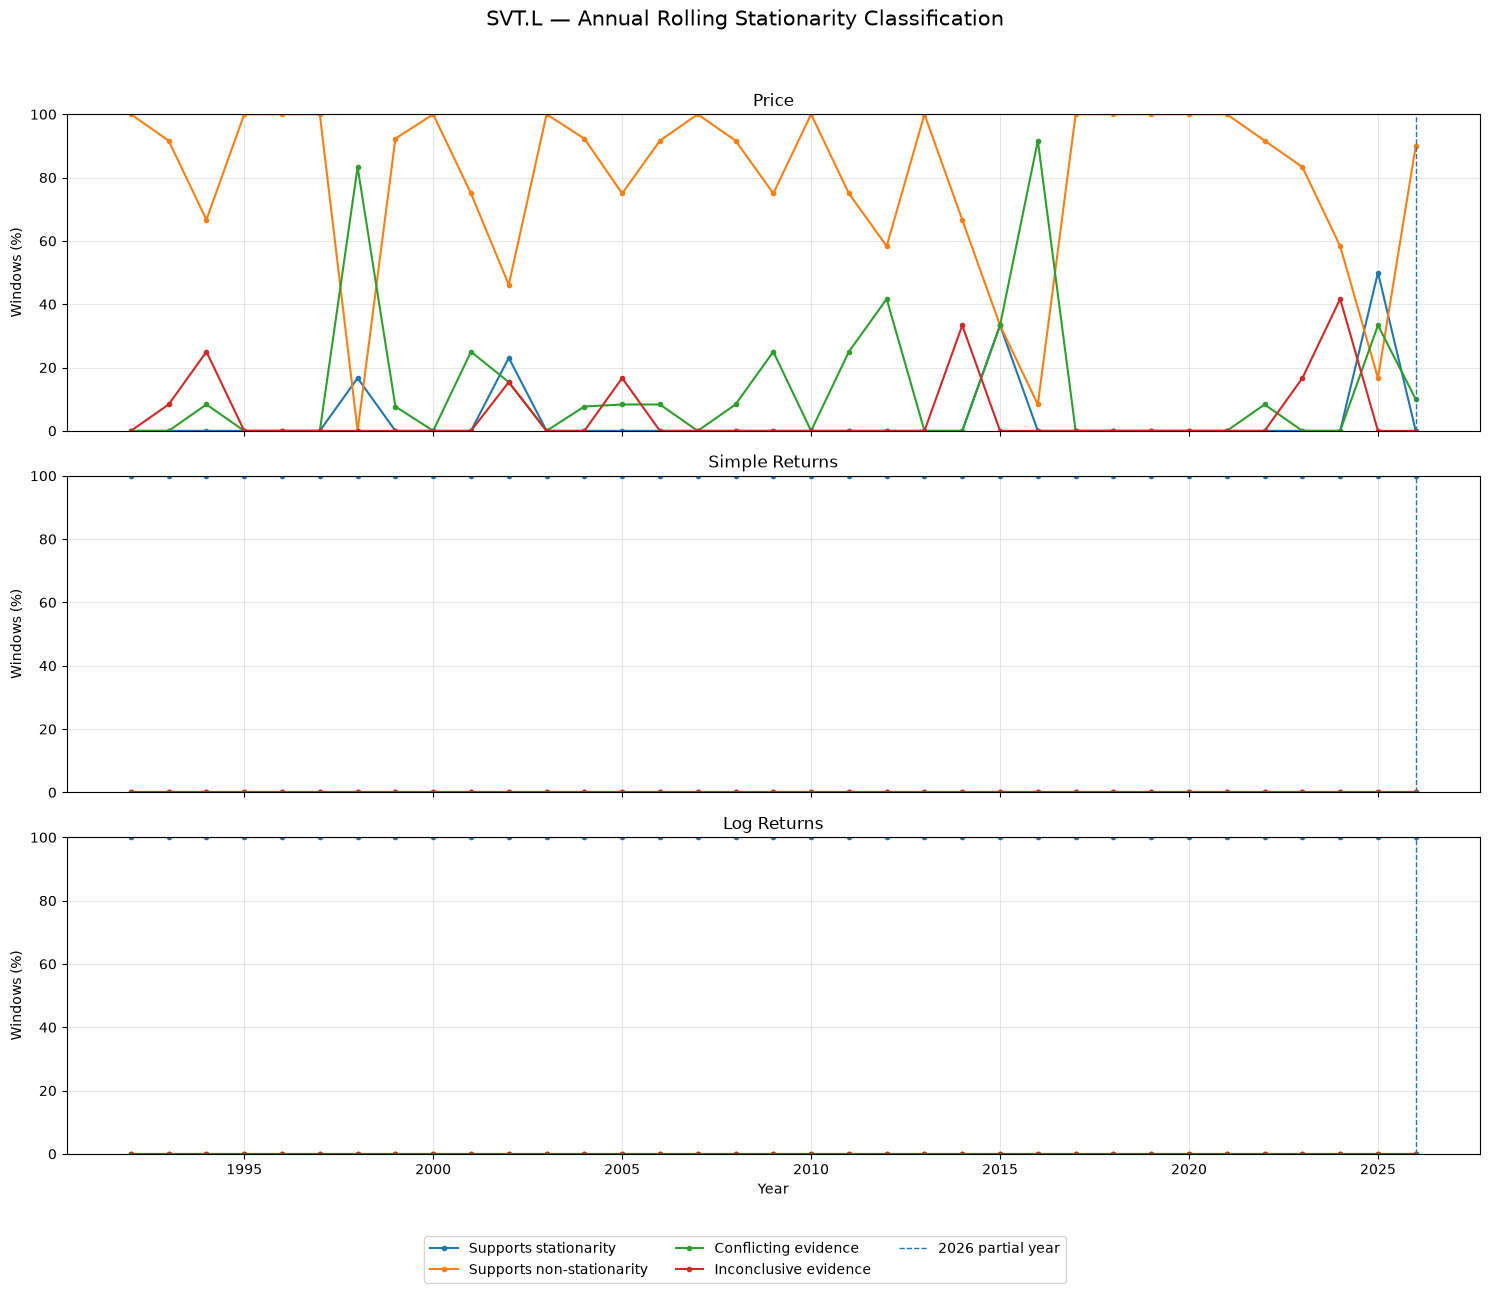

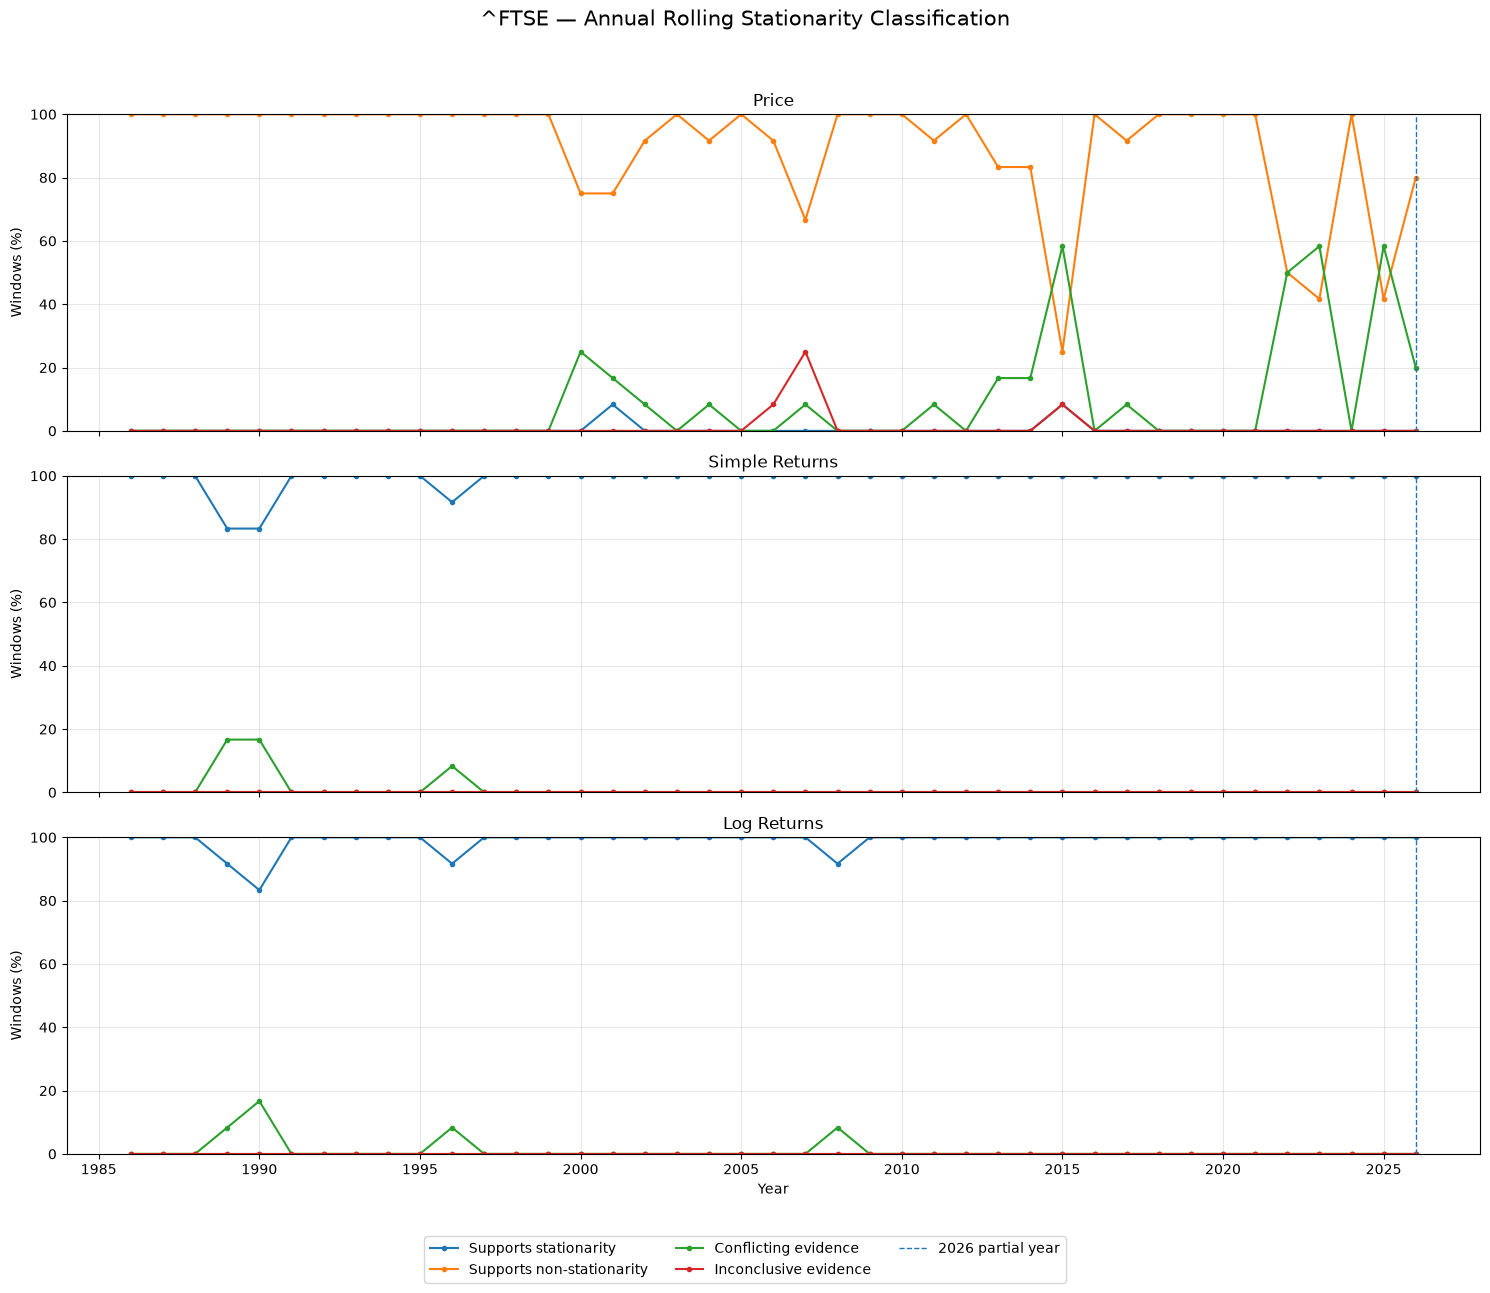

In [417]:
# Plot annual stationarity classification evolution

import matplotlib.pyplot as plt

classification_order = [
    "Supports stationarity",
    "Supports non-stationarity",
    "Conflicting evidence",
    "Inconclusive evidence",
]

series_order = [
    "price",
    "simple_returns",
    "log_returns",
]

assets = annual_classification_long["asset"].unique()

for asset in assets:

    fig, axes = plt.subplots(
        nrows=3,
        ncols=1,
        figsize=(15, 13),
        sharex=True,
    )

    asset_data = annual_classification_long.loc[
        annual_classification_long["asset"] == asset
    ]

    for ax, series_type in zip(axes, series_order):

        series_data = asset_data.loc[
            asset_data["series_type"] == series_type
        ]

        for classification in classification_order:

            plot_data = series_data.loc[
                series_data["joint_classification"] == classification
            ].sort_values("year")

            ax.plot(
                plot_data["year"],
                plot_data["percentage"],
                marker="o",
                markersize=3,
                linewidth=1.5,
                label=classification,
            )

        ax.axvline(
            x=2026,
            linestyle="--",
            linewidth=1,
            label="2026 partial year",
        )

        ax.set_title(series_type.replace("_", " ").title())
        ax.set_ylabel("Windows (%)")
        ax.set_ylim(0, 100)
        ax.grid(True, alpha=0.3)

    axes[-1].set_xlabel("Year")

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=3,
        bbox_to_anchor=(0.5, 0.01),
    )

    fig.suptitle(
        f"{asset} — Annual Rolling Stationarity Classification",
        fontsize=15,
        y=0.995,
    )

    plt.tight_layout(rect=[0, 0.07, 1, 0.97])
    plt.show()

In [418]:
# Quantitative summary of annual stationarity classifications

# Exclude incomplete calendar years from the historical summary
annual_complete_years = (
    annual_classification_long.loc[
        annual_classification_long["year_status"] == "Historical year"
    ].copy()
)

# Calculate descriptive statistics across complete calendar years
annual_classification_summary = (
    annual_complete_years
    .groupby(
        ["asset", "series_type", "joint_classification"]
    )["percentage"]
    .agg(
        mean_percentage="mean",
        median_percentage="median",
        std_percentage="std",
        minimum_percentage="min",
        maximum_percentage="max",
        number_of_years="count",
    )
    .reset_index()
)

# Round percentage statistics for presentation
percentage_columns = [
    "mean_percentage",
    "median_percentage",
    "std_percentage",
    "minimum_percentage",
    "maximum_percentage",
]

annual_classification_summary[percentage_columns] = (
    annual_classification_summary[percentage_columns].round(2)
)

print("Annual classification summary — complete calendar years")

display(
    annual_classification_summary.sort_values(
        ["asset", "series_type", "joint_classification"]
    ).reset_index(drop=True)
)

# Display 2026 separately
annual_2026_summary = (
    annual_classification_long.loc[
        annual_classification_long["year"] == 2026,
        [
            "asset",
            "series_type",
            "joint_classification",
            "percentage",
        ],
    ]
    .sort_values(["asset", "series_type", "joint_classification"])
    .reset_index(drop=True)
)

print("\n2026 classification results — partial calendar year")

display(annual_2026_summary)

Annual classification summary — complete calendar years


,asset,series_type,joint_classification,mean_percentage,median_percentage,std_percentage,minimum_percentage,maximum_percentage,number_of_years
0,NG.L,log_returns,Conflicting evidence,0.60000000,0.00000000,2.18000000,0.00000000,8.33000000,28
1,NG.L,log_returns,Inconclusive evidence,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,28
2,NG.L,log_returns,Supports non-stationarity,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,28
3,NG.L,log_returns,Supports stationarity,99.40000000,100.00000000,2.18000000,91.67000000,100.00000000,28
4,NG.L,price,Conflicting evidence,6.87000000,0.00000000,10.45000000,0.00000000,38.46000000,28
5,NG.L,price,Inconclusive evidence,3.53000000,0.00000000,7.64000000,0.00000000,33.33000000,28
6,NG.L,price,Supports non-stationarity,84.07000000,100.00000000,23.98000000,16.67000000,100.00000000,28
7,NG.L,price,Supports stationarity,5.54000000,0.00000000,13.31000000,0.00000000,58.33000000,28
8,NG.L,simple_returns,Conflicting evidence,1.19000000,0.00000000,3.74000000,0.00000000,16.67000000,28
9,NG.L,simple_returns,Inconclusive evidence,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,28



2026 classification results — partial calendar year


,asset,series_type,joint_classification,percentage
0,NG.L,log_returns,Conflicting evidence,0.00000000
1,NG.L,log_returns,Inconclusive evidence,0.00000000
2,NG.L,log_returns,Supports non-stationarity,0.00000000
3,NG.L,log_returns,Supports stationarity,100.00000000
4,NG.L,price,Conflicting evidence,0.00000000
5,NG.L,price,Inconclusive evidence,0.00000000
6,NG.L,price,Supports non-stationarity,100.00000000
7,NG.L,price,Supports stationarity,0.00000000
8,NG.L,simple_returns,Conflicting evidence,0.00000000
9,NG.L,simple_returns,Inconclusive evidence,0.00000000


### 11.6.7 Rolling Stationarity Analysis Findings

#### 1. Overview

The rolling stationarity analysis examined four financial assets: NG.L, SSE.L, SVT.L and the FTSE 100 index (^FTSE).

Three series types were assessed for each asset:

- Price levels.
- Simple returns.
- Log returns.

The analysis employed rolling windows of 504 valid observations, advanced in increments of 21 observations. Each window was evaluated using the Augmented Dickey-Fuller (ADF) and Kwiatkowski-Phillips-Schmidt-Shin (KPSS) tests.

The joint classification was based on the combined interpretation of both tests.

Annual classification percentages were calculated using the calendar year corresponding to each rolling window's end date. Years containing fewer than ten rolling windows were excluded from annual comparisons. The original rolling results were retained.

#### 2. Price Level Findings

Price levels predominantly exhibited evidence supporting non-stationarity across all four assets.

The average annual proportions of windows classified as supporting non-stationarity were:

| Asset | Mean Percentage |
|---|---:|
| NG.L | 84.07% |
| SSE.L | 78.36% |
| SVT.L | 79.09% |
| ^FTSE | 90.00% |

The FTSE exhibited the highest average proportion of non-stationarity classifications.

SSE.L and SVT.L displayed greater variability in their annual classification distributions, including relatively high proportions of conflicting evidence.

The standard deviations of the annual percentages classified as supporting non-stationarity were:

| Asset | Standard Deviation |
|---|---:|
| NG.L | 23.98 percentage points |
| SSE.L | 27.54 percentage points |
| SVT.L | 28.44 percentage points |
| ^FTSE | 19.08 percentage points |

These results indicate that the rolling test classifications varied over time, particularly for SSE.L and SVT.L.

#### 3. Simple Return Findings

Simple returns consistently exhibited evidence supporting stationarity.

| Asset | Mean Percentage Supporting Stationarity |
|---|---:|
| NG.L | 98.81% |
| SSE.L | 99.02% |
| SVT.L | 100.00% |
| ^FTSE | 98.96% |

The remaining classifications were conflicting evidence. No annual averages were recorded for classifications supporting non-stationarity or inconclusive evidence.

#### 4. Log Return Findings

Log returns exhibited a similarly consistent pattern.

| Asset | Mean Percentage Supporting Stationarity |
|---|---:|
| NG.L | 99.40% |
| SSE.L | 99.02% |
| SVT.L | 100.00% |
| ^FTSE | 98.96% |

SVT.L exhibited 100% support for stationarity across all eligible complete calendar years.

The results for the other assets were also highly consistent, with only small average proportions of conflicting evidence.

#### 5. Partial-Year Results: 2026

The 2026 observations were analysed separately because the calendar year was incomplete.

The observed classifications were:

| Asset | Price Levels | Simple Returns | Log Returns |
|---|---|---|---|
| NG.L | 100% supporting non-stationarity | 100% supporting stationarity | 100% supporting stationarity |
| SSE.L | 100% supporting non-stationarity | 100% supporting stationarity | 100% supporting stationarity |
| SVT.L | 90% supporting non-stationarity; 10% conflicting | 100% supporting stationarity | 100% supporting stationarity |
| ^FTSE | 80% supporting non-stationarity; 20% conflicting | 100% supporting stationarity | 100% supporting stationarity |

These results represent the available rolling windows ending during the partial 2026 observation period. They should not be interpreted as full-year estimates or directly compared with complete calendar years.

#### 6. Overall Findings

The rolling analysis provides consistent evidence of differences between price levels and return series.

The principal findings are:

1. Price levels predominantly exhibit evidence supporting non-stationarity across all four assets.
2. Simple returns consistently exhibit evidence supporting stationarity.
3. Log returns display a similar pattern to simple returns.
4. Price-level classifications exhibit greater temporal variability than return classifications.
5. SSE.L and SVT.L show greater variability in their annual price-level classification distributions than NG.L and the FTSE.
6. The FTSE exhibits the highest average proportion of rolling windows supporting non-stationarity in price levels.

These findings are consistent with the full-sample ADF and KPSS results, although rolling analysis provides additional information about the temporal variation of the test outcomes.

#### 7. Methodological Interpretation

The classifications represent the joint outcomes of two statistical tests under the selected specifications and significance level.

They must not be interpreted as probabilities that a series is stationary or non-stationary.

Furthermore, consecutive rolling windows overlap substantially. With a window size of 504 observations and a step size of 21 observations, approximately 95.8% of observations are shared between consecutive windows.

Consequently:

- Rolling classifications are not independent observations.
- Annual percentages are descriptive summaries rather than independent statistical estimates.
- Changes in classification do not independently establish structural breaks or changes in market regimes.
- Stationarity of returns does not establish independence, constant conditional variance, predictability or trading profitability.

#### 8. Conclusion

The rolling stationarity analysis reinforces the distinction between the statistical properties of price levels and returns.

Across the four assets, price levels predominantly exhibit evidence supporting non-stationarity, whereas simple and log returns predominantly exhibit evidence supporting stationarity.

The temporal analysis also reveals variation in the joint test classifications, particularly for price levels. These observations provide useful statistical context for subsequent financial time-series analysis.

However, no conclusions about predictive value, trading signals or investment performance can be drawn from stationarity tests alone.

### 11.6.8 Methodological Limitations

The rolling stationarity analysis is subject to the following limitations:

1. **Window dependence:** consecutive rolling windows overlap by approximately 95.8%, resulting in highly dependent test outcomes.

2. **Annual aggregation:** annual percentages summarise the distribution of rolling classifications. They should not be interpreted as independent observations or probabilities.

3. **Minimum annual sample threshold:** years containing fewer than ten rolling windows were excluded from annual comparisons. Their underlying rolling test results were retained.

4. **Incomplete calendar year:** 2026 represents a partial observation period and was therefore reported separately.

5. **Missing observations:** missing values were excluded without interpolation or imputation. Within each rolling series, retained observations were treated as consecutive valid observations.

6. **Test assumptions and limitations:** ADF and KPSS results depend on their deterministic specifications, lag selection and bandwidth selection. Their combined classifications do not eliminate the limitations of either test.

7. **Structural breaks:** the analysis does not formally identify structural breaks or establish changes in market regimes.

8. **Multiple testing:** a large number of rolling statistical tests were conducted without a formal multiple-testing adjustment. The resulting classification frequencies should therefore be interpreted descriptively.

9. **Volatility dynamics:** stationarity classifications do not establish constant variance or the absence of conditional heteroscedasticity.

10. **Predictive implications:** statistical stationarity does not imply return predictability or economic profitability.

These limitations must be considered when interpreting the results and designing subsequent modelling and validation procedures.

In [419]:
# Final consistency checks for rolling stationarity analysis

# 1. Verify complete-year coverage
expected_complete_years = {
    "NG.L": 28,
    "SSE.L": 32,
    "SVT.L": 34,
    "^FTSE": 40,
}

actual_complete_years = (
    annual_classification_summary
    .groupby("asset")["number_of_years"]
    .first()
    .to_dict()
)

assert actual_complete_years == expected_complete_years

print("Complete-year coverage: PASSED")

# 2. Verify 2026 partial-year coverage
assert annual_2026_summary["asset"].nunique() == 4
assert annual_2026_summary["series_type"].nunique() == 3
assert len(annual_2026_summary) == 48

classification_counts_2026 = (
    annual_2026_summary
    .groupby(["asset", "series_type"])
    .size()
)

assert (classification_counts_2026 == 4).all()

print("2026 partial-year coverage: PASSED")

# 3. Verify rolling analysis completeness
assert len(rolling_comparative_df) == 5023
assert rolling_comparative_df["joint_classification"].notna().all()

print("Rolling analysis completeness: PASSED")

# 4. Verify annual summary completeness
assert len(annual_classification_summary) == 48

print("Annual summary completeness: PASSED")

print("\nAll final consistency checks passed.")

Complete-year coverage: PASSED
2026 partial-year coverage: PASSED
Rolling analysis completeness: PASSED
Annual summary completeness: PASSED

All final consistency checks passed.


### 11.7 Stationarity Analysis Findings

#### 11.7.1 Integrated Findings Framework

This section consolidates the findings from the full-sample and rolling stationarity analyses.

The assessment covers four financial assets:

- National Grid (NG.L).
- SSE (SSE.L).
- Severn Trent (SVT.L).
- FTSE 100 Index (^FTSE).

Three series types were examined:

- Price levels.
- Simple returns.
- Log returns.

The findings integrate three complementary analytical approaches:

1. Full-sample Augmented Dickey-Fuller (ADF) tests.
2. Full-sample Kwiatkowski-Phillips-Schmidt-Shin (KPSS) tests.
3. Rolling ADF and KPSS tests, including their joint classifications and temporal evolution.

The purpose is to assess whether the statistical evidence is consistent across test methodologies, series types and historical periods.

The analysis distinguishes between:

- Evidence supporting stationarity.
- Evidence supporting non-stationarity.
- Conflicting statistical evidence.
- Inconclusive statistical evidence.

The conclusions are based exclusively on the statistical results obtained in the preceding sections. They do not establish return predictability, trading opportunities or investment profitability.

#### 11.7.2 Full-Sample ADF and KPSS Results Consolidation

The full-sample stationarity assessment combines the Augmented Dickey-Fuller (ADF) and Kwiatkowski-Phillips-Schmidt-Shin (KPSS) tests.

The ADF test evaluates the null hypothesis of a unit root, whereas the KPSS test evaluates the null hypothesis of stationarity. The two tests therefore provide complementary evidence.

The significance level is 5%.

| Asset | Series | ADF Statistic | ADF p-value | ADF Decision | KPSS Statistic | KPSS p-value | KPSS Decision | Joint Assessment |
|---|---|---:|---:|---|---:|---:|---|---|
| NG.L | Price | -3.988090 | 0.009142 | Reject H0 | 0.303536 | <0.01 | Reject H0 | Conflicting evidence |
| NG.L | Simple returns | -16.395385 | <0.001 | Reject H0 | 0.144238 | >0.10 | Fail to reject H0 | Supports stationarity |
| NG.L | Log returns | -16.430995 | <0.001 | Reject H0 | 0.062050 | >0.10 | Fail to reject H0 | Supports stationarity |
| SSE.L | Price | -2.693732 | 0.238694 | Fail to reject H0 | 0.704901 | <0.01 | Reject H0 | Supports non-stationarity |
| SSE.L | Simple returns | -28.628824 | <0.001 | Reject H0 | 0.065045 | >0.10 | Fail to reject H0 | Supports stationarity |
| SSE.L | Log returns | -28.439259 | <0.001 | Reject H0 | 0.066123 | >0.10 | Fail to reject H0 | Supports stationarity |
| SVT.L | Price | -2.961707 | 0.143103 | Fail to reject H0 | 1.266052 | <0.01 | Reject H0 | Supports non-stationarity |
| SVT.L | Simple returns | -24.043248 | <0.001 | Reject H0 | 0.084868 | >0.10 | Fail to reject H0 | Supports stationarity |
| SVT.L | Log returns | -23.963881 | <0.001 | Reject H0 | 0.077663 | >0.10 | Fail to reject H0 | Supports stationarity |
| ^FTSE | Price | -2.602756 | 0.278626 | Fail to reject H0 | 0.932485 | <0.01 | Reject H0 | Supports non-stationarity |
| ^FTSE | Simple returns | -40.444450 | <0.001 | Reject H0 | 0.156222 | >0.10 | Fail to reject H0 | Supports stationarity |
| ^FTSE | Log returns | -40.158405 | <0.001 | Reject H0 | 0.161579 | >0.10 | Fail to reject H0 | Supports stationarity |

**Interpretation**

The full-sample results show a consistent distinction between price levels and return series.

- **Price levels:** Three of the four assets provide evidence supporting non-stationarity. NG.L produces conflicting evidence because both tests reject their respective null hypotheses.
- **Simple returns:** All four assets provide evidence supporting stationarity under the joint ADF-KPSS assessment.
- **Log returns:** The same pattern is observed across all four assets, with evidence supporting stationarity.

The NG.L price-level result requires particular caution. The ADF test rejects the unit-root null hypothesis under the selected constant-and-trend specification, while KPSS rejects its trend-stationarity null hypothesis. This disagreement prevents a definitive classification.

**Statistical qualification**

The joint assessments represent evidence from two complementary statistical tests, not proof of stationarity or non-stationarity. In particular, failure to reject a null hypothesis does not establish that the null hypothesis is true.

The results also do not establish independence, constant variance, absence of nonlinear dependence or return predictability.

#### 11.7.3 Rolling Stationarity Findings

The rolling stationarity analysis evaluated the temporal consistency of the full-sample findings using 504-observation windows, advanced in steps of 21 observations.

A total of 5,023 rolling windows were assessed across four assets and three series types. Each window was classified through the joint interpretation of the ADF and KPSS tests.

**Overall classification**

| Joint Classification | Windows | Percentage |
|---|---:|---:|
| Supports stationarity | 3,373 | 67.2% |
| Supports non-stationarity | 1,402 | 27.9% |
| Conflicting evidence | 198 | 3.9% |
| Inconclusive evidence | 50 | 1.0% |
| **Total** | **5,023** | **100.0%** |

**Price-level findings**

| Asset | Supports Non-stationarity (%) | Conflicting Evidence (%) | Inconclusive Evidence (%) | Supports Stationarity (%) |
|---|---:|---:|---:|---:|
| NG.L | 84.38 | 6.82 | 3.41 | 5.40 |
| SSE.L | 79.17 | 12.75 | 3.43 | 4.66 |
| SVT.L | 79.63 | 12.41 | 4.45 | 3.51 |
| ^FTSE | 89.84 | 8.74 | 1.02 | 0.41 |

The rolling results predominantly support non-stationarity in price levels across all four assets. However, conflicting and inconclusive windows indicate that the statistical evidence is not uniform throughout the historical sample.

**Simple-return findings**

| Asset | Supports Stationarity (%) | Conflicting Evidence (%) |
|---|---:|---:|
| NG.L | 98.58 | 1.42 |
| SSE.L | 99.02 | 0.98 |
| SVT.L | 100.00 | 0.00 |
| ^FTSE | 98.97 | 1.03 |

**Log-return findings**

| Asset | Supports Stationarity (%) | Conflicting Evidence (%) |
|---|---:|---:|
| NG.L | 99.15 | 0.85 |
| SSE.L | 99.02 | 0.98 |
| SVT.L | 100.00 | 0.00 |
| ^FTSE | 98.97 | 1.03 |

The return series show a highly consistent pattern across rolling windows. Almost all windows support stationarity, with only a small proportion producing conflicting evidence.

**Temporal consistency**

The annual analysis provides additional descriptive evidence of how the joint classifications evolved over time.

Across complete years:

- Price levels predominantly supported non-stationarity, although the proportion varied across assets and years.
- Simple and log returns consistently showed a high proportion of windows supporting stationarity.
- SVT.L returns showed particularly consistent results, with 100% of eligible rolling windows supporting stationarity in the reported complete-year averages.
- The 2026 results are based on a partial year and should not be compared directly with complete calendar years.

**Comparison with full-sample results**

The rolling analysis broadly reinforces the full-sample findings:

1. Price levels generally exhibit evidence consistent with non-stationarity.
2. Simple and log returns consistently exhibit evidence supporting stationarity.
3. NG.L price levels remain an important case of mixed statistical evidence in the full-sample analysis, while its rolling results show predominantly non-stationary windows.
4. The rolling analysis reveals temporal variation that cannot be observed from a single full-sample test.

**Interpretive limitations**

The rolling results must be interpreted cautiously. Consecutive windows overlap by approximately 95.8%, making their test outcomes highly dependent. Therefore, the reported percentages describe the distribution of classifications across the selected windows; they are not probabilities that a series is stationary or non-stationary.

The results do not, by themselves, identify structural breaks, establish market regimes or demonstrate predictive value.

#### 11.7.4 Integrated Statistical Findings

The combined full-sample and rolling stationarity analyses provide a consistent overall picture of the statistical properties of the four financial time series examined.

The findings can be summarised across three dimensions.

**1. Price-level behaviour**

The full-sample tests support non-stationarity for SSE.L, SVT.L and the FTSE 100 Index. NG.L produces conflicting evidence, as the ADF and KPSS tests reject their respective null hypotheses.

The rolling analysis provides additional temporal evidence:

- All four assets exhibit a predominant proportion of rolling windows supporting non-stationarity in price levels.
- The FTSE 100 presents the highest proportion of windows supporting non-stationarity.
- NG.L, SSE.L and SVT.L also show periods of conflicting or inconclusive evidence.

These findings indicate that price-level stationarity classifications can vary across historical windows, even when the predominant pattern is non-stationarity.

**2. Return-series behaviour**

Both simple and logarithmic returns exhibit highly consistent results.

Across the full sample:

- All eight return series support stationarity under the joint ADF-KPSS assessment.

Across rolling windows:

- Approximately 98.6% to 100% of the windows for each return series support stationarity.
- Conflicting evidence accounts for only a small proportion of the windows.
- No rolling window was classified as supporting non-stationarity or as inconclusive for the return series.

This consistency is observed across the three individual equities and the FTSE 100 Index.

**3. Temporal variation**

The rolling analysis demonstrates that full-sample results can conceal variation across historical periods.

Price-level classifications vary over time, while return-series classifications remain considerably more consistent.

However, the analysis does not formally identify structural breaks or market regimes. The observed variation should therefore be interpreted as changes in statistical test outcomes rather than definitive evidence of regime transitions.

**Overall conclusion**

The evidence supports the following statistical characterisation of the analysed series:

| Series Type | Overall Finding | Evidence Consistency |
|---|---|---|
| Price levels | Predominantly non-stationary | Some variation and conflicting evidence |
| Simple returns | Supports stationarity | Highly consistent |
| Log returns | Supports stationarity | Highly consistent |

The results justify treating price levels and return series differently in subsequent statistical research.

In particular, return-based representations provide a more consistent stationarity profile than raw price levels in this dataset.

Nevertheless, stationarity must not be confused with predictability. These findings do not establish exploitable trading signals, stable expected returns, constant volatility or future investment performance.

The statistical properties of the series must be investigated further before selecting forecasting models or designing trading strategies.

#### 11.7.5 Limitations of the Integrated Findings

The findings presented in this section must be interpreted in light of the following methodological and statistical limitations.

**1. Dependence between rolling windows**

The rolling analysis uses 504-observation windows advanced in steps of 21 observations. Consecutive windows therefore share approximately 95.8% of their observations.

Their classifications are consequently highly dependent. The percentages reported in this section describe the distribution of test outcomes across the selected windows and must not be interpreted as probabilities or independent statistical evidence.

**2. Statistical test limitations**

ADF and KPSS tests evaluate different null hypotheses and are subject to their respective assumptions and limitations.

Their outcomes may be influenced by:

- Structural changes in the underlying data-generating process.
- Serial dependence.
- Changing volatility.
- The selected deterministic components and lag or bandwidth specifications.

The joint classification provides complementary statistical evidence but does not eliminate these limitations.

**3. Multiple testing**

A large number of statistical tests were conducted across assets, series types and rolling windows.

No formal multiple-testing correction was applied. Consequently, individual test rejections should not be interpreted without considering the number of tests performed.

**4. Missing observations**

Missing observations were excluded rather than interpolated or imputed.

Within each test, the retained observations were treated as consecutive. This means that gaps in the original time series may affect the interpretation of temporal dependence and test results.

**5. Annual aggregation**

Annual classifications were assigned according to the ending date of each rolling window. Individual windows may therefore span more than one calendar year.

Years with fewer than ten rolling windows were excluded from the annual comparisons, although their underlying rolling test results were retained.

**6. Partial-year observations**

The 2026 annual results cover only part of the calendar year and are not directly comparable with complete historical years.

**7. Stationarity does not imply predictability**

Stationarity does not establish that returns are independent, predictable or economically exploitable.

The present analysis does not assess forecasting performance, trading signals, transaction costs or investment profitability.

**8. Volatility dynamics**

ADF and KPSS tests do not provide a complete assessment of conditional heteroskedasticity or volatility clustering.

Dedicated volatility analysis is required before drawing conclusions about the conditional variance of the return series.

**9. Structural breaks and market regimes**

Although rolling classifications reveal temporal variation, no formal structural-break or regime-detection methodology was applied.

The results therefore do not establish the existence, timing or economic significance of market regimes.

**10. Scope of inference**

The conclusions apply to the selected assets, data sources, historical observations and test specifications used in this analysis.

They should not automatically be generalised to other securities, markets, frequencies or future periods.

#### 11.7.6 Conclusions

The full-sample and rolling stationarity analyses provide consistent evidence regarding the statistical behaviour of the four financial time series examined.

The principal findings are:

1. **Price levels:** The evidence predominantly supports non-stationarity across NG.L, SSE.L, SVT.L and the FTSE 100 Index. NG.L presents conflicting full-sample evidence, although its rolling results predominantly support non-stationarity.

2. **Simple returns:** All four assets support stationarity under the joint full-sample ADF-KPSS assessment. Rolling results reinforce this finding, with approximately 98.6% to 100% of windows supporting stationarity.

3. **Log returns:** The results are similarly consistent, with all four assets supporting stationarity in the full-sample assessment and approximately 99.0% to 100% of rolling windows supporting stationarity.

4. **Temporal variation:** Rolling analysis reveals variation in price-level classifications over time, while return-series classifications remain considerably more consistent.

These findings support the use of return-based representations in subsequent financial time-series research. However, they do not establish independence, constant conditional variance, predictability or trading profitability.

Further analysis is required to investigate volatility dynamics, serial dependence, potential structural breaks and the predictive properties of the series.

**Section status:** Completed, subject to final project review and approval.

#### 11.8 Statistical Interpretation

##### 11.8.1 Statistical Interpretation Framework

This section interprets the stationarity findings from a statistical and financial time-series perspective.

While the previous section consolidated the empirical results, the purpose here is to examine their implications for understanding the behaviour of financial price levels and return series.

The interpretation focuses on five dimensions:

1. **Price-level stationarity:** The implications of predominantly non-stationary price levels for the statistical representation of financial asset prices.

2. **Return-series stationarity:** The meaning and implications of the consistent stationarity evidence observed in simple and logarithmic returns.

3. **Full-sample versus rolling evidence:** The differences between conclusions derived from the entire historical sample and those obtained from rolling windows.

4. **Statistical properties and financial interpretation:** The distinction between stationarity, independence, volatility stability and predictability.

5. **Implications for subsequent quantitative research:** How the findings inform the preparation and analysis of financial time series in subsequent project stages.

The interpretation will remain within the scope of the statistical evidence obtained in this analysis.

Stationarity will not be treated as evidence of return predictability, investment opportunities or trading profitability.

#### 11.8.2 Interpretation of Price-Level Stationarity

The full-sample and rolling analyses indicate that the price levels of the four financial assets predominantly exhibit evidence consistent with non-stationarity.

**1. Statistical interpretation**

A stationary time series has statistical properties, such as its mean and variance, that remain stable over time, subject to the definition and assumptions of the stationarity concept being considered.

The evidence of non-stationarity in price levels suggests that the statistical behaviour of these series cannot be adequately characterised by assuming a stable mean and trend-stationary process throughout the entire historical sample.

This is consistent with the behaviour commonly observed in financial asset prices, which may evolve through persistent movements and changing levels over time.

However, the ADF and KPSS results do not, by themselves, establish the precise stochastic process governing each price series.

**2. Asset-specific interpretation**

The full-sample results show three distinct cases:

- **SSE.L:** Both tests provide evidence supporting non-stationarity. The ADF test fails to reject the unit-root null hypothesis, while the KPSS test rejects its trend-stationarity null hypothesis.
- **SVT.L:** The same pattern is observed, providing consistent evidence supporting non-stationarity.
- **FTSE 100 (^FTSE):** Both tests also support non-stationarity under the selected specifications.

NG.L presents a different result:

- The ADF test rejects the unit-root null hypothesis under the constant-and-linear-trend specification.
- The KPSS test rejects the trend-stationarity null hypothesis.

Because both null hypotheses are rejected, the evidence is conflicting. A definitive stationarity classification is therefore not justified.

**3. Implications of the rolling analysis**

The rolling results reinforce the predominant non-stationary classification of price levels:

| Asset | Rolling Windows Supporting Non-stationarity (%) |
|---|---:|
| NG.L | 84.38 |
| SSE.L | 79.17 |
| SVT.L | 79.63 |
| FTSE 100 (^FTSE) | 89.84 |

The remaining windows include conflicting evidence, inconclusive results and, in a smaller proportion, evidence supporting stationarity.

This variation indicates that the statistical classification of price levels is not uniform across historical periods.

The results do not establish the existence or timing of structural breaks or market regimes.

**4. Implications for quantitative research**

The predominantly non-stationary behaviour of price levels has practical implications for subsequent time-series analysis.

In particular:

- Statistical modelling should not automatically assume that raw price levels fluctuate around a constant historical mean.
- Transformations such as first differences and returns may provide more suitable representations for certain statistical analyses.
- The statistical properties of transformed series must still be evaluated rather than assumed.
- Model validation must account for the possibility that financial time-series behaviour changes over time.

The use of returns in subsequent modelling is supported by the findings of this investigation, but the suitability of any specific transformation will depend on the forecasting objective and model assumptions.

**Interpretive conclusion**

The evidence indicates that price levels predominantly exhibit non-stationary behaviour across the four analysed assets.

This finding supports the use of return-based representations in subsequent quantitative research, while highlighting the need to investigate the statistical properties of each transformed series independently.

Non-stationarity does not, by itself, imply that prices are unpredictable or that profitable trading opportunities cannot exist.

#### 11.8.3 Interpretation of Return-Series Stationarity

The full-sample and rolling analyses provide consistent evidence supporting stationarity in both simple and logarithmic return series across all four financial assets.

**1. Statistical interpretation**

Unlike price levels, return series are constructed to represent changes in asset values over time.

The full-sample ADF and KPSS tests jointly support stationarity for all eight return series examined:

- Four simple return series.
- Four logarithmic return series.

The rolling analysis reinforces this finding, with approximately 98.6% to 100% of windows supporting stationarity across the return series.

This consistency suggests that the selected return transformations produce series with more stable statistical properties than the corresponding price levels, within the scope of the tests applied.

However, these results do not establish strict stationarity or prove that all statistical moments remain constant over time.

**2. Simple returns versus logarithmic returns**

Simple returns are calculated as:

\[
R_t = \frac{P_t-P_{t-1}}{P_{t-1}}
\]

Logarithmic returns are calculated as:

\[
r_t = \ln(P_t)-\ln(P_{t-1})
\]

Both transformations produced highly consistent stationarity classifications in this investigation.

Their statistical relationship is:

\[
r_t = \ln(1+R_t)
\]

For relatively small returns, logarithmic and simple returns are numerically close. However, they are not identical, particularly for larger price movements.

The similarity of their stationarity results does not imply that they are interchangeable for every analytical or financial application.

**3. Asset-specific interpretation**

The rolling results show the following proportions of windows supporting stationarity:

| Asset | Simple Returns (%) | Log Returns (%) |
|---|---:|---:|
| NG.L | 98.58 | 99.15 |
| SSE.L | 99.02 | 99.02 |
| SVT.L | 100.00 | 100.00 |
| FTSE 100 (^FTSE) | 98.97 | 98.97 |

The results are highly consistent across the three individual equities and the market index.

SVT.L presents the strongest consistency, with all rolling windows supporting stationarity for both return definitions.

The small proportion of conflicting classifications observed in the other assets indicates that the statistical evidence is not completely uniform across all historical windows.

**4. Stationarity does not imply independence**

An important distinction is that stationarity does not require observations to be statistically independent.

A stationary return series may still exhibit:

- Serial correlation.
- Non-linear dependence.
- Volatility clustering.
- Conditional heteroskedasticity.
- Time-varying conditional distributions.

The ADF and KPSS tests applied in this investigation do not provide a comprehensive assessment of these properties.

Consequently, the stationarity findings should not be interpreted as evidence that financial returns behave like independent and identically distributed random variables.

**5. Implications for subsequent quantitative research**

The consistent stationarity evidence supports the use of simple and logarithmic returns as candidate representations for subsequent financial time-series analysis.

Nevertheless, the choice between these transformations should depend on the research objective, model assumptions and financial interpretation required.

Further analysis will be necessary to investigate serial dependence, volatility dynamics and distributional stability.

**Interpretive conclusion**

Both simple and logarithmic returns exhibit highly consistent evidence supporting stationarity across the four analysed assets.

This provides a sound statistical basis for investigating return-based financial time series in subsequent research.

However, stationarity alone does not establish return predictability, stable volatility, forecasting accuracy or economic value.

#### 11.8.4 Full-Sample versus Rolling Stationarity

The full-sample and rolling analyses provide complementary perspectives on the stationarity properties of financial time series.

The full-sample tests evaluate the statistical behaviour of each series across its entire available historical period. Rolling tests, in contrast, evaluate successive subsets of observations, allowing the consistency of statistical classifications to be examined over time.

**1. Differences in analytical scope**

Full-sample analysis provides an overall assessment of the historical series. However, a single test result may conceal variation in statistical behaviour across different periods.

Rolling analysis addresses this limitation by applying the same test framework to successive historical windows.

The two approaches therefore answer different questions:

- Full-sample analysis: What statistical evidence characterises the series across the entire sample?
- Rolling analysis: How consistent is that evidence across successive historical windows?

**2. Interpretation of the observed differences**

The full-sample analysis identifies predominantly non-stationary price levels, with NG.L presenting conflicting evidence.

The rolling analysis also identifies predominantly non-stationary price levels across all four assets, while revealing periods of conflicting, inconclusive or stationarity-supporting evidence.

For return series, both approaches produce highly consistent results supporting stationarity.

These findings suggest that the broad distinction between price levels and returns is not dependent exclusively on the full-sample assessment.

However, the differences between individual classifications demonstrate why a single full-sample result should not be treated as a complete description of historical statistical behaviour.

**3. Importance of rolling-window dependence**

The rolling analysis uses 504 observations per window and advances by 21 observations.

Consequently, consecutive windows overlap by approximately 95.8%.

This substantial overlap means that neighbouring test outcomes are highly dependent.

The percentage of windows supporting a particular classification must therefore be interpreted as a descriptive measure of classification consistency across the selected windows, not as an independent statistical frequency or probability.

**4. Interpretation of annual aggregation**

Annual aggregation provides a more accessible representation of the temporal evolution of rolling classifications.

However, each window is assigned to the calendar year of its ending date, even when the window contains observations from previous years.

Furthermore, annual percentages are calculated from dependent rolling windows and should not be interpreted as independent annual estimates.

The 2026 results represent a partial year and are not directly comparable with complete calendar years.

**5. Implications for quantitative research**

The combination of full-sample and rolling analysis provides a more informative assessment than either approach alone.

Full-sample tests offer a broad historical perspective, while rolling tests reveal whether the observed statistical classifications remain consistent across different periods.

For subsequent research, this distinction is important because model assumptions should not be considered permanently valid merely because they are supported by a full-sample test.

Temporal validation and monitoring will be necessary when evaluating forecasting models and their stability.

**Interpretive conclusion**

The full-sample and rolling analyses broadly reinforce one another.

Both support the distinction between predominantly non-stationary price levels and return series that exhibit highly consistent evidence supporting stationarity.

The rolling analysis adds an important temporal dimension, revealing variations that are concealed by full-sample aggregation.

Nevertheless, overlapping windows and the absence of formal structural-break testing prevent these results from establishing independent regime changes or definitive changes in the underlying data-generating process.

#### 11.8.5 Stationarity, Dependence, Volatility and Predictability

An important distinction in financial time-series analysis is that stationarity, independence, volatility stability and predictability describe different statistical properties.

The stationarity results obtained in this investigation do not establish the other properties.

**1. Stationarity**

Stationarity describes the stability of the statistical properties of a time series over time.

The ADF and KPSS tests applied in this investigation provide evidence concerning unit-root behaviour and stationarity under their respective specifications.

However, these tests do not establish strict stationarity or guarantee that all statistical characteristics remain unchanged.

**2. Statistical dependence**

A stationary time series can exhibit dependence between observations.

For example, returns may display autocorrelation or other forms of linear and non-linear temporal dependence.

The ADF and KPSS tests do not provide a comprehensive assessment of these relationships.

Dedicated autocorrelation and dependence analyses will therefore be necessary.

**3. Volatility stability**

Stationarity evidence does not imply constant conditional variance.

Financial returns may exhibit volatility clustering, where periods of relatively high volatility alternate with periods of lower volatility.

Conditional heteroskedasticity may also be present even when return series exhibit evidence supporting stationarity.

Further investigation using volatility-specific statistical methods will be required.

**4. Predictability**

Predictability concerns whether information available at a given point in time can provide useful information about future observations or returns.

A stationary return series is not necessarily predictable.

Conversely, evidence of non-stationarity in price levels does not automatically imply that forecasting is impossible.

Predictive value must be evaluated empirically through appropriate chronological validation, comparison with simple baselines and genuinely out-of-sample testing.

**5. Economic and trading significance**

Even when a forecasting model identifies statistically meaningful patterns, these patterns do not automatically represent economically exploitable opportunities.

Trading performance must be assessed separately, accounting for:

- Transaction costs.
- Bid-ask spreads.
- Slippage.
- Execution delays.
- Liquidity constraints.
- Portfolio and risk-management rules.

Statistical significance, predictive performance and economic value must therefore remain separate evaluation dimensions.

**Summary**

| Property | Meaning | Established by Current Analysis? |
|---|---|---|
| Unit-root behaviour | Evidence concerning the presence of a unit root | Investigated through ADF |
| Stationarity | Evidence concerning stationarity under the selected test specifications | Investigated through ADF and KPSS |
| Independence | Absence of statistical dependence between observations | No |
| Constant conditional variance | Stability of conditional volatility | No |
| Return predictability | Ability to forecast future returns using available information | No |
| Trading profitability | Positive economic performance after realistic costs and risks | No |

**Interpretive conclusion**

The stationarity findings provide useful information about the statistical representation of the analysed financial series.

However, they represent only one component of financial time-series characterisation.

Subsequent research must investigate dependence, volatility dynamics, predictive performance and economic significance independently.

#### 11.8.6 Implications for Subsequent Quantitative Research

The stationarity findings provide important methodological guidance for the subsequent stages of the quantitative research system.

The evidence supports the use of return-based representations for further financial time-series investigation, while highlighting the need to evaluate additional statistical properties before selecting forecasting models.

**1. Financial data representation**

The predominantly non-stationary behaviour of price levels suggests that raw prices should not automatically be treated as stationary inputs.

Simple and logarithmic returns provide more consistent stationarity evidence across the analysed assets.

These transformations should therefore remain candidate representations for subsequent statistical modelling.

The final choice must depend on the forecasting target, model assumptions and economic interpretation.

**2. Forecasting target definition**

The findings are consistent with investigating forward returns rather than relying exclusively on future price levels as forecasting targets.

Potential forecasting objectives include:

- Forward simple returns.
- Forward logarithmic returns.
- Future return direction.
- Future volatility.
- Conditional return distributions.

Each target will require an independently defined methodology, appropriate forecasting horizon and protection against look-ahead bias.

**3. Further statistical investigation**

Stationarity is only one component of financial time-series characterisation.

Before developing more complex forecasting models, subsequent research should investigate:

- Linear serial dependence through autocorrelation analysis.
- Non-linear dependence where economically justified.
- Volatility clustering and conditional heteroskedasticity.
- Distributional characteristics and tail behaviour.
- Potential structural breaks and temporal instability.

The selection of additional methods should be supported by explicit research hypotheses.

**4. Model development implications**

The findings support a modelling approach that distinguishes between data representation, forecasting targets and model assumptions.

Subsequent model development should:

- Establish simple statistical baselines before introducing complex machine-learning methods.
- Use chronological training, validation and testing periods.
- Prevent information leakage during feature and target construction.
- Evaluate performance across different historical periods.
- Compare model performance against appropriate benchmarks.
- Assess predictive uncertainty and calibration where relevant.

Stationarity findings must not be used as a substitute for out-of-sample model validation.

**5. Multi-asset architecture**

The analysis covered NG.L, SSE.L, SVT.L and the FTSE 100 Index.

Although the broad stationarity patterns were similar, asset-specific differences were observed, particularly in price-level classifications.

The system should therefore preserve asset-level statistical diagnostics rather than assume that all instruments share identical statistical properties.

This supports the project's multi-asset architecture without hard-coding assumptions derived from National Grid alone.

**6. Research and trading separation**

The results belong to the statistical research layer of the system.

They do not constitute trading signals, entry or exit rules, position-sizing decisions or portfolio recommendations.

Forecasting models, trading strategies, risk management and portfolio accounting must remain independently testable components.

Any future strategy evaluation must incorporate realistic transaction costs, execution assumptions and appropriate risk controls.

**Overall implication**

The stationarity investigation supports the use of return-based financial time series as candidates for subsequent forecasting research.

However, model selection and development must be based on additional statistical evidence, explicit forecasting objectives and rigorous out-of-sample validation.

No forecasting or trading capability can be inferred from stationarity results alone.

#### 11.8.7 Statistical Interpretation Summary

The statistical interpretation of the stationarity analysis provides several important findings regarding the behaviour of the four financial time series examined.

**1. Price levels**

The analysed price series predominantly exhibit evidence consistent with non-stationarity.

This behaviour indicates that raw price levels should not automatically be treated as stationary inputs in subsequent statistical modelling.

NG.L presents conflicting full-sample evidence, highlighting the importance of considering alternative test specifications and temporal behaviour.

**2. Return series**

Both simple and logarithmic returns exhibit highly consistent evidence supporting stationarity across the four assets.

The agreement between full-sample and rolling analyses reinforces the suitability of return-based representations as candidates for subsequent financial time-series research.

**3. Temporal consistency**

The rolling analysis reveals that statistical classifications may vary across historical periods, particularly for price levels.

Return series display considerably greater consistency across the selected rolling windows.

However, the substantial overlap between windows limits the interpretation of these results as independent evidence.

**4. Distinction between statistical properties**

The stationarity findings do not establish:

- Independence between observations.
- Constant conditional variance.
- Absence of non-linear dependence.
- Return predictability.
- Forecasting performance.
- Economic or trading profitability.

These properties require separate investigation.

**5. Implications for the quantitative research system**

The results support the continued investigation of return-based representations and forward-return forecasting targets.

Subsequent research must independently evaluate serial dependence, volatility dynamics, distributional behaviour and temporal stability.

Model development must rely on chronological validation, appropriate baselines, leakage prevention and genuinely out-of-sample evaluation.

**Final interpretation**

The stationarity analysis provides a useful statistical foundation for the next stages of the quantitative research project.

The evidence distinguishes predominantly non-stationary price levels from return series that exhibit highly consistent evidence supporting stationarity.

These findings inform subsequent research decisions but do not establish predictive or trading capability.

Further empirical investigation is required before any forecasting model or trading strategy can be considered validated.

#### 11.9 Limitations

##### 11.9.1 Limitations Assessment Framework

This section documents the methodological, statistical and data-related limitations affecting the stationarity analysis conducted in this notebook.

Although the preceding sections provide evidence concerning the stationarity properties of the analysed financial time series, their findings must be interpreted within the limitations of the available data, statistical methodologies and analytical assumptions.

The assessment is organised into six dimensions:

1. **Data limitations:** Historical coverage, missing observations, data quality and potential inconsistencies in the underlying market data.

2. **Statistical test limitations:** The assumptions, specifications and interpretation constraints associated with the ADF and KPSS tests.

3. **Rolling analysis limitations:** Window selection, overlapping observations, temporal aggregation and dependence between successive test outcomes.

4. **Inference limitations:** The distinction between statistical evidence, stationarity, independence, volatility stability and predictability.

5. **Scope and generalisation limitations:** The extent to which the findings can be generalised across assets, markets and historical periods.

6. **Implications for subsequent research:** The additional investigation required before using these findings to support forecasting model development.

The purpose of this assessment is not to invalidate the preceding results, but to establish the boundaries within which they can be interpreted reliably.

No forecasting capability, trading signal or investment profitability is inferred from the stationarity analysis.

#### 11.9.2 Financial Data Limitations

The stationarity analysis relies on historical financial market data whose characteristics and limitations may influence the interpretation of the statistical results.

The following data-related limitations must be considered.

**1. Historical coverage and unequal sample lengths**

The analysed assets have different historical coverage and numbers of valid observations.

This results from differences in available historical data and missing observations.

Consequently:

- Full-sample tests do not cover identical calendar periods across all assets.
- Rolling analyses contain different numbers of windows for each asset.
- Cross-asset comparisons must account for differences in historical coverage.

The results should therefore not be interpreted as if all assets had been assessed over identical historical conditions.

**2. Missing observations and market calendars**

Missing observations were excluded rather than interpolated or forward-filled.

Although this avoids introducing artificial price values, it creates an important methodological consideration.

After applying `dropna()`, observations separated by missing dates are treated as consecutive observations by the statistical tests.

Therefore, the resulting test sequences do not necessarily represent equally spaced trading sessions in the original calendar.

This limitation may affect the interpretation of temporal dependence and lag structures.

**3. Corporate actions and adjusted prices**

The analysis uses adjusted closing prices (`Adj Close`) as its price representation.

However, the precise treatment of historical corporate actions, including dividends and other adjustments, has not been independently validated for every observation.

Consequently, the analysis does not establish that all historical price adjustments are economically and temporally consistent.

This is particularly relevant when interpreting long-term return series.

**4. Historical data anomalies**

The preceding data-quality assessment identified historical OHLC anomalies and some zero-volume observations.

These observations were not automatically deleted or corrected.

The stationarity analysis therefore retains the underlying historical data as prepared, without assuming that every observation is free from potential data-quality issues.

No additional data corrections were authorised as part of this analysis.

**5. Asset-specific measurement characteristics**

The analysed instruments have different market characteristics.

NG.L, SSE.L and SVT.L are individual equities quoted in GBp, whereas the FTSE 100 is an index expressed in index points.

Although percentage and logarithmic returns are dimensionless transformations, differences in instrument characteristics, trading behaviour and market structure remain relevant when comparing statistical results.

**6. Observation dates and information availability**

The historical observation date does not necessarily represent the date on which information became publicly available.

This distinction is particularly important for any future integration of macroeconomic or fundamental variables.

The current stationarity analysis does not establish point-in-time availability for all potential explanatory variables.

Any subsequent predictive research must independently validate publication timestamps, information availability and historical data revisions.

**Overall assessment**

The historical market data provide a basis for the stationarity investigation, but their limitations must remain visible when interpreting the results.

Differences in sample coverage, missing observations, historical adjustments and potential data anomalies may influence the statistical evidence.

These limitations do not automatically invalidate the findings, but they restrict the strength and generalisation of the conclusions.

#### 11.9.3 ADF and KPSS Test Limitations

The stationarity assessment relies on two complementary statistical tests: the Augmented Dickey-Fuller (ADF) test and the Kwiatkowski-Phillips-Schmidt-Shin (KPSS) test.

Although their combination provides a broader assessment than either test individually, both methodologies have limitations that must be considered.

**1. Dependence on test specifications**

ADF and KPSS results depend on the deterministic components and other specifications selected for each test.

In this investigation:

- Price levels were tested using a constant and linear trend (`ct`).
- Return series were tested using a constant (`c`).
- ADF lag selection used the Akaike Information Criterion (AIC).
- KPSS bandwidth selection used the automatic procedure.

Alternative specifications may produce different statistical outcomes.

The selected specifications provide a consistent framework for this investigation, but they do not guarantee that every relevant feature of the underlying data-generating process has been captured.

**2. ADF test limitations**

The ADF test evaluates the null hypothesis that a series contains a unit root.

Its results may be affected by:

- Incorrect specification of deterministic components.
- Lag-selection choices.
- Structural changes in the underlying process.
- Low statistical power against certain stationary alternatives.
- Changes in volatility and other distributional characteristics.

Failure to reject the unit-root null hypothesis does not prove that a series contains a unit root.

Similarly, rejecting the null hypothesis does not establish that the series satisfies every requirement of stationarity.

**3. KPSS test limitations**

The KPSS test evaluates the null hypothesis of stationarity, either around a constant or around a deterministic trend, depending on the selected specification.

Its results may be affected by:

- Bandwidth selection.
- Serial correlation.
- Structural changes.
- Changes in the underlying statistical process.
- The sensitivity of the test to deviations from its stationarity null hypothesis.

Failure to reject the KPSS null hypothesis does not prove that a series is stationary.

**4. Interpretation of p-values**

The ADF and KPSS tests require careful interpretation of their reported p-values.

For the ADF test, several p-values were extremely small and fell below the numerical precision used for presentation. These values should therefore be reported as `<0.001`, rather than interpreted as mathematically equal to zero.

For the KPSS test, interpolation warnings indicated that some p-values were outside the available lookup-table ranges. These results were therefore reported using boundary expressions such as `<0.01` and `>0.10`, rather than interpreted as exact probabilities.

The reported statistical decisions should be interpreted according to the 5% significance threshold and the numerical limitations of each test.

**5. Conflicting test outcomes**

The tests occasionally produce conflicting evidence because they evaluate different null hypotheses.

The NG.L full-sample price-level results provide an example: both the ADF and KPSS tests reject their respective null hypotheses.

Such outcomes should not be forced into a definitive stationary or non-stationary classification.

The joint assessment used in this investigation preserves conflicting and inconclusive outcomes rather than concealing them.

**6. Structural changes and statistical power**

Both tests may be affected by structural changes in the underlying time series.

A series that experiences changes in its mean, trend or other characteristics may produce test results that are difficult to interpret using conventional specifications.

No formal structural-break-adjusted ADF or KPSS methodology was applied in this investigation.

**7. Multiple testing**

The investigation applied statistical tests across multiple assets, series types and rolling windows.

No formal multiple-testing correction was applied.

Consequently, the individual rejection decisions and the aggregate distribution of classifications should be interpreted descriptively rather than as a collection of independent statistical discoveries.

**Overall assessment**

The combination of ADF and KPSS provides complementary evidence concerning stationarity, but it does not eliminate the limitations inherent in unit-root and stationarity testing.

The findings should therefore be interpreted in conjunction with the data-quality assessment, rolling analysis and other statistical diagnostics.

No single test result should be treated as definitive proof of the underlying stochastic properties of a financial time series.

## 11.9.4 Rolling Analysis Limitations

The rolling stationarity analysis provides additional information about the temporal consistency of the statistical classifications. However, its methodology introduces specific limitations that must be considered.

**1. Rolling window selection**

The analysis uses a primary rolling window of 504 valid observations, advanced in steps of 21 observations.

The selected window approximately represents two years of trading observations, while the step size represents approximately one trading month.

These choices provide a consistent framework for examining temporal variation, but they are not uniquely optimal.

Different window lengths and step sizes could produce different classifications.

Shorter windows may be more sensitive to local changes but may also provide less statistical power.

Longer windows may provide more observations for each test but may conceal shorter-term changes in statistical behaviour.

The results should therefore be interpreted as conditional on the selected rolling-window configuration.

**2. Overlapping windows and dependence**

Consecutive windows overlap by approximately 95.8% of their observations.

This substantial overlap creates strong dependence between neighbouring test outcomes.

Consequently:

- Rolling classifications are not independent observations.
- Classification percentages do not represent probabilities.
- The total number of windows does not represent an equivalent number of independent statistical experiments.
- Changes between neighbouring classifications should not automatically be interpreted as meaningful changes in the underlying process.

The rolling results are therefore descriptive indicators of classification consistency rather than independent statistical evidence.

**3. Full-window requirement**

Only complete windows containing 504 valid observations were included.

This avoids comparisons between windows with different observation counts.

However, it also means that the beginning of each historical series cannot be evaluated until a complete window is available.

The rolling analysis therefore does not cover the entire historical period for every asset.

**4. Missing observations and temporal spacing**

Missing observations were excluded without interpolation or imputation.

As a result, rolling windows were constructed using successive valid observations rather than necessarily consecutive calendar trading sessions.

This may affect the interpretation of the temporal distance represented by each window, particularly when missing observations are concentrated in specific periods.

**5. Annual aggregation**

Annual classifications were assigned according to the ending date of each rolling window.

Individual windows may therefore include observations from more than one calendar year.

Additionally, years containing fewer than ten rolling windows were excluded from annual comparisons.

This threshold improves the minimum descriptive coverage of the annual summaries, but it does not establish statistical independence or guarantee representative annual estimates.

**6. Partial-year observations**

The 2026 results represent a partial calendar year.

They should not be interpreted as directly comparable with complete historical years.

The partial-year classifications are retained as descriptive information rather than evidence of a complete annual pattern.

**7. No formal structural-break identification**

The rolling analysis identifies variation in statistical test classifications over time.

However, no dedicated structural-break methodology was applied.

Consequently, the analysis does not identify the precise timing, statistical significance or economic interpretation of potential structural changes.

Changes in rolling classifications should not automatically be interpreted as market regime transitions.

**Overall assessment**

Rolling stationarity analysis adds a valuable temporal dimension to the full-sample results.

Nevertheless, its conclusions depend on the selected window configuration, the treatment of missing observations and the substantial dependence between overlapping windows.

The rolling results should therefore be used as descriptive evidence of temporal classification consistency rather than as definitive evidence of structural breaks or market regimes.

## 11.9.5 Statistical Inference Limitations

The stationarity findings provide evidence about specific statistical properties of the analysed time series.

However, several important financial time-series characteristics remain outside the scope of the tests applied.

**1. Stationarity versus strict stationarity**

The ADF and KPSS tests assess specific forms of stationarity associated with unit-root behaviour and deterministic components.

They do not establish strict stationarity, which requires the joint distributions of observations to remain invariant under time shifts.

The conclusions should therefore be understood within the scope of the stationarity concepts evaluated by the selected tests.

**2. Stationarity versus independence**

Stationarity does not imply independence between observations.

A stationary return series may exhibit linear or non-linear temporal dependence.

The present investigation does not establish that the analysed return series are independent or independently and identically distributed.

**3. Stationarity versus constant volatility**

The ADF and KPSS tests do not provide a comprehensive assessment of conditional variance.

Financial returns may exhibit volatility clustering and conditional heteroskedasticity even when they provide evidence supporting stationarity.

The results therefore do not establish constant volatility.

**4. Stationarity versus distributional stability**

The stationarity analysis does not establish that all distributional characteristics remain constant over time.

Although the preceding distribution analysis identified skewness and excess kurtosis, the current tests do not determine whether these characteristics remain stable throughout the historical sample.

Additional distributional and temporal stability analyses would be required.

**5. Stationarity versus predictability**

A stationary return series is not necessarily predictable.

Likewise, non-stationarity in price levels does not automatically imply that forecasting is impossible.

Predictability must be evaluated through forecasting experiments using information available at the relevant prediction time.

**6. Statistical significance versus economic significance**

Statistical test results do not establish economic value.

Even when a statistical relationship is identified, its practical usefulness depends on forecasting accuracy, robustness and realistic implementation assumptions.

No trading strategy or investment performance was evaluated in the stationarity analysis.

**Overall assessment**

The results provide evidence concerning stationarity under the selected statistical methodologies.

They do not establish independence, constant conditional variance, distributional stability, return predictability or economic profitability.

These properties require separate investigation and validation.

## 11.9.6 Generalisation and Research Scope

The findings of this investigation are conditional on the selected assets, historical data, observation frequency and statistical methodologies.

Their generalisation to other instruments, markets or historical periods is therefore limited.

**1. Asset selection**

The analysis covers four instruments:

- National Grid (NG.L).
- SSE (SSE.L).
- Severn Trent (SVT.L).
- FTSE 100 Index (^FTSE).

Although the selected instruments provide exposure to different aspects of the UK equity market, they do not represent the full diversity of financial instruments or market sectors.

The results should not automatically be generalised to other equities, bonds, commodities, currencies or alternative assets.

**2. Market and geographic scope**

The investigation focuses on selected UK-listed equities and a UK equity market index.

Market structure, trading practices, liquidity, regulation and investor behaviour may differ across countries and exchanges.

The observed statistical patterns may therefore not apply to other financial markets.

**3. Observation frequency**

The analysis uses daily financial observations.

Stationarity characteristics may differ when data are analysed at intraday, weekly or monthly frequencies.

The findings should not automatically be transferred to other observation frequencies.

**4. Historical period**

The results depend on the historical periods available for each instrument.

Financial markets evolve over time, and statistical characteristics observed in historical samples may not remain unchanged in future periods.

The findings therefore do not establish that the same stationarity classifications will hold in future market conditions.

**5. Multi-asset interpretation**

The results show broadly similar stationarity patterns across the selected assets, particularly for return series.

However, asset-specific differences remain relevant.

The NG.L full-sample price-level results, for example, provide conflicting evidence, demonstrating that similar financial instruments should not automatically be assumed to share identical statistical properties.

The multi-asset architecture must therefore preserve asset-level diagnostics and avoid hard-coded assumptions based exclusively on the pilot instrument.

**6. Research objective**

The current investigation focuses on statistical stationarity.

It does not evaluate:

- Forecasting accuracy.
- Predictive relationships with macroeconomic variables.
- Portfolio diversification.
- Trading strategy performance.
- Risk-adjusted returns.
- Execution quality or transaction costs.

These topics belong to subsequent research stages.

**Overall assessment**

The findings provide evidence about the selected financial instruments and historical observations.

They establish a useful statistical reference for the project but should not be treated as universal characteristics of financial markets or as assumptions that remain valid indefinitely.

## 11.9.7 Implications for Subsequent Research

The limitations identified in this section establish several requirements for the subsequent stages of the quantitative research system.

The stationarity findings provide a useful starting point, but additional investigation is required before developing forecasting models or evaluating trading strategies.

**1. Data-quality and point-in-time controls**

Future research must continue to address:

- Historical market-data quality.
- Corporate-action treatment.
- Missing observations and market calendars.
- Data-source provenance and licensing.
- Publication timestamps and point-in-time availability.
- Historical revisions of macroeconomic and fundamental information.

Data transformations must preserve the distinction between observation dates and information availability dates.

**2. Additional statistical diagnostics**

Further statistical analysis should investigate:

- Linear serial dependence.
- Autocorrelation in returns.
- Volatility clustering.
- Conditional heteroskedasticity.
- Distributional stability.
- Potential structural breaks.
- Non-linear dependence where supported by an explicit research hypothesis.

The selection of additional tests should be justified by the research question rather than by the availability of statistical techniques.

**3. Forecasting target construction**

The stationarity results support the continued investigation of return-based representations.

However, forecasting targets must be defined independently according to the intended prediction horizon and financial objective.

Potential targets include:

- Forward simple returns.
- Forward logarithmic returns.
- Future return direction.
- Future volatility.
- Conditional return distributions.

Target construction must prevent look-ahead bias and ensure that all information used by a model would have been available at the prediction time.

**4. Model development and validation**

Subsequent forecasting research must incorporate:

- Simple statistical baselines.
- Chronological training, validation and testing.
- Walk-forward validation.
- Leakage prevention.
- Appropriate treatment of temporal dependence.
- Untouched out-of-sample evaluation.
- Forecast uncertainty and calibration.
- Robustness across different historical periods.

Stationarity classifications must not be used as a substitute for empirical model validation.

**5. Multi-asset architecture**

The system must preserve asset-specific statistical diagnostics.

The findings from NG.L should not be assumed to represent SSE.L, SVT.L, the FTSE 100 or other future instruments.

Any cross-asset modelling approach must evaluate whether shared representations and assumptions are statistically justified.

**6. Separation between forecasting and trading**

The stationarity investigation belongs to the statistical research layer of the system.

It does not define trading signals, entry or exit rules, position sizing, portfolio exposure or execution decisions.

Forecasting, strategy, risk management, portfolio accounting, backtesting and paper trading must remain independently testable components.

**7. Economic and operational validation**

Any future trading research must incorporate realistic assumptions concerning:

- Commissions and transaction fees.
- Bid-ask spreads.
- Slippage.
- Execution delays.
- Liquidity constraints.
- Portfolio concentration.
- Risk limits.
- Cash and accounting treatment.

Paper trading must precede any discussion of live trading.

No live capital, broker integration, leverage or short selling is authorised by the current project scope.

**Overall assessment**

The stationarity investigation provides a statistical foundation for subsequent quantitative research, but its findings represent only one component of the broader system.

Further data-quality controls, statistical diagnostics, forecasting validation and economic evaluation are required before any predictive model or trading strategy can be considered validated.

The limitations documented in this section must remain part of the project's methodological record and inform subsequent research decisions.

#### 11.10 Conclusions

##### 11.10.1 Final Conclusions Framework

This section presents the final conclusions of the stationarity analysis conducted across the four selected financial assets.

The investigation examined price levels, simple returns and logarithmic returns using complementary full-sample and rolling statistical methodologies.

The final assessment consolidates the evidence obtained from:

1. Descriptive financial returns analysis.
2. Distributional analysis.
3. Full-sample Augmented Dickey-Fuller (ADF) tests.
4. Full-sample Kwiatkowski-Phillips-Schmidt-Shin (KPSS) tests.
5. Comparative ADF and KPSS assessment.
6. Rolling stationarity analysis.
7. Temporal evolution of rolling classifications.
8. Integrated statistical interpretation.

The conclusions focus on five dimensions:

- The stationarity characteristics of financial price levels.
- The stationarity characteristics of simple and logarithmic returns.
- The consistency between full-sample and rolling results.
- The methodological implications for subsequent quantitative research.
- The limitations that must accompany the interpretation of the findings.

The purpose is to establish a consolidated statistical reference for subsequent phases of the quantitative trading research system.

The findings do not establish return predictability, forecasting performance, trading opportunities or investment profitability.

#### 11.10.2 Main Statistical Findings

The stationarity investigation produced consistent findings across the four financial assets examined: National Grid (NG.L), SSE (SSE.L), Severn Trent (SVT.L) and the FTSE 100 Index (^FTSE).

The analysis distinguished between price levels, simple returns and logarithmic returns.

**1. Price-level stationarity**

The full-sample ADF and KPSS results indicate:

- SSE.L, SVT.L and the FTSE 100 provide evidence supporting non-stationarity.
- NG.L produces conflicting evidence, as both tests reject their respective null hypotheses.

The rolling analysis reinforces the predominant non-stationary classification of price levels.

| Asset | Rolling Windows Supporting Non-stationarity (%) |
|---|---:|
| NG.L | 84.38 |
| SSE.L | 79.17 |
| SVT.L | 79.63 |
| FTSE 100 (^FTSE) | 89.84 |

These findings indicate that non-stationarity is the predominant statistical characteristic of the analysed price levels, although classifications vary across historical windows.

**2. Simple-return stationarity**

All four simple-return series support stationarity under the joint full-sample ADF-KPSS assessment.

The rolling results reinforce this conclusion:

| Asset | Rolling Windows Supporting Stationarity (%) |
|---|---:|
| NG.L | 98.58 |
| SSE.L | 99.02 |
| SVT.L | 100.00 |
| FTSE 100 (^FTSE) | 98.97 |

**3. Log-return stationarity**

The logarithmic return series produce similarly consistent findings.

All four assets support stationarity under the joint full-sample assessment.

| Asset | Rolling Windows Supporting Stationarity (%) |
|---|---:|
| NG.L | 99.15 |
| SSE.L | 99.02 |
| SVT.L | 100.00 |
| FTSE 100 (^FTSE) | 98.97 |

**4. Full-sample and rolling consistency**

The full-sample and rolling analyses broadly reinforce one another.

The principal findings are:

- Price levels predominantly exhibit evidence consistent with non-stationarity.
- Simple returns consistently exhibit evidence supporting stationarity.
- Logarithmic returns consistently exhibit evidence supporting stationarity.
- Rolling analysis reveals temporal variation that is not fully captured by full-sample testing.

**5. Distributional characteristics**

The preceding distribution analysis also identified important characteristics of the return series:

- All four assets exhibit statistically significant deviations from normality according to the Jarque-Bera tests.
- Return distributions exhibit excess kurtosis.
- NG.L displays substantial excess kurtosis.
- SVT.L presents the strongest negative skewness and excess kurtosis.
- The FTSE 100 exhibits the lowest return volatility among the four analysed assets.

These findings reinforce the importance of investigating distributional behaviour and volatility independently of stationarity.

**Overall finding**

The investigation identifies a consistent distinction between predominantly non-stationary price levels and return series that exhibit highly consistent evidence supporting stationarity.

This distinction provides an important statistical foundation for subsequent financial time-series research.

However, the findings do not establish independence, constant conditional variance, return predictability or trading profitability.

#### 11.10.3 Cross-Asset Comparative Conclusions

The cross-asset comparison evaluates the stationarity findings across National Grid (NG.L), SSE (SSE.L), Severn Trent (SVT.L) and the FTSE 100 Index (^FTSE).

The objective is to identify common statistical characteristics while preserving asset-specific differences.

**1. Comparison of price-level behaviour**

All four assets exhibit predominantly non-stationary price-level behaviour in the rolling analysis.

The FTSE 100 presents the highest proportion of rolling windows supporting non-stationarity (89.84%), followed by NG.L (84.38%), SVT.L (79.63%) and SSE.L (79.17%).

The full-sample results also support non-stationarity for SSE.L, SVT.L and the FTSE 100.

NG.L differs from the other instruments because its full-sample ADF and KPSS tests produce conflicting evidence.

This demonstrates that similar overall patterns do not eliminate asset-specific statistical differences.

**2. Comparison of simple returns**

All four assets exhibit highly consistent evidence supporting stationarity in simple returns.

The rolling results range from 98.58% to 100.00% of windows supporting stationarity.

SVT.L presents the highest consistency, with all evaluated windows supporting stationarity.

NG.L presents the lowest proportion, although the difference across assets is relatively small.

**3. Comparison of logarithmic returns**

Logarithmic returns display similarly consistent results.

The proportion of rolling windows supporting stationarity ranges from 98.97% to 100.00%.

SVT.L again presents the highest consistency, while NG.L, SSE.L and the FTSE 100 show only small proportions of conflicting classifications.

**4. Comparison of statistical consistency**

The cross-asset evidence supports three observations:

- The distinction between predominantly non-stationary price levels and stationary return series is consistent across all four instruments.
- Differences between assets are more visible in price-level classifications than in return classifications.
- The NG.L full-sample price-level result deserves particular attention because its ADF and KPSS outcomes conflict.

**5. Implications for the multi-asset architecture**

The results support a multi-asset research architecture in which common analytical procedures can be applied across instruments.

However, common methodology should not be confused with identical statistical behaviour.

The system should preserve:

- Asset-specific statistical diagnostics.
- Individual historical coverage.
- Instrument-specific data-quality assessments.
- Independent feature and target validation.
- Asset-level forecasting evaluation.

NG.L remains the pilot instrument, but its statistical characteristics should not be assumed to represent all other assets.

**Overall conclusion**

The four analysed instruments exhibit broadly consistent stationarity patterns, particularly in their return series.

This provides support for maintaining a common analytical framework across multiple assets while preserving asset-specific diagnostics and validation.

The results do not establish that the assets have equivalent return distributions, volatility characteristics, predictive relationships or investment risk.

#### 11.10.4 Implications for the Quantitative Trading System

The stationarity investigation provides important methodological guidance for the development of the AI Quantitative Trading System.

The findings support several decisions concerning financial data representation, forecasting targets, model development and multi-asset architecture.

**1. Financial data representation**

The analysis indicates that price levels predominantly exhibit evidence consistent with non-stationarity, whereas simple and logarithmic returns exhibit highly consistent evidence supporting stationarity.

Consequently:

- Raw price levels should not automatically be treated as stationary model inputs.
- Return-based representations should remain candidates for subsequent statistical modelling.
- The suitability of each transformation must be evaluated according to the forecasting objective and model assumptions.

This does not imply that price levels must be excluded from every forecasting model. Their suitability depends on the model architecture and the way temporal dependencies and trends are represented.

**2. Forecasting target design**

The findings support investigating forward returns as potential forecasting targets.

Candidate targets include:

- Forward simple returns.
- Forward logarithmic returns.
- Future return direction.
- Future volatility.
- Conditional return distributions.

Each target must be defined independently, with explicit forecasting horizons and strict protection against information leakage.

**3. Statistical diagnostics before model development**

The stationarity analysis does not provide a complete description of the return-generating process.

Further investigation should address:

- Serial correlation.
- Linear and non-linear dependence.
- Volatility clustering.
- Conditional heteroskedasticity.
- Distributional stability.
- Potential structural breaks.

These diagnostics should inform subsequent modelling decisions without being treated as automatic model-selection rules.

**4. Multi-asset architecture**

The broadly consistent findings across NG.L, SSE.L, SVT.L and the FTSE 100 support the use of a common analytical framework.

However, asset-specific statistical characteristics must remain independently observable.

The system should not assume that:

- All assets have identical return distributions.
- All assets exhibit identical volatility behaviour.
- The same features have equal predictive value across instruments.
- A model validated on NG.L will generalise to other assets.

National Grid remains the pilot instrument, not a hard-coded representation of the entire system.

**5. Forecasting model validation**

Stationarity evidence must not replace rigorous forecasting validation.

Future models should be evaluated through:

- Chronological training, validation and testing.
- Walk-forward validation.
- Appropriate simple baselines.
- Leakage prevention.
- Untouched out-of-sample evaluation.
- Forecast uncertainty and calibration.
- Robustness across different market periods.

Model complexity should only increase when supported by measurable out-of-sample improvements.

**6. Separation between statistical research and trading decisions**

The results belong to the statistical research component of the system.

They do not establish:

- BUY, HOLD, SELL or WAIT signals.
- Entry or exit conditions.
- Position-sizing rules.
- Portfolio exposure limits.
- Stop-loss levels.
- Execution decisions.

Forecasting, signal generation, strategy, risk management, portfolio accounting, backtesting and paper trading must remain independently testable components.

**7. Economic validation**

Any future strategy must be evaluated under realistic market conditions, including:

- Commissions and transaction fees.
- Bid-ask spreads.
- Slippage.
- Execution delays.
- Liquidity constraints.
- Portfolio concentration.
- Cash and accounting treatment.

Backtesting and mandatory paper trading must precede any discussion of live trading.

**Overall conclusion**

The stationarity findings support the use of return-based representations as candidates for subsequent forecasting research.

They also reinforce the need for asset-specific diagnostics, rigorous chronological validation and a clear separation between statistical modelling and trading decisions.

The results provide methodological guidance for the system architecture but do not establish forecasting capability or trading profitability.

#### 11.10.5 Final Methodological Assessment

The stationarity investigation followed a structured statistical methodology combining full-sample and rolling analyses across four financial assets.

The assessment incorporated complementary statistical tests, distributional analysis and temporal comparisons.

**1. Methodological strengths**

The investigation presents several methodological strengths:

- Both ADF and KPSS tests were applied to provide complementary evidence.
- Price levels and return series were evaluated separately.
- Simple and logarithmic returns were independently assessed.
- Full-sample results were complemented by rolling analysis.
- Rolling classifications were examined through temporal aggregation.
- Conflicting and inconclusive results were preserved rather than forced into definitive classifications.
- Statistical limitations and methodological assumptions were explicitly documented.
- The analysis maintained a distinction between stationarity, predictability and trading profitability.

**2. Methodological constraints**

Despite these strengths, several constraints remain:

- Historical data quality and corporate-action adjustments have not been fully validated.
- Missing observations may affect temporal spacing within the statistical test sequences.
- ADF and KPSS outcomes depend on their selected specifications.
- No formal multiple-testing correction was applied.
- Rolling windows overlap substantially and therefore produce dependent classifications.
- Structural breaks were not formally identified.
- Independence and conditional volatility stability were not established.

These constraints must accompany the interpretation of the findings.

**3. Reliability of the main findings**

The consistency between full-sample and rolling results provides supporting evidence for the principal distinction identified in this investigation:

- Price levels predominantly exhibit evidence consistent with non-stationarity.
- Simple returns exhibit highly consistent evidence supporting stationarity.
- Logarithmic returns exhibit similarly consistent evidence supporting stationarity.

However, the strength of these conclusions remains conditional on the selected assets, historical samples, data preparation procedures and statistical specifications.

**4. Suitability for subsequent research**

The investigation provides an appropriate statistical foundation for progressing towards additional financial time-series diagnostics.

It does not, by itself, establish that the analysed series are suitable for a particular forecasting model.

Further assessment of serial dependence, volatility dynamics, distributional stability and temporal robustness remains necessary.

**5. Research integrity**

The conclusions have been restricted to the evidence produced by the analyses performed.

No unvalidated predictive relationships, structural breaks, market regimes or trading opportunities have been inferred.

No automatic data corrections or exclusions were introduced to improve statistical outcomes.

The original analytical decisions and identified limitations remain part of the project's methodological record.

**Final assessment**

The stationarity investigation provides a structured and reproducible statistical reference for the subsequent stages of quantitative research.

Its findings are sufficiently informative to guide further investigation of return-based financial time series, subject to the limitations documented throughout this notebook.

The analysis does not establish forecasting capability, investment profitability or readiness for live trading.

#### 11.10.6 Stationarity Analysis Final Conclusion

The stationarity investigation examined the statistical properties of four financial assets: National Grid (NG.L), SSE (SSE.L), Severn Trent (SVT.L) and the FTSE 100 Index (^FTSE).

The analysis evaluated price levels, simple returns and logarithmic returns using complementary full-sample and rolling statistical methodologies.

**1. Principal statistical findings**

The investigation identified a consistent distinction between price levels and return series.

Price levels predominantly exhibit evidence consistent with non-stationarity across the four analysed assets.

Simple and logarithmic returns exhibit highly consistent evidence supporting stationarity under the joint ADF-KPSS assessment.

These findings were reinforced by the rolling analysis, which revealed greater temporal consistency in return-series classifications than in price-level classifications.

**2. Cross-asset findings**

The broad statistical patterns were observed across all four instruments.

However, asset-specific differences remain relevant, particularly in the full-sample NG.L price-level assessment, where the ADF and KPSS tests produced conflicting evidence.

The findings support the use of common analytical procedures across multiple assets while preserving independent asset-level diagnostics.

**3. Statistical and methodological considerations**

The investigation also established that stationarity does not imply:

- Statistical independence.
- Constant conditional variance.
- Distributional stability.
- Return predictability.
- Forecasting accuracy.
- Trading profitability.

The limitations associated with historical data, test specifications, multiple testing and overlapping rolling windows must remain part of the methodological record.

**4. Implications for subsequent research**

The findings support the continued investigation of return-based financial time series and forward-return forecasting targets.

Further research must independently investigate serial dependence, volatility dynamics, distributional behaviour and temporal stability.

Forecasting models must be evaluated using chronological validation, appropriate baselines, leakage prevention and genuinely out-of-sample testing.

Any future trading strategy must undergo realistic backtesting and mandatory paper trading before any discussion of live trading.

**5. Final conclusion**

The stationarity analysis provides a structured statistical foundation for the next stages of the AI Quantitative Trading System.

The evidence supports a distinction between predominantly non-stationary price levels and return series that exhibit highly consistent evidence supporting stationarity.

These findings inform subsequent research decisions but do not establish predictive capability or economic value.

The conclusions remain conditional on the selected assets, historical observations, data preparation procedures and statistical methodologies.

**Section status:** Completed, subject to final review and formal approval.

## 12. Autocorrelation Analysis

### 12.1 Autocorrelation Analysis Framework

This section investigates the temporal dependence characteristics of the financial return series examined in this notebook.

The analysis covers four financial assets:

- National Grid (NG.L).
- SSE (SSE.L).
- Severn Trent (SVT.L).
- FTSE 100 Index (^FTSE).

The investigation focuses primarily on simple and logarithmic returns, examining whether historical observations provide evidence of linear temporal dependence.

The analysis will employ complementary statistical techniques:

1. Autocorrelation Function (ACF).
2. Partial Autocorrelation Function (PACF).
3. Statistical significance assessment.
4. Ljung-Box tests.
5. Rolling autocorrelation analysis.
6. Cross-asset comparison.

Autocorrelation in squared returns will also be investigated separately to explore potential dependence in return magnitudes and volatility-related behaviour.

The analysis will distinguish between:

- Individual lag autocorrelation.
- Joint autocorrelation across multiple lags.
- Temporal variation in autocorrelation.
- Differences between assets and return representations.

The investigation will preserve missing observations without artificial imputation and maintain chronological ordering.

Statistical significance will be assessed separately from economic relevance. Any detected dependence will be treated as a research finding rather than evidence of forecasting capability or trading profitability.

The results will provide statistical context for subsequent financial time-series research within the AI Quantitative Trading System.


### 12.2 Concepts and Statistical Methodology

Autocorrelation measures the linear relationship between observations of a time series and their historical values at different time lags.

For a time series \(X_t\), the autocorrelation at lag \(k\) is defined as:

\[
\rho_k =
\frac{\operatorname{Cov}(X_t, X_{t-k})}
{\operatorname{Var}(X_t)}
\]

The autocorrelation coefficient ranges from -1 to +1.

- Positive autocorrelation indicates that observations tend to move in the same direction as their lagged values.
- Negative autocorrelation indicates an inverse linear relationship.
- Autocorrelation close to zero indicates little evidence of linear dependence at the specified lag.

**1. Autocorrelation Function (ACF)**

The ACF measures the correlation between a time series and its lagged observations.

It provides information about linear dependence across multiple lags, including both direct and indirect relationships.

**2. Partial Autocorrelation Function (PACF)**

The PACF measures the relationship between a time series and a specific lag after accounting for the linear effects of the intermediate lags.

It helps distinguish direct lag relationships from correlations explained by intervening observations.

**3. Ljung-Box Test**

The Ljung-Box test evaluates the joint null hypothesis that autocorrelations up to a specified lag are zero.

It complements the individual ACF analysis by testing multiple autocorrelation coefficients simultaneously.

**4. Return and Squared-Return Autocorrelation**

Autocorrelation will be investigated using:

- Simple returns.
- Logarithmic returns.
- Squared simple returns.
- Squared logarithmic returns.

Return autocorrelation investigates linear dependence in the direction and magnitude of returns.

Squared-return autocorrelation investigates dependence in return magnitudes and may provide evidence of volatility clustering.

Significant autocorrelation in squared returns does not, by itself, establish a specific volatility model or prove conditional heteroskedasticity.

**5. Statistical Significance**

Individual autocorrelation coefficients will be evaluated using confidence intervals.

The Ljung-Box test will provide complementary joint significance assessments.

A 5% significance level will be used as the initial reference threshold.

Statistical significance must be distinguished from economic relevance and out-of-sample predictive value.

**6. Missing Observations and Temporal Ordering**

The analysis will preserve the chronological ordering of observations.

Missing values will not be interpolated or forward-filled.

For consistency with the previous stationarity analysis, the treatment of missing observations must be documented carefully.

In particular, autocorrelation calculations on complete observations may treat observations separated by missing dates as adjacent positions in the resulting series.

This limitation must be considered when interpreting lag relationships.

**7. Scope of Interpretation**

Autocorrelation analysis investigates linear temporal dependence.

It does not establish:

- Non-linear dependence.
- Return predictability.
- Forecasting accuracy.
- Market inefficiency.
- Trading profitability.

These properties require separate research and validation.

The statistical results will be used to guide subsequent financial time-series investigation without automatically determining model selection or trading decisions.

#### 12.3.1 ACF Visual Analysis

The Autocorrelation Function (ACF) is used to examine the linear relationship between financial returns and their lagged observations.

The analysis considers simple and logarithmic returns for all four assets.

The ACF will be evaluated over the first 20 lags, using approximate 95% confidence intervals as a visual reference for statistical significance.

Missing observations will be excluded from each series before calculating the ACF. Consequently, observations separated by missing dates may become adjacent in the resulting sequence. This limitation will be considered when interpreting the results.

The analysis is exploratory and does not establish predictive relationships or economic significance.

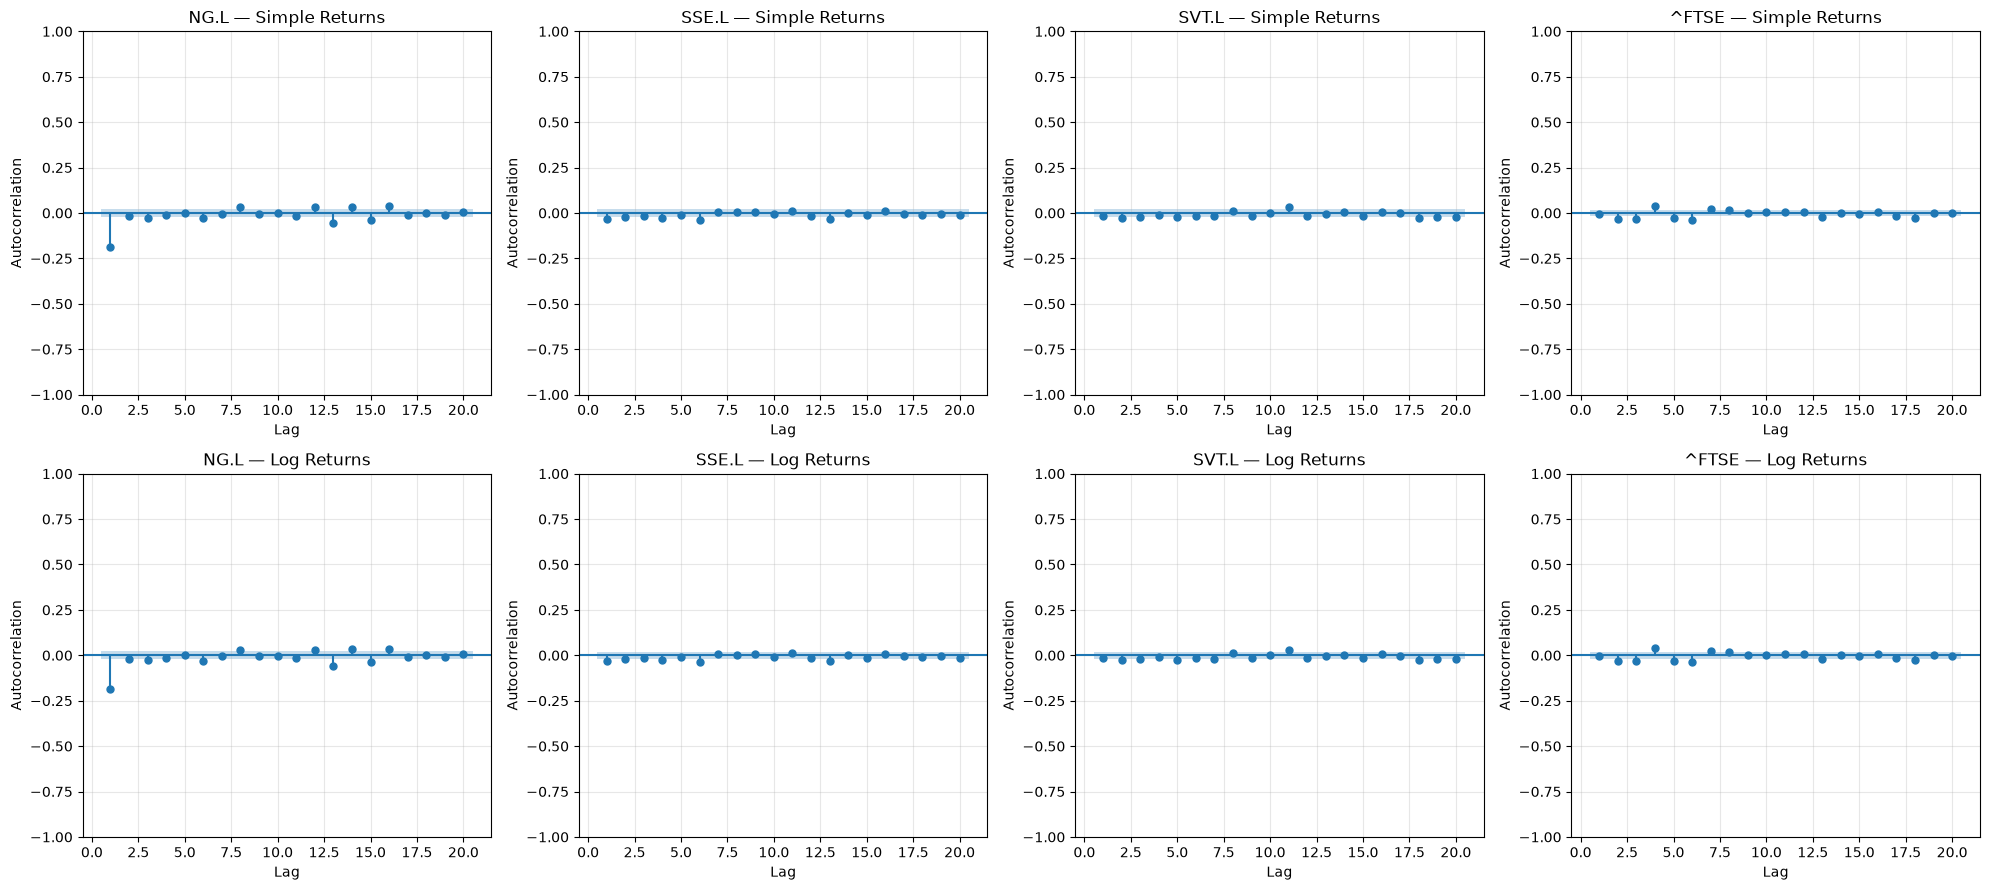

In [420]:
from statsmodels.graphics.tsaplots import plot_acf

ACF_MAX_LAGS = 20
ACF_ALPHA = 0.05

return_series = {
    "Simple Returns": simple_returns,
    "Log Returns": log_returns,
}

fig, axes = plt.subplots(
    nrows=len(return_series),
    ncols=len(simple_returns.columns),
    figsize=(20, 9),
)

for row_index, (return_type, returns_df) in enumerate(return_series.items()):
    for column_index, asset in enumerate(returns_df.columns):
        ax = axes[row_index, column_index]

        series = returns_df[asset].dropna()

        plot_acf(
            series,
            lags=ACF_MAX_LAGS,
            alpha=ACF_ALPHA,
            bartlett_confint=False,
            zero=False,
            fft=False,
            ax=ax,
        )

        ax.set_title(f"{asset} — {return_type}")
        ax.set_xlabel("Lag")
        ax.set_ylabel("Autocorrelation")
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### 12.3.2 Preliminary ACF Visual Findings

The initial ACF plots reveal generally small autocorrelation coefficients across the four assets.

The main observations are:

**National Grid (NG.L)**

NG.L exhibits a comparatively pronounced negative autocorrelation at lag 1, approximately -0.19, in both simple and logarithmic returns.

The remaining autocorrelation coefficients are substantially smaller and generally close to zero.

**SSE (SSE.L)**

The autocorrelation coefficients are generally small and fluctuate around zero. No pronounced persistent pattern is visually apparent.

**Severn Trent (SVT.L)**

Most autocorrelation coefficients are close to zero, although some positive and negative fluctuations are visible across intermediate lags.

No clear persistent autocorrelation pattern is apparent from the plots alone.

**FTSE 100 Index (^FTSE)**

The estimated autocorrelations are predominantly small, with occasional positive and negative deviations from zero.

No pronounced persistent pattern is visually apparent.

**Comparison Between Return Representations**

Simple and logarithmic returns exhibit broadly similar autocorrelation patterns across all four assets.

The negative first-lag autocorrelation observed for NG.L is present in both representations.

**Preliminary Interpretation**

The plots suggest limited linear temporal dependence for most of the examined return series, with the first-lag behaviour of NG.L representing the most notable observation.

These findings remain descriptive.

Statistical significance, joint autocorrelation and the robustness of the observed patterns must be assessed using formal statistical procedures.

No conclusions regarding forecasting capability or trading opportunities are drawn at this stage.

#### 12.3.3 Numerical ACF Assessment

This subsection quantifies the autocorrelation coefficients observed in the previous plots.

For each asset and return representation, the analysis will extract:

- Autocorrelation coefficients for lags 1 to 20.
- Lower and upper bounds of the approximate 95% confidence intervals.
- An indication of whether each interval includes zero.

The confidence intervals will use the white-noise approximation rather than Bartlett's formula.

These intervals provide an initial assessment of individual lag autocorrelations. They do not adjust for multiple hypothesis testing across the 20 lags.

The results will be interpreted alongside the subsequent joint statistical tests.

In [421]:
from statsmodels.tsa.stattools import acf

acf_results = []

for return_type, returns_df in return_series.items():
    for asset in returns_df.columns:
        series = returns_df[asset].dropna()

        acf_values, confidence_intervals = acf(
            series,
            nlags=ACF_MAX_LAGS,
            alpha=ACF_ALPHA,
            bartlett_confint=False,
            fft=False,
            missing="none",
        )

        for lag in range(1, ACF_MAX_LAGS + 1):
            lower_bound, upper_bound = confidence_intervals[lag]

            acf_results.append({
                "asset": asset,
                "return_type": return_type,
                "lag": lag,
                "acf": acf_values[lag],
                "ci_lower": lower_bound,
                "ci_upper": upper_bound,
                "excludes_zero": (
                    lower_bound > 0 or upper_bound < 0
                ),
            })

acf_results_df = pd.DataFrame(acf_results)

display(
    acf_results_df
    .round(6)
    .sort_values(["asset", "return_type", "lag"])
    .reset_index(drop=True)
)

/tmp/ipykernel_57127/3274180084.py:9: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  acf_values, confidence_intervals = acf(


,asset,return_type,lag,acf,ci_lower,ci_upper,excludes_zero
0,NG.L,Log Returns,1,-0.18825900,-0.21032700,-0.16619100,True
1,NG.L,Log Returns,2,-0.01816500,-0.04023400,0.00390300,False
2,NG.L,Log Returns,3,-0.02734100,-0.04940900,-0.00527300,True
3,NG.L,Log Returns,4,-0.01430600,-0.03637400,0.00776200,False
4,NG.L,Log Returns,5,0.00151100,-0.02055700,0.02357900,False
...,...,...,...,...,...,...,...
155,^FTSE,Simple Returns,16,0.00664000,-0.01232200,0.02560100,False
156,^FTSE,Simple Returns,17,-0.01731100,-0.03627300,0.00165100,False
157,^FTSE,Simple Returns,18,-0.02772100,-0.04668300,-0.00875900,True
158,^FTSE,Simple Returns,19,0.00083700,-0.01812500,0.01979900,False


In [422]:
acf_significance_summary = (
    acf_results_df
    .groupby(["asset", "return_type"])
    .agg(
        significant_lags=(
            "excludes_zero",
            "sum",
        ),
        total_lags=("lag", "count"),
    )
    .reset_index()
)

acf_significant_lags = (
    acf_results_df
    .loc[acf_results_df["excludes_zero"]]
    .sort_values(["asset", "return_type", "lag"])
    .reset_index(drop=True)
)

print("Individual ACF Confidence Interval Summary")
display(acf_significance_summary)

print("Lags with Confidence Intervals Excluding Zero")
display(acf_significant_lags.round(6))

Individual ACF Confidence Interval Summary


,asset,return_type,significant_lags,total_lags
0,NG.L,Log Returns,9,20
1,NG.L,Simple Returns,9,20
2,SSE.L,Log Returns,4,20
3,SSE.L,Simple Returns,4,20
4,SVT.L,Log Returns,6,20
5,SVT.L,Simple Returns,6,20
6,^FTSE,Log Returns,8,20
7,^FTSE,Simple Returns,8,20


Lags with Confidence Intervals Excluding Zero


,asset,return_type,lag,acf,ci_lower,ci_upper,excludes_zero
0,NG.L,Log Returns,1,-0.18825900,-0.21032700,-0.16619100,True
1,NG.L,Log Returns,3,-0.02734100,-0.04940900,-0.00527300,True
2,NG.L,Log Returns,6,-0.03008300,-0.05215100,-0.00801500,True
3,NG.L,Log Returns,8,0.03098200,0.00891300,0.05305000,True
4,NG.L,Log Returns,12,0.03085600,0.00878800,0.05292400,True
5,NG.L,Log Returns,13,-0.05833800,-0.08040600,-0.03627000,True
6,NG.L,Log Returns,14,0.03529600,0.01322700,0.05736400,True
7,NG.L,Log Returns,15,-0.03756300,-0.05963100,-0.01549400,True
8,NG.L,Log Returns,16,0.03469500,0.01262700,0.05676300,True
9,NG.L,Simple Returns,1,-0.18961200,-0.21168100,-0.16754400,True


#### 12.3.4 Numerical ACF Findings

The numerical ACF assessment identified autocorrelation coefficients whose approximate 95% confidence intervals excluded zero.

The results were consistent across simple and logarithmic returns in terms of the identified lag positions.

| Asset | Simple Returns | Log Returns | Identified Lags |
|---|---:|---:|---|
| NG.L | 9/20 | 9/20 | 1, 3, 6, 8, 12, 13, 14, 15, 16 |
| SSE.L | 4/20 | 4/20 | 1, 4, 6, 13 |
| SVT.L | 6/20 | 6/20 | 2, 3, 5, 11, 18, 19 |
| FTSE 100 | 8/20 | 8/20 | 2, 3, 4, 5, 6, 7, 13, 18 |

**National Grid (NG.L)**

NG.L exhibits the highest number of individually identified autocorrelation coefficients.

The most pronounced result occurs at lag 1:

- Simple returns: -0.1896.
- Log returns: -0.1883.

Both estimates indicate a comparatively strong negative first-lag autocorrelation.

The remaining identified coefficients have substantially smaller magnitudes.

**SSE (SSE.L)**

Four lags were identified for each return representation. All corresponding autocorrelation coefficients are negative and relatively small.

**Severn Trent (SVT.L)**

Six lags were identified for each return representation. Most identified coefficients are negative, with a positive coefficient at lag 11.

**FTSE 100 Index (^FTSE)**

Eight lags were identified for each return representation. Although several confidence intervals exclude zero, the corresponding autocorrelation magnitudes remain relatively small.

**Statistical Interpretation**

A total of 54 individual lag assessments out of 160 had confidence intervals excluding zero.

These results must be interpreted cautiously because multiple individual hypotheses were tested.

The approximate confidence intervals do not control the family-wise error rate or false discovery rate.

Furthermore, simple and logarithmic returns are closely related representations and should not be treated as independent evidence.

The Ljung-Box test will provide a complementary assessment of joint autocorrelation across multiple lags.

No conclusions regarding economic significance, forecasting capability or trading profitability are drawn at this stage.

#### 12.4.1 PACF Visual Analysis

The Partial Autocorrelation Function (PACF) is used to investigate the direct linear relationship between a time series and its lagged observations after accounting for the effects of intermediate lags.

Unlike the ACF, which includes both direct and indirect linear relationships, the PACF isolates the contribution associated with each specific lag under a linear autoregressive framework.

The analysis considers simple and logarithmic returns for all four assets:

- National Grid (NG.L).
- SSE (SSE.L).
- Severn Trent (SVT.L).
- FTSE 100 Index (^FTSE).

The PACF will be estimated over the first 20 lags using the Yule-Walker maximum likelihood method.

Approximate 95% confidence intervals will be displayed as an initial reference for individual lag assessments.

Missing observations will be excluded before estimation. Consequently, observations separated by missing dates may become adjacent in the resulting sequence.

The results will be interpreted as exploratory evidence of partial linear dependence, not as proof of predictive capability or trading opportunities.

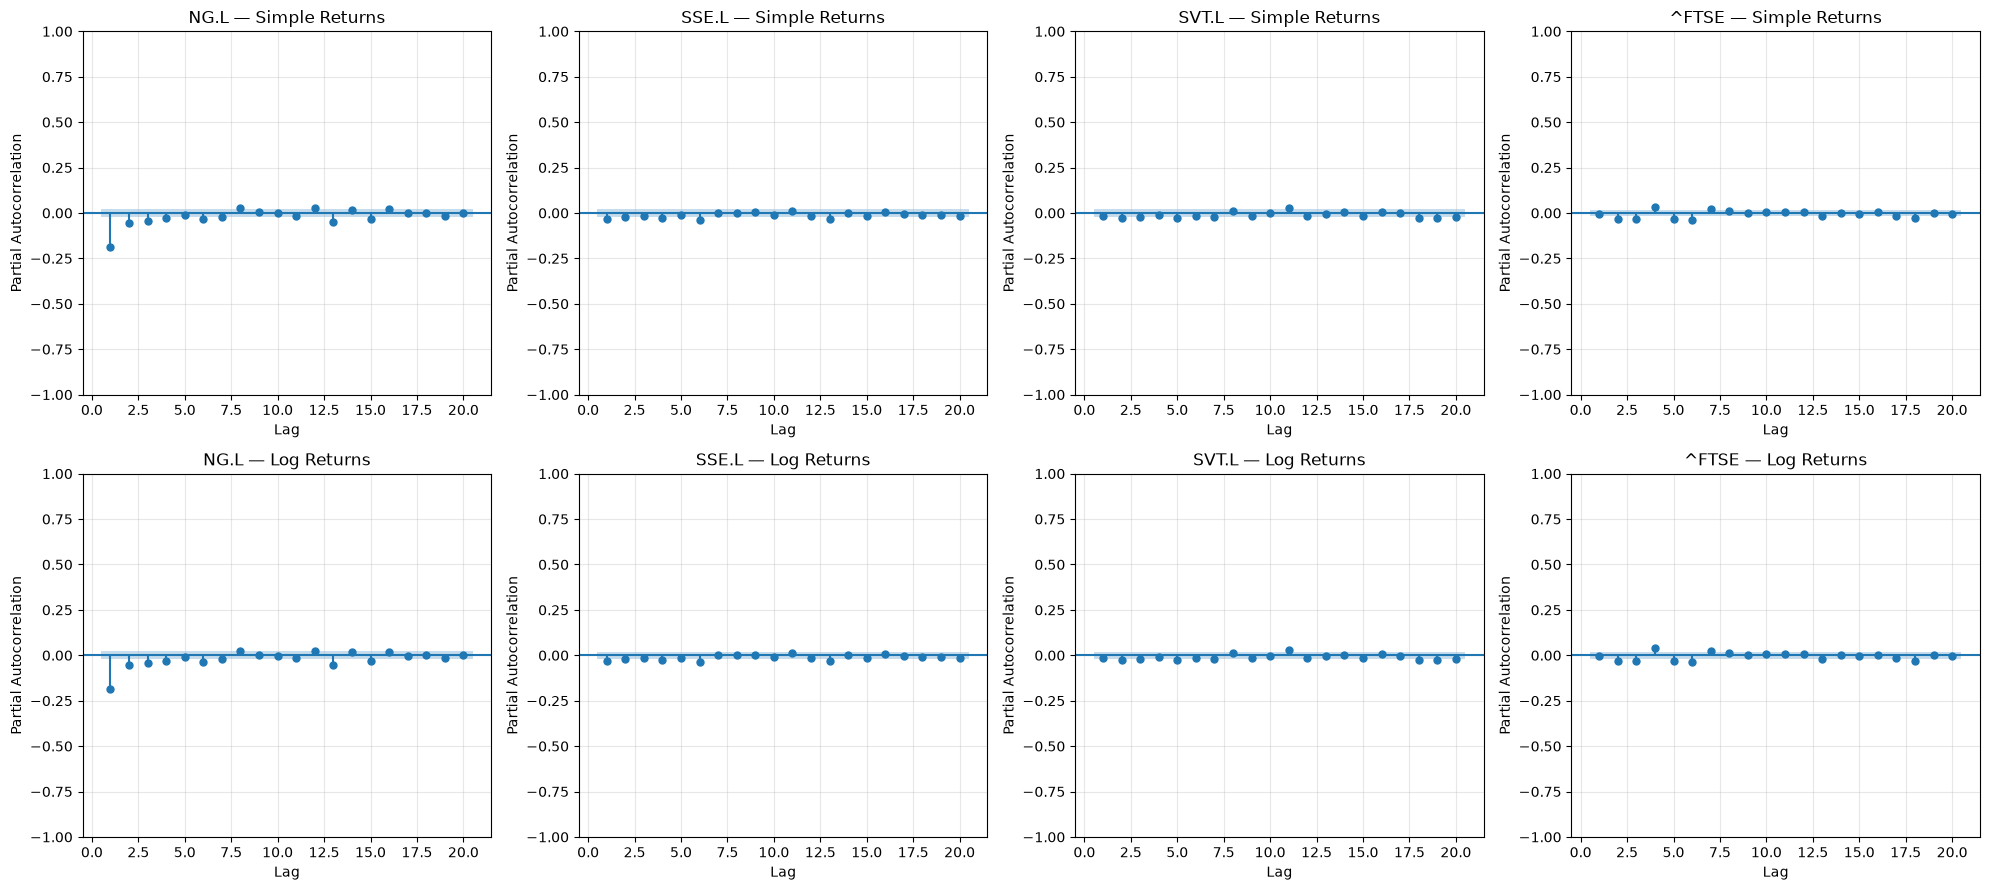

In [423]:
from statsmodels.graphics.tsaplots import plot_pacf

PACF_MAX_LAGS = 20
PACF_ALPHA = 0.05
PACF_METHOD = "ywm"

fig, axes = plt.subplots(
    nrows=len(return_series),
    ncols=len(simple_returns.columns),
    figsize=(20, 9),
)

for row_index, (return_type, returns_df) in enumerate(return_series.items()):
    for column_index, asset in enumerate(returns_df.columns):
        ax = axes[row_index, column_index]

        series = returns_df[asset].dropna()

        plot_pacf(
            series,
            lags=PACF_MAX_LAGS,
            alpha=PACF_ALPHA,
            method=PACF_METHOD,
            zero=False,
            ax=ax,
        )

        ax.set_title(f"{asset} — {return_type}")
        ax.set_xlabel("Lag")
        ax.set_ylabel("Partial Autocorrelation")
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### 12.4.3 Preliminary PACF Visual Findings

The initial PACF plots indicate generally small partial autocorrelation coefficients across the four assets.

The main observations are:

**National Grid (NG.L)**

NG.L exhibits the most pronounced partial autocorrelation pattern, particularly at lag 1, where a negative coefficient of approximately -0.19 is visible in both simple and logarithmic returns.

The second lag also displays a smaller negative coefficient.

The remaining coefficients are comparatively close to zero.

**SSE (SSE.L)**

The partial autocorrelation coefficients are generally small and close to zero.

No pronounced autoregressive pattern is visually apparent.

**Severn Trent (SVT.L)**

Most coefficients are close to zero, with relatively small negative deviations at the initial lags and a minor positive deviation around lag 11.

No strong persistent partial autocorrelation pattern is visually apparent.

**FTSE 100 Index (^FTSE)**

The estimated partial autocorrelations are predominantly small, with occasional positive and negative deviations.

No pronounced autoregressive structure is visually apparent.

**Comparison Between ACF and PACF**

The negative first-lag dependence identified for NG.L in the ACF analysis remains visible in the PACF plots.

This suggests that the first-lag relationship is not explained solely by the linear effects of intermediate lags.

However, the visual comparison is preliminary. Numerical estimates and confidence intervals are required before drawing statistical conclusions.

No conclusions regarding forecasting capability or trading opportunities are drawn at this stage.

#### 12.4.4 Numerical PACF Assessment

This subsection quantifies the partial autocorrelation coefficients observed in the previous plots.

For each asset and return representation, the analysis will extract:

- Partial autocorrelation coefficients for lags 1 to 20.
- Lower and upper bounds of the approximate 95% confidence intervals.
- An indication of whether each interval includes zero.

The PACF estimates will use the Yule-Walker maximum likelihood method.

The confidence intervals provide an initial assessment of individual partial autocorrelation coefficients. They do not adjust for multiple hypothesis testing across the 20 lags.

The results will be compared with the ACF findings to distinguish direct lag relationships from broader autocorrelation patterns.

These estimates will be interpreted as descriptive statistical evidence rather than proof of predictive capability.

In [424]:
from statsmodels.tsa.stattools import pacf

pacf_results = []

for return_type, returns_df in return_series.items():
    for asset in returns_df.columns:
        series = returns_df[asset].dropna()

        pacf_values, confidence_intervals = pacf(
            series,
            nlags=PACF_MAX_LAGS,
            alpha=PACF_ALPHA,
            method=PACF_METHOD,
        )

        for lag in range(1, PACF_MAX_LAGS + 1):
            lower_bound, upper_bound = confidence_intervals[lag]

            pacf_results.append({
                "asset": asset,
                "return_type": return_type,
                "lag": lag,
                "pacf": pacf_values[lag],
                "ci_lower": lower_bound,
                "ci_upper": upper_bound,
                "excludes_zero": (
                    lower_bound > 0 or upper_bound < 0
                ),
            })

pacf_results_df = pd.DataFrame(pacf_results)

display(
    pacf_results_df
    .round(6)
    .sort_values(["asset", "return_type", "lag"])
    .reset_index(drop=True)
)

,asset,return_type,lag,pacf,ci_lower,ci_upper,excludes_zero
0,NG.L,Log Returns,1,-0.18825900,-0.21032700,-0.16619100,True
1,NG.L,Log Returns,2,-0.05557700,-0.07764500,-0.03350900,True
2,NG.L,Log Returns,3,-0.04306800,-0.06513700,-0.02100000,True
3,NG.L,Log Returns,4,-0.03029600,-0.05236400,-0.00822800,True
4,NG.L,Log Returns,5,-0.01020700,-0.03227500,0.01186100,False
...,...,...,...,...,...,...,...
155,^FTSE,Simple Returns,16,0.00513400,-0.01382800,0.02409500,False
156,^FTSE,Simple Returns,17,-0.01597800,-0.03493900,0.00298400,False
157,^FTSE,Simple Returns,18,-0.02930200,-0.04826400,-0.01034100,True
158,^FTSE,Simple Returns,19,-0.00140700,-0.02036900,0.01755500,False


In [425]:
pacf_significance_summary = (
    pacf_results_df
    .groupby(["asset", "return_type"])
    .agg(
        significant_lags=("excludes_zero", "sum"),
        total_lags=("lag", "count"),
    )
    .reset_index()
)

pacf_significant_lags = (
    pacf_results_df
    .loc[pacf_results_df["excludes_zero"]]
    .sort_values(["asset", "return_type", "lag"])
    .reset_index(drop=True)
)

print("Individual PACF Confidence Interval Summary")
display(pacf_significance_summary)

print("Lags with Confidence Intervals Excluding Zero")
display(pacf_significant_lags.round(6))

Individual PACF Confidence Interval Summary


,asset,return_type,significant_lags,total_lags
0,NG.L,Log Returns,9,20
1,NG.L,Simple Returns,9,20
2,SSE.L,Log Returns,4,20
3,SSE.L,Simple Returns,5,20
4,SVT.L,Log Returns,8,20
5,SVT.L,Simple Returns,8,20
6,^FTSE,Log Returns,7,20
7,^FTSE,Simple Returns,7,20


Lags with Confidence Intervals Excluding Zero


,asset,return_type,lag,pacf,ci_lower,ci_upper,excludes_zero
0,NG.L,Log Returns,1,-0.18825900,-0.21032700,-0.16619100,True
1,NG.L,Log Returns,2,-0.05557700,-0.07764500,-0.03350900,True
2,NG.L,Log Returns,3,-0.04306800,-0.06513700,-0.02100000,True
3,NG.L,Log Returns,4,-0.03029600,-0.05236400,-0.00822800,True
4,NG.L,Log Returns,6,-0.03608700,-0.05815500,-0.01401900,True
5,NG.L,Log Returns,8,0.02385400,0.00178600,0.04592200,True
6,NG.L,Log Returns,12,0.02580700,0.00373900,0.04787500,True
7,NG.L,Log Returns,13,-0.05104000,-0.07310800,-0.02897200,True
8,NG.L,Log Returns,15,-0.03164700,-0.05371500,-0.00957900,True
9,NG.L,Simple Returns,1,-0.18961200,-0.21168100,-0.16754400,True


#### 12.4.5 Numerical PACF Findings

The numerical PACF assessment identified partial autocorrelation coefficients whose approximate 95% confidence intervals excluded zero.

The results are summarised below.

| Asset | Simple Returns | Log Returns | Identified Lags |
|---|---:|---:|---|
| NG.L | 9/20 | 9/20 | 1, 2, 3, 4, 6, 8, 12, 13, 15 |
| SSE.L | 5/20 | 4/20 | Simple: 1, 2, 4, 6, 13; Log: 1, 4, 6, 13 |
| SVT.L | 8/20 | 8/20 | 2, 3, 5, 7, 11, 18, 19, 20 |
| FTSE 100 | 7/20 | 7/20 | 2, 3, 4, 5, 6, 7, 18 |

**National Grid (NG.L)**

NG.L exhibits the highest number of identified partial autocorrelations, with nine lags for each return representation.

The first-lag coefficient is approximately -0.189 for both simple and logarithmic returns.

Negative partial autocorrelation coefficients are also identified at lags 2, 3, 4, 6, 13 and 15, while positive coefficients are identified at lags 8 and 12.

This indicates that the partial autocorrelation structure extends beyond the first lag.

**SSE (SSE.L)**

Four lags are identified for logarithmic returns and five for simple returns.

The identified coefficients are predominantly negative and relatively small.

**Severn Trent (SVT.L)**

Eight lags are identified for both return representations.

Most identified coefficients are negative, with a positive coefficient at lag 11.

**FTSE 100 Index (^FTSE)**

Seven lags are identified for each return representation.

The results include both positive and negative partial autocorrelation coefficients.

**Comparison Between ACF and PACF**

The comparison demonstrates that the number and location of individually identified coefficients can differ between the ACF and PACF.

For NG.L, the negative first-lag relationship remains virtually unchanged after controlling for intermediate lags.

For the other assets, the partial autocorrelation patterns differ to varying degrees from their corresponding ACF patterns.

**Statistical Interpretation**

A total of 57 individual PACF assessments out of 160 had confidence intervals excluding zero.

These results remain subject to multiple-testing limitations.

The individual confidence intervals do not control the family-wise error rate or false discovery rate.

The PACF findings therefore provide exploratory evidence of partial linear dependence, rather than proof of a stable autoregressive structure or predictive capability.

The subsequent joint statistical tests will provide complementary evidence.

### 12.5 Statistical Significance Tests

This section establishes the statistical framework used to evaluate the significance of autocorrelation and partial autocorrelation estimates.

The analysis distinguishes between individual lag assessments and joint tests across multiple lags.

**1. Individual Lag Significance**

Individual ACF and PACF coefficients are assessed using approximate 95% confidence intervals.

An interval excluding zero indicates evidence against a zero coefficient at the corresponding lag under the assumptions of the approximation.

These individual assessments do not account for multiple hypothesis testing.

**2. Joint Autocorrelation Significance**

Individual confidence intervals do not determine whether a return series exhibits joint autocorrelation across several lags.

A separate joint statistical test is therefore required.

The Ljung-Box test will be used to investigate whether autocorrelations up to specified lag orders are jointly equal to zero.

**3. Significance Level**

The initial significance level is:

\[
\alpha = 0.05
\]

A p-value below this threshold provides evidence against the relevant null hypothesis.

**4. Multiple Testing Considerations**

The analysis includes multiple assets, return representations and lag orders.

Repeated hypothesis testing increases the probability of false-positive findings.

The individual ACF and PACF results will therefore be treated as exploratory evidence.

Joint test results will also be interpreted cautiously, considering the number of tests performed and the dependence between related return representations.

**5. Statistical Versus Economic Significance**

Statistical significance does not necessarily imply economically meaningful dependence.

Likewise, detected autocorrelation does not establish forecasting accuracy or trading profitability.

Any potential predictive relevance would require separate out-of-sample evaluation under realistic trading assumptions.

### 12.6 Ljung-Box Test

#### 12.6.1 Ljung-Box Test Methodology

The Ljung-Box test is used to assess whether a time series exhibits statistically significant autocorrelation across a specified range of lags.

The test evaluates the joint null hypothesis:

\[
H_0: \rho_1 = \rho_2 = \cdots = \rho_h = 0
\]

The alternative hypothesis is:

\[
H_1: \text{At least one autocorrelation coefficient is non-zero}
\]

where \(h\) represents the maximum lag included in the test.

The Ljung-Box statistic is defined as:

\[
Q^* = n(n+2)\sum_{k=1}^{h}\frac{\hat{\rho}_k^2}{n-k}
\]

where:

- \(n\) is the number of observations.
- \(h\) is the maximum lag.
- \(\hat{\rho}_k\) is the estimated autocorrelation at lag \(k\).

Under the null hypothesis, the statistic is approximately chi-squared distributed, subject to the assumptions of the test.

**Test Configuration**

The analysis will use the following lag orders:

- 5 observations.
- 10 observations.
- 15 observations.
- 20 observations.

The significance level will remain:

\[
\alpha = 0.05
\]

The test will initially be applied to simple and logarithmic returns for all four assets.

**Interpretation**

A p-value below 0.05 indicates evidence against the null hypothesis of no autocorrelation up to the specified lag.

A p-value equal to or above 0.05 indicates insufficient evidence to reject the null hypothesis.

Failure to reject the null hypothesis does not establish that the observations are independent.

**Methodological Considerations**

The test will be applied to the observed return sequences after excluding missing values.

Consequently, observations separated by missing dates may become adjacent in the resulting sequence.

The selected lag orders refer to positions in the resulting series rather than necessarily representing consecutive calendar or exchange trading sessions.

The standard Ljung-Box test will initially use zero degrees-of-freedom adjustment for fitted autoregressive parameters because no autoregressive model has been estimated at this stage.

The results will be interpreted as evidence of linear autocorrelation, not as proof of forecasting capability or trading profitability.

#### 12.6.2 Ljung-Box Test Execution

The Ljung-Box test will be applied to the simple and logarithmic return series of all four assets.

The test will evaluate joint autocorrelation at lag orders 5, 10, 15 and 20.

For each combination of asset, return representation and lag order, the analysis will record:

- Ljung-Box test statistic.
- P-value.
- Number of observations.
- Statistical decision at the 5% significance level.

No autoregressive parameters have been estimated, so the degrees-of-freedom adjustment will remain zero.

The results will provide the first formal assessment of joint return autocorrelation across the examined assets.

In [426]:
from statsmodels.stats.diagnostic import acorr_ljungbox

LJUNG_BOX_LAGS = [5, 10, 15, 20]
LJUNG_BOX_ALPHA = 0.05

ljung_box_results = []

for return_type, returns_df in return_series.items():
    for asset in returns_df.columns:
        series = returns_df[asset].dropna()

        test_results = acorr_ljungbox(
            series,
            lags=LJUNG_BOX_LAGS,
            model_df=0,
            return_df=True,
        )

        for lag, result in test_results.iterrows():
            ljung_box_results.append({
                "asset": asset,
                "return_type": return_type,
                "lag": int(lag),
                "observations": len(series),
                "lb_statistic": result["lb_stat"],
                "p_value": result["lb_pvalue"],
                "reject_null": result["lb_pvalue"] < LJUNG_BOX_ALPHA,
            })

ljung_box_results_df = pd.DataFrame(ljung_box_results)

display(
    ljung_box_results_df
    .round(6)
    .sort_values(["asset", "return_type", "lag"])
    .reset_index(drop=True)
)

,asset,return_type,lag,observations,lb_statistic,p_value,reject_null
0,NG.L,Log Returns,5,7888,289.80675200,0.00000000,True
1,NG.L,Log Returns,10,7888,304.78990700,0.00000000,True
2,NG.L,Log Returns,15,7888,362.04318900,0.00000000,True
3,NG.L,Log Returns,20,7888,373.75019700,0.00000000,True
4,NG.L,Simple Returns,5,7888,294.64955300,0.00000000,True
5,NG.L,Simple Returns,10,7888,310.07736500,0.00000000,True
6,NG.L,Simple Returns,15,7888,365.08567800,0.00000000,True
7,NG.L,Simple Returns,20,7888,377.84506100,0.00000000,True
8,SSE.L,Log Returns,5,9058,21.58988200,0.00062600,True
9,SSE.L,Log Returns,10,9058,35.30927900,0.00011100,True


#### 12.6.3 Ljung-Box Test Results and Interpretation

The Ljung-Box test was applied to simple and logarithmic returns for all four assets at lag orders 5, 10, 15 and 20.

All 32 tests rejected the null hypothesis at the 5% significance level.

**Summary of Results**

| Asset | Return Type | Lag 5 | Lag 10 | Lag 15 | Lag 20 |
|---|---|---:|---:|---:|---:|
| NG.L | Log Returns | <0.001 | <0.001 | <0.001 | <0.001 |
| NG.L | Simple Returns | <0.001 | <0.001 | <0.001 | <0.001 |
| SSE.L | Log Returns | 0.000626 | 0.000111 | 0.000010 | 0.000063 |
| SSE.L | Simple Returns | 0.000250 | 0.000058 | 0.000005 | 0.000030 |
| SVT.L | Log Returns | 0.001211 | 0.001567 | 0.000127 | 0.000012 |
| SVT.L | Simple Returns | 0.000904 | 0.000987 | 0.000071 | 0.000006 |
| FTSE 100 | Log Returns | <0.001 | <0.001 | <0.001 | <0.001 |
| FTSE 100 | Simple Returns | <0.001 | <0.001 | <0.001 | <0.001 |

Values displayed as zero by the computational output are reported as less than 0.001 because they fall below the displayed numerical precision.

**National Grid (NG.L)**

All four lag configurations reject the null hypothesis.

The Ljung-Box statistics increase from 289.81 at lag 5 to 373.75 at lag 20 for simple returns.

These results provide strong evidence of joint autocorrelation and are consistent with the pronounced first-lag relationship identified in the ACF and PACF analyses.

**SSE (SSE.L)**

All four configurations reject the null hypothesis for both return representations.

The results indicate statistically significant joint autocorrelation despite the relatively small individual ACF and PACF coefficients.

**Severn Trent (SVT.L)**

All configurations reject the null hypothesis.

The highest reported p-value is 0.001567 for logarithmic returns at lag 10, which remains below the 5% significance threshold.

**FTSE 100 Index (^FTSE)**

All configurations strongly reject the null hypothesis.

This indicates that statistically significant joint autocorrelation is also present in the broad market index.

**Overall Interpretation**

The Ljung-Box results provide consistent evidence against the hypothesis of zero autocorrelation across the examined lag ranges for all four assets.

The findings complement the individual ACF and PACF assessments.

However, the rejection of the null hypothesis does not establish economically meaningful predictability, independence violations of every possible form, or trading profitability.

**Multiple Testing Considerations**

The analysis comprises 32 joint tests.

A conservative Bonferroni threshold would be approximately 0.0015625.

Based on the displayed p-values, the SVT.L logarithmic-return test at lag 10 (p = 0.001567) is marginally above this threshold. Its exact unrounded p-value should be checked before making a definitive adjusted-significance classification.

No multiple-testing adjustment has been applied to the reported primary results.

The findings remain subject to the limitations associated with missing observations and the treatment of separated observations as adjacent positions in the test sequences.

#### 12.6.4 Multiple Testing Correction

##### 12.6.4.1 Multiple Testing Correction Methodology

The Ljung-Box analysis involves multiple hypothesis tests across assets, return representations and lag orders.

Conducting multiple tests increases the probability of obtaining false-positive findings.

Two correction procedures will be considered:

**1. Bonferroni Correction**

The Bonferroni procedure adjusts the significance threshold according to the total number of tests:

\[
\alpha_{\text{Bonferroni}} = \frac{\alpha}{m}
\]

where:

- \(\alpha\) is the original significance level.
- \(m\) is the total number of hypotheses tested.

**2. Holm-Bonferroni Procedure**

The Holm procedure applies a sequential adjustment to ordered p-values.

It controls the family-wise error rate and is generally less conservative than the standard Bonferroni procedure.

**Test Family**

The correction will initially cover all 32 Ljung-Box tests:

- Four assets.
- Two return representations.
- Four lag orders.

The original significance level remains 0.05.

**Interpretation**

Adjusted p-values will be compared with the original 5% significance level.

The correction addresses multiple testing within this defined family. It does not resolve other sources of statistical uncertainty, dependence between observations or methodological limitations associated with missing dates.

The adjusted results will complement, rather than replace, the unadjusted Ljung-Box findings.

In [427]:
from statsmodels.stats.multitest import multipletests

ljung_box_corrected_df = ljung_box_results_df.copy()

# Bonferroni-adjusted p-values
bonferroni_results = multipletests(
    ljung_box_corrected_df["p_value"],
    alpha=LJUNG_BOX_ALPHA,
    method="bonferroni",
)

# Holm-Bonferroni-adjusted p-values
holm_results = multipletests(
    ljung_box_corrected_df["p_value"],
    alpha=LJUNG_BOX_ALPHA,
    method="holm",
)

ljung_box_corrected_df["bonferroni_p_value"] = (
    bonferroni_results[1]
)

ljung_box_corrected_df["bonferroni_reject"] = (
    bonferroni_results[0]
)

ljung_box_corrected_df["holm_p_value"] = (
    holm_results[1]
)

ljung_box_corrected_df["holm_reject"] = (
    holm_results[0]
)

ljung_box_corrected_df["bonferroni_threshold"] = (
    LJUNG_BOX_ALPHA / len(ljung_box_corrected_df)
)

display(
    ljung_box_corrected_df[
        [
            "asset",
            "return_type",
            "lag",
            "p_value",
            "bonferroni_p_value",
            "bonferroni_reject",
            "holm_p_value",
            "holm_reject",
        ]
    ]
    .round(10)
    .sort_values(["asset", "return_type", "lag"])
    .reset_index(drop=True)
)

,asset,return_type,lag,p_value,bonferroni_p_value,bonferroni_reject,holm_p_value,holm_reject
0,NG.L,Log Returns,5,0.00000000,0.00000000,True,0.00000000,True
1,NG.L,Log Returns,10,0.00000000,0.00000000,True,0.00000000,True
2,NG.L,Log Returns,15,0.00000000,0.00000000,True,0.00000000,True
3,NG.L,Log Returns,20,0.00000000,0.00000000,True,0.00000000,True
4,NG.L,Simple Returns,5,0.00000000,0.00000000,True,0.00000000,True
5,NG.L,Simple Returns,10,0.00000000,0.00000000,True,0.00000000,True
6,NG.L,Simple Returns,15,0.00000000,0.00000000,True,0.00000000,True
7,NG.L,Simple Returns,20,0.00000000,0.00000000,True,0.00000000,True
8,SSE.L,Log Returns,5,0.00062642,0.02004538,True,0.00313209,True
9,SSE.L,Log Returns,10,0.00011056,0.00353798,True,0.00088449,True


##### 12.6.4.3 Multiple Testing Correction Results

The 32 Ljung-Box tests were adjusted using Bonferroni and Holm-Bonferroni procedures.

The results are summarised below.

| Asset | Total Tests | Bonferroni Significant | Holm Significant |
|---|---:|---:|---:|
| NG.L | 8 | 8 | 8 |
| SSE.L | 8 | 8 | 8 |
| SVT.L | 8 | 7 | 8 |
| FTSE 100 | 8 | 8 | 8 |
| **Total** | **32** | **31** | **32** |

**Bonferroni Correction**

Thirty-one of the 32 tests remained statistically significant after Bonferroni adjustment.

The only exception was the SVT.L logarithmic-return test at lag 10:

- Original p-value: 0.00156678.
- Bonferroni-adjusted p-value: 0.05013687.

This value marginally exceeds the 5% significance threshold.

**Holm-Bonferroni Correction**

All 32 tests remained statistically significant after Holm adjustment.

For the SVT.L logarithmic-return test at lag 10, the adjusted p-value was 0.00361712.

**Overall Interpretation**

The joint autocorrelation findings are robust to both multiple-testing correction procedures, with the exception of one result under the more conservative Bonferroni procedure.

The Holm procedure preserves statistical significance across all tested combinations.

However, simple and logarithmic returns are closely related representations and should not be interpreted as independent evidence.

The correction procedures address multiple testing within the defined family of 32 hypotheses. They do not establish temporal stability, economic relevance, predictive capability or trading profitability.

### 12.7 Return Autocorrelation Analysis

#### 12.7.1 Squared Returns Methodology

This subsection investigates the autocorrelation structure of squared financial returns.

While autocorrelation in raw returns examines linear temporal dependence in return values, autocorrelation in squared returns examines dependence in return magnitudes.

Squared returns are calculated as:

\[
r_t^2 = (r_t)^2
\]

The analysis will consider:

- Squared simple returns.
- Squared logarithmic returns.

Both representations will be examined for:

- National Grid (NG.L).
- SSE (SSE.L).
- Severn Trent (SVT.L).
- FTSE 100 Index (^FTSE).

The ACF will be used to investigate the temporal dependence of squared returns over the first 20 lags.

The Ljung-Box test will subsequently assess joint autocorrelation in these transformed series.

Significant autocorrelation in squared returns may provide evidence of persistence in return magnitudes and volatility clustering.

However, squared-return autocorrelation alone does not establish conditional heteroskedasticity or identify a specific volatility model.

Missing observations will be excluded without interpolation or forward-filling, preserving the limitations previously documented for the treatment of temporal gaps.

The analysis remains exploratory and does not constitute a volatility forecasting model.

In [428]:
# Calculate squared simple and logarithmic returns

squared_return_series = {
    "Squared Simple Returns": simple_returns.pow(2),
    "Squared Log Returns": log_returns.pow(2),
}

print("Squared return series created successfully.")

Squared return series created successfully.


In [429]:
# Validate squared return series

squared_returns_validation = []

for return_type, returns_df in squared_return_series.items():

    for asset in returns_df.columns:

        original_series = (
            simple_returns[asset]
            if return_type == "Squared Simple Returns"
            else log_returns[asset]
        )

        squared_series = returns_df[asset]

        squared_returns_validation.append({
            "return_type": return_type,
            "asset": asset,
            "observations": len(squared_series),
            "missing_values": squared_series.isna().sum(),
            "negative_values": (squared_series.dropna() < 0).sum(),
            "infinite_values": np.isinf(squared_series.dropna()).sum(),
            "index_preserved": squared_series.index.equals(original_series.index),
            "squaring_verified": np.allclose(
                squared_series.dropna().values,
                original_series.dropna().pow(2).values,
            ),
        })

squared_returns_validation_df = pd.DataFrame(
    squared_returns_validation
)

display(squared_returns_validation_df)

,return_type,asset,observations,missing_values,negative_values,infinite_values,index_preserved,squaring_verified
0,Squared Simple Returns,NG.L,11004,3116,0,0,True,True
1,Squared Simple Returns,SSE.L,11004,1946,0,0,True,True
2,Squared Simple Returns,SVT.L,11004,1551,0,0,True,True
3,Squared Simple Returns,^FTSE,11004,320,0,0,True,True
4,Squared Log Returns,NG.L,11004,3116,0,0,True,True
5,Squared Log Returns,SSE.L,11004,1946,0,0,True,True
6,Squared Log Returns,SVT.L,11004,1551,0,0,True,True
7,Squared Log Returns,^FTSE,11004,320,0,0,True,True


In [430]:
# Calculate ACF for squared returns

from statsmodels.tsa.stattools import acf

SQUARED_ACF_MAX_LAGS = 20
SQUARED_ACF_ALPHA = 0.05

squared_acf_results = []

for return_type, returns_df in squared_return_series.items():

    for asset in returns_df.columns:

        series = returns_df[asset].dropna()

        acf_values, confidence_intervals = acf(
            series,
            nlags=SQUARED_ACF_MAX_LAGS,
            alpha=SQUARED_ACF_ALPHA,
            bartlett_confint=False,
            fft=False,
            missing="none",
        )

        for lag in range(1, SQUARED_ACF_MAX_LAGS + 1):

            lower_bound, upper_bound = confidence_intervals[lag]

            squared_acf_results.append({
                "asset": asset,
                "return_type": return_type,
                "lag": lag,
                "acf": acf_values[lag],
                "lower_ci": lower_bound,
                "upper_ci": upper_bound,
                "significant": (
                    lower_bound > 0 or upper_bound < 0
                ),
                "observations": len(series),
            })

squared_acf_results_df = pd.DataFrame(squared_acf_results)

print(f"Total ACF observations: {len(squared_acf_results_df)}")
display(squared_acf_results_df.head(10))

/tmp/ipykernel_57127/3797650364.py:16: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  acf_values, confidence_intervals = acf(


Total ACF observations: 160


,asset,return_type,lag,acf,lower_ci,upper_ci,significant,observations
0,NG.L,Squared Simple Returns,1,0.40073932,0.37867124,0.42280741,True,7888
1,NG.L,Squared Simple Returns,2,0.16443611,0.14236803,0.18650420,True,7888
2,NG.L,Squared Simple Returns,3,0.12858167,0.10651359,0.15064976,True,7888
3,NG.L,Squared Simple Returns,4,0.15066291,0.12859483,0.17273100,True,7888
4,NG.L,Squared Simple Returns,5,0.13082151,0.10875343,0.15288960,True,7888
5,NG.L,Squared Simple Returns,6,0.12583417,0.10376609,0.14790226,True,7888
6,NG.L,Squared Simple Returns,7,0.13815108,0.11608299,0.16021916,True,7888
7,NG.L,Squared Simple Returns,8,0.17892212,0.15685403,0.20099020,True,7888
8,NG.L,Squared Simple Returns,9,0.17696194,0.15489385,0.19903002,True,7888
9,NG.L,Squared Simple Returns,10,0.16418178,0.14211369,0.18624986,True,7888


In [431]:
# Calculate ACF for squared returns

squared_acf_results = []

for return_type, returns_df in squared_return_series.items():

    for asset in returns_df.columns:

        series = returns_df[asset].dropna()

        acf_result = acf(
            series,
            nlags=SQUARED_ACF_MAX_LAGS,
            alpha=SQUARED_ACF_ALPHA,
            bartlett_confint=False,
            fft=False,
            missing="none",
            result_object=True,
        )

        for lag in range(1, SQUARED_ACF_MAX_LAGS + 1):

            lower_bound, upper_bound = acf_result.confint[lag]

            squared_acf_results.append({
                "asset": asset,
                "return_type": return_type,
                "lag": lag,
                "acf": acf_result.acf[lag],
                "lower_ci": lower_bound,
                "upper_ci": upper_bound,
                "significant": (
                    lower_bound > 0 or upper_bound < 0
                ),
                "observations": len(series),
            })

squared_acf_results_df = pd.DataFrame(squared_acf_results)

print(f"Total ACF observations: {len(squared_acf_results_df)}")
display(squared_acf_results_df.head(10))

Total ACF observations: 160


,asset,return_type,lag,acf,lower_ci,upper_ci,significant,observations
0,NG.L,Squared Simple Returns,1,0.40073932,0.37867124,0.42280741,True,7888
1,NG.L,Squared Simple Returns,2,0.16443611,0.14236803,0.18650420,True,7888
2,NG.L,Squared Simple Returns,3,0.12858167,0.10651359,0.15064976,True,7888
3,NG.L,Squared Simple Returns,4,0.15066291,0.12859483,0.17273100,True,7888
4,NG.L,Squared Simple Returns,5,0.13082151,0.10875343,0.15288960,True,7888
5,NG.L,Squared Simple Returns,6,0.12583417,0.10376609,0.14790226,True,7888
6,NG.L,Squared Simple Returns,7,0.13815108,0.11608299,0.16021916,True,7888
7,NG.L,Squared Simple Returns,8,0.17892212,0.15685403,0.20099020,True,7888
8,NG.L,Squared Simple Returns,9,0.17696194,0.15489385,0.19903002,True,7888
9,NG.L,Squared Simple Returns,10,0.16418178,0.14211369,0.18624986,True,7888


In [432]:
squared_acf_results = []

for return_type, returns_df in squared_return_series.items():

    for asset in returns_df.columns:

        series = returns_df[asset].dropna()

        acf_result = acf(
            series,
            nlags=SQUARED_ACF_MAX_LAGS,
            alpha=SQUARED_ACF_ALPHA,
            bartlett_confint=False,
            fft=False,
            missing="none",
            result_object=True,
        )

        for lag in range(1, SQUARED_ACF_MAX_LAGS + 1):

            lower_bound, upper_bound = acf_result.confint[lag]

            squared_acf_results.append({
                "asset": asset,
                "return_type": return_type,
                "lag": lag,
                "acf": acf_result.acf[lag],
                "lower_ci": lower_bound,
                "upper_ci": upper_bound,
                "significant": (
                    lower_bound > 0 or upper_bound < 0
                ),
                "observations": len(series),
            })

squared_acf_results_df = pd.DataFrame(squared_acf_results)

print(f"Total ACF observations: {len(squared_acf_results_df)}")
display(squared_acf_results_df.head(10))

Total ACF observations: 160


,asset,return_type,lag,acf,lower_ci,upper_ci,significant,observations
0,NG.L,Squared Simple Returns,1,0.40073932,0.37867124,0.42280741,True,7888
1,NG.L,Squared Simple Returns,2,0.16443611,0.14236803,0.18650420,True,7888
2,NG.L,Squared Simple Returns,3,0.12858167,0.10651359,0.15064976,True,7888
3,NG.L,Squared Simple Returns,4,0.15066291,0.12859483,0.17273100,True,7888
4,NG.L,Squared Simple Returns,5,0.13082151,0.10875343,0.15288960,True,7888
5,NG.L,Squared Simple Returns,6,0.12583417,0.10376609,0.14790226,True,7888
6,NG.L,Squared Simple Returns,7,0.13815108,0.11608299,0.16021916,True,7888
7,NG.L,Squared Simple Returns,8,0.17892212,0.15685403,0.20099020,True,7888
8,NG.L,Squared Simple Returns,9,0.17696194,0.15489385,0.19903002,True,7888
9,NG.L,Squared Simple Returns,10,0.16418178,0.14211369,0.18624986,True,7888


In [433]:
# Summarise squared-return autocorrelation

squared_acf_summary = (
    squared_acf_results_df
    .groupby(["asset", "return_type"])
    .agg(
        significant_lags=("significant", "sum"),
        mean_absolute_acf=("acf", lambda x: x.abs().mean()),
        lag_1_acf=("acf", "first"),
        lag_5_acf=("acf", lambda x: x.iloc[4]),
        lag_10_acf=("acf", lambda x: x.iloc[9]),
        lag_20_acf=("acf", "last"),
        observations=("observations", "first"),
    )
    .reset_index()
)

display(
    squared_acf_summary.round(4)
)

,asset,return_type,significant_lags,mean_absolute_acf,lag_1_acf,lag_5_acf,lag_10_acf,lag_20_acf,observations
0,NG.L,Squared Log Returns,20,0.14540000,0.40690000,0.13930000,0.16240000,0.13960000,7888
1,NG.L,Squared Simple Returns,20,0.14500000,0.40070000,0.13080000,0.16420000,0.14200000,7888
2,SSE.L,Squared Log Returns,20,0.11950000,0.24070000,0.12910000,0.11070000,0.06190000,9058
3,SSE.L,Squared Simple Returns,20,0.11340000,0.23470000,0.12950000,0.10270000,0.06050000,9058
4,SVT.L,Squared Log Returns,4,0.01750000,0.09990000,0.01140000,0.03300000,0.01050000,9453
5,SVT.L,Squared Simple Returns,5,0.02600000,0.14540000,0.01720000,0.04870000,0.01580000,9453
6,^FTSE,Squared Log Returns,20,0.17380000,0.34650000,0.21630000,0.17610000,0.08090000,10684
7,^FTSE,Squared Simple Returns,20,0.18030000,0.33910000,0.22480000,0.18470000,0.08660000,10684


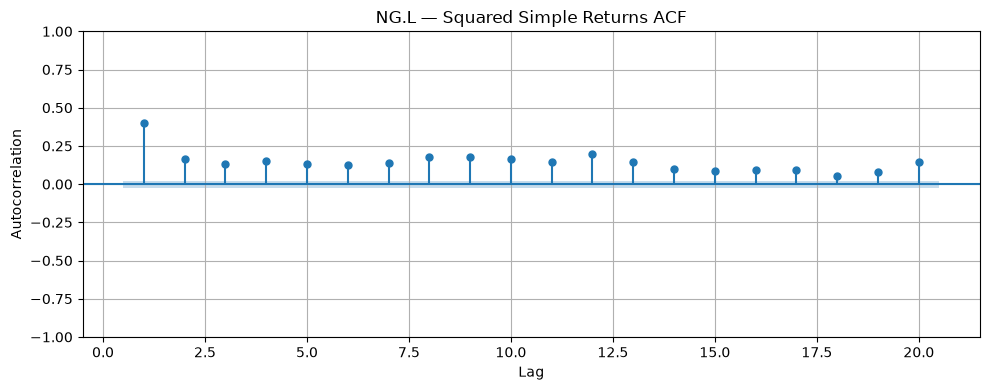

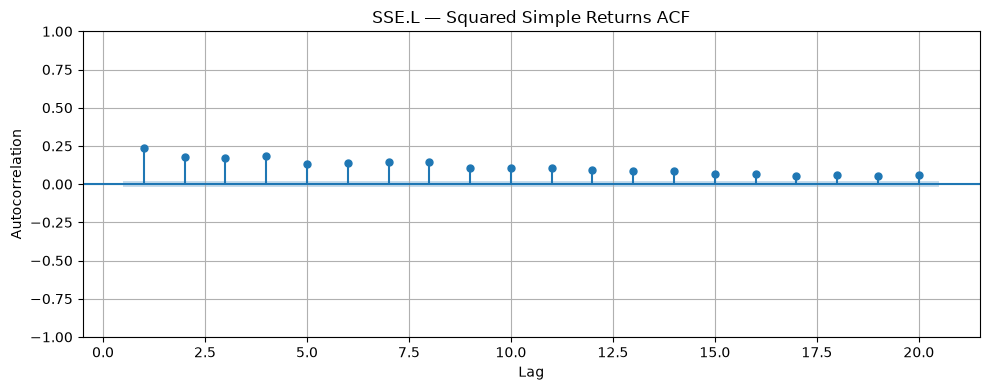

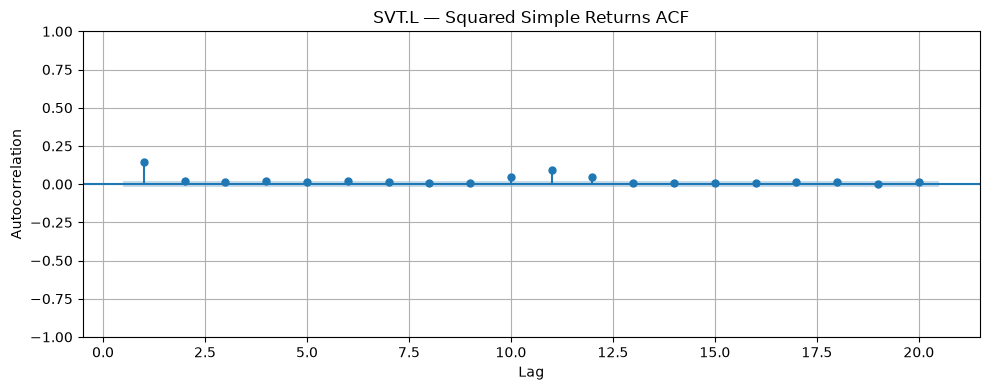

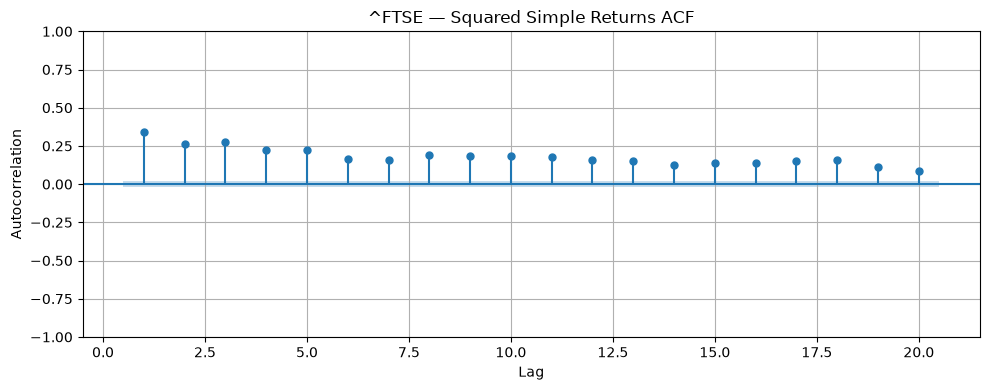

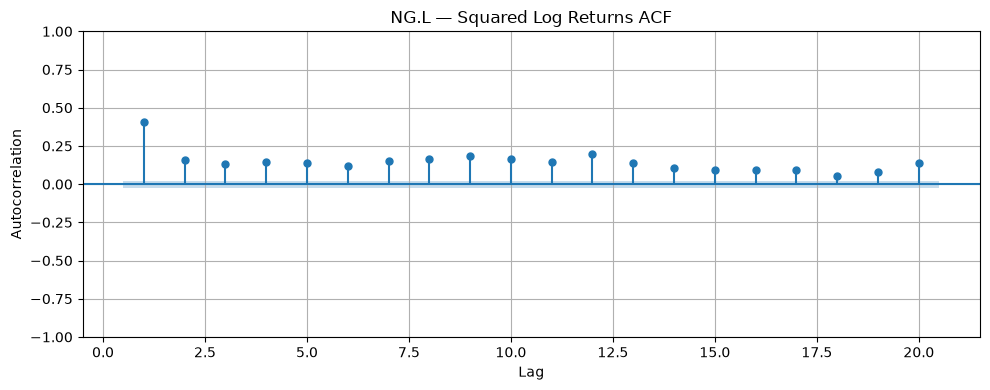

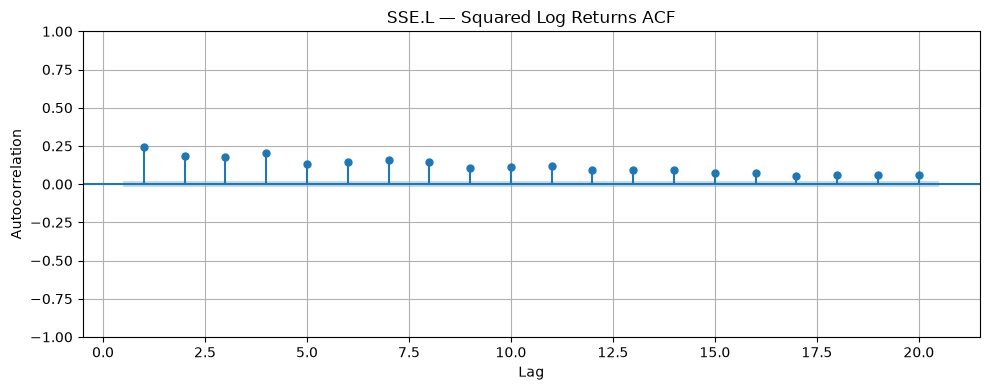

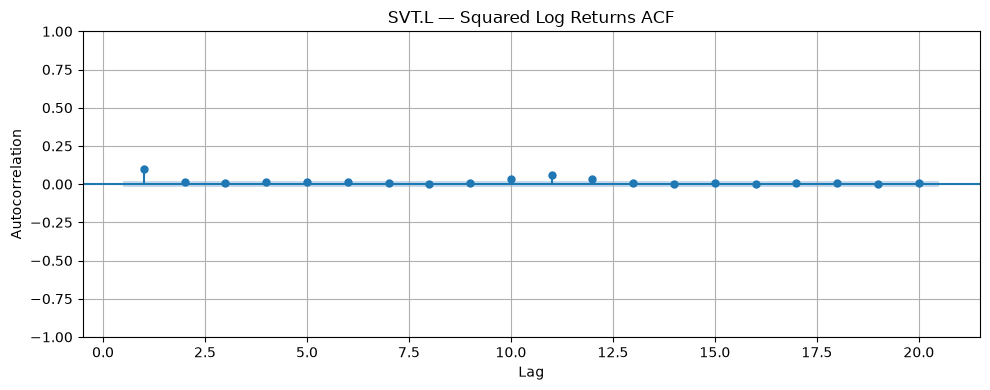

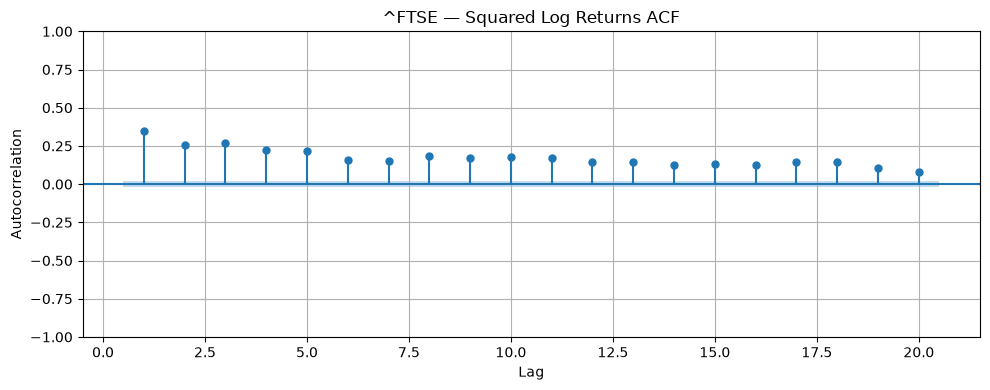

In [434]:
# Plot ACF of squared returns

from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

for return_type, returns_df in squared_return_series.items():

    for asset in returns_df.columns:

        series = returns_df[asset].dropna()

        fig, ax = plt.subplots(figsize=(10, 4))

        plot_acf(
            series,
            lags=SQUARED_ACF_MAX_LAGS,
            alpha=SQUARED_ACF_ALPHA,
            bartlett_confint=False,
            zero=False,
            fft=False,
            ax=ax,
        )

        ax.set_title(
            f"{asset} — {return_type} ACF"
        )
        ax.set_xlabel("Lag")
        ax.set_ylabel("Autocorrelation")

        plt.tight_layout()
        plt.show()

In [435]:
# Apply Ljung-Box tests to squared returns

squared_ljung_box_results = []

for return_type, returns_df in squared_return_series.items():

    for asset in returns_df.columns:

        series = returns_df[asset].dropna()

        test_results = acorr_ljungbox(
            series,
            lags=LJUNG_BOX_LAGS,
            model_df=0,
            return_df=True,
        )

        for lag, result in test_results.iterrows():

            squared_ljung_box_results.append({
                "asset": asset,
                "return_type": return_type,
                "lag": int(lag),
                "observations": len(series),
                "lb_statistic": result["lb_stat"],
                "p_value": result["lb_pvalue"],
                "reject_null": (
                    result["lb_pvalue"] < LJUNG_BOX_ALPHA
                ),
            })

squared_ljung_box_results_df = pd.DataFrame(
    squared_ljung_box_results
)

print(
    f"Total tests: {len(squared_ljung_box_results_df)}"
)

display(squared_ljung_box_results_df)

Total tests: 32


,asset,return_type,lag,observations,lb_statistic,p_value,reject_null
0,NG.L,Squared Simple Returns,5,7888,1925.42785798,0.00000000,True
1,NG.L,Squared Simple Returns,10,7888,2914.32700467,0.00000000,True
2,NG.L,Squared Simple Returns,15,7888,3699.03252601,0.00000000,True
3,NG.L,Squared Simple Returns,20,7888,4070.50533814,0.00000000,True
4,SSE.L,Squared Simple Returns,5,9058,1489.84541020,0.00000000,True
5,SSE.L,Squared Simple Returns,10,9058,2240.13716450,0.00000000,True
6,SSE.L,Squared Simple Returns,15,9058,2611.88621422,0.00000000,True
7,SSE.L,Squared Simple Returns,20,9058,2769.95179161,0.00000000,True
8,SVT.L,Squared Simple Returns,5,9453,212.52318816,0.00000000,True
9,SVT.L,Squared Simple Returns,10,9453,240.71357160,0.00000000,True


In [436]:
# Apply multiple-testing corrections to squared-return Ljung-Box tests

from statsmodels.stats.multitest import multipletests

squared_ljung_box_corrected_df = (
    squared_ljung_box_results_df.copy()
)

bonferroni_results = multipletests(
    squared_ljung_box_corrected_df["p_value"],
    alpha=LJUNG_BOX_ALPHA,
    method="bonferroni",
)

holm_results = multipletests(
    squared_ljung_box_corrected_df["p_value"],
    alpha=LJUNG_BOX_ALPHA,
    method="holm",
)

squared_ljung_box_corrected_df["bonferroni_p_value"] = (
    bonferroni_results[1]
)

squared_ljung_box_corrected_df["bonferroni_reject"] = (
    bonferroni_results[0]
)

squared_ljung_box_corrected_df["holm_p_value"] = (
    holm_results[1]
)

squared_ljung_box_corrected_df["holm_reject"] = (
    holm_results[0]
)

display(
    squared_ljung_box_corrected_df[
        [
            "asset",
            "return_type",
            "lag",
            "p_value",
            "bonferroni_p_value",
            "bonferroni_reject",
            "holm_p_value",
            "holm_reject",
        ]
    ]
)

,asset,return_type,lag,p_value,bonferroni_p_value,bonferroni_reject,holm_p_value,holm_reject
0,NG.L,Squared Simple Returns,5,0.00000000,0.00000000,True,0.00000000,True
1,NG.L,Squared Simple Returns,10,0.00000000,0.00000000,True,0.00000000,True
2,NG.L,Squared Simple Returns,15,0.00000000,0.00000000,True,0.00000000,True
3,NG.L,Squared Simple Returns,20,0.00000000,0.00000000,True,0.00000000,True
4,SSE.L,Squared Simple Returns,5,0.00000000,0.00000000,True,0.00000000,True
5,SSE.L,Squared Simple Returns,10,0.00000000,0.00000000,True,0.00000000,True
6,SSE.L,Squared Simple Returns,15,0.00000000,0.00000000,True,0.00000000,True
7,SSE.L,Squared Simple Returns,20,0.00000000,0.00000000,True,0.00000000,True
8,SVT.L,Squared Simple Returns,5,0.00000000,0.00000000,True,0.00000000,True
9,SVT.L,Squared Simple Returns,10,0.00000000,0.00000000,True,0.00000000,True


### Squared-Return Autocorrelation Findings

The autocorrelation analysis of squared simple and logarithmic returns provides evidence of temporal dependence in return magnitudes across all four assets.

NG.L, SSE.L and the FTSE exhibit relatively strong and persistent autocorrelation. SVT.L displays substantially weaker autocorrelation, although its Ljung-Box tests remain statistically significant.

All 32 Ljung-Box tests reject the null hypothesis at the 5% significance level. These findings remain significant after both Bonferroni and Holm multiple-testing corrections.

The results are consistent with volatility clustering, suggesting that periods of larger return magnitudes may be followed by further periods of elevated return magnitudes.

These findings do not establish predictive value, causality or the suitability of a specific volatility model. The conventional Ljung-Box test also relies on an asymptotic approximation, which should be interpreted cautiously given the potentially heavy-tailed distribution of squared returns.

The analysis is exploratory and does not constitute evidence of a profitable trading opportunity.

### 12.8 Rolling Autocorrelation Analysis

This section investigates whether return autocorrelation and volatility-related dependence remain stable over time or vary across different market periods.

Rolling Autocorrelation Functions (ACF) will be calculated using squared simple and logarithmic returns. This approach helps identify changes in the persistence of return magnitudes and provides further evidence of potential volatility clustering.

The analysis will use a rolling window of 504 valid observations, advanced in steps of 21 observations, with autocorrelation evaluated over 20 lags.

The results will be compared across the four assets to identify differences in temporal dependence and potential changes in market behaviour.

**Methodological considerations:**
- Missing observations will be excluded without imputation.
- Each rolling window will contain 504 valid observations, which may not represent consecutive trading sessions.
- Rolling windows overlap and are therefore statistically dependent.
- Results are exploratory and do not establish structural breaks, predictive power or the suitability of a specific volatility model.

In [437]:
# Prepare rolling windows for squared-return autocorrelation analysis

ROLLING_ACF_WINDOW = 504
ROLLING_ACF_STEP = 21
ROLLING_ACF_MAX_LAGS = 20

squared_return_rolling_windows = {}

for return_type, returns_df in squared_return_series.items():

    squared_return_rolling_windows[return_type] = {}

    for asset in returns_df.columns:

        clean_series = returns_df[asset].dropna().copy()

        asset_windows = []

        for end_position in range(
            ROLLING_ACF_WINDOW,
            len(clean_series) + 1,
            ROLLING_ACF_STEP,
        ):

            start_position = end_position - ROLLING_ACF_WINDOW

            window = clean_series.iloc[
                start_position:end_position
            ].copy()

            asset_windows.append({
                "window_number": len(asset_windows) + 1,
                "start_date": window.index[0],
                "end_date": window.index[-1],
                "observations": len(window),
                "data": window,
            })

        squared_return_rolling_windows[return_type][asset] = (
            asset_windows
        )

print("Rolling windows prepared successfully.")

Rolling windows prepared successfully.


In [438]:
# Validate rolling window construction

rolling_acf_window_validation = []

for return_type, asset_dict in squared_return_rolling_windows.items():

    for asset, windows in asset_dict.items():

        rolling_acf_window_validation.append({
            "return_type": return_type,
            "asset": asset,
            "number_of_windows": len(windows),
            "window_size_valid": all(
                len(window["data"]) == ROLLING_ACF_WINDOW
                for window in windows
            ),
            "dates_valid": all(
                window["start_date"] <= window["end_date"]
                for window in windows
            ),
        })

rolling_acf_window_validation_df = pd.DataFrame(
    rolling_acf_window_validation
)

display(rolling_acf_window_validation_df)

,return_type,asset,number_of_windows,window_size_valid,dates_valid
0,Squared Simple Returns,NG.L,352,True,True
1,Squared Simple Returns,SSE.L,408,True,True
2,Squared Simple Returns,SVT.L,427,True,True
3,Squared Simple Returns,^FTSE,485,True,True
4,Squared Log Returns,NG.L,352,True,True
5,Squared Log Returns,SSE.L,408,True,True
6,Squared Log Returns,SVT.L,427,True,True
7,Squared Log Returns,^FTSE,485,True,True


In [439]:
# Calculate rolling ACF for squared returns

rolling_squared_acf_results = []

for return_type, asset_dict in squared_return_rolling_windows.items():

    for asset, windows in asset_dict.items():

        for window in windows:

            acf_result = acf(
                window["data"],
                nlags=ROLLING_ACF_MAX_LAGS,
                fft=False,
                missing="none",
            )

            rolling_squared_acf_results.append({
                "asset": asset,
                "return_type": return_type,
                "window_number": window["window_number"],
                "start_date": window["start_date"],
                "end_date": window["end_date"],
                "observations": window["observations"],
                "acf_lag_1": acf_result[1],
                "acf_lag_5": acf_result[5],
                "acf_lag_10": acf_result[10],
                "acf_lag_20": acf_result[20],
            })

rolling_squared_acf_df = pd.DataFrame(
    rolling_squared_acf_results
)

print(
    f"Total rolling ACF observations: "
    f"{len(rolling_squared_acf_df)}"
)

display(rolling_squared_acf_df.head(10))

Total rolling ACF observations: 3344


,asset,return_type,window_number,start_date,end_date,observations,acf_lag_1,acf_lag_5,acf_lag_10,acf_lag_20
0,NG.L,Squared Simple Returns,1,1995-12-12,1997-11-14,504,0.02596203,0.03833897,0.02845323,-0.01030818
1,NG.L,Squared Simple Returns,2,1996-01-10,1997-12-15,504,0.02005512,0.02684157,0.01858444,0.02250295
2,NG.L,Squared Simple Returns,3,1996-02-08,1998-01-13,504,-0.01180853,0.02041985,0.01219234,0.00374224
3,NG.L,Squared Simple Returns,4,1996-03-08,1998-02-11,504,-0.00642201,0.01037866,0.00777585,0.05427435
4,NG.L,Squared Simple Returns,5,1996-04-08,1998-03-12,504,-0.00937689,0.00895231,0.00889030,0.04931850
5,NG.L,Squared Simple Returns,6,1996-05-07,1998-04-10,504,-0.00687551,0.00463496,0.00434241,0.04871926
6,NG.L,Squared Simple Returns,7,1996-06-05,1998-05-11,504,-0.00649839,0.00733366,0.00522281,0.04596458
7,NG.L,Squared Simple Returns,8,1996-07-04,1998-06-09,504,-0.00727992,0.00956707,0.00658272,0.04669530
8,NG.L,Squared Simple Returns,9,1996-08-02,1998-07-08,504,-0.00683427,0.00641459,0.00384780,0.04072780
9,NG.L,Squared Simple Returns,10,1996-09-02,1998-08-06,504,-0.00560467,0.00817292,0.00361916,0.03824279


In [440]:
# Validate rolling ACF results

rolling_acf_validation = {
    "expected_rows": sum(
        len(windows)
        for asset_dict in squared_return_rolling_windows.values()
        for windows in asset_dict.values()
    ),
    "actual_rows": len(rolling_squared_acf_df),
    "missing_values": rolling_squared_acf_df.isna().sum().sum(),
    "infinite_values": np.isinf(
        rolling_squared_acf_df[
            ["acf_lag_1", "acf_lag_5", "acf_lag_10", "acf_lag_20"]
        ].to_numpy()
    ).sum(),
    "duplicate_window_identifiers": rolling_squared_acf_df.duplicated(
        subset=[
            "asset",
            "return_type",
            "window_number",
        ]
    ).sum(),
    "valid_window_sizes": (
        rolling_squared_acf_df["observations"] == ROLLING_ACF_WINDOW
    ).all(),
    "valid_date_order": (
        rolling_squared_acf_df["start_date"]
        <= rolling_squared_acf_df["end_date"]
    ).all(),
}

display(pd.Series(rolling_acf_validation))

expected_rows                   3344
actual_rows                     3344
missing_values                     0
infinite_values                    0
duplicate_window_identifiers       0
valid_window_sizes              True
valid_date_order                True
dtype: object

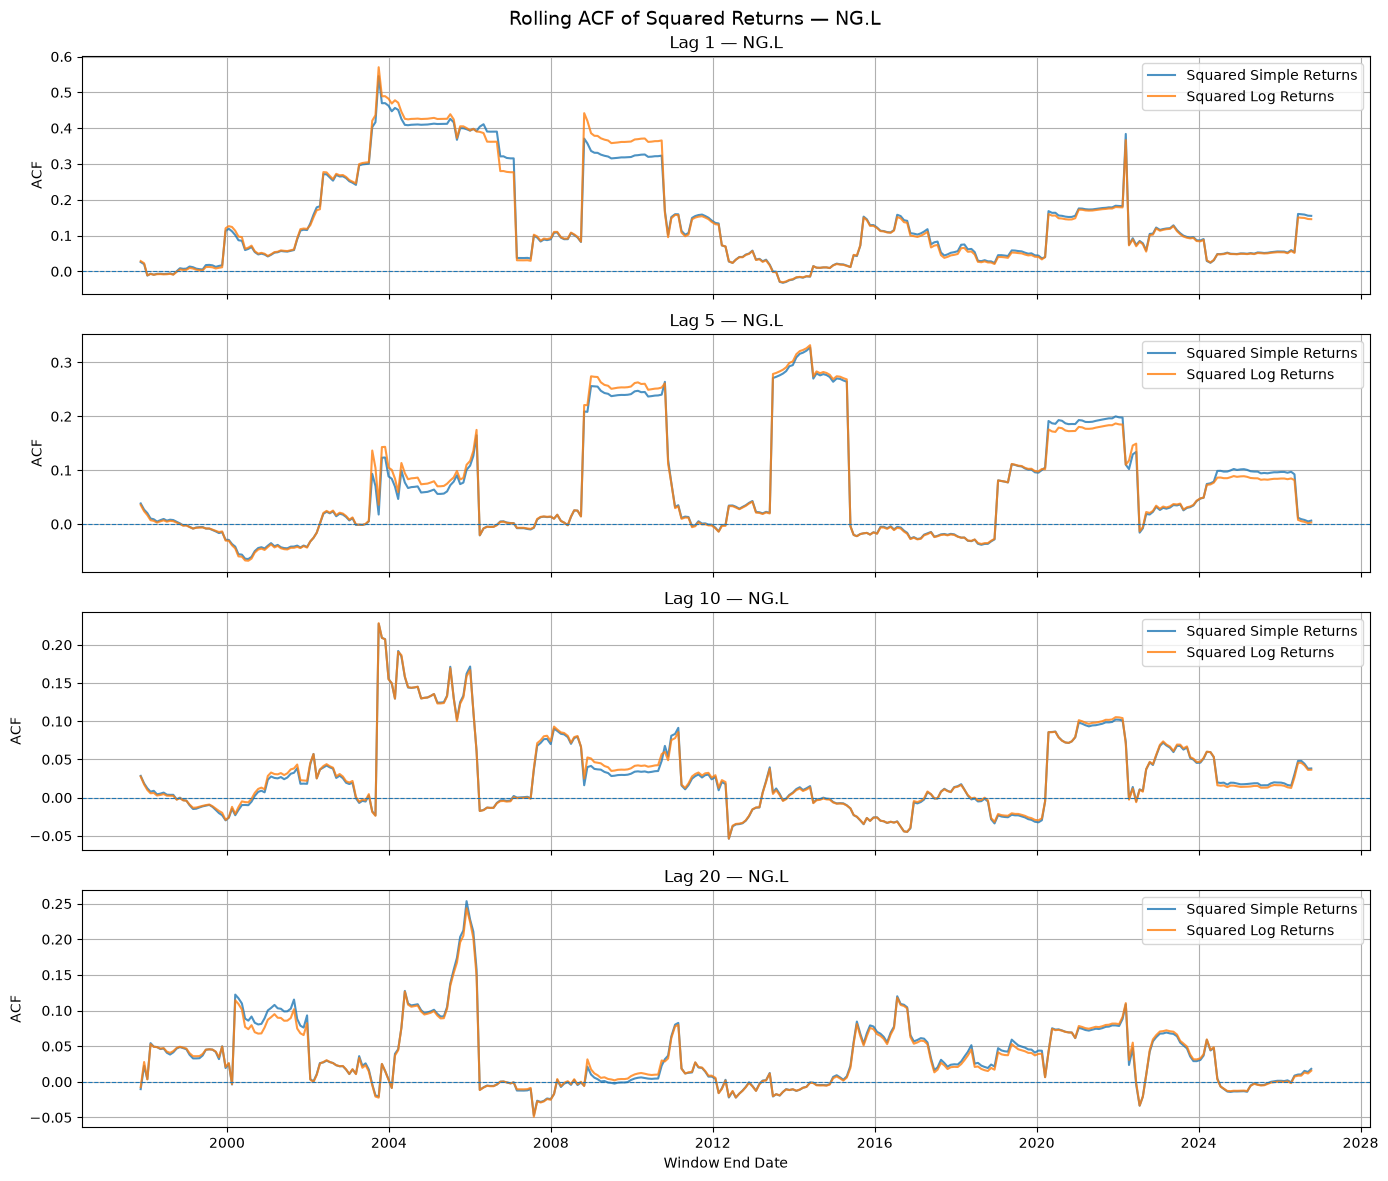

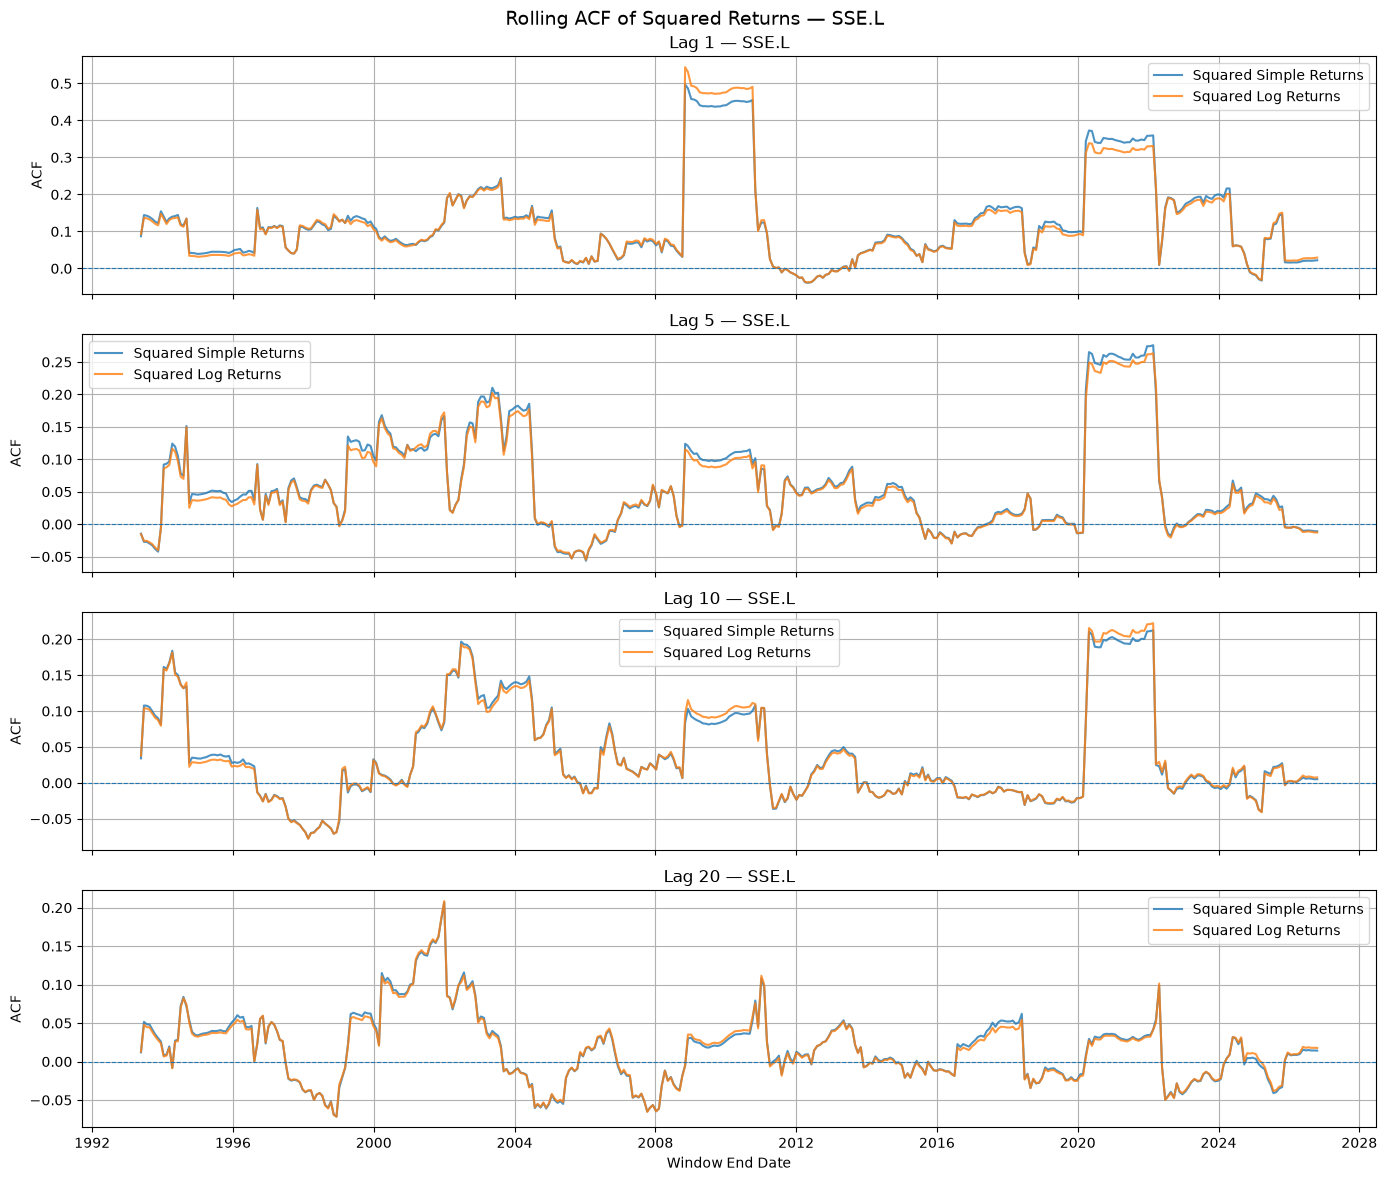

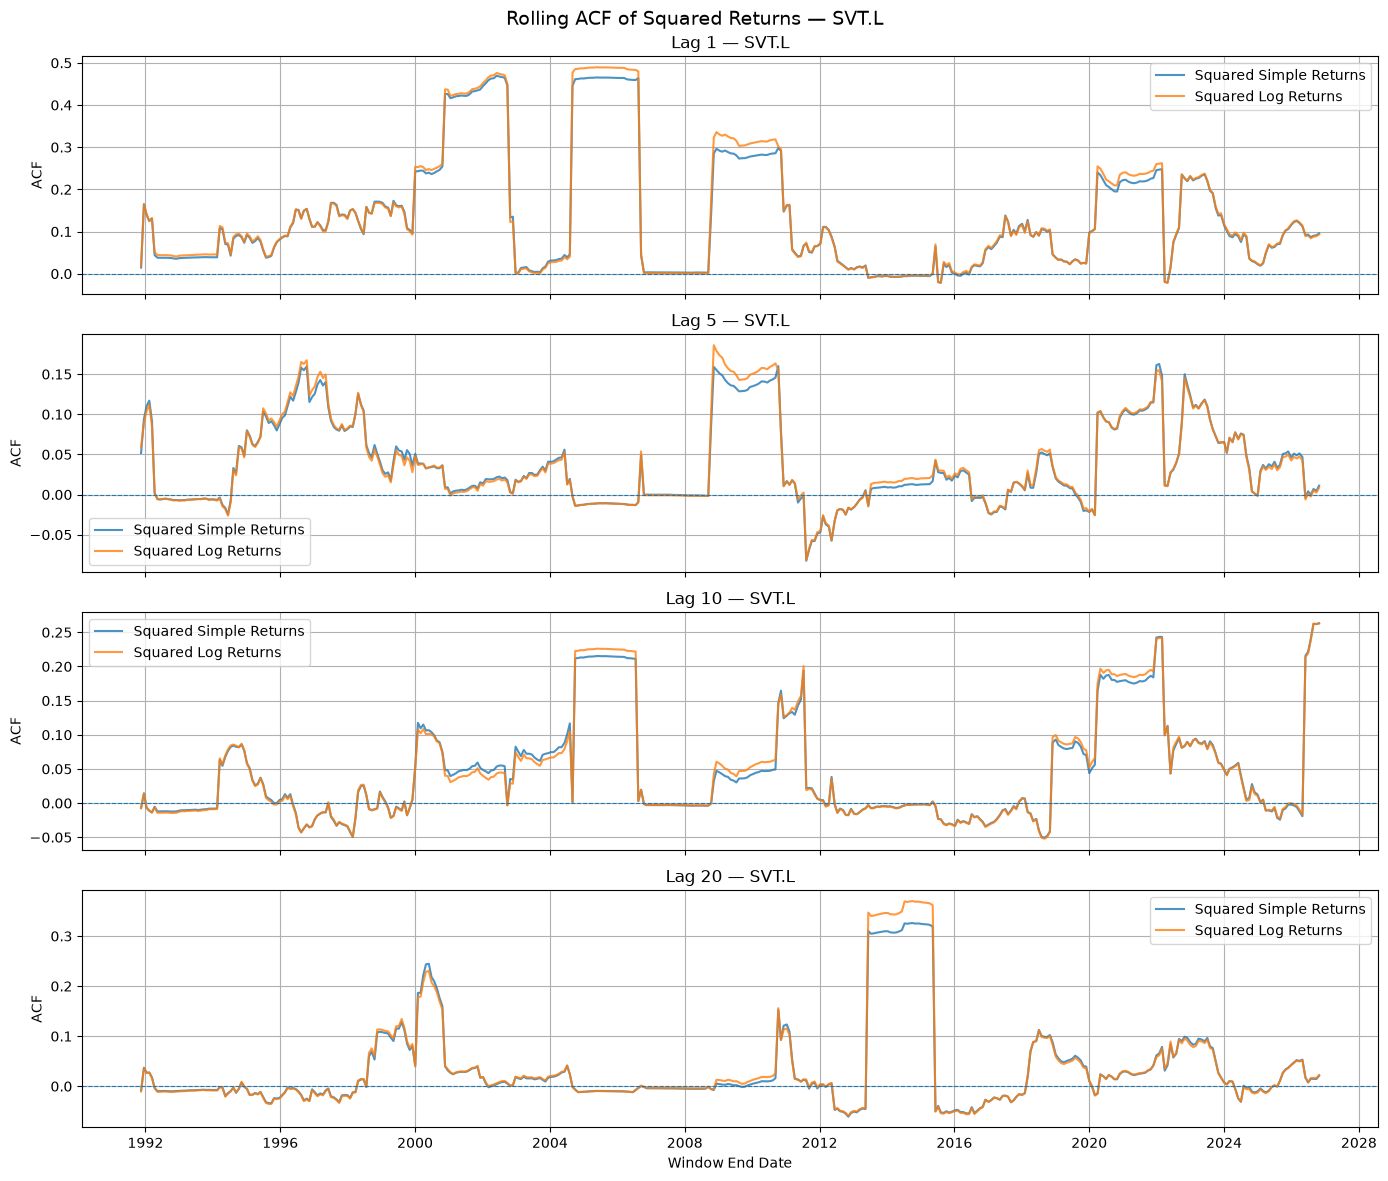

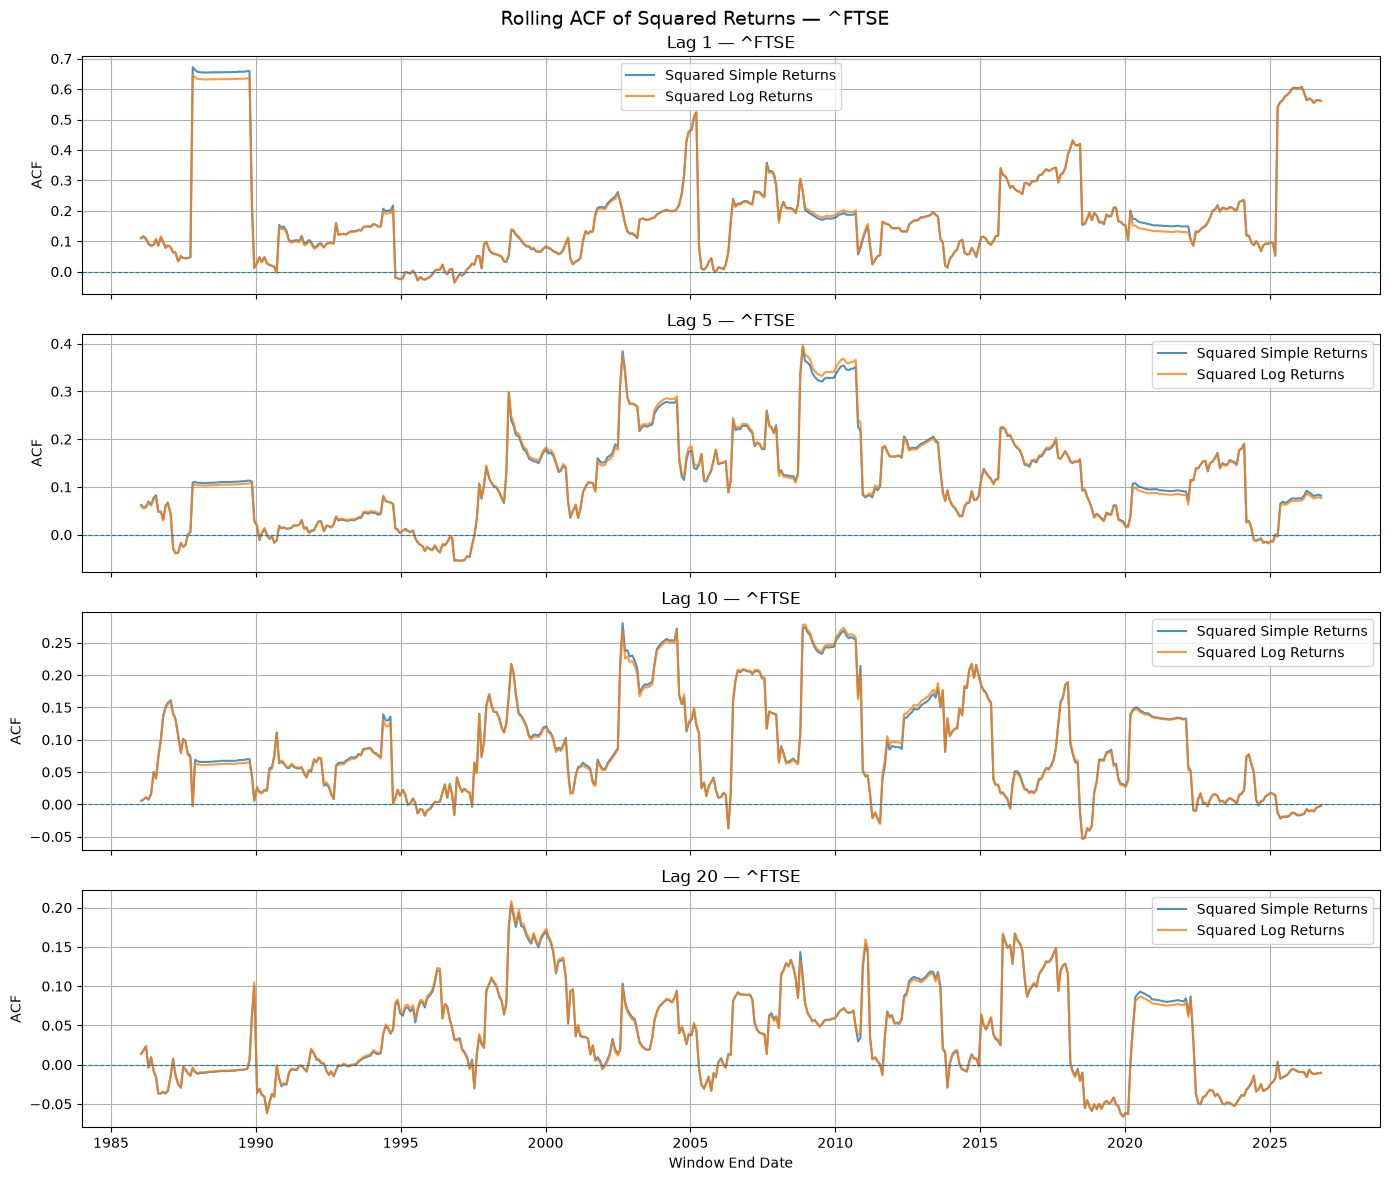

In [441]:
# Plot rolling autocorrelation of squared returns

acf_lags = {
    "acf_lag_1": "Lag 1",
    "acf_lag_5": "Lag 5",
    "acf_lag_10": "Lag 10",
    "acf_lag_20": "Lag 20",
}

for asset in squared_return_series["Squared Simple Returns"].columns:

    fig, axes = plt.subplots(
        nrows=4,
        ncols=1,
        figsize=(14, 12),
        sharex=True,
    )

    for ax, (column, title) in zip(axes, acf_lags.items()):

        for return_type in squared_return_rolling_windows:

            asset_results = rolling_squared_acf_df[
                (rolling_squared_acf_df["asset"] == asset)
                & (rolling_squared_acf_df["return_type"] == return_type)
            ]

            ax.plot(
                asset_results["end_date"],
                asset_results[column],
                label=return_type,
                alpha=0.8,
            )

        ax.axhline(0, linestyle="--", linewidth=0.8)
        ax.set_title(f"{title} — {asset}")
        ax.set_ylabel("ACF")
        ax.legend()

    axes[-1].set_xlabel("Window End Date")

    fig.suptitle(
        f"Rolling ACF of Squared Returns — {asset}",
        fontsize=14,
    )

    plt.tight_layout()
    plt.show()

In [442]:
# Summarise rolling autocorrelation distributions

rolling_acf_summary = (
    rolling_squared_acf_df
    .groupby(["asset", "return_type"])
    .agg(
        windows=("window_number", "count"),

        lag_1_mean=("acf_lag_1", "mean"),
        lag_1_std=("acf_lag_1", "std"),
        lag_1_median=("acf_lag_1", "median"),
        lag_1_min=("acf_lag_1", "min"),
        lag_1_max=("acf_lag_1", "max"),

        lag_5_mean=("acf_lag_5", "mean"),
        lag_10_mean=("acf_lag_10", "mean"),
        lag_20_mean=("acf_lag_20", "mean"),
    )
    .reset_index()
)

display(rolling_acf_summary.round(4))

,asset,return_type,windows,lag_1_mean,lag_1_std,lag_1_median,lag_1_min,lag_1_max,lag_5_mean,lag_10_mean,lag_20_mean
0,NG.L,Squared Log Returns,352,0.14420000,0.14090000,0.09680000,-0.03050000,0.57020000,0.06770000,0.03070000,0.03490000
1,NG.L,Squared Simple Returns,352,0.14230000,0.13400000,0.09770000,-0.03190000,0.54530000,0.06690000,0.02980000,0.03590000
2,SSE.L,Squared Log Returns,408,0.12480000,0.12060000,0.10280000,-0.03770000,0.54390000,0.05710000,0.03770000,0.01650000
3,SSE.L,Squared Simple Returns,408,0.12670000,0.11750000,0.10410000,-0.03880000,0.49730000,0.06050000,0.03740000,0.01710000
4,SVT.L,Squared Log Returns,427,0.14330000,0.14660000,0.09440000,-0.02160000,0.48980000,0.03940000,0.04640000,0.03520000
5,SVT.L,Squared Simple Returns,427,0.13800000,0.14000000,0.09340000,-0.02150000,0.46950000,0.03810000,0.04570000,0.03290000
6,^FTSE,Squared Log Returns,485,0.18390000,0.16210000,0.14340000,-0.03460000,0.64570000,0.11730000,0.08860000,0.03860000
7,^FTSE,Squared Simple Returns,485,0.18590000,0.16540000,0.15080000,-0.03660000,0.67190000,0.11700000,0.08910000,0.03850000


### Rolling Autocorrelation Findings

The rolling ACF analysis indicates substantial variation in squared-return autocorrelation across time and assets.

The FTSE exhibits the highest average lag-1 autocorrelation (0.1859), followed by NG.L (0.1423), SVT.L (0.1380) and SSE.L (0.1267), based on squared simple returns.

All four assets display considerable temporal variability, with maximum rolling lag-1 autocorrelations ranging from approximately 0.47 to 0.67.

The results also reveal that full-sample statistics can conceal periods of elevated autocorrelation, particularly for SVT.L. This supports the use of rolling analysis to investigate changes in temporal dependence.

Squared simple and logarithmic returns produce broadly similar results, supporting the robustness of the observed patterns across both representations.

However, overlapping windows generate dependent observations, and the rolling ACF coefficients do not constitute formal tests of structural breaks or changes in volatility regimes. The findings are exploratory and do not establish predictive power or trading opportunities.

### 12.9 Cross-Asset Autocorrelation Comparison

This section compares autocorrelation patterns across NG.L, SSE.L, SVT.L and the FTSE index.

The comparison brings together the full-sample ACF and PACF results, Ljung-Box tests, squared-return autocorrelation and rolling ACF findings.

The objective is to identify differences in linear return dependence and temporal dependence in return magnitudes across assets.

Simple and logarithmic returns will be compared to assess the consistency of the findings.

The analysis is descriptive and comparative. Statistical significance does not necessarily imply economic relevance, predictive value or an exploitable trading opportunity.

In [443]:
# Compare full-sample ACF and PACF significance across assets

acf_pacf_comparison = pd.DataFrame([
    {
        "asset": "NG.L",
        "acf_log_significant": 9,
        "acf_simple_significant": 9,
        "pacf_log_significant": 9,
        "pacf_simple_significant": 9,
    },
    {
        "asset": "SSE.L",
        "acf_log_significant": 4,
        "acf_simple_significant": 4,
        "pacf_log_significant": 4,
        "pacf_simple_significant": 5,
    },
    {
        "asset": "SVT.L",
        "acf_log_significant": 6,
        "acf_simple_significant": 6,
        "pacf_log_significant": 8,
        "pacf_simple_significant": 8,
    },
    {
        "asset": "^FTSE",
        "acf_log_significant": 8,
        "acf_simple_significant": 8,
        "pacf_log_significant": 7,
        "pacf_simple_significant": 7,
    },
])

display(acf_pacf_comparison)

,asset,acf_log_significant,acf_simple_significant,pacf_log_significant,pacf_simple_significant
0,NG.L,9,9,9,9
1,SSE.L,4,4,4,5
2,SVT.L,6,6,8,8
3,^FTSE,8,8,7,7


In [444]:
# Summarise Ljung-Box results for raw returns

raw_ljung_box_comparison = (
    ljung_box_results_df
    .groupby(["asset", "return_type"])
    .agg(
        total_tests=("reject_null", "count"),
        significant_tests=("reject_null", "sum"),
        minimum_p_value=("p_value", "min"),
        maximum_statistic=("lb_statistic", "max"),
    )
    .reset_index()
)

display(raw_ljung_box_comparison.round(6))

,asset,return_type,total_tests,significant_tests,minimum_p_value,maximum_statistic
0,NG.L,Log Returns,4,4,0.00000000,373.75019700
1,NG.L,Simple Returns,4,4,0.00000000,377.84506100
2,SSE.L,Log Returns,4,4,0.00001000,53.73810500
3,SSE.L,Simple Returns,4,4,0.00000500,55.86801300
4,SVT.L,Log Returns,4,4,0.00001200,58.47108300
5,SVT.L,Simple Returns,4,4,0.00000600,60.26063600
6,^FTSE,Log Returns,4,4,0.00000000,88.27171000
7,^FTSE,Simple Returns,4,4,0.00000000,91.45334100


In [445]:
# Compare full-sample squared-return autocorrelation

squared_acf_comparison = (
    squared_acf_results_df
    .groupby(["asset", "return_type"])
    .agg(
        significant_lags=("significant", "sum"),
        mean_absolute_acf=("acf", lambda x: x.abs().mean()),
        lag_1_acf=("acf", "first"),
        lag_5_acf=("acf", lambda x: x.iloc[4]),
        lag_10_acf=("acf", lambda x: x.iloc[9]),
        lag_20_acf=("acf", "last"),
    )
    .reset_index()
)

display(squared_acf_comparison.round(4))

,asset,return_type,significant_lags,mean_absolute_acf,lag_1_acf,lag_5_acf,lag_10_acf,lag_20_acf
0,NG.L,Squared Log Returns,20,0.14540000,0.40690000,0.13930000,0.16240000,0.13960000
1,NG.L,Squared Simple Returns,20,0.14500000,0.40070000,0.13080000,0.16420000,0.14200000
2,SSE.L,Squared Log Returns,20,0.11950000,0.24070000,0.12910000,0.11070000,0.06190000
3,SSE.L,Squared Simple Returns,20,0.11340000,0.23470000,0.12950000,0.10270000,0.06050000
4,SVT.L,Squared Log Returns,4,0.01750000,0.09990000,0.01140000,0.03300000,0.01050000
5,SVT.L,Squared Simple Returns,5,0.02600000,0.14540000,0.01720000,0.04870000,0.01580000
6,^FTSE,Squared Log Returns,20,0.17380000,0.34650000,0.21630000,0.17610000,0.08090000
7,^FTSE,Squared Simple Returns,20,0.18030000,0.33910000,0.22480000,0.18470000,0.08660000


In [446]:
# Compare Ljung-Box results for squared returns

squared_ljung_box_comparison = (
    squared_ljung_box_corrected_df
    .groupby(["asset", "return_type"])
    .agg(
        total_tests=("holm_reject", "count"),
        significant_tests=("holm_reject", "sum"),
        bonferroni_significant=("bonferroni_reject", "sum"),
        minimum_p_value=("p_value", "min"),
        maximum_statistic=("lb_statistic", "max"),
    )
    .reset_index()
)

display(squared_ljung_box_comparison.round(6))

,asset,return_type,total_tests,significant_tests,bonferroni_significant,minimum_p_value,maximum_statistic
0,NG.L,Squared Log Returns,4,4,4,0.00000000,4107.61776000
1,NG.L,Squared Simple Returns,4,4,4,0.00000000,4070.50533800
2,SSE.L,Squared Log Returns,4,4,4,0.00000000,3074.25289000
3,SSE.L,Squared Simple Returns,4,4,4,0.00000000,2769.95179200
4,SVT.L,Squared Log Returns,4,4,4,0.00000000,160.80206400
5,SVT.L,Squared Simple Returns,4,4,4,0.00000000,346.30492900
6,^FTSE,Squared Log Returns,4,4,4,0.00000000,7266.13490500
7,^FTSE,Squared Simple Returns,4,4,4,0.00000000,7689.13870100


In [447]:
# Compare rolling autocorrelation across assets

rolling_acf_comparison = (
    rolling_squared_acf_df
    .groupby(["asset", "return_type"])
    .agg(
        windows=("window_number", "count"),
        lag_1_mean=("acf_lag_1", "mean"),
        lag_1_std=("acf_lag_1", "std"),
        lag_1_median=("acf_lag_1", "median"),
        lag_1_min=("acf_lag_1", "min"),
        lag_1_max=("acf_lag_1", "max"),
        lag_5_mean=("acf_lag_5", "mean"),
        lag_10_mean=("acf_lag_10", "mean"),
        lag_20_mean=("acf_lag_20", "mean"),
    )
    .reset_index()
)

display(rolling_acf_comparison.round(4))

,asset,return_type,windows,lag_1_mean,lag_1_std,lag_1_median,lag_1_min,lag_1_max,lag_5_mean,lag_10_mean,lag_20_mean
0,NG.L,Squared Log Returns,352,0.14420000,0.14090000,0.09680000,-0.03050000,0.57020000,0.06770000,0.03070000,0.03490000
1,NG.L,Squared Simple Returns,352,0.14230000,0.13400000,0.09770000,-0.03190000,0.54530000,0.06690000,0.02980000,0.03590000
2,SSE.L,Squared Log Returns,408,0.12480000,0.12060000,0.10280000,-0.03770000,0.54390000,0.05710000,0.03770000,0.01650000
3,SSE.L,Squared Simple Returns,408,0.12670000,0.11750000,0.10410000,-0.03880000,0.49730000,0.06050000,0.03740000,0.01710000
4,SVT.L,Squared Log Returns,427,0.14330000,0.14660000,0.09440000,-0.02160000,0.48980000,0.03940000,0.04640000,0.03520000
5,SVT.L,Squared Simple Returns,427,0.13800000,0.14000000,0.09340000,-0.02150000,0.46950000,0.03810000,0.04570000,0.03290000
6,^FTSE,Squared Log Returns,485,0.18390000,0.16210000,0.14340000,-0.03460000,0.64570000,0.11730000,0.08860000,0.03860000
7,^FTSE,Squared Simple Returns,485,0.18590000,0.16540000,0.15080000,-0.03660000,0.67190000,0.11700000,0.08910000,0.03850000


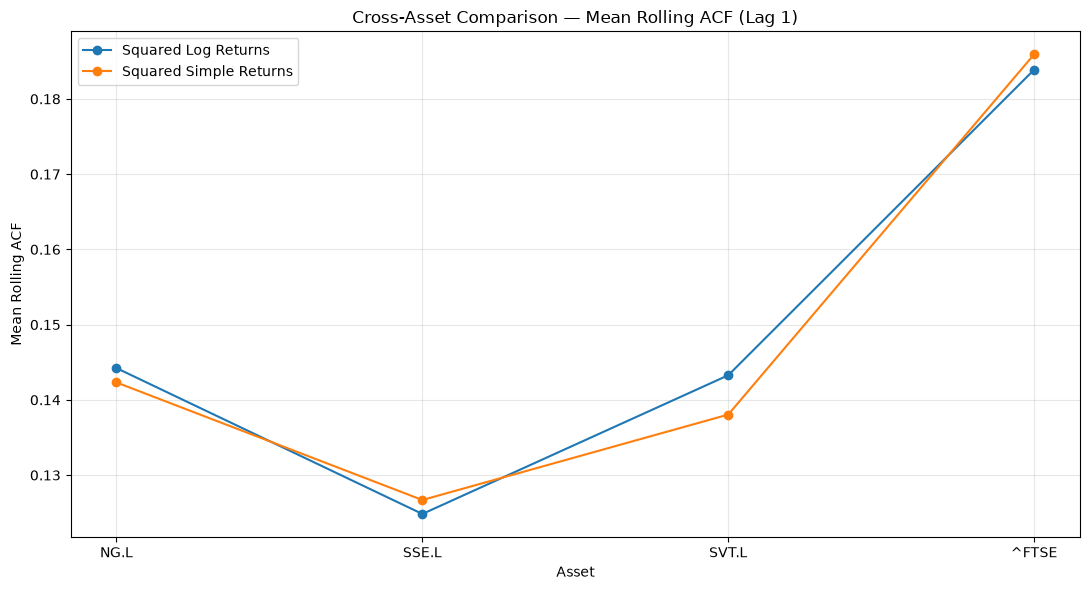

In [448]:
# Plot cross-asset rolling autocorrelation comparison

fig, ax = plt.subplots(figsize=(11, 6))

for return_type in rolling_acf_comparison["return_type"].unique():

    plot_data = rolling_acf_comparison[
        rolling_acf_comparison["return_type"] == return_type
    ]

    ax.plot(
        plot_data["asset"],
        plot_data["lag_1_mean"],
        marker="o",
        label=return_type,
    )

ax.set_title("Cross-Asset Comparison — Mean Rolling ACF (Lag 1)")
ax.set_xlabel("Asset")
ax.set_ylabel("Mean Rolling ACF")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [449]:
# Build consolidated cross-asset autocorrelation summary

raw_acf_summary = acf_pacf_comparison.copy()

raw_acf_summary["acf_significant_mean"] = (
    raw_acf_summary[
        ["acf_log_significant", "acf_simple_significant"]
    ].mean(axis=1)
)

raw_acf_summary["pacf_significant_mean"] = (
    raw_acf_summary[
        ["pacf_log_significant", "pacf_simple_significant"]
    ].mean(axis=1)
)

squared_rolling_summary = (
    rolling_acf_comparison[
        rolling_acf_comparison["return_type"]
        == "Squared Simple Returns"
    ][
        [
            "asset",
            "lag_1_mean",
            "lag_1_std",
            "lag_1_max",
        ]
    ]
)

cross_asset_summary = raw_acf_summary.merge(
    squared_rolling_summary,
    on="asset",
    how="inner",
)

cross_asset_summary = cross_asset_summary.rename(
    columns={
        "lag_1_mean": "rolling_squared_acf_mean",
        "lag_1_std": "rolling_squared_acf_std",
        "lag_1_max": "rolling_squared_acf_max",
    }
)

display(cross_asset_summary.round(4))

,asset,acf_log_significant,acf_simple_significant,pacf_log_significant,pacf_simple_significant,acf_significant_mean,pacf_significant_mean,rolling_squared_acf_mean,rolling_squared_acf_std,rolling_squared_acf_max
0,NG.L,9,9,9,9,9.00000000,9.00000000,0.14230000,0.13400000,0.54530000
1,SSE.L,4,4,4,5,4.00000000,4.50000000,0.12670000,0.11750000,0.49730000
2,SVT.L,6,6,8,8,6.00000000,8.00000000,0.13800000,0.14000000,0.46950000
3,^FTSE,8,8,7,7,8.00000000,7.00000000,0.18590000,0.16540000,0.67190000


### Cross-Asset Autocorrelation Comparison — Findings

The comparison across NG.L, SSE.L, SVT.L and the FTSE index reveals differences in both return autocorrelation and dependence in squared returns.

- **Raw returns:** ACF and PACF results indicate different levels of serial dependence across assets. Ljung-Box tests reject the null hypothesis for all tested assets and return representations.
- **Squared returns:** All four assets exhibit statistically significant joint autocorrelation. The evidence is particularly strong for NG.L, SSE.L and the FTSE index, while SVT.L shows fewer individually significant ACF lags.
- **Rolling analysis:** The FTSE exhibits the highest mean rolling lag-1 autocorrelation in squared simple returns (0.1859), followed by NG.L (0.1423), SVT.L (0.1380) and SSE.L (0.1267).
- **Temporal variation:** Rolling results reveal substantial changes in autocorrelation over time, indicating that full-sample statistics do not fully describe the underlying dependence structure.
- **Return representation:** Simple and logarithmic returns produce broadly similar results.

These findings are consistent with time-varying dependence in return magnitudes and volatility clustering. However, statistical significance does not establish forecasting value or economic relevance.

The analysis compares individual autocorrelation structures across assets. It does not measure cross-asset correlation or lead-lag relationships.

Rolling windows overlap, and individual ACF confidence intervals are not adjusted for multiple testing. Results should therefore be interpreted as exploratory statistical evidence rather than independent or definitive tests.

## 12.10 Findings and Statistical Interpretation

### Main Findings

The autocorrelation analysis across NG.L, SSE.L, SVT.L and the FTSE index identifies two distinct forms of serial dependence.

**1. Autocorrelation in raw returns**

- ACF and PACF results reveal different autocorrelation patterns across the four assets.
- NG.L exhibits nine individually significant ACF lags, while SSE.L exhibits four, SVT.L six and the FTSE eight.
- Ljung-Box tests reject the null hypothesis of no joint autocorrelation for all 32 tests across the four assets, two return representations and four lag specifications.

**2. Autocorrelation in squared returns**

- Squared-return ACF results indicate substantial dependence in return magnitudes.
- NG.L, SSE.L and the FTSE exhibit significant individual ACF coefficients at all 20 examined lags for both return representations.
- SVT.L exhibits fewer significant lags: four for logarithmic returns and five for simple returns.
- All 32 squared-return Ljung-Box tests remain significant after Bonferroni and Holm corrections.

**3. Time-varying dependence**

Rolling analysis demonstrates that autocorrelation is not constant over time. Its magnitude varies considerably across historical periods and assets.

The highest mean rolling lag-1 autocorrelation in squared simple returns is observed for the FTSE (0.1859), followed by NG.L (0.1423), SVT.L (0.1380) and SSE.L (0.1267).

### Statistical Interpretation

The results provide evidence of serial dependence in both raw returns and squared returns.

Autocorrelation in raw returns indicates that historical returns are not entirely independent across time. However, statistical significance alone does not establish exploitable directional predictability.

The stronger and more persistent autocorrelation observed in squared returns is consistent with volatility clustering: periods of relatively large return magnitudes tend to be followed by further large movements, while quieter periods may also persist.

The rolling analysis additionally suggests that the strength of this dependence changes over time. Consequently, a single full-sample statistic may conceal important differences between market conditions.

These findings support further investigation of conditional volatility and market regimes. They do not, by themselves, establish a specific volatility process, prove forecastability or demonstrate that a trading strategy can exploit the observed patterns.

## 12.11 Limitations and Conclusions

### Limitations

The findings of this analysis should be interpreted in light of the following limitations:

- **Missing observations:** Missing values were excluded using `dropna()`. This compresses the time series, meaning that consecutive observations in the statistical calculations are not necessarily consecutive trading sessions.
- **Multiple testing:** Individual ACF and PACF confidence intervals are not adjusted for multiple comparisons. Ljung-Box tests were adjusted using Bonferroni and Holm procedures, but related return representations are not independent evidence.
- **Large sample sizes:** Large samples can make relatively small autocorrelation coefficients statistically significant. Statistical significance does not necessarily imply economic relevance.
- **Rolling windows:** The 504-observation windows overlap substantially and therefore are not independent. Rolling results are exploratory and should not be interpreted as independent statistical tests.
- **Time-varying behaviour:** Historical autocorrelation patterns may change across market conditions. Full-sample estimates may not represent future behaviour.
- **Model limitations:** No conditional volatility model, structural-break model or forecasting strategy was estimated in this section.

### Conclusions

The analysis identifies evidence of serial dependence in both raw returns and squared returns across NG.L, SSE.L, SVT.L and the FTSE index.

The squared-return results are particularly relevant because they indicate persistent dependence in return magnitudes, consistent with volatility clustering. Rolling analysis also demonstrates that the strength of this dependence varies considerably over time and across assets.

These findings provide a statistical foundation for investigating volatility dynamics, market regimes and potentially useful forecasting features in subsequent phases.

However, they do not establish predictive performance, trading profitability or the superiority of any particular model.

**Overall conclusion:** Financial returns in the analysed assets exhibit statistically significant serial dependence, particularly in their squared values. This evidence justifies further investigation, but any predictive or trading application must be validated through rigorous out-of-sample testing.

## 13. Volatility Analysis

### 13.1 Objective

The objective of this section is to investigate the volatility characteristics of the selected financial assets, focusing on rolling volatility and conditional heteroskedasticity.

The analysis examines whether return volatility remains constant over time or exhibits patterns consistent with volatility clustering.

### 13.2 Methodology

The analysis uses daily financial returns for NG.L, SSE.L, SVT.L and the FTSE index.

The following methodology was applied:

- Rolling standard deviation calculated using a 21-session window.
- Annualisation using 252 trading sessions per year.
- ARCH-LM test using 10 lags.
- ARCH F-test as an additional statistical diagnostic.

The ARCH-LM test evaluates the null hypothesis that there are no ARCH effects against the alternative hypothesis that conditional heteroskedasticity is present.

### 13.3 ARCH-LM Test Results

All four assets produced statistically significant ARCH-LM and ARCH F-test results.

| Asset | Observations | ARCH-LM Statistic | ARCH-LM p-value | ARCH F-statistic | ARCH F p-value |
|---|---:|---:|---:|---:|---:|
| NG.L | 7,888 | 1,561.37 | < 0.001 | 194.46 | < 0.001 |
| SSE.L | 9,058 | 1,067.83 | < 0.001 | 120.93 | < 0.001 |
| SVT.L | 9,453 | 109.98 | < 0.001 | 11.12 | < 0.001 |
| FTSE | 10,684 | 1,992.11 | < 0.001 | 244.67 | < 0.001 |

### 13.4 Statistical Interpretation

At the 5% significance level, the null hypothesis is rejected for all four assets.

The results provide strong statistical evidence of ARCH effects in the analysed return series.

The FTSE index exhibits the largest ARCH-LM statistic, followed by NG.L and SSE.L. SVT.L also presents statistically significant ARCH effects, although its test statistic is considerably smaller.

These findings are consistent with the volatility clustering patterns identified in Section 12, particularly the significant autocorrelation observed in squared returns.

The results suggest that return volatility may be time-dependent rather than constant.

### 13.5 Limitations

The following limitations must be considered:

- Statistical significance does not establish that volatility can be reliably forecast.
- ARCH effects do not automatically imply that a GARCH model is the most appropriate specification.
- The ARCH-LM test should ideally be applied to residuals from an appropriately specified conditional mean model. Testing raw returns may be affected by the autocorrelation identified in Section 12.
- The 21-session rolling window and the annualisation factor of 252 are methodological conventions, not optimised parameters.
- The analysis does not establish that volatility-related information provides predictive or trading value.
- Historical relationships may change across market regimes.

### 13.6 Conclusions

The volatility analysis identifies statistically significant ARCH effects across all four analysed assets.

Together with the squared-return autocorrelation results from Section 12, the findings provide evidence consistent with volatility clustering and time-varying conditional variance.

These results justify retaining volatility as an important dimension for subsequent quantitative research.

However, no conclusion is drawn regarding the predictive superiority of ARCH/GARCH models or their potential trading performance.

Further investigation may consider alternative conditional volatility specifications, subject to appropriate model diagnostics and out-of-sample validation.


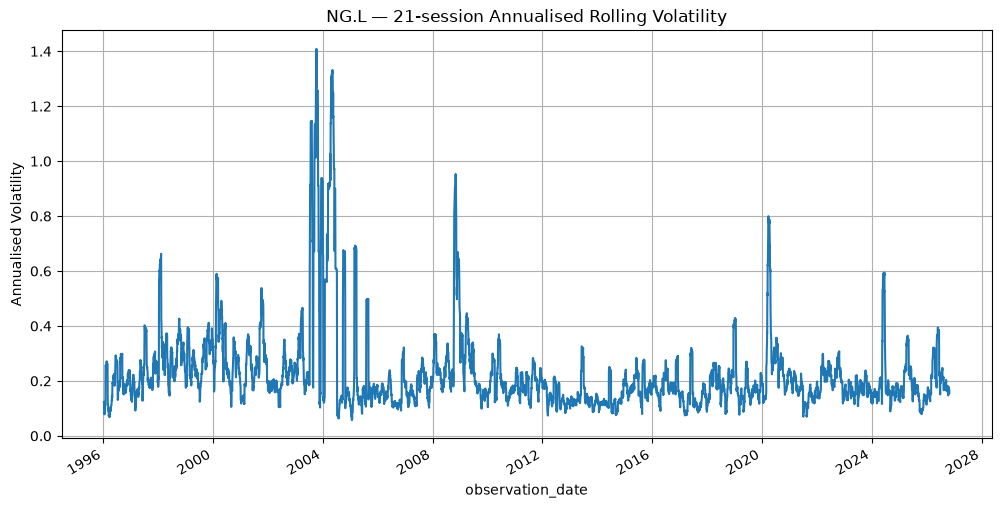

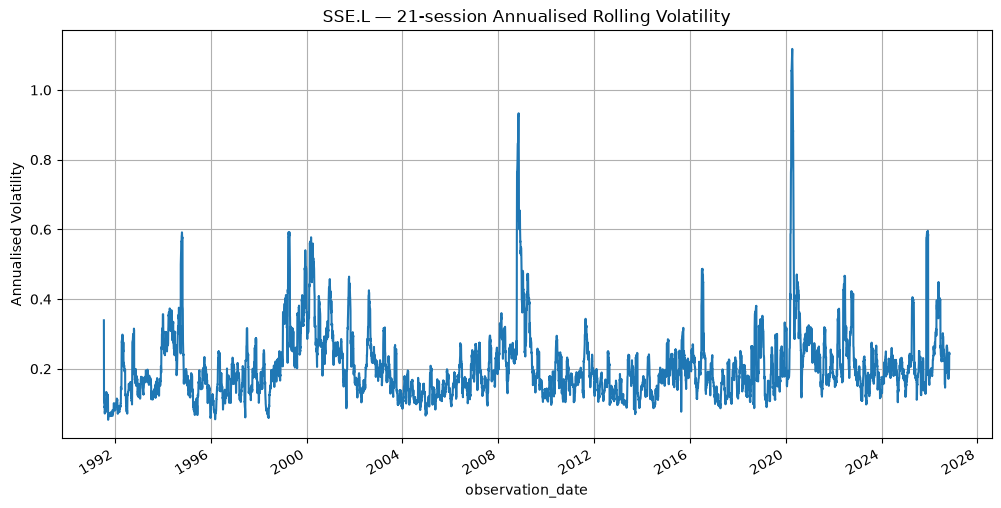

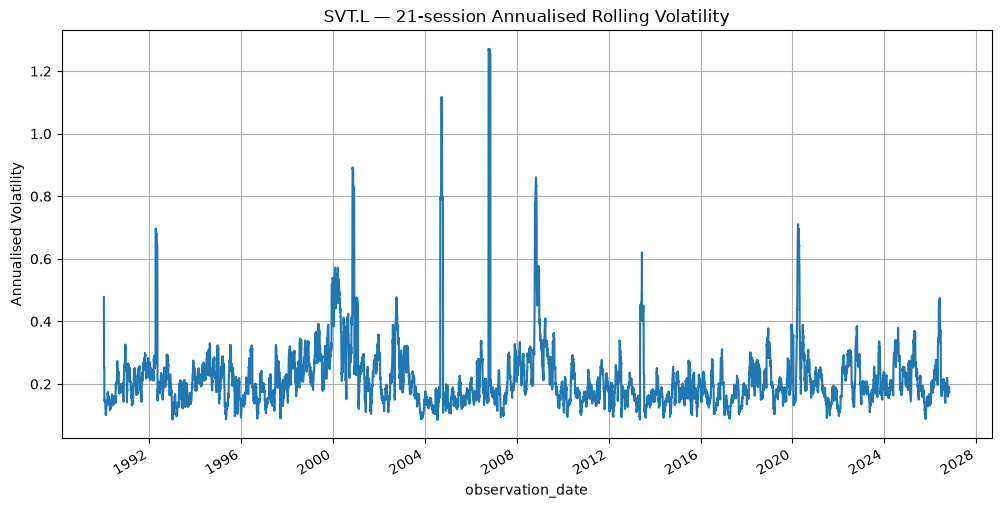

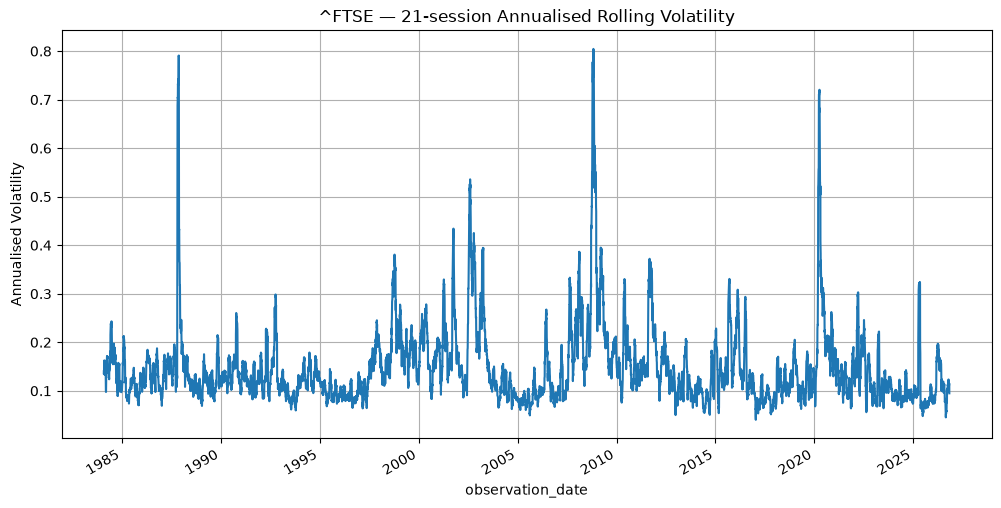

,ticker,observations,rolling_window_sessions,annualisation_factor,ARCH_lags,ARCH_LM_statistic,ARCH_LM_p_value,ARCH_F_statistic,ARCH_F_p_value
0,NG.L,7888,21,252,10,1561.37147937,0.00000000,194.45989879,0.00000000
1,SSE.L,9058,21,252,10,1067.83426315,0.00000000,120.92503532,0.00000000
2,SVT.L,9453,21,252,10,109.98441904,0.00000000,11.11508956,0.00000000
3,^FTSE,10684,21,252,10,1992.10737589,0.00000000,244.66832140,0.00000000


In [450]:
ROLLING_VOLATILITY_WINDOW = 21
ARCH_LAGS = 10

volatility_results = []
rolling_volatility_results = {}

for ticker in log_returns.columns:

    returns = log_returns[ticker].dropna()

    rolling_vol = (
        returns
        .rolling(
            window=ROLLING_VOLATILITY_WINDOW,
            min_periods=ROLLING_VOLATILITY_WINDOW,
        )
        .std()
        * np.sqrt(TRADING_DAYS_PER_YEAR)
    )

    rolling_volatility_results[ticker] = rolling_vol

    if len(returns) > ARCH_LAGS + 20:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            lm_stat, lm_pvalue, f_stat, f_pvalue = het_arch(
                returns,
                nlags=ARCH_LAGS,
            )
    else:
        lm_stat = lm_pvalue = f_stat = f_pvalue = np.nan

    volatility_results.append({
        "ticker": ticker,
        "observations": len(returns),
        "rolling_window_sessions": ROLLING_VOLATILITY_WINDOW,
        "annualisation_factor": TRADING_DAYS_PER_YEAR,
        "ARCH_lags": ARCH_LAGS,
        "ARCH_LM_statistic": lm_stat,
        "ARCH_LM_p_value": lm_pvalue,
        "ARCH_F_statistic": f_stat,
        "ARCH_F_p_value": f_pvalue,
    })

    rolling_vol.plot(
        title=f"{ticker} — 21-session Annualised Rolling Volatility"
    )
    plt.ylabel("Annualised Volatility")
    plt.show()

volatility_table = pd.DataFrame(volatility_results)

display(volatility_table)

## 14. Interest Rates and Yield Curve

### 14.1 Objective

This section examines the historical behaviour of UK interest rates and government bond yields, with particular attention to the relationship between short-term and long-term borrowing conditions.

The analysis focuses on:

- Bank of England Bank Rate.
- Sterling Overnight Index Average (SONIA).
- UK 2-Year Gilt Yield.
- UK 10-Year Gilt Yield.
- The 10Y–2Y yield curve spread.

The objective is to investigate the historical characteristics of these variables and their potential economic relevance to National Grid and the UK utilities sector.

### 14.2 Methodology

The analysis uses the previously prepared historical series.

The 10Y–2Y spread is calculated as the difference between the 10-Year and 2-Year Gilt yields, expressed in percentage points.

Missing observations are preserved. No interpolation or forward-filling is applied.

The stationarity of the yield curve spread is investigated using:

- Augmented Dickey-Fuller (ADF) test.
- Kwiatkowski-Phillips-Schmidt-Shin (KPSS) test.

The significance level is 5%.

The results are interpreted as historical statistical evidence, not as proof of predictive relationships or causal effects.

In [457]:
# Calculate the UK government bond yield curve spread.

gilt_yields["10Y-2Y Spread"] = (
    gilt_yields["Gilt Yield 10Y"]
    - gilt_yields["Gilt Yield 2Y"]
)

spread = gilt_yields["10Y-2Y Spread"].dropna()

print("UK Gilt Yield Curve Spread (10Y - 2Y)")
print(f"Observations: {len(spread):,}")
print(f"Mean: {spread.mean():.4f} percentage points")
print(f"Median: {spread.median():.4f} percentage points")
print(f"Standard deviation: {spread.std():.4f} percentage points")
print(f"Minimum: {spread.min():.4f} percentage points")
print(f"Maximum: {spread.max():.4f} percentage points")

print("\nSpread classification")
print(f"Positive: {(spread > 0).sum():,}")
print(f"Negative: {(spread < 0).sum():,}")
print(f"Zero: {(spread == 0).sum():,}")

UK Gilt Yield Curve Spread (10Y - 2Y)
Observations: 12,090
Mean: 0.5440 percentage points
Median: 0.4638 percentage points
Standard deviation: 0.9512 percentage points
Minimum: -2.1573 percentage points
Maximum: 3.0496 percentage points

Spread classification
Positive: 8,664
Negative: 3,426
Zero: 0


In [460]:
# Test the stationarity of the UK 10Y-2Y Gilt yield spread.

from statsmodels.tsa.stattools import adfuller, kpss
import warnings

spread = spread.dropna()

# Augmented Dickey-Fuller test
adf_result = adfuller(
    spread,
    regression="c",
    autolag="AIC",
)

# KPSS test
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    kpss_result = kpss(
        spread,
        regression="c",
        nlags="auto",
    )

spread_stationarity_results = pd.DataFrame(
    {
        "Test": ["ADF", "KPSS"],
        "Test Statistic": [
            adf_result[0],
            kpss_result[0],
        ],
        "P-value": [
            adf_result[1],
            kpss_result[1],
        ],
        "Lags": [
            adf_result[2],
            kpss_result[2],
        ],
    }
)

display(spread_stationarity_results.round(6))

print("\nADF Critical Values")
for key, value in adf_result[4].items():
    print(f"{key}: {value:.6f}")

print("\nKPSS Critical Values")
for key, value in kpss_result[3].items():
    print(f"{key}: {value:.6f}")

/tmp/ipykernel_57127/2186874577.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(


,Test,Test Statistic,P-value,Lags
0,ADF,-2.94835100,0.04000700,40
1,KPSS,1.82627400,0.01000000,68



ADF Critical Values
1%: -3.430893
5%: -2.861780
10%: -2.566898

KPSS Critical Values
10%: 0.347000
5%: 0.463000
2.5%: 0.574000
1%: 0.739000


### 14.3 Historical Spread Characteristics

The 10Y–2Y spread was calculated using 12,090 paired observations.

The descriptive statistics indicate:

| Statistic | Result |
|---|---:|
| Mean | 0.5440 percentage points |
| Median | 0.4638 percentage points |
| Standard deviation | 0.9512 percentage points |
| Minimum | -2.1573 percentage points |
| Maximum | 3.0496 percentage points |

The spread was positive in 8,664 observations (71.66%) and negative in 3,426 observations (28.34%).

The positive average indicates that the 10-Year Gilt yield was generally higher than the 2-Year yield over the analysed sample.

However, the frequency of negative observations demonstrates that yield curve inversions were a material feature of the historical period.

### 14.4 Economic Interpretation

Government bond yields may influence utility companies through several economic mechanisms:

- Corporate borrowing and refinancing costs.
- Long-term investment valuation.
- Cost of capital.
- Relative attractiveness of dividend-paying equities.
- Expectations regarding future monetary policy and economic conditions.

For National Grid, these mechanisms are particularly relevant because of the capital-intensive nature of electricity and gas infrastructure.

Bank Rate and SONIA provide complementary information about UK monetary conditions. They are not interchangeable measures.

The SONIA methodology change introduced on 23 April 2018 should also be considered when interpreting its historical behaviour.

### 14.5 Statistical Interpretation and Limitations

The ADF and KPSS tests provide complementary evidence about the stationarity of the yield curve spread.

Their conclusions must be interpreted together and in the context of potential structural breaks, monetary policy changes and different economic regimes.

The historical spread does not establish that yield curve movements predict NG.L returns.

Furthermore, the historical observation dates do not necessarily establish when the information became available to market participants.

The Gilt series remain subject to the previously documented point-in-time validation limitation.

## 15. Macroeconomic Context and Research Implications

### 15.1 Objective

This section consolidates the relevant macroeconomic findings from the previous research notebooks and considers their implications for financial time series analysis.

The purpose is to connect the historical behaviour of financial variables with the broader UK economic environment.

No new macroeconomic data acquisition or feature engineering is performed in this section.

### 15.2 Inflation

The previous macroeconomic analysis examined:

- Consumer Prices Index (CPI).
- Core CPI.
- Consumer Prices Index including owner occupiers' housing costs (CPIH).

The three measures exhibit overlapping but distinct historical behaviour.

CPIH includes owner-occupiers' housing costs, whereas Core CPI excludes selected volatile components.

The historical analysis identified differences in average inflation, dispersion and extreme observations.

These indicators may be relevant to National Grid through operating costs, investment expenditure, financing conditions and the real value of future cash flows.

However, their historical relationships do not establish predictive value for equity returns.

### 15.3 Economic Growth

The previous analysis examined real GDP levels, quarterly and annual GDP growth, and GDP deflator growth.

Quarterly GDP growth exhibited substantial extreme observations during the COVID-19 economic disruption, particularly in 2020.

These observations should be interpreted in their historical context rather than automatically removed as statistical anomalies.

Economic growth may influence electricity demand and the broader economic environment in which utility companies operate.

### 15.4 Integration with Financial Time Series

The combined analysis provides several research hypotheses:

1. Interest rates may influence financing and refinancing conditions.
2. Yield curve movements may reflect changes in monetary and economic expectations.
3. Inflation may affect operating costs and the real value of future cash flows.
4. Economic growth may influence electricity demand.
5. Macroeconomic variables may contain overlapping information.

These hypotheses require separate empirical investigation during feature engineering and forecasting research.

No macroeconomic variable is approved as a forecasting feature solely on the basis of the analyses presented in this notebook.


In [461]:
# Summarise the macroeconomic research areas covered in the project.

macroeconomic_research_inventory = pd.DataFrame(
    {
        "Research Area": [
            "Monetary Policy",
            "Money Market Rates",
            "Government Bond Yields",
            "Yield Curve",
            "Consumer Inflation",
            "Core Inflation",
            "Housing-Adjusted Inflation",
            "Economic Growth",
            "GDP Deflator",
        ],
        "Indicators": [
            "Bank Rate",
            "SONIA",
            "UK 2-Year and 10-Year Gilt Yields",
            "10Y-2Y Spread",
            "CPI",
            "Core CPI",
            "CPIH",
            "Real GDP Growth",
            "GDP Deflator Growth",
        ],
        "Research Status": [
            "Analysed",
            "Analysed",
            "Analysed",
            "Analysed",
            "Analysed in Notebook 08",
            "Analysed in Notebook 08",
            "Analysed in Notebook 08",
            "Analysed in Notebook 08",
            "Analysed in Notebook 08",
        ],
    }
)

display(macroeconomic_research_inventory)

,Research Area,Indicators,Research Status
0,Monetary Policy,Bank Rate,Analysed
1,Money Market Rates,SONIA,Analysed
2,Government Bond Yields,UK 2-Year and 10-Year Gilt Yields,Analysed
3,Yield Curve,10Y-2Y Spread,Analysed
4,Consumer Inflation,CPI,Analysed in Notebook 08
5,Core Inflation,Core CPI,Analysed in Notebook 08
6,Housing-Adjusted Inflation,CPIH,Analysed in Notebook 08
7,Economic Growth,Real GDP Growth,Analysed in Notebook 08
8,GDP Deflator,GDP Deflator Growth,Analysed in Notebook 08


## 16. Final Findings and Conclusions

### 16.1 Overview

This notebook investigated the statistical properties of financial time series, focusing on market prices, returns, autocorrelation, volatility and interest rate conditions.

The analysis combined statistical tests, descriptive measures and historical comparisons to identify relevant characteristics of the selected financial instruments.

The findings provide an empirical foundation for subsequent feature engineering and forecasting research.

### 16.2 Stationarity

The stationarity analysis demonstrated that price levels and financial returns can exhibit different statistical properties.

The results varied across the analysed instruments.

The evidence reinforces the importance of evaluating transformed financial variables rather than assuming that historical price levels are suitable modelling inputs.

### 16.3 Autocorrelation

The autocorrelation analysis identified statistically significant dependence in several return series.

Ljung-Box tests rejected the null hypothesis of no autocorrelation across the analysed return series.

Squared returns also exhibited significant autocorrelation, providing evidence consistent with volatility clustering.

These findings do not automatically establish exploitable return predictability.

### 16.4 Volatility

The volatility analysis identified substantial variation in the magnitude of financial returns over time.

ARCH-LM and ARCH F-tests rejected their respective null hypotheses across all four analysed instruments.

The results provide evidence consistent with conditional heteroskedasticity.

However, the application of ARCH tests to raw returns, rather than residuals from a fully specified conditional mean model, remains a methodological limitation.

### 16.5 Interest Rates and Yield Curve

The historical UK Gilt analysis identified a positive average 10Y–2Y spread of 0.5440 percentage points.

Approximately 71.66% of paired observations showed a positive spread, while 28.34% showed an inverted yield curve.

These results demonstrate substantial historical variation in UK interest rate conditions.

The relationship between interest rates and utility equity returns remains a research hypothesis.

### 16.6 Macroeconomic Context

The previous macroeconomic analysis identified substantial variation in inflation and economic growth.

Interest rates, inflation and economic growth may provide economically relevant context for analysing capital-intensive utility companies.

Nevertheless, their incremental predictive value has not yet been established.

### 16.7 Principal Limitations

The following limitations must be considered in subsequent research:

- Historical observation dates do not necessarily represent actual information availability dates.
- Point-in-time eligibility remains unvalidated for some external datasets.
- Structural breaks may affect statistical test results.
- Rolling statistical estimates are based on overlapping observations.
- Missing observations and different market calendars can affect temporal comparisons.
- Corporate actions and dividend-adjustment limitations remain relevant.
- Statistical significance does not establish economic significance.
- Historical relationships do not demonstrate future predictive performance.

### 16.8 Conclusions

The analysis confirms that financial time series exhibit important statistical characteristics that must be considered before forecasting models are developed.

In particular, autocorrelation, volatility clustering, conditional heteroskedasticity and changes in interest rate conditions represent relevant areas for further investigation.

The results do not identify a validated forecasting model or trading strategy.

No trading signals, position-sizing rules or risk limits are derived from this notebook.

### 16.9 Next Steps

The next research phase will focus on financial feature engineering, cross-asset feature development, macroeconomic transformations and market regime detection.

Candidate variables must be evaluated using appropriate temporal validation, point-in-time controls and out-of-sample experiments.

The objective will be to determine whether the identified financial and macroeconomic information provides measurable incremental value over simpler price-based benchmarks.


In [462]:
# Consolidate the principal statistical findings from this notebook.

final_research_summary = pd.DataFrame(
    {
        "Research Area": [
            "Stationarity",
            "Autocorrelation",
            "Volatility Clustering",
            "Conditional Heteroskedasticity",
            "Interest Rates",
            "Yield Curve",
            "Macroeconomic Conditions",
        ],
        "Main Finding": [
            "Price levels and returns exhibit different stationarity properties.",
            "Significant return autocorrelation was identified.",
            "Squared returns exhibit significant autocorrelation.",
            "ARCH tests rejected the null hypothesis across all four instruments.",
            "UK monetary conditions varied substantially over the historical sample.",
            "The 10Y-2Y spread was positive in approximately 71.66% of observations.",
            "Inflation and GDP provide relevant economic context.",
        ],
        "Research Status": [
            "Completed",
            "Completed",
            "Completed",
            "Completed",
            "Completed",
            "Completed",
            "Previously investigated",
        ],
    }
)

display(final_research_summary)

,Research Area,Main Finding,Research Status
0,Stationarity,Price levels and returns exhibit different sta...,Completed
1,Autocorrelation,Significant return autocorrelation was identif...,Completed
2,Volatility Clustering,Squared returns exhibit significant autocorrel...,Completed
3,Conditional Heteroskedasticity,ARCH tests rejected the null hypothesis across...,Completed
4,Interest Rates,UK monetary conditions varied substantially ov...,Completed
5,Yield Curve,The 10Y-2Y spread was positive in approximatel...,Completed
6,Macroeconomic Conditions,Inflation and GDP provide relevant economic co...,Previously investigated
